<a href="https://colab.research.google.com/github/uniqueeee777/ntt-disaster-preparedness/blob/main/03_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering Mitigasi Bencana Kabupaten/Kota di Nusa Tenggara Timur

## Persiapan dan validasi input pemodelan

In [ ]:
# ============================================================
# G.0 — PEMBACAAN DAN VALIDASI INPUT CLUSTERING
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from google.colab import drive
from IPython.display import display

# ------------------------------------------------------------
# G.0.1 — GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

ROOT_G = Path(
    "/content/drive/MyDrive/NTT_Disaster_Analysis data"
)

FILE_F6C_G = ROOT_G / "Matriks_Clustering_F6C.xlsx"

assert FILE_F6C_G.is_file(), (
    f"File tidak ditemukan: {FILE_F6C_G}"
)

print("G.0.1 — SUMBER DATA")
print("File:", FILE_F6C_G.name)
print("Lokasi:", FILE_F6C_G)


# ------------------------------------------------------------
# G.0.2 — VERIFIKASI SHEET
# ------------------------------------------------------------

SHEET_G = {
    "Inti": "F6C_Inti",
    "Standar": "F6C_Standar",
    "Seimbang": "F6C_Seimbang"
}

with pd.ExcelFile(FILE_F6C_G) as excel:

    print("\nSHEET TERSEDIA:")
    print(excel.sheet_names)

    assert set(SHEET_G.values()).issubset(
        excel.sheet_names
    ), "Sheet F.6.C tidak lengkap."

    RAW_G = {
        nama: pd.read_excel(excel, sheet_name=sheet)
        for nama, sheet in SHEET_G.items()
    }


# ------------------------------------------------------------
# G.0.3 — IDENTIFIKASI KOLOM WILAYAH
# ------------------------------------------------------------

NAMA_KOLOM_WILAYAH = {
    "kabupaten_kota",
    "kabupaten/kota",
    "kabupaten kota",
    "nama_wilayah",
    "nama wilayah",
    "wilayah",
    "unnamed: 0",
    "index"
}


def validasi_sheet_g(df, nama):

    df = df.copy()

    print(f"\n--- {nama.upper()} ---")
    print("Ukuran awal:", df.shape)
    print("Kolom:", df.columns.tolist())

    calon = [
        c for c in df.columns
        if str(c).strip().lower()
        in NAMA_KOLOM_WILAYAH
    ]

    if len(calon) != 1:

        raise ValueError(
            f"Kolom identitas wilayah pada sheet {nama} "
            f"belum dapat dikenali secara unik. "
            f"Kolom tersedia: {df.columns.tolist()}"
        )

    kolom_wilayah = calon[0]

    assert df[kolom_wilayah].notna().all(), (
        f"Terdapat identitas wilayah kosong pada {nama}."
    )

    wilayah = (
        df[kolom_wilayah]
        .astype(str)
        .str.strip()
    )

    assert wilayah.ne("").all(), (
        f"Terdapat nama wilayah kosong pada {nama}."
    )

    assert wilayah.is_unique, (
        f"Identitas wilayah duplikat pada {nama}."
    )

    df = df.drop(columns=kolom_wilayah)

    df.index = pd.Index(
        wilayah,
        name="kabupaten_kota"
    )

    # Validasi dimensi.
    assert df.shape == (22, 14), (
        f"Sheet {nama} berukuran {df.shape}, "
        f"bukan (22, 14)."
    )

    assert df.columns.is_unique, (
        f"Nama indikator duplikat pada {nama}."
    )

    # Seluruh indikator harus numerik.
    df = df.apply(
        pd.to_numeric,
        errors="raise"
    )

    # Pemeriksaan missing dan non-finite.
    assert np.isfinite(
        df.to_numpy(dtype=float)
    ).all(), (
        f"Terdapat missing/non-finite pada {nama}."
    )

    print("Ukuran akhir:", df.shape)
    print("Jumlah missing:", df.isna().sum().sum())
    print("Duplikasi wilayah:", df.index.duplicated().sum())

    return df


# ------------------------------------------------------------
# G.0.4 — MEMBANGUN OBJEK INPUT
# ------------------------------------------------------------

INTI_G = validasi_sheet_g(
    RAW_G["Inti"], "Inti"
)

STANDAR_G = validasi_sheet_g(
    RAW_G["Standar"], "Standar"
)

SEIMBANG_G = validasi_sheet_g(
    RAW_G["Seimbang"], "Seimbang"
)


# ------------------------------------------------------------
# G.0.5 — KONSISTENSI WILAYAH DAN FITUR
# ------------------------------------------------------------

assert INTI_G.index.equals(STANDAR_G.index), (
    "Urutan wilayah Inti dan Standar berbeda."
)

assert STANDAR_G.index.equals(SEIMBANG_G.index), (
    "Urutan wilayah Standar dan Seimbang berbeda."
)

assert INTI_G.columns.equals(STANDAR_G.columns), (
    "Fitur Inti dan Standar berbeda."
)

assert STANDAR_G.columns.equals(SEIMBANG_G.columns), (
    "Fitur Standar dan Seimbang berbeda."
)


# ------------------------------------------------------------
# G.0.6 — REPRESENTASI DATA
# ------------------------------------------------------------

REP_G = {
    "Standar": STANDAR_G,
    "Seimbang": SEIMBANG_G
}

WILAYAH_G = STANDAR_G.index
FITUR_G = STANDAR_G.columns

print("\n" + "=" * 65)
print("G.0 — VALIDASI INPUT SELESAI")
print("=" * 65)

ringkasan_g0 = pd.DataFrame([
    {
        "Matriks": nama,
        "Observasi": df.shape[0],
        "Fitur": df.shape[1],
        "Missing": int(df.isna().sum().sum()),
        "Duplikasi_wilayah": int(df.index.duplicated().sum())
    }
    for nama, df in [
        ("Inti", INTI_G),
        ("Standar", STANDAR_G),
        ("Seimbang", SEIMBANG_G)
    ]
])

display(ringkasan_g0)

print("\nDAFTAR 14 INDIKATOR:")
for i, fitur in enumerate(FITUR_G, 1):
    print(f"{i:02d}. {fitur}")

print("\nDAFTAR 22 KABUPATEN/KOTA:")
for i, wilayah in enumerate(WILAYAH_G, 1):
    print(f"{i:02d}. {wilayah}")

print("\nCONTOH MATRIKS STANDAR:")
display(STANDAR_G.head(3))

print("\nCONTOH MATRIKS SEIMBANG:")
display(SEIMBANG_G.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
G.0.1 — SUMBER DATA
File: Matriks_Clustering_F6C.xlsx
Lokasi: /content/drive/MyDrive/NTT_Disaster_Analysis data/Matriks_Clustering_F6C.xlsx

SHEET TERSEDIA:
['F6C_Inti', 'F6C_Standar', 'F6C_Seimbang']

--- INTI ---
Ukuran awal: (22, 15)
Kolom: ['kabupaten_kota', 'persen_miskin_maret_2025', 'persen_desa_tanpa_sinyal_2025', 'puskesmas_per_100rb_2025', 'laporan_per100rb_2021_2025', 'meninggal_per100rb_2021_2025', 'luka_per100rb_2021_2025', 'pengungsi_per100rb_2021_2025', 'krb_prop_tinggi_gelombang_abrasi', 'krb_prop_tinggi_gempa_bumi', 'krb_prop_tinggi_karhutla', 'krb_prop_tinggi_kekeringan', 'krb_prop_tinggi_likuefaksi', 'krb_prop_tinggi_tanah_longsor', 'krb_prop_tinggi_tsunami']
Ukuran akhir: (22, 14)
Jumlah missing: 0
Duplikasi wilayah: 0

--- STANDAR ---
Ukuran awal: (22, 15)
Kolom: ['kabupaten_kota', 'persen_miskin_maret_2025', 'persen_desa_tanpa_sinyal_202

,Matriks,Observasi,Fitur,Missing,Duplikasi_wilayah
0,Inti,22,14,0,0
1,Standar,22,14,0,0
2,Seimbang,22,14,0,0



DAFTAR 14 INDIKATOR:
01. persen_miskin_maret_2025
02. persen_desa_tanpa_sinyal_2025
03. puskesmas_per_100rb_2025
04. laporan_per100rb_2021_2025
05. meninggal_per100rb_2021_2025
06. luka_per100rb_2021_2025
07. pengungsi_per100rb_2021_2025
08. krb_prop_tinggi_gelombang_abrasi
09. krb_prop_tinggi_gempa_bumi
10. krb_prop_tinggi_karhutla
11. krb_prop_tinggi_kekeringan
12. krb_prop_tinggi_likuefaksi
13. krb_prop_tinggi_tanah_longsor
14. krb_prop_tinggi_tsunami

DAFTAR 22 KABUPATEN/KOTA:
01. Sumba Barat
02. Sumba Timur
03. Kupang
04. Timor Tengah Selatan
05. Timor Tengah Utara
06. Belu
07. Alor
08. Lembata
09. Flores Timur
10. Sikka
11. Ende
12. Ngada
13. Manggarai
14. Rote Ndao
15. Manggarai Barat
16. Sumba Tengah
17. Sumba Barat Daya
18. Nagekeo
19. Manggarai Timur
20. Sabu Raijua
21. Malaka
22. Kota Kupang

CONTOH MATRIKS STANDAR:


,persen_miskin_maret_2025,persen_desa_tanpa_sinyal_2025,puskesmas_per_100rb_2025,laporan_per100rb_2021_2025,meninggal_per100rb_2021_2025,luka_per100rb_2021_2025,pengungsi_per100rb_2021_2025,krb_prop_tinggi_gelombang_abrasi,krb_prop_tinggi_gempa_bumi,krb_prop_tinggi_karhutla,krb_prop_tinggi_kekeringan,krb_prop_tinggi_likuefaksi,krb_prop_tinggi_tanah_longsor,krb_prop_tinggi_tsunami
kabupaten_kota,,,,,,,,,,,,,,
Sumba Barat,1.152898,-0.745572,-0.709890,-0.563187,-0.591256,-0.535638,-0.727130,0.008990,-0.352427,-0.457219,0.460198,-0.454165,-1.064775,-0.333154
Sumba Timur,1.020346,0.393827,0.442354,-0.195934,-0.503055,-0.510008,0.922551,-0.145209,0.052055,2.299058,-1.322260,-0.585663,-0.840161,-2.336669
Kupang,0.170735,0.112732,-0.529065,1.992725,0.164994,0.009366,-0.198747,-0.429921,-0.345544,-0.670376,0.927526,-0.834716,-0.634810,-0.558707



CONTOH MATRIKS SEIMBANG:


,persen_miskin_maret_2025,persen_desa_tanpa_sinyal_2025,puskesmas_per_100rb_2025,laporan_per100rb_2021_2025,meninggal_per100rb_2021_2025,luka_per100rb_2021_2025,pengungsi_per100rb_2021_2025,krb_prop_tinggi_gelombang_abrasi,krb_prop_tinggi_gempa_bumi,krb_prop_tinggi_karhutla,krb_prop_tinggi_kekeringan,krb_prop_tinggi_likuefaksi,krb_prop_tinggi_tanah_longsor,krb_prop_tinggi_tsunami
kabupaten_kota,,,,,,,,,,,,,,
Sumba Barat,0.665626,-0.430456,-0.409855,-0.281594,-0.295628,-0.267819,-0.363565,0.003398,-0.133205,-0.172812,0.173939,-0.171658,-0.402447,-0.125920
Sumba Timur,0.589097,0.227376,0.255393,-0.097967,-0.251527,-0.255004,0.461276,-0.054884,0.019675,0.868962,-0.499767,-0.221360,-0.317551,-0.883178
Kupang,0.098574,0.065086,-0.305456,0.996363,0.082497,0.004683,-0.099373,-0.162495,-0.130603,-0.253378,0.350572,-0.315493,-0.239935,-0.211171


In [ ]:
# ============================================================
# G.0.7 — VERIFIKASI STANDARDISASI DAN PEMBOBOTAN
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

KELOMPOK_G = {
    "BPS": list(FITUR_G[:3]),
    "BNPB": list(FITUR_G[3:7]),
    "KRB": list(FITUR_G[7:14])
}

# Pemeriksaan z-score per indikator.
ringkasan_z = pd.DataFrame({
    "indikator": STANDAR_G.columns,
    "mean_z": STANDAR_G.mean().values,
    "sd_z_ddof0": STANDAR_G.std(ddof=0).values,
    "sd_z_ddof1": STANDAR_G.std(ddof=1).values
})

print("A. PEMERIKSAAN STANDARDISASI")
display(ringkasan_z.round(6))

# Pemeriksaan bobot setiap kelompok.
hasil_bobot = []

for kelompok, kolom in KELOMPOK_G.items():

    bobot = 1 / np.sqrt(len(kolom))

    harapan = STANDAR_G[kolom] * bobot
    aktual = SEIMBANG_G[kolom]

    selisih = np.abs(
        aktual.to_numpy() - harapan.to_numpy()
    )

    hasil_bobot.append({
        "kelompok": kelompok,
        "jumlah_fitur": len(kolom),
        "bobot_teoretis": bobot,
        "selisih_maksimum": selisih.max(),
        "sesuai": np.allclose(
            aktual,
            harapan,
            atol=1e-6,
            rtol=1e-5
        )
    })

print("\nB. PEMERIKSAAN PEMBOBOTAN")
display(pd.DataFrame(hasil_bobot).round(8))

print("\nC. DUPLIKASI PROFIL MULTIVARIAT")
print(
    "Profil identik:",
    STANDAR_G.duplicated().sum()
)

A. PEMERIKSAAN STANDARDISASI


,indikator,mean_z,sd_z_ddof0,sd_z_ddof1
0,persen_miskin_maret_2025,0.0,1.0,1.023533
1,persen_desa_tanpa_sinyal_2025,0.0,1.0,1.023533
2,puskesmas_per_100rb_2025,0.0,1.0,1.023533
3,laporan_per100rb_2021_2025,0.0,1.0,1.023533
4,meninggal_per100rb_2021_2025,-0.0,1.0,1.023533
5,luka_per100rb_2021_2025,0.0,1.0,1.023533
6,pengungsi_per100rb_2021_2025,0.0,1.0,1.023533
7,krb_prop_tinggi_gelombang_abrasi,0.0,1.0,1.023533
8,krb_prop_tinggi_gempa_bumi,0.0,1.0,1.023533
9,krb_prop_tinggi_karhutla,-0.0,1.0,1.023533



B. PEMERIKSAAN PEMBOBOTAN


,kelompok,jumlah_fitur,bobot_teoretis,selisih_maksimum,sesuai
0,BPS,3,0.577350,0.0,True
1,BNPB,4,0.500000,0.0,True
2,KRB,7,0.377964,0.0,True



C. DUPLIKASI PROFIL MULTIVARIAT
Profil identik: 0


##Diagnostik struktur jarak multivariat

In [ ]:
# ============================================================
# G.1 — DIAGNOSTIK STRUKTUR JARAK MULTIVARIAT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from IPython.display import display


# ------------------------------------------------------------
# G.1.0 — VALIDASI INPUT
# ------------------------------------------------------------

REP_G = {
    "Standar": STANDAR_G,
    "Seimbang": SEIMBANG_G
}

KELOMPOK_G = {
    "BPS": list(FITUR_G[:3]),
    "BNPB": list(FITUR_G[3:7]),
    "KRB": list(FITUR_G[7:14])
}

assert all(
    df.shape == (22, 14)
    for df in REP_G.values()
)

assert set(sum(KELOMPOK_G.values(), [])) == set(FITUR_G)

assert all(
    df.index.equals(STANDAR_G.index)
    and df.columns.equals(STANDAR_G.columns)
    for df in REP_G.values()
)

OUT_G1 = (
    ROOT_G / "Hasil_G_Artikel1_Baru" / "Diagnostik_G1"
)

OUT_G1.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# G.1.A — DISTRIBUSI JARAK EUCLIDEAN
# ------------------------------------------------------------

HASIL_JARAK_G1 = {}
MATRIKS_JARAK_G1 = {}
HASIL_WILAYAH_G1 = {}
HASIL_KONTRIBUSI_G1 = {}

for representasi, df in REP_G.items():

    X = df.to_numpy(dtype=float)

    jarak = pdist(
        X, metric="euclidean"
    )

    D = squareform(jarak)

    assert len(jarak) == 231
    assert np.allclose(D, D.T)
    assert np.allclose(np.diag(D), 0)

    MATRIKS_JARAK_G1[representasi] = pd.DataFrame(
        D,
        index=df.index,
        columns=df.index
    )

    HASIL_JARAK_G1[representasi] = {
        "representasi": representasi,
        "jumlah_pasangan": len(jarak),
        "jarak_minimum": jarak.min(),
        "jarak_median": np.median(jarak),
        "jarak_rata_rata": jarak.mean(),
        "jarak_maksimum": jarak.max(),
        "sd_jarak": jarak.std(ddof=0),
        "cv_jarak": (
            jarak.std(ddof=0) / jarak.mean()
        ),
        "pasangan_identik": np.isclose(
            jarak, 0
        ).sum()
    }

    # --------------------------------------------------------
    # G.1.B — JARAK PER WILAYAH
    # --------------------------------------------------------

    D_tetangga = D.copy()

    np.fill_diagonal(
        D_tetangga,
        np.inf
    )

    indeks_terdekat = np.argmin(
        D_tetangga, axis=1
    )

    jarak_terdekat = D_tetangga[
        np.arange(len(df)),
        indeks_terdekat
    ]

    jarak_rata_rata = (
        D.sum(axis=1) / (len(df) - 1)
    )

    HASIL_WILAYAH_G1[representasi] = pd.DataFrame({
        "kabupaten_kota": df.index,
        "tetangga_terdekat": df.index[indeks_terdekat],
        "jarak_terdekat": jarak_terdekat,
        "jarak_rata_rata": jarak_rata_rata
    })

    # --------------------------------------------------------
    # G.1.C — KONTRIBUSI KELOMPOK INDIKATOR
    # --------------------------------------------------------

    jarak_kuadrat_total = np.sum(
        pdist(X, metric="sqeuclidean")
    )

    kontribusi = []

    for kelompok, fitur in KELOMPOK_G.items():

        X_kelompok = df[fitur].to_numpy(dtype=float)

        jarak_kuadrat_kelompok = np.sum(
            pdist(X_kelompok, metric="sqeuclidean")
        )

        kontribusi.append({
            "representasi": representasi,
            "kelompok": kelompok,
            "jumlah_fitur": len(fitur),
            "kontribusi_persen": (
                100 * jarak_kuadrat_kelompok
                / jarak_kuadrat_total
            )
        })

    HASIL_KONTRIBUSI_G1[representasi] = pd.DataFrame(
        kontribusi
    )


# ------------------------------------------------------------
# RINGKASAN G.1.A
# ------------------------------------------------------------

ringkasan_jarak_g1 = pd.DataFrame(
    HASIL_JARAK_G1.values()
)

print("\nG.1.A — DISTRIBUSI JARAK EUCLIDEAN")

display(
    ringkasan_jarak_g1.round(4)
)


# ------------------------------------------------------------
# RINGKASAN G.1.B
# ------------------------------------------------------------

jarak_wilayah_g1 = pd.concat(
    HASIL_WILAYAH_G1.values(),
    keys=HASIL_WILAYAH_G1.keys(),
    names=["representasi"]
).reset_index(level=0)

print("\nG.1.B — WILAYAH DENGAN JARAK RATA-RATA TERBESAR")

for representasi in REP_G:

    print(f"\nRepresentasi: {representasi}")

    display(
        HASIL_WILAYAH_G1[representasi]
        .sort_values(
            "jarak_rata_rata",
            ascending=False
        )
        .head(10)
        .round(4)
    )


# ------------------------------------------------------------
# RINGKASAN G.1.C
# ------------------------------------------------------------

kontribusi_g1 = pd.concat(
    HASIL_KONTRIBUSI_G1.values(),
    ignore_index=True
)

print("\nG.1.C — KONTRIBUSI TERHADAP JARAK KUADRAT")

display(
    kontribusi_g1.round(4)
)


# ------------------------------------------------------------
# G.1.D — PERBANDINGAN STRUKTUR JARAK
# ------------------------------------------------------------

d_standar = pdist(
    STANDAR_G.to_numpy(float)
)

d_seimbang = pdist(
    SEIMBANG_G.to_numpy(float)
)

rho, _ = spearmanr(
    d_standar,
    d_seimbang
)

tetangga_standar = (
    HASIL_WILAYAH_G1["Standar"]
    .set_index("kabupaten_kota")
    ["tetangga_terdekat"]
)

tetangga_seimbang = (
    HASIL_WILAYAH_G1["Seimbang"]
    .set_index("kabupaten_kota")
    ["tetangga_terdekat"]
)

tetangga_sama = (
    tetangga_standar == tetangga_seimbang
)

print("\nG.1.D — KONSISTENSI STRUKTUR JARAK")

print(
    "Korelasi Spearman jarak:",
    round(float(rho), 4)
)

print(
    "Tetangga terdekat sama:",
    int(tetangga_sama.sum()),
    "dari 22 wilayah"
)

print("\nWILAYAH YANG TETANGGA TERDEKATNYA BERUBAH")

display(
    pd.DataFrame({
        "Standar": tetangga_standar,
        "Seimbang": tetangga_seimbang
    }).loc[~tetangga_sama]
)


G.1.A — DISTRIBUSI JARAK EUCLIDEAN


,representasi,jumlah_pasangan,jarak_minimum,jarak_median,jarak_rata_rata,jarak_maksimum,sd_jarak,cv_jarak,pasangan_identik
0,Standar,231,1.6816,5.0659,5.1787,9.5129,1.5857,0.3062,0
1,Seimbang,231,0.7507,2.3891,2.3980,4.4487,0.7316,0.3051,0



G.1.B — WILAYAH DENGAN JARAK RATA-RATA TERBESAR

Representasi: Standar


,kabupaten_kota,tetangga_terdekat,jarak_terdekat,jarak_rata_rata
19,Sabu Raijua,Sumba Timur,7.0519,8.1939
7,Lembata,Flores Timur,3.3968,6.4415
8,Flores Timur,Lembata,3.3968,5.9994
15,Sumba Tengah,Timor Tengah Utara,4.2975,5.8759
13,Rote Ndao,Kupang,3.7551,5.8398
11,Ngada,Manggarai Barat,4.0472,5.7667
21,Kota Kupang,Sumba Barat Daya,3.4428,5.6492
6,Alor,Ende,3.3975,5.6386
1,Sumba Timur,Malaka,3.8900,5.5689
20,Malaka,Sumba Timur,3.8900,5.3506



Representasi: Seimbang


,kabupaten_kota,tetangga_terdekat,jarak_terdekat,jarak_rata_rata
19,Sabu Raijua,Sumba Timur,2.8620,3.5076
7,Lembata,Flores Timur,1.6651,3.0169
11,Ngada,Sumba Tengah,2.1598,2.9172
8,Flores Timur,Lembata,1.6651,2.8839
15,Sumba Tengah,Sumba Timur,2.0452,2.8772
13,Rote Ndao,Kupang,1.7153,2.7412
21,Kota Kupang,Sumba Barat Daya,1.8876,2.7305
6,Alor,Ende,1.7043,2.6152
1,Sumba Timur,Malaka,1.7420,2.4152
20,Malaka,Sumba Timur,1.7420,2.3517



G.1.C — KONTRIBUSI TERHADAP JARAK KUADRAT


,representasi,kelompok,jumlah_fitur,kontribusi_persen
0,Standar,BPS,3,21.4286
1,Standar,BNPB,4,28.5714
2,Standar,KRB,7,50.0000
3,Seimbang,BPS,3,33.3333
4,Seimbang,BNPB,4,33.3333
5,Seimbang,KRB,7,33.3333



G.1.D — KONSISTENSI STRUKTUR JARAK
Korelasi Spearman jarak: 0.9695
Tetangga terdekat sama: 15 dari 22 wilayah

WILAYAH YANG TETANGGA TERDEKATNYA BERUBAH


,Standar,Seimbang
kabupaten_kota,,
Kupang,Sumba Barat,Belu
Ende,Sikka,Timor Tengah Utara
Ngada,Manggarai Barat,Sumba Tengah
Manggarai,Manggarai Timur,Manggarai Barat
Sumba Tengah,Timor Tengah Utara,Sumba Timur
Nagekeo,Manggarai Barat,Sikka
Manggarai Timur,Manggarai,Timor Tengah Utara


## Analisis kontribusi indikator terhadap jarak wilayah

In [ ]:
# ============================================================
# G.1.F — KONTRIBUSI INDIKATOR TERHADAP KETERPISAHAN WILAYAH
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# G.1.F.1 — VALIDASI INPUT
# ------------------------------------------------------------

assert "Sabu Raijua" in STANDAR_G.index

REP_G = {
    "Standar": STANDAR_G,
    "Seimbang": SEIMBANG_G
}

KELOMPOK_G = {
    "BPS": list(FITUR_G[:3]),
    "BNPB": list(FITUR_G[3:7]),
    "KRB": list(FITUR_G[7:14])
}

assert sum(
    KELOMPOK_G.values(), []
) == list(FITUR_G)

assert all(
    df.shape == (22, 14)
    and df.index.equals(INTI_G.index)
    and df.columns.equals(INTI_G.columns)
    for df in REP_G.values()
)

FITUR_KELOMPOK_G = {
    fitur: kelompok
    for kelompok, daftar in KELOMPOK_G.items()
    for fitur in daftar
}


# ------------------------------------------------------------
# G.1.F.2 — FUNGSI DEKOMPOSISI JARAK KUADRAT
# ------------------------------------------------------------

def kontribusi_jarak_g(df, wilayah):

    assert wilayah in df.index

    x = df.loc[wilayah]

    lainnya = df.drop(index=wilayah)

    # Selisih wilayah fokus terhadap 21 wilayah lain.
    selisih = lainnya.sub(x, axis=1)

    # Rata-rata kontribusi kuadrat per indikator.
    komponen = selisih.pow(2).mean(axis=0)

    jarak_kuadrat = komponen.sum()

    assert jarak_kuadrat > 0

    kontribusi = (
        100 * komponen / jarak_kuadrat
    )

    assert np.isclose(
        kontribusi.sum(), 100
    )

    hasil = pd.DataFrame({
        "indikator": df.columns,
        "kelompok": [
            FITUR_KELOMPOK_G[f]
            for f in df.columns
        ],
        "mean_squared_difference": komponen.values,
        "kontribusi_persen": kontribusi.values
    })

    return hasil.sort_values(
        "kontribusi_persen",
        ascending=False
    ).reset_index(drop=True)


# ------------------------------------------------------------
# G.1.F.3 — KONTRIBUSI 14 INDIKATOR SABU RAIJUA
# ------------------------------------------------------------

KONTRIBUSI_SABU_G1 = {}
KONTRIBUSI_KELOMPOK_SABU_G1 = {}

for representasi, df in REP_G.items():

    hasil = kontribusi_jarak_g(
        df,
        "Sabu Raijua"
    )

    KONTRIBUSI_SABU_G1[representasi] = hasil

    print("\n" + "=" * 65)
    print(
        f"G.1.F — SABU RAIJUA | {representasi.upper()}"
    )
    print("=" * 65)

    print("\nA. KONTRIBUSI SELURUH INDIKATOR")

    display(
        hasil.round(4)
    )

    kelompok = (
        hasil.groupby(
            "kelompok", as_index=False
        )["kontribusi_persen"]
        .sum()
        .sort_values(
            "kontribusi_persen",
            ascending=False
        )
    )

    KONTRIBUSI_KELOMPOK_SABU_G1[
        representasi
    ] = kelompok

    print("\nB. KONTRIBUSI PER KELOMPOK SUMBER")

    display(
        kelompok.round(4)
    )


# ------------------------------------------------------------
# G.1.F.4 — PROFIL INDIKATOR DOMINAN
# NILAI ASLI DAN Z-SCORE
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("G.1.F — PROFIL INDIKATOR DOMINAN SABU RAIJUA")
print("=" * 65)

# Pilih tujuh indikator dengan kontribusi terbesar
# dari representasi utama Seimbang.
fitur_dominan = (
    KONTRIBUSI_SABU_G1["Seimbang"]
    .head(7)["indikator"]
    .tolist()
)

profil_sabu = pd.DataFrame({
    "indikator": fitur_dominan,
    "nilai_asli_sabu": [
        INTI_G.loc["Sabu Raijua", f]
        for f in fitur_dominan
    ],
    "median_asli_21_wilayah": [
        INTI_G.drop(index="Sabu Raijua")[f].median()
        for f in fitur_dominan
    ],
    "z_sabu": [
        STANDAR_G.loc["Sabu Raijua", f]
        for f in fitur_dominan
    ],
    "rata_rata_z_21_wilayah": [
        STANDAR_G.drop(index="Sabu Raijua")[f].mean()
        for f in fitur_dominan
    ]
})

display(
    profil_sabu.round(4)
)


# ------------------------------------------------------------
# G.1.F.5 — SABU RAIJUA VS TETANGGA TERDEKAT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("G.1.F — PERBANDINGAN DENGAN TETANGGA TERDEKAT")
print("=" * 65)

for representasi, df in REP_G.items():

    x = df.loc["Sabu Raijua"]

    lainnya = df.drop(index="Sabu Raijua")

    jarak = np.sqrt(
        lainnya.sub(x, axis=1).pow(2).sum(axis=1)
    )

    tetangga = jarak.idxmin()

    komponen = (
        df.loc["Sabu Raijua"]
        .sub(df.loc[tetangga])
        .pow(2)
    )

    hasil_pasangan = pd.DataFrame({
        "indikator": df.columns,
        "kontribusi_persen": (
            100 * komponen / komponen.sum()
        ).values
    }).sort_values(
        "kontribusi_persen",
        ascending=False
    )

    print(f"\nRepresentasi: {representasi}")
    print("Tetangga terdekat:", tetangga)
    print("Jarak Euclidean:", round(jarak.min(), 4))

    print("\nIndikator pembeda utama:")
    display(
        hasil_pasangan.head(7).round(4)
    )


# ------------------------------------------------------------
# G.1.F.6 — PERIKSA WILAYAH LAIN YANG RELATIF TERPISAH
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("G.1.F — PROFIL WILAYAH RELATIF TERPISAH")
print("=" * 65)

ringkasan_wilayah = []

for representasi, df in REP_G.items():

    kandidat = (
        HASIL_WILAYAH_G1[representasi]
        .sort_values(
            "jarak_rata_rata",
            ascending=False
        )
        .head(4)
    )

    for wilayah in kandidat["kabupaten_kota"]:

        hasil = kontribusi_jarak_g(
            df,
            wilayah
        )

        ringkasan_wilayah.append({
            "representasi": representasi,
            "kabupaten_kota": wilayah,
            "indikator_utama": hasil.iloc[0]["indikator"],
            "kontribusi_utama_persen":
                hasil.iloc[0]["kontribusi_persen"],
            "tiga_indikator_terbesar":
                ", ".join(hasil.head(3)["indikator"])
        })

ringkasan_wilayah = pd.DataFrame(
    ringkasan_wilayah
)

display(
    ringkasan_wilayah.round(4)
)

print("\nG.1.F SELESAI.")


G.1.F — SABU RAIJUA | STANDAR

A. KONTRIBUSI SELURUH INDIKATOR


,indikator,kelompok,mean_squared_difference,kontribusi_persen
0,krb_prop_tinggi_gempa_bumi,KRB,22.2125,32.9226
1,pengungsi_per100rb_2021_2025,BNPB,11.0980,16.4491
2,krb_prop_tinggi_gelombang_abrasi,KRB,9.6116,14.2459
3,krb_prop_tinggi_karhutla,KRB,6.7244,9.9667
4,persen_miskin_maret_2025,BPS,2.7275,4.0425
5,krb_prop_tinggi_likuefaksi,KRB,2.3445,3.4750
6,krb_prop_tinggi_tanah_longsor,KRB,2.2903,3.3946
7,krb_prop_tinggi_kekeringan,KRB,1.9489,2.8886
8,laporan_per100rb_2021_2025,BNPB,1.7244,2.5559
9,puskesmas_per_100rb_2025,BPS,1.6469,2.4409



B. KONTRIBUSI PER KELOMPOK SUMBER


,kelompok,kontribusi_persen
2,KRB,68.4627
0,BNPB,22.6379
1,BPS,8.8994



G.1.F — SABU RAIJUA | SEIMBANG

A. KONTRIBUSI SELURUH INDIKATOR


...


Representasi: Seimbang
Tetangga terdekat: Sumba Timur
Jarak Euclidean: 2.862

Indikator pembeda utama:


,indikator,kontribusi_persen
8,krb_prop_tinggi_gempa_bumi,34.4232
7,krb_prop_tinggi_gelombang_abrasi,15.7419
6,pengungsi_per100rb_2021_2025,14.4354
10,krb_prop_tinggi_kekeringan,8.8275
13,krb_prop_tinggi_tsunami,8.6985
2,puskesmas_per_100rb_2025,5.8470
1,persen_desa_tanpa_sinyal_2025,5.2830



G.1.F — PROFIL WILAYAH RELATIF TERPISAH


,representasi,kabupaten_kota,indikator_utama,kontribusi_utama_persen,tiga_indikator_terbesar
0,Standar,Sabu Raijua,krb_prop_tinggi_gempa_bumi,32.9226,"krb_prop_tinggi_gempa_bumi, pengungsi_per100rb..."
1,Standar,Lembata,meninggal_per100rb_2021_2025,25.7427,"meninggal_per100rb_2021_2025, luka_per100rb_20..."
2,Standar,Flores Timur,meninggal_per100rb_2021_2025,25.6567,"meninggal_per100rb_2021_2025, luka_per100rb_20..."
3,Standar,Sumba Tengah,persen_desa_tanpa_sinyal_2025,25.0654,"persen_desa_tanpa_sinyal_2025, krb_prop_tinggi..."
4,Seimbang,Sabu Raijua,krb_prop_tinggi_gempa_bumi,25.5523,"krb_prop_tinggi_gempa_bumi, pengungsi_per100rb..."
5,Seimbang,Lembata,meninggal_per100rb_2021_2025,29.3063,"meninggal_per100rb_2021_2025, luka_per100rb_20..."
6,Seimbang,Ngada,persen_desa_tanpa_sinyal_2025,29.9224,"persen_desa_tanpa_sinyal_2025, puskesmas_per_1..."
7,Seimbang,Flores Timur,meninggal_per100rb_2021_2025,27.8299,"meninggal_per100rb_2021_2025, luka_per100rb_20..."



G.1.F SELESAI.


In [ ]:
# ============================================================
# G.1.G — PEMERIKSAAN NILAI EKSTREM DAN SUMBER DATA
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# Definisikan FILE_MASTER_G menggunakan nama file yang tepat di Google Drive
FILE_MASTER_G = ROOT_G / "Master_Dataset_Kebencanaan_NTT_Artikel1.xlsx"

master_g = pd.read_excel(
    FILE_MASTER_G,
    sheet_name="Master_NTT"
)

indikator_fokus = [
    "krb_prop_tinggi_gempa_bumi",
    "krb_prop_tinggi_gelombang_abrasi",
    "krb_prop_tinggi_karhutla",
    "pengungsi_per100rb_2021_2025",
    "meninggal_per100rb_2021_2025",
    "luka_per100rb_2021_2025"
]

print("A. PEMERIKSAAN RENTANG NILAI KRB")

fitur_krb = list(INTI_G.columns[7:14])

rentang_krb = pd.DataFrame({
    "minimum": INTI_G[fitur_krb].min(),
    "median": INTI_G[fitur_krb].median(),
    "maksimum": INTI_G[fitur_krb].max()
})

rentang_krb["dalam_0_100"] = (
    (rentang_krb["minimum"] >= 0)
    & (rentang_krb["maksimum"] <= 100)
)

display(rentang_krb.round(4))


print("\nB. PERBANDINGAN F6C DENGAN MASTER DATASET")

if "kabupaten_kota" in master_g.columns:

    master_g["kabupaten_kota"] = (
        master_g["kabupaten_kota"]
        .astype(str)
        .str.strip()
    )

    master_g = master_g.set_index("kabupaten_kota")

    wilayah_fokus = [
        "Sabu Raijua",
        "Lembata",
        "Flores Timur"
    ]

    hasil = []

    for wilayah in wilayah_fokus:
        for indikator in indikator_fokus:

            nilai_f6c = INTI_G.loc[wilayah, indikator]

            if (
                wilayah in master_g.index
                and indikator in master_g.columns
                and master_g.index.is_unique
            ):

                nilai_master = pd.to_numeric(
                    master_g.loc[wilayah, indikator],
                    errors="coerce"
                )

                cocok = (
                    pd.notna(nilai_master)
                    and np.isclose(
                        nilai_f6c,
                        nilai_master,
                        rtol=1e-7,
                        atol=1e-7
                    )
                )

            else:

                nilai_master = np.nan
                cocok = np.nan

            hasil.append({
                "wilayah": wilayah,
                "indikator": indikator,
                "nilai_F6C": nilai_f6c,
                "nilai_master": nilai_master,
                "sesuai": cocok
            })

    display(pd.DataFrame(hasil).round(4))

else:

    print(
        "Kolom kabupaten_kota tidak ditemukan "
        "pada master. Pemeriksaan manual diperlukan."
    )


print("\nC. PENCARIAN INDIKATOR BNPB PERIODE ALTERNATIF")

kandidat = [
    c for c in master_g.columns
    if (
        "2022_2025" in str(c).lower()
        or "2022-2025" in str(c).lower()
    )
]

print("Jumlah kandidat:", len(kandidat))

for c in kandidat:
    print(c)

A. PEMERIKSAAN RENTANG NILAI KRB


,minimum,median,maksimum,dalam_0_100
krb_prop_tinggi_gelombang_abrasi,0.0000,10.2389,95.8964,True
krb_prop_tinggi_gempa_bumi,0.0000,1.0466,100.0000,True
krb_prop_tinggi_karhutla,0.0000,5.3315,44.1720,True
krb_prop_tinggi_kekeringan,0.0000,87.7682,100.0000,True
krb_prop_tinggi_likuefaksi,0.5393,6.9016,22.8682,True
krb_prop_tinggi_tanah_longsor,0.0000,5.3743,17.2673,True
krb_prop_tinggi_tsunami,46.5699,90.7767,99.5665,True



B. PERBANDINGAN F6C DENGAN MASTER DATASET


,wilayah,indikator,nilai_F6C,nilai_master,sesuai
0,Sabu Raijua,krb_prop_tinggi_gempa_bumi,100.0000,NaN,NaN
1,Sabu Raijua,krb_prop_tinggi_gelombang_abrasi,95.8964,NaN,NaN
2,Sabu Raijua,krb_prop_tinggi_karhutla,44.1720,NaN,NaN
3,Sabu Raijua,pengungsi_per100rb_2021_2025,19203.8230,NaN,NaN
4,Sabu Raijua,meninggal_per100rb_2021_2025,0.6233,NaN,NaN
5,Sabu Raijua,luka_per100rb_2021_2025,0.0000,NaN,NaN
6,Lembata,krb_prop_tinggi_gempa_bumi,15.8840,NaN,NaN
7,Lembata,krb_prop_tinggi_gelombang_abrasi,51.6420,NaN,NaN
8,Lembata,krb_prop_tinggi_karhutla,8.9484,NaN,NaN
9,Lembata,pengungsi_per100rb_2021_2025,7553.7964,NaN,NaN



C. PENCARIAN INDIKATOR BNPB PERIODE ALTERNATIF
Jumlah kandidat: 0


In [ ]:
# Cek daftar file yang ada di dalam folder data untuk menemukan nama file master yang tepat
import os
if ROOT_G.exists():
    print("Daftar file di folder data:")
    for file in os.listdir(ROOT_G):
        print("-", file)
else:
    print("Folder tidak ditemukan:", ROOT_G)

Daftar file di folder data:
- Master_Dataset_Kebencanaan_NTT_Artikel1.xlsx
- Visualisasi_Clustering_G
- Hasil_Clustering_G3_G4_GridSearch.xlsx
- Hasil_Clustering_G_Revisi
- Hasil_Clustering_G_FINAL_TINJAU
- Matriks_Clustering_F6C.xlsx
- Hasil_G_Artikel1_Baru


In [ ]:
# ============================================================
# G.1.G — AUDIT STRUKTUR VARIABEL SUMBER
# Tidak mengubah master maupun matriks F.6.C
# ============================================================

import pandas as pd
import re
from IPython.display import display

# 1. Baca ulang master mentah
master_audit_g = pd.read_excel(
    FILE_MASTER_G,
    sheet_name="Master_NTT"
)

print("A. IDENTITAS MASTER DATASET")
print("Dimensi:", master_audit_g.shape)

assert "kabupaten_kota" in master_audit_g.columns
assert len(master_audit_g) == 22

master_audit_g["kabupaten_kota"] = (
    master_audit_g["kabupaten_kota"]
    .astype(str)
    .str.strip()
)

assert master_audit_g["kabupaten_kota"].is_unique

master_audit_g = master_audit_g.set_index(
    "kabupaten_kota"
)

kolom_master = master_audit_g.columns.tolist()


# 2. Identifikasi kolom asli KRB
KRBCOL_G1 = [
    c for c in kolom_master
    if re.search(
        r"krb|gempa_bumi|gelombang_abrasi|"
        r"kekeringan|likuefaksi|tanah_longsor|tsunami",
        str(c).lower()
    )
]

print("\nB. NAMA KOLOM SUMBER KRB")

display(pd.DataFrame({
    "kolom_KRB": KRBCOL_G1
}))


# 3. Identifikasi indikator BNPB tahunan
BNPBCOL_G1 = [
    c for c in kolom_master
    if re.search(
        r"^bencana_202[1-5]_",
        str(c).lower()
    )
]

print("\nC. NAMA KOLOM BNPB 2021–2025")

display(pd.DataFrame({
    "kolom_BNPB": BNPBCOL_G1
}))


# 4. Verifikasi empat indikator BNPB per tahun
jenis_bnpb = [
    "baris_laporan_raw",
    "meninggal_jumlah_raw",
    "luka_jumlah_raw",
    "pengungsi_jumlah_raw"
]

hasil_ketersediaan = []

for tahun in range(2021, 2026):

    for jenis in jenis_bnpb:

        nama = f"bencana_{tahun}_{jenis}"

        hasil_ketersediaan.append({
            "tahun": tahun,
            "indikator": jenis,
            "kolom": nama,
            "tersedia": nama in kolom_master
        })

print("\nD. KETERSEDIAAN DATA BNPB TAHUNAN")

display(pd.DataFrame(hasil_ketersediaan))


# 5. Cari nama variabel penduduk
POPCOL_G1 = [
    c for c in kolom_master
    if any(
        kata in str(c).lower()
        for kata in ["penduduk", "populasi", "population"]
    )
]

print("\nE. KANDIDAT PENYEBUT PENDUDUK")

display(pd.DataFrame({
    "kolom_penduduk": POPCOL_G1
}))


# 6. Tampilkan nilai sumber untuk wilayah fokus
wilayah_fokus = [
    "Sabu Raijua",
    "Lembata",
    "Flores Timur"
]

assert all(
    w in master_audit_g.index
    for w in wilayah_fokus
)

fokus_krb = [
    c for c in KRBCOL_G1
    if any(
        k in str(c).lower()
        for k in [
            "gempa_bumi",
            "gelombang_abrasi",
            "kekeringan",
            "tsunami"
        ]
    )
]

print("\nF. NILAI ASLI KRB PADA WILAYAH FOKUS")

if fokus_krb:
    display(
        master_audit_g.loc[
            wilayah_fokus, fokus_krb
        ].T
    )
else:
    print("Nama kolom KRB belum dapat diidentifikasi.")


fokus_bnpb = [
    c for c in BNPBCOL_G1
    if any(
        kata in str(c).lower()
        for kata in ["meninggal", "luka", "pengungsi"]
    )
]

print("\nG. NILAI ASLI BNPB PADA WILAYAH FOKUS")

if fokus_bnpb:
    display(
        master_audit_g.loc[
            wilayah_fokus, fokus_bnpb
        ].T
    )
else:
    print("Nama kolom BNPB belum dapat diidentifikasi.")


print("\nAUDIT STRUKTUR SUMBER SELESAI.")

A. IDENTITAS MASTER DATASET
Dimensi: (22, 197)

B. NAMA KOLOM SUMBER KRB


,kolom_KRB
0,krb_banjir_rendah_ha
1,krb_banjir_sedang_ha
2,krb_banjir_tinggi_ha
3,krb_banjir_total_ha
4,krb_banjir_kelas
...,...
68,bencana_2025_jenis_gempa_bumi_baris_raw
69,bencana_2025_jenis_kekeringan_baris_raw
70,bencana_2026_jenis_gelombang_abrasi_baris_raw
71,bencana_2026_jenis_gempa_bumi_baris_raw



C. NAMA KOLOM BNPB 2021–2025


,kolom_BNPB
0,bencana_2021_baris_laporan_raw
1,bencana_2021_jenis_banjir_baris_raw
2,bencana_2021_jenis_cuaca_ekstrem_baris_raw
3,bencana_2021_jenis_erupsi_gunung_api_baris_raw
4,bencana_2021_jenis_gelombang_abrasi_baris_raw
...,...
75,bencana_2025_luka_jumlah_raw
76,bencana_2025_meninggal_jumlah_raw
77,bencana_2025_pengungsi_jumlah_raw
78,bencana_2025_rumah_rusak_jumlah_raw



D. KETERSEDIAAN DATA BNPB TAHUNAN


...


F. NILAI ASLI KRB PADA WILAYAH FOKUS


kabupaten_kota,Sabu Raijua,Lembata,Flores Timur
krb_gelombang_abrasi_rendah_ha,27,2747,3081
krb_gelombang_abrasi_sedang_ha,76,522,849
krb_gelombang_abrasi_tinggi_ha,2407,3491,4836
krb_gelombang_abrasi_total_ha,2510,6760,8766
krb_gelombang_abrasi_kelas,Tinggi,Tinggi,Tinggi
krb_gempa_bumi_rendah_ha,-,55178,93510
krb_gempa_bumi_sedang_ha,-,53584,80989
krb_gempa_bumi_tinggi_ha,47617,20538,3754
krb_gempa_bumi_total_ha,47617,129300,178253
krb_gempa_bumi_kelas,Tinggi,Tinggi,Tinggi



G. NILAI ASLI BNPB PADA WILAYAH FOKUS


kabupaten_kota,Sabu Raijua,Lembata,Flores Timur
bencana_2021_luka_jumlah_raw,0,55,70
bencana_2021_meninggal_jumlah_raw,3,46,72
bencana_2021_pengungsi_jumlah_raw,61408,33539,31664
bencana_2022_luka_jumlah_raw,0,0,0
bencana_2022_meninggal_jumlah_raw,0,0,0
bencana_2022_pengungsi_jumlah_raw,0,0,4320
bencana_2023_luka_jumlah_raw,0,0,0
bencana_2023_meninggal_jumlah_raw,0,0,0
bencana_2023_pengungsi_jumlah_raw,31020,184,9826
bencana_2024_luka_jumlah_raw,0,0,64



AUDIT STRUKTUR SUMBER SELESAI.


# K-Means: Pemilihan jumlah cluster (k = 2–6)

G.2.A — INPUT K-MEANS
Jumlah wilayah : 22
Jumlah fitur   : 14
Representasi   : Seimbang
Jarak          : Euclidean

G.2.A — EVALUASI k = 2–6


,k,WCSS,Silhouette,ukuran_minimum,ukuran_maksimum,jumlah_singleton,ukuran_cluster,konvergen,penurunan_WCSS_persen
0,2,52.23070,0.26119,5,17,0,"5, 17",True,NaN
1,3,43.64285,0.25556,1,17,1,"1, 4, 17",True,16.44214
2,4,35.55783,0.24212,1,15,1,"1, 2, 4, 15",True,18.52543
3,5,30.29110,0.21045,1,13,1,"1, 2, 3, 3, 13",True,14.81173
4,6,26.07697,0.19817,1,12,1,"1, 2, 2, 2, 3, 12",True,13.91208



Catatan: penurunan WCSS untuk k=2 tidak dihitung karena k=1 tidak diuji.

KANDIDAT MENURUT NILAI SILHOUETTE


,k,Silhouette,WCSS,ukuran_cluster,jumlah_singleton
0,2,0.26119,52.23070,"5, 17",0
1,3,0.25556,43.64285,"1, 4, 17",1
2,4,0.24212,35.55783,"1, 2, 4, 15",1
3,5,0.21045,30.29110,"1, 2, 3, 3, 13",1
4,6,0.19817,26.07697,"1, 2, 2, 2, 3, 12",1


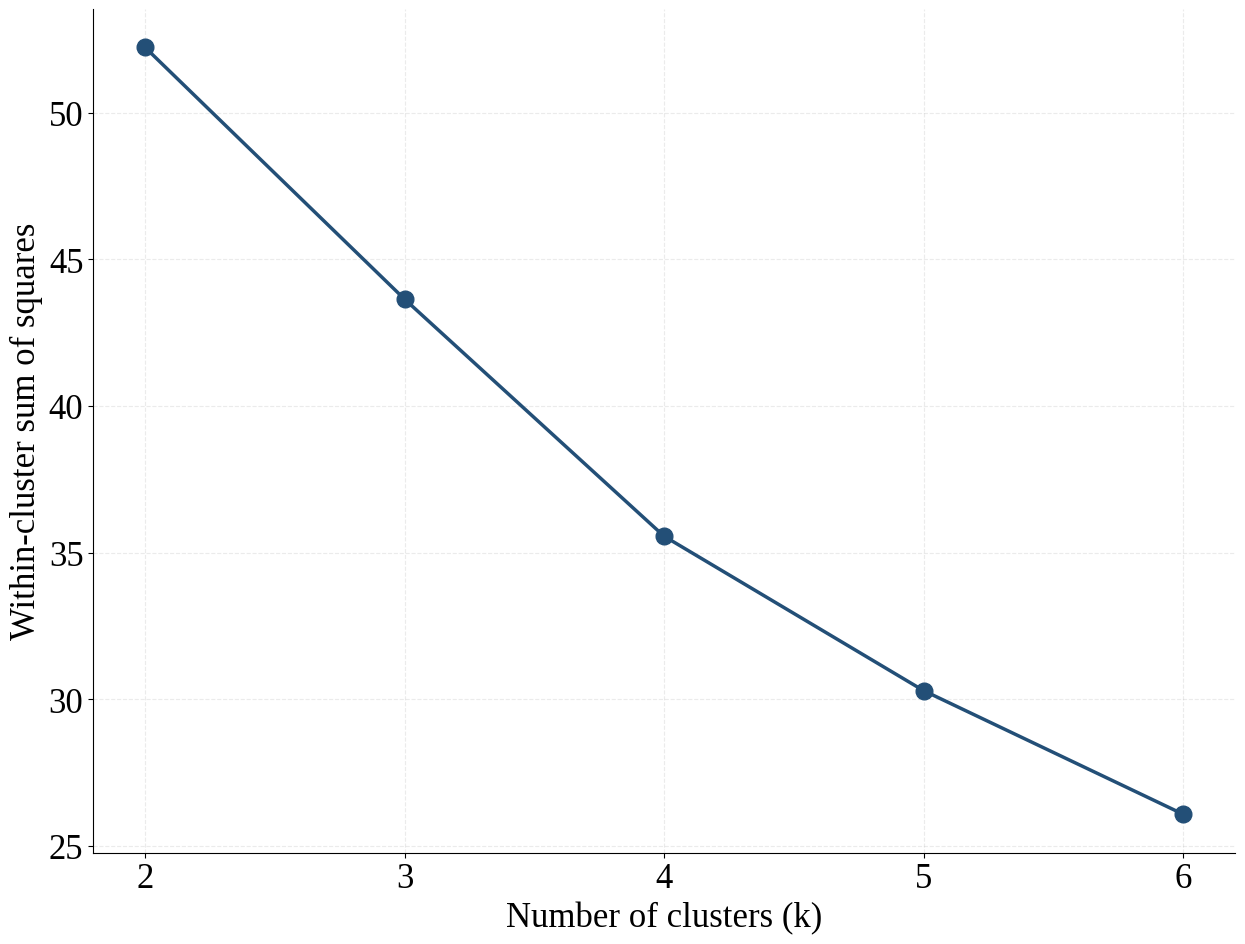

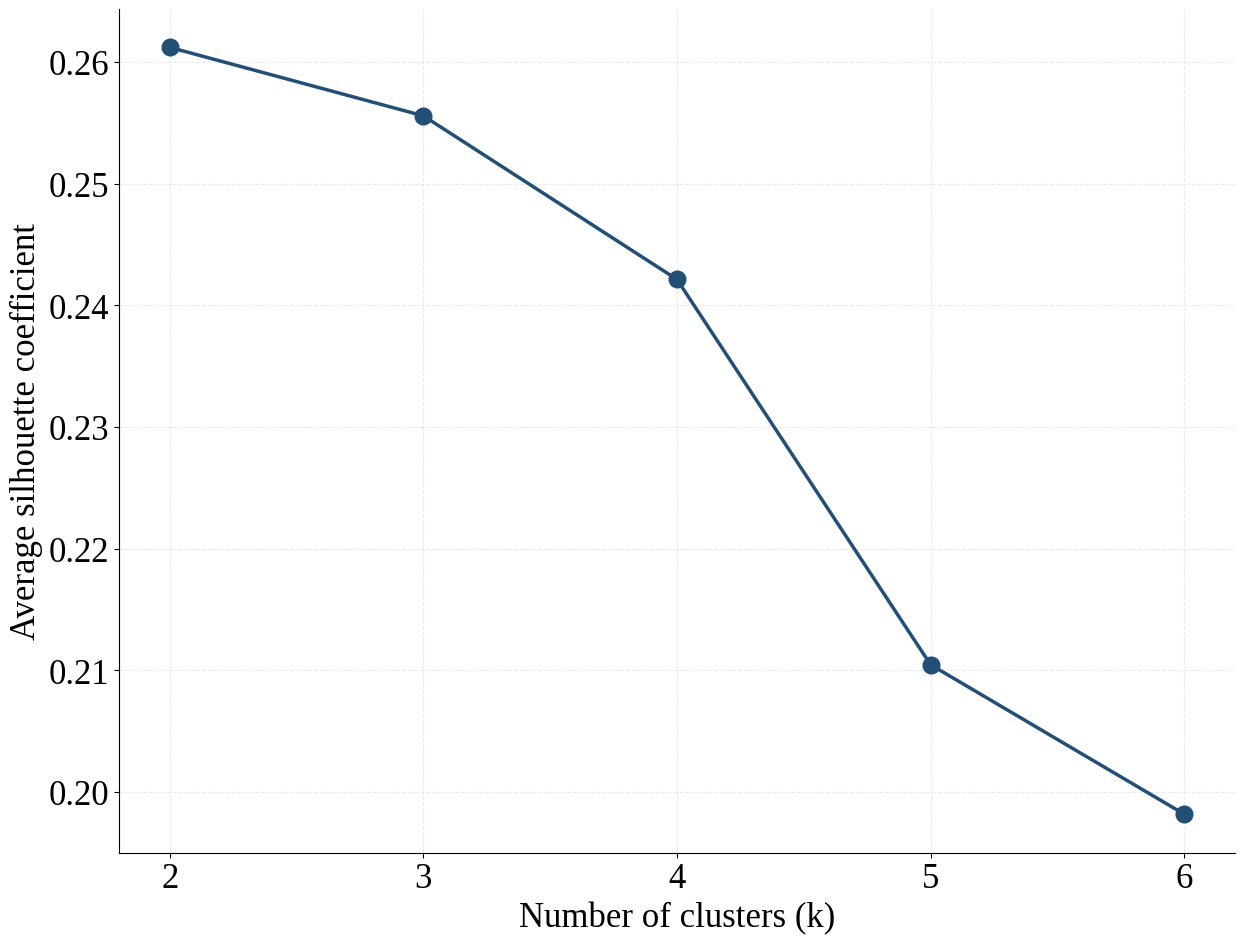


G.2.A SELESAI
Jumlah cluster diuji: 2–6
Representasi: Seimbang
Hasil disimpan: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2/G2A_Hasil_KMeans_Seimbang.xlsx
Visualisasi disimpan: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2

Jumlah cluster terbaik belum ditetapkan. Evaluasi Elbow, Silhouette, dan ukuran cluster perlu dibahas terlebih dahulu.


In [ ]:
# ============================================================
# G.2.A — K-MEANS CLUSTERING
# PEMILIHAN JUMLAH CLUSTER: k = 2, 3, 4, 5, 6
#
# Referensi:
# Rogel-Salazar (2017), Data Science and Analytics
# with Python, Chapter 5.2 — Clustering with k-means
#
# Dataset utama : F6C_Seimbang
# Observasi     : 22 kabupaten/kota
# Indikator     : 14
# Jarak         : Euclidean
# Evaluasi      : WCSS (Elbow) dan Silhouette
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display


# ============================================================
# G.2.A.1 — VALIDASI INPUT
# ============================================================

assert "SEIMBANG_G" in globals(), (
    "Matriks SEIMBANG_G tidak ditemukan. "
    "Jalankan G.0 terlebih dahulu."
)

X_KMEANS_G2A = SEIMBANG_G.copy()

assert X_KMEANS_G2A.shape == (22, 14)
assert X_KMEANS_G2A.index.is_unique
assert X_KMEANS_G2A.columns.is_unique

X = X_KMEANS_G2A.to_numpy(dtype=float)

assert np.isfinite(X).all()

print("=" * 65)
print("G.2.A — INPUT K-MEANS")
print("=" * 65)

print("Jumlah wilayah :", X.shape[0])
print("Jumlah fitur   :", X.shape[1])
print("Representasi   : Seimbang")
print("Jarak          : Euclidean")


# ============================================================
# G.2.A.2 — PARAMETER EKSPERIMEN
# ============================================================

K_RANGE_G2A = range(2, 7)

RANDOM_STATE_G2A = 42
N_INIT_G2A = 100
MAX_ITER_G2A = 500

OUT_G2A = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Pemilihan_Parameter_G2"
)

OUT_G2A.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# G.2.A.3 — FITTING K-MEANS UNTUK k = 2–6
# ============================================================

hasil_list_g2a = []

MODEL_KMEANS_G2A = {}
LABEL_KMEANS_G2A = {}

for k in K_RANGE_G2A:

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=N_INIT_G2A,
        random_state=RANDOM_STATE_G2A,
        max_iter=MAX_ITER_G2A,
        tol=1e-4,
        algorithm="lloyd"
    )

    labels = model.fit_predict(X)

    ukuran = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    jumlah_cluster = len(np.unique(labels))

    # Memastikan seluruh k cluster terbentuk.
    assert jumlah_cluster == k, (
        f"k={k}: jumlah cluster aktual "
        f"tidak sesuai."
    )

    # WCSS: jumlah kuadrat jarak observasi
    # terhadap centroid masing-masing cluster.
    wcss = float(model.inertia_)

    # Silhouette: rata-rata setiap observasi,
    # menggunakan jarak Euclidean.
    silhouette = silhouette_score(
        X,
        labels,
        metric="euclidean"
    )

    hasil_list_g2a.append({
        "k": k,
        "WCSS": wcss,
        "Silhouette": silhouette,
        "ukuran_minimum": int(ukuran.min()),
        "ukuran_maksimum": int(ukuran.max()),
        "jumlah_singleton": int(
            (ukuran == 1).sum()
        ),
        "ukuran_cluster": ", ".join(
            map(
                str,
                sorted(ukuran.tolist())
            )
        ),
        "konvergen": model.n_iter_ < MAX_ITER_G2A
    })

    MODEL_KMEANS_G2A[k] = model

    LABEL_KMEANS_G2A[k] = pd.Series(
        labels,
        index=X_KMEANS_G2A.index,
        name=f"KMeans_k{k}"
    )


# ============================================================
# G.2.A.4 — TABEL EVALUASI K-MEANS
# ============================================================

HASIL_KMEANS_G2A = pd.DataFrame(
    hasil_list_g2a
)

HASIL_KMEANS_G2A["penurunan_WCSS_persen"] = (
    100
    * (
        HASIL_KMEANS_G2A["WCSS"].shift(1)
        - HASIL_KMEANS_G2A["WCSS"]
    )
    / HASIL_KMEANS_G2A["WCSS"].shift(1)
)

print("\n" + "=" * 65)
print("G.2.A — EVALUASI k = 2–6")
print("=" * 65)

display(
    HASIL_KMEANS_G2A.round(5)
)

print(
    "\nCatatan: penurunan WCSS untuk k=2 "
    "tidak dihitung karena k=1 tidak diuji."
)


# ============================================================
# G.2.A.5 — KANDIDAT BERDASARKAN SILHOUETTE
# ============================================================

KANDIDAT_KMEANS_G2A = (
    HASIL_KMEANS_G2A
    .sort_values(
        "Silhouette",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nKANDIDAT MENURUT NILAI SILHOUETTE")

display(
    KANDIDAT_KMEANS_G2A[
        [
            "k",
            "Silhouette",
            "WCSS",
            "ukuran_cluster",
            "jumlah_singleton"
        ]
    ].round(5)
)


# ============================================================
# G.2.A.6 — PENGATURAN VISUALISASI
# ============================================================

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "savefig.dpi": 300
})


# ============================================================
# G.2.A.7 — ELBOW PLOT (WCSS)
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 10)
)

ax.plot(
    HASIL_KMEANS_G2A["k"],
    HASIL_KMEANS_G2A["WCSS"],
    marker="o",
    markersize=12,
    linewidth=2.5,
    color="#234F77"
)

ax.set_xlabel(
    "Number of clusters (k)"
)

ax.set_ylabel(
    "Within-cluster sum of squares"
)

ax.set_xticks(
    list(K_RANGE_G2A)
)

ax.grid(
    alpha=0.25,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUT_G2A / "G2A_KMeans_Elbow_Seimbang.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# G.2.A.8 — SILHOUETTE PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 10)
)

ax.plot(
    HASIL_KMEANS_G2A["k"],
    HASIL_KMEANS_G2A["Silhouette"],
    marker="o",
    markersize=12,
    linewidth=2.5,
    color="#234F77"
)

ax.set_xlabel(
    "Number of clusters (k)"
)

ax.set_ylabel(
    "Average silhouette coefficient"
)

ax.set_xticks(
    list(K_RANGE_G2A)
)

ax.grid(
    alpha=0.25,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUT_G2A / "G2A_KMeans_Silhouette_Seimbang.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# G.2.A.9 — SIMPAN HASIL NUMERIK
# ============================================================

FILE_HASIL_G2A = (
    OUT_G2A / "G2A_Hasil_KMeans_Seimbang.xlsx"
)

keanggotaan_g2a = pd.DataFrame(
    LABEL_KMEANS_G2A,
    index=X_KMEANS_G2A.index
)

with pd.ExcelWriter(
    FILE_HASIL_G2A,
    engine="openpyxl"
) as writer:

    HASIL_KMEANS_G2A.to_excel(
        writer,
        sheet_name="Evaluasi_K",
        index=False
    )

    keanggotaan_g2a.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )


print("\n" + "=" * 65)
print("G.2.A SELESAI")
print("=" * 65)

print("Jumlah cluster diuji: 2–6")
print("Representasi: Seimbang")
print("Hasil disimpan:", FILE_HASIL_G2A)
print("Visualisasi disimpan:", OUT_G2A)

print(
    "\nJumlah cluster terbaik belum ditetapkan. "
    "Evaluasi Elbow, Silhouette, dan ukuran "
    "cluster perlu dibahas terlebih dahulu."
)

In [ ]:
# ============================================================
# G.2.A.10 — PEMERIKSAAN KEANGGOTAAN K=2 DAN K=3
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import silhouette_samples
from IPython.display import display

assert 2 in LABEL_KMEANS_G2A
assert 3 in LABEL_KMEANS_G2A

X_g2a = SEIMBANG_G.to_numpy(dtype=float)

hasil_keanggotaan = pd.DataFrame({
    "kabupaten_kota": SEIMBANG_G.index
})

for k in [2, 3]:

    labels = LABEL_KMEANS_G2A[k].reindex(
        SEIMBANG_G.index
    )

    assert labels.notna().all()

    hasil_keanggotaan[f"cluster_k{k}"] = labels.to_numpy()

    hasil_keanggotaan[f"silhouette_k{k}"] = (
        silhouette_samples(
            X_g2a,
            labels.to_numpy(),
            metric="euclidean"
        )
    )

# ------------------------------------------------------------
# A. PERBANDINGAN KEANGGOTAAN WILAYAH
# ------------------------------------------------------------

print("\nA. KEANGGOTAAN K=2 DAN K=3")

display(
    hasil_keanggotaan.sort_values(
        ["cluster_k2", "cluster_k3", "kabupaten_kota"]
    ).round(4)
)

# ------------------------------------------------------------
# B. TABEL SILANG PERUBAHAN KEANGGOTAAN
# ------------------------------------------------------------

print("\nB. PERUBAHAN KEANGGOTAAN CLUSTER")

display(
    pd.crosstab(
        hasil_keanggotaan["cluster_k2"],
        hasil_keanggotaan["cluster_k3"],
        rownames=["K-Means k=2"],
        colnames=["K-Means k=3"]
    )
)

# ------------------------------------------------------------
# C. RINGKASAN SILHOUETTE SETIAP CLUSTER
# ------------------------------------------------------------

print("\nC. KUALITAS MASING-MASING CLUSTER")

for k in [2, 3]:

    ringkasan = (
        hasil_keanggotaan
        .groupby(f"cluster_k{k}")
        .agg(
            jumlah_wilayah=("kabupaten_kota", "count"),
            mean_silhouette=(f"silhouette_k{k}", "mean"),
            min_silhouette=(f"silhouette_k{k}", "min"),
            max_silhouette=(f"silhouette_k{k}", "max")
        )
    )

    print(f"\nK-Means k={k}")
    display(ringkasan.round(4))

print(
    "\nCatatan: silhouette observasi pada cluster "
    "singleton bernilai 0 menurut konvensi sklearn."
)


A. KEANGGOTAAN K=2 DAN K=3


,kabupaten_kota,cluster_k2,silhouette_k2,cluster_k3,silhouette_k3
5,Belu,0,0.3302,1,0.2731
10,Ende,0,0.2470,1,0.1701
21,Kota Kupang,0,0.2276,1,0.2091
2,Kupang,0,0.2416,1,0.1707
20,Malaka,0,0.2718,1,0.2359
12,Manggarai,0,0.4269,1,0.4010
14,Manggarai Barat,0,0.4088,1,0.3804
18,Manggarai Timur,0,0.4065,1,0.3792
17,Nagekeo,0,0.3005,1,0.2726
11,Ngada,0,0.2784,1,0.2402



B. PERUBAHAN KEANGGOTAAN CLUSTER


K-Means k=3,0,1,2
K-Means k=2,,,
0,0,17,0
1,4,0,1



C. KUALITAS MASING-MASING CLUSTER

K-Means k=2


,jumlah_wilayah,mean_silhouette,min_silhouette,max_silhouette
cluster_k2,,,,
0,17,0.3279,0.2226,0.4526
1,5,0.0345,-0.0889,0.2133



K-Means k=3


,jumlah_wilayah,mean_silhouette,min_silhouette,max_silhouette
cluster_k3,,,,
0,4,0.1511,0.0048,0.3344
1,17,0.2952,0.1701,0.4177
2,1,0.0000,0.0000,0.0000



Catatan: silhouette observasi pada cluster singleton bernilai 0 menurut konvensi sklearn.


# K-Medoids dengan Partitioning Around Medoids (PAM)

G.2.B — K-MEDOIDS PAM
Representasi: Seimbang
Jumlah observasi: 22
Jumlah indikator: 14
Nilai k: 2–6
Metode: PAM BUILD + SWAP
Random starts tambahan: 30

A. EVALUASI PARAMETER


,k,total_cost,Silhouette,ukuran_minimum,ukuran_maksimum,jumlah_singleton,silhouette_negatif,ukuran_cluster,medoid_wilayah,inisialisasi_terpilih,start_biaya_terbaik,total_start,penurunan_cost_persen
0,2,34.39024,0.24907,3,19,0,1,"3, 19","Timor Tengah Utara, Lembata",BUILD,31,31,NaN
1,3,30.88128,0.26384,1,18,1,1,"1, 3, 18","Timor Tengah Utara, Lembata, Sabu Raijua",BUILD,31,31,10.20335
2,4,28.06302,0.10854,1,14,1,3,"1, 3, 4, 14","Timor Tengah Utara, Lembata, Sumba Barat Daya,...",BUILD,31,31,9.12612
3,5,25.78359,0.12149,1,13,1,3,"1, 2, 2, 4, 13","Kupang, Timor Tengah Utara, Lembata, Sumba Bar...",BUILD,20,31,8.12256
4,6,23.60446,0.10831,1,12,2,4,"1, 1, 2, 2, 4, 12","Kupang, Timor Tengah Utara, Lembata, Ngada, Su...",BUILD,18,31,8.45160



B. KANDIDAT MENURUT SILHOUETTE


,k,total_cost,Silhouette,ukuran_cluster,jumlah_singleton,silhouette_negatif,medoid_wilayah
1,3,30.88128,0.26384,"1, 3, 18",1,1,"Timor Tengah Utara, Lembata, Sabu Raijua"
0,2,34.39024,0.24907,"3, 19",0,1,"Timor Tengah Utara, Lembata"
3,5,25.78359,0.12149,"1, 2, 2, 4, 13",1,3,"Kupang, Timor Tengah Utara, Lembata, Sumba Bar..."
2,4,28.06302,0.10854,"1, 3, 4, 14",1,3,"Timor Tengah Utara, Lembata, Sumba Barat Daya,..."
4,6,23.60446,0.10831,"1, 1, 2, 2, 4, 12",2,4,"Kupang, Timor Tengah Utara, Lembata, Ngada, Su..."


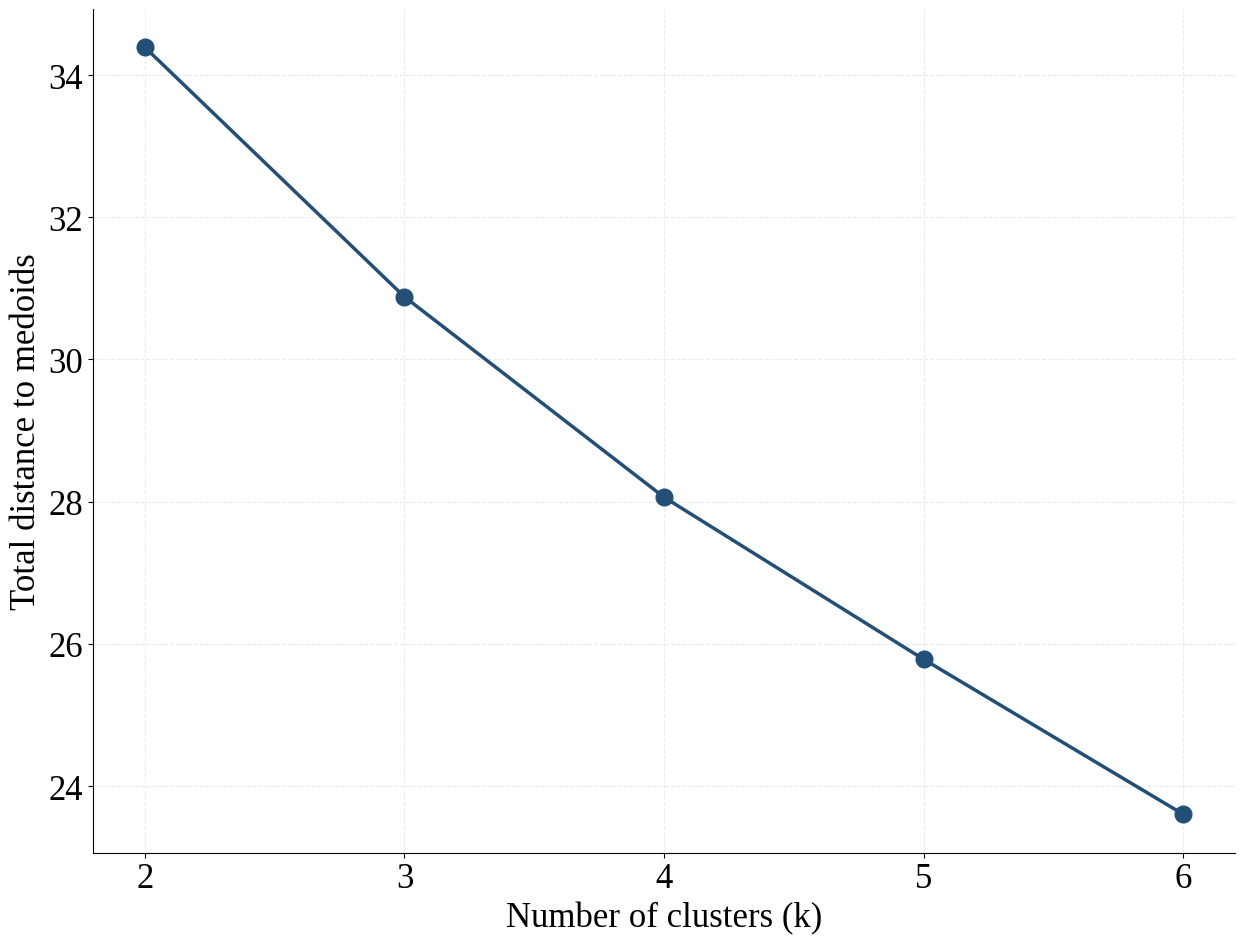

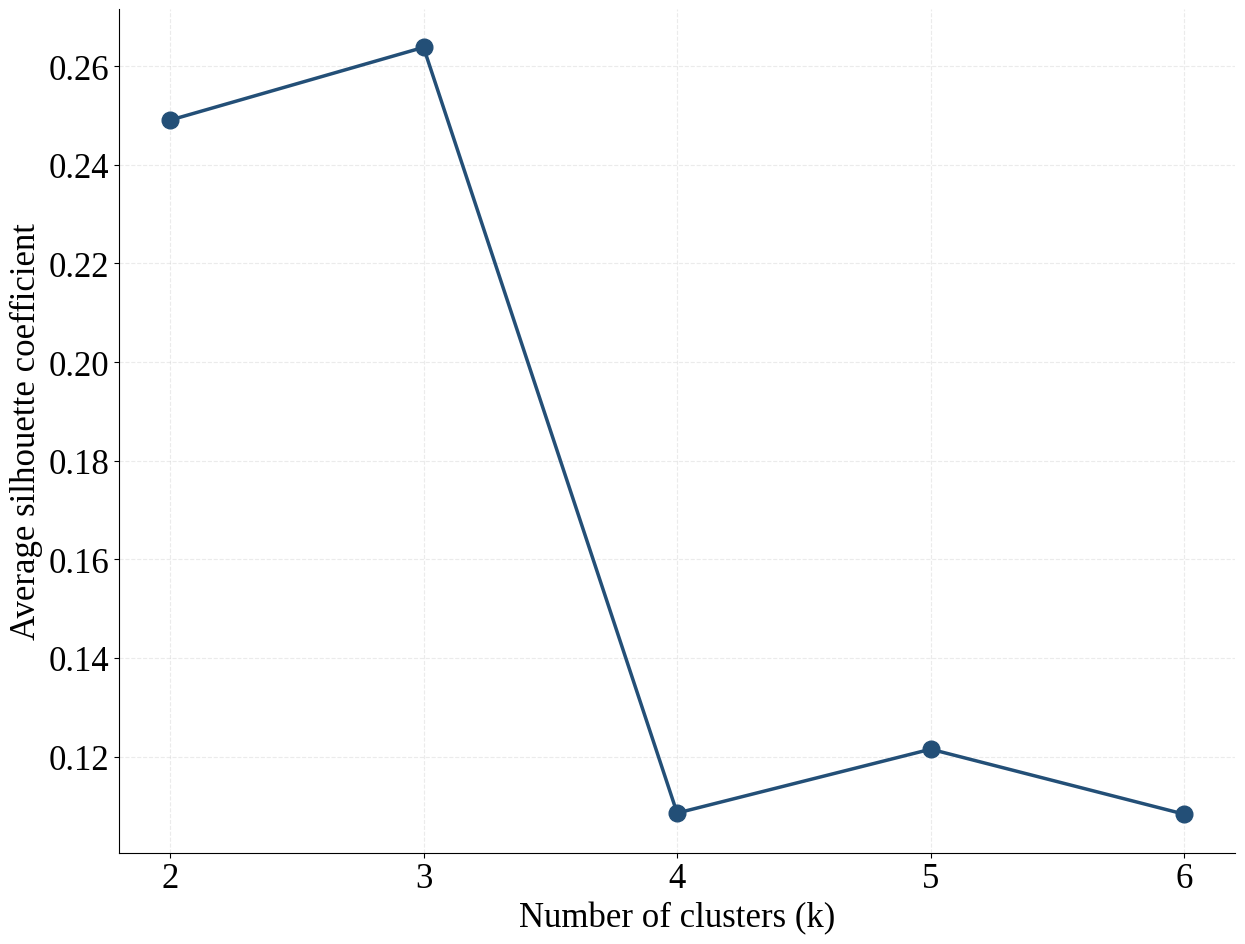


G.2.B SELESAI
File evaluasi: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2/G2B_Hasil_PAM_Seimbang.xlsx
Folder grafik: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2

Belum ada jumlah cluster optimal final. Periksa kurva biaya, Silhouette, ukuran cluster, dan medoid wilayah.


In [ ]:
# ============================================================
# G.2.B — K-MEDOIDS: PARTITIONING AROUND MEDOIDS (PAM)
#
# Referensi metode:
# Kaufman & Rousseeuw (1990), Finding Groups in Data,
# Chapter 2 — Partitioning Around Medoids
#
# Input       : SEIMBANG_G
# Observasi   : 22 kabupaten/kota
# Indikator   : 14
# Jarak       : Euclidean
# Nilai k     : 2–6
# Inisialisasi: BUILD + 30 random starts
# Optimisasi  : PAM SWAP
# Evaluasi    : Total cost dan Silhouette
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples
)
from IPython.display import display


# ============================================================
# G.2.B.1 — VALIDASI INPUT
# ============================================================

assert "SEIMBANG_G" in globals(), (
    "SEIMBANG_G tidak ditemukan. Jalankan G.0."
)

X_PAM_G2B = SEIMBANG_G.copy()

assert X_PAM_G2B.shape == (22, 14)
assert X_PAM_G2B.index.is_unique
assert X_PAM_G2B.columns.is_unique

X = X_PAM_G2B.to_numpy(dtype=float)

assert np.isfinite(X).all()

WILAYAH_PAM = X_PAM_G2B.index.to_numpy()

# Matriks jarak Euclidean 22 x 22
D_PAM_G2B = squareform(
    pdist(X, metric="euclidean")
)

assert D_PAM_G2B.shape == (22, 22)
assert np.allclose(D_PAM_G2B, D_PAM_G2B.T)
assert np.allclose(np.diag(D_PAM_G2B), 0)


# ============================================================
# G.2.B.2 — PARAMETER EKSPERIMEN
# ============================================================

K_RANGE_PAM = range(2, 7)

RANDOM_STATE_PAM = 42
N_RANDOM_STARTS_PAM = 30
MAX_SWAP_PAM = 200
TOL_PAM = 1e-10

rng_pam = np.random.default_rng(
    RANDOM_STATE_PAM
)

OUT_G2B = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Pemilihan_Parameter_G2"
)

OUT_G2B.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# G.2.B.3 — FUNGSI OBJEKTIF PAM
# ============================================================

def pam_cost_g2b(D, medoids):
    """
    Jumlah jarak Euclidean setiap observasi
    menuju medoid terdekat.
    """

    medoids = np.asarray(
        medoids, dtype=int
    )

    jarak_terdekat = np.min(
        D[:, medoids],
        axis=1
    )

    return float(
        np.sum(jarak_terdekat)
    )


# ============================================================
# G.2.B.4 — PAM BUILD
# ============================================================

def pam_build_g2b(D, k):
    """
    BUILD:
    1. Pilih observasi dengan jumlah jarak terkecil.
    2. Tambahkan kandidat yang memberikan biaya
       pengelompokan terkecil.
    3. Ulangi sampai terdapat k medoid.
    """

    n = D.shape[0]

    # Medoid pertama
    pertama = int(
        np.argmin(D.sum(axis=1))
    )

    medoids = [pertama]

    # Medoid berikutnya
    while len(medoids) < k:

        kandidat = [
            j for j in range(n)
            if j not in medoids
        ]

        terbaik = min(
            kandidat,
            key=lambda j: (
                pam_cost_g2b(
                    D, medoids + [j]
                ),
                j
            )
        )

        medoids.append(int(terbaik))

    return sorted(medoids)


# ============================================================
# G.2.B.5 — PAM SWAP
# ============================================================

def pam_swap_g2b(
    D,
    medoids_awal,
    max_iter=200,
    tol=1e-10
):
    """
    SWAP:
    Mengevaluasi seluruh pertukaran antara
    medoid dan non-medoid.

    Pertukaran terbaik diterima hanya jika
    menurunkan total biaya PAM.
    """

    n = D.shape[0]

    medoids = sorted(
        int(m) for m in medoids_awal
    )

    biaya = pam_cost_g2b(
        D, medoids
    )

    for iterasi in range(max_iter):

        biaya_terbaik = biaya
        medoids_terbaik = None

        nonmedoids = [
            j for j in range(n)
            if j not in medoids
        ]

        # Seluruh kemungkinan pertukaran
        for posisi in range(len(medoids)):

            for kandidat in nonmedoids:

                calon = medoids.copy()

                calon[posisi] = kandidat

                calon = sorted(calon)

                biaya_calon = pam_cost_g2b(
                    D, calon
                )

                if biaya_calon < biaya_terbaik - tol:

                    biaya_terbaik = biaya_calon
                    medoids_terbaik = calon

        # Tidak ada pertukaran yang memperbaiki biaya
        if medoids_terbaik is None:

            return {
                "medoids": medoids,
                "cost": biaya,
                "iterasi": iterasi,
                "konvergen": True
            }

        medoids = medoids_terbaik
        biaya = biaya_terbaik

    raise RuntimeError(
        "PAM belum konvergen dalam batas iterasi."
    )


# ============================================================
# G.2.B.6 — PEMODELAN PAM UNTUK k = 2–6
# ============================================================

HASIL_LIST_PAM_G2B = []

MODEL_PAM_G2B = {}
LABEL_PAM_G2B = {}
MEDOID_PAM_G2B = {}

n = len(X)

for k in K_RANGE_PAM:

    # BUILD asli + SWAP
    inisialisasi = [
        ("BUILD", pam_build_g2b(D_PAM_G2B, k))
    ]

    # Inisialisasi acak tambahan + SWAP
    for r in range(N_RANDOM_STARTS_PAM):

        awal = sorted(
            rng_pam.choice(
                n,
                size=k,
                replace=False
            ).tolist()
        )

        inisialisasi.append(
            (f"Random_{r+1:02d}", awal)
        )

    seluruh_solusi = []

    for nama_awal, medoids_awal in inisialisasi:

        solusi = pam_swap_g2b(
            D_PAM_G2B,
            medoids_awal,
            max_iter=MAX_SWAP_PAM,
            tol=TOL_PAM
        )

        solusi["inisialisasi"] = nama_awal

        seluruh_solusi.append(solusi)

    # Solusi dengan total biaya terkecil
    solusi_terbaik = min(
        seluruh_solusi,
        key=lambda s: (
            s["cost"],
            tuple(s["medoids"])
        )
    )

    medoids = solusi_terbaik["medoids"]

    # Penetapan cluster menurut medoid terdekat
    labels = np.argmin(
        D_PAM_G2B[:, medoids],
        axis=1
    )

    assert len(np.unique(labels)) == k

    # Validasi ulang fungsi objektif
    biaya_akhir = pam_cost_g2b(
        D_PAM_G2B,
        medoids
    )

    assert np.isclose(
        biaya_akhir,
        solusi_terbaik["cost"]
    )

    # Silhouette menggunakan jarak Euclidean
    silhouette = silhouette_score(
        D_PAM_G2B,
        labels,
        metric="precomputed"
    )

    nilai_individu = silhouette_samples(
        D_PAM_G2B,
        labels,
        metric="precomputed"
    )

    ukuran = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    nama_medoids = [
        str(WILAYAH_PAM[i])
        for i in medoids
    ]

    # Frekuensi inisialisasi yang mencapai
    # biaya minimum yang sama
    start_optimal = sum(
        np.isclose(
            s["cost"],
            biaya_akhir,
            rtol=1e-9,
            atol=1e-9
        )
        for s in seluruh_solusi
    )

    HASIL_LIST_PAM_G2B.append({
        "k": k,
        "total_cost": biaya_akhir,
        "Silhouette": silhouette,
        "ukuran_minimum": int(ukuran.min()),
        "ukuran_maksimum": int(ukuran.max()),
        "jumlah_singleton": int(
            (ukuran == 1).sum()
        ),
        "silhouette_negatif": int(
            (nilai_individu < 0).sum()
        ),
        "ukuran_cluster": ", ".join(
            map(
                str,
                sorted(ukuran.tolist())
            )
        ),
        "medoid_wilayah": ", ".join(
            nama_medoids
        ),
        "inisialisasi_terpilih":
            solusi_terbaik["inisialisasi"],
        "start_biaya_terbaik": start_optimal,
        "total_start": len(seluruh_solusi)
    })

    MODEL_PAM_G2B[k] = solusi_terbaik

    LABEL_PAM_G2B[k] = pd.Series(
        labels,
        index=X_PAM_G2B.index,
        name=f"PAM_k{k}"
    )

    MEDOID_PAM_G2B[k] = nama_medoids


# ============================================================
# G.2.B.7 — TABEL EVALUASI
# ============================================================

HASIL_PAM_G2B = pd.DataFrame(
    HASIL_LIST_PAM_G2B
)

HASIL_PAM_G2B["penurunan_cost_persen"] = (
    100
    * (
        HASIL_PAM_G2B["total_cost"].shift(1)
        - HASIL_PAM_G2B["total_cost"]
    )
    / HASIL_PAM_G2B["total_cost"].shift(1)
)

print("=" * 70)
print("G.2.B — K-MEDOIDS PAM")
print("=" * 70)

print("Representasi:", "Seimbang")
print("Jumlah observasi:", len(X))
print("Jumlah indikator:", X.shape[1])
print("Nilai k:", "2–6")
print("Metode:", "PAM BUILD + SWAP")
print("Random starts tambahan:", N_RANDOM_STARTS_PAM)

print("\nA. EVALUASI PARAMETER")

display(
    HASIL_PAM_G2B.round(5)
)

print("\nB. KANDIDAT MENURUT SILHOUETTE")

display(
    HASIL_PAM_G2B
    .sort_values(
        "Silhouette",
        ascending=False
    )[
        [
            "k",
            "total_cost",
            "Silhouette",
            "ukuran_cluster",
            "jumlah_singleton",
            "silhouette_negatif",
            "medoid_wilayah"
        ]
    ].round(5)
)


# ============================================================
# G.2.B.8 — PENGATURAN VISUALISASI
# ============================================================

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "savefig.dpi": 300
})


# ============================================================
# G.2.B.9 — KURVA BIAYA PAM
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 10)
)

ax.plot(
    HASIL_PAM_G2B["k"],
    HASIL_PAM_G2B["total_cost"],
    marker="o",
    markersize=12,
    linewidth=2.5,
    color="#234F77"
)

ax.set_xlabel(
    "Number of clusters (k)"
)

ax.set_ylabel(
    "Total distance to medoids"
)

ax.set_xticks(
    list(K_RANGE_PAM)
)

ax.grid(
    alpha=0.25,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUT_G2B / "G2B_PAM_TotalCost_Seimbang.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# G.2.B.10 — KURVA SILHOUETTE PAM
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 10)
)

ax.plot(
    HASIL_PAM_G2B["k"],
    HASIL_PAM_G2B["Silhouette"],
    marker="o",
    markersize=12,
    linewidth=2.5,
    color="#234F77"
)

ax.set_xlabel(
    "Number of clusters (k)"
)

ax.set_ylabel(
    "Average silhouette coefficient"
)

ax.set_xticks(
    list(K_RANGE_PAM)
)

ax.grid(
    alpha=0.25,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUT_G2B / "G2B_PAM_Silhouette_Seimbang.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# G.2.B.11 — SIMPAN HASIL
# ============================================================

FILE_HASIL_PAM_G2B = (
    OUT_G2B / "G2B_Hasil_PAM_Seimbang.xlsx"
)

keanggotaan_pam = pd.DataFrame(
    LABEL_PAM_G2B,
    index=X_PAM_G2B.index
)

medoid_tabel = pd.DataFrame([
    {
        "k": k,
        "nomor_medoid": j + 1,
        "kabupaten_kota": nama
    }
    for k, nama_list in MEDOID_PAM_G2B.items()
    for j, nama in enumerate(nama_list)
])

with pd.ExcelWriter(
    FILE_HASIL_PAM_G2B,
    engine="openpyxl"
) as writer:

    HASIL_PAM_G2B.to_excel(
        writer,
        sheet_name="Evaluasi_K",
        index=False
    )

    keanggotaan_pam.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )

    medoid_tabel.to_excel(
        writer,
        sheet_name="Daftar_Medoid",
        index=False
    )


print("\n" + "=" * 70)
print("G.2.B SELESAI")
print("=" * 70)

print("File evaluasi:", FILE_HASIL_PAM_G2B)
print("Folder grafik:", OUT_G2B)

print(
    "\nBelum ada jumlah cluster optimal final. "
    "Periksa kurva biaya, Silhouette, "
    "ukuran cluster, dan medoid wilayah."
)

In [ ]:
# ============================================================
# G.2.B.12 — PEMERIKSAAN KEANGGOTAAN PAM k=2 DAN k=3
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import silhouette_samples
from IPython.display import display

# ------------------------------------------------------------
# 1. VALIDASI OBJEK
# ------------------------------------------------------------

assert all(
    k in LABEL_PAM_G2B
    and k in MEDOID_PAM_G2B
    for k in [2, 3]
)

X_PAM_CHECK = SEIMBANG_G.to_numpy(dtype=float)

hasil_individu_pam = []
hasil_cluster_pam = []

# ------------------------------------------------------------
# 2. HITUNG SILHOUETTE PER WILAYAH DAN PER CLUSTER
# ------------------------------------------------------------

for k in [2, 3]:

    label = (
        LABEL_PAM_G2B[k]
        .reindex(SEIMBANG_G.index)
        .astype(int)
    )

    silhouette = silhouette_samples(
        X_PAM_CHECK,
        label.to_numpy(),
        metric="euclidean"
    )

    medoid = MEDOID_PAM_G2B[k]

    for c in sorted(label.unique()):

        posisi = np.flatnonzero(
            label.to_numpy() == c
        )

        anggota = SEIMBANG_G.index[posisi].tolist()
        nilai_sil = silhouette[posisi]

        hasil_cluster_pam.append({
            "k": k,
            "cluster": c,
            "medoid": medoid[c],
            "jumlah_wilayah": len(anggota),
            "mean_silhouette": nilai_sil.mean(),
            "min_silhouette": nilai_sil.min(),
            "silhouette_negatif": int(
                (nilai_sil < 0).sum()
            ),
            "anggota": ", ".join(anggota)
        })

        for i in posisi:

            hasil_individu_pam.append({
                "k": k,
                "kabupaten_kota": SEIMBANG_G.index[i],
                "cluster": c,
                "medoid": medoid[c],
                "silhouette": silhouette[i]
            })


# ------------------------------------------------------------
# 3. TAMPILKAN HASIL
# ------------------------------------------------------------

RINGKASAN_CLUSTER_PAM_G2B = pd.DataFrame(
    hasil_cluster_pam
)

DETAIL_PAM_G2B = pd.DataFrame(
    hasil_individu_pam
)

print("\nA. KUALITAS MASING-MASING CLUSTER PAM")

display(
    RINGKASAN_CLUSTER_PAM_G2B.round(4)
)

print("\nB. KEANGGOTAAN PAM k=2")

display(
    DETAIL_PAM_G2B.query("k == 2")
    .sort_values(
        ["cluster", "kabupaten_kota"]
    )
    .round(4)
)

print("\nC. KEANGGOTAAN PAM k=3")

display(
    DETAIL_PAM_G2B.query("k == 3")
    .sort_values(
        ["cluster", "kabupaten_kota"]
    )
    .round(4)
)


# ------------------------------------------------------------
# 4. PERUBAHAN KEANGGOTAAN k=2 KE k=3
# ------------------------------------------------------------

pam_k2 = LABEL_PAM_G2B[2].reindex(
    SEIMBANG_G.index
)

pam_k3 = LABEL_PAM_G2B[3].reindex(
    SEIMBANG_G.index
)

print("\nD. TABEL SILANG PAM k=2 DAN k=3")

display(
    pd.crosstab(
        pam_k2,
        pam_k3,
        rownames=["PAM k=2"],
        colnames=["PAM k=3"]
    )
)

print(
    "\nCatatan: Silhouette singleton bernilai 0 "
    "mengikuti konvensi scikit-learn."
)


A. KUALITAS MASING-MASING CLUSTER PAM


,k,cluster,medoid,jumlah_wilayah,mean_silhouette,min_silhouette,silhouette_negatif,anggota
0,2,0,Timor Tengah Utara,19,0.2491,-0.0218,1,"Sumba Barat, Sumba Timur, Kupang, Timor Tengah..."
1,2,1,Lembata,3,0.2489,0.1083,0,"Lembata, Flores Timur, Rote Ndao"
2,3,0,Timor Tengah Utara,18,0.2830,-0.0105,1,"Sumba Barat, Sumba Timur, Kupang, Timor Tengah..."
3,3,1,Lembata,3,0.2369,0.0898,0,"Lembata, Flores Timur, Rote Ndao"
4,3,2,Sabu Raijua,1,0.0000,0.0000,0,Sabu Raijua



B. KEANGGOTAAN PAM k=2


,k,kabupaten_kota,cluster,medoid,silhouette
6,2,Alor,0,Timor Tengah Utara,-0.0218
5,2,Belu,0,Timor Tengah Utara,0.2366
8,2,Ende,0,Timor Tengah Utara,0.2027
18,2,Kota Kupang,0,Timor Tengah Utara,0.1610
2,2,Kupang,0,Timor Tengah Utara,0.0816
17,2,Malaka,0,Timor Tengah Utara,0.2559
10,2,Manggarai,0,Timor Tengah Utara,0.3771
11,2,Manggarai Barat,0,Timor Tengah Utara,0.3685
15,2,Manggarai Timur,0,Timor Tengah Utara,0.3635
14,2,Nagekeo,0,Timor Tengah Utara,0.2371



C. KEANGGOTAAN PAM k=3


,k,kabupaten_kota,cluster,medoid,silhouette
28,3,Alor,0,Timor Tengah Utara,-0.0105
27,3,Belu,0,Timor Tengah Utara,0.2740
30,3,Ende,0,Timor Tengah Utara,0.2378
39,3,Kota Kupang,0,Timor Tengah Utara,0.1787
24,3,Kupang,0,Timor Tengah Utara,0.1176
38,3,Malaka,0,Timor Tengah Utara,0.2809
32,3,Manggarai,0,Timor Tengah Utara,0.4097
33,3,Manggarai Barat,0,Timor Tengah Utara,0.4005
37,3,Manggarai Timur,0,Timor Tengah Utara,0.3951
36,3,Nagekeo,0,Timor Tengah Utara,0.2623



D. TABEL SILANG PAM k=2 DAN k=3


PAM k=3,0,1,2
PAM k=2,,,
0,18,0,1
1,0,3,0



Catatan: Silhouette singleton bernilai 0 mengikuti konvensi scikit-learn.


# Gaussian Mixture Model (GMM)

G.2.C — HASIL GAUSSIAN MIXTURE MODEL
Observasi: 22
Indikator: 14
Jumlah komponen: 2–6
Regularisasi: 0.01

A. SELURUH KONFIGURASI


,covariance_type,k,BIC,AIC,Silhouette,converged,warning_konvergensi,jumlah_cluster_aktual,ukuran_minimum,ukuran_cluster,jumlah_singleton,ukuran_efektif_min,mean_max_probability,wilayah_prob_kurang_08,covariance_minimum,covariance_dekat_batas
0,spherical,2,411.76101,377.93869,0.05254,True,0,2,7,"7, 15",0,6.99795,0.99972,0,0.05415,False
1,spherical,3,401.55549,350.27649,0.10816,True,0,3,1,"1, 10, 11",1,1.00000,0.97525,1,0.01000,True
2,spherical,4,393.99549,325.25981,0.10556,True,0,4,1,"1, 3, 7, 11",1,1.00000,0.99886,0,0.01000,True
3,spherical,5,378.89190,292.69955,0.11565,True,0,5,1,"1, 1, 3, 7, 10",2,1.00000,0.99892,0,0.01000,True
4,spherical,6,358.59219,254.94316,0.15776,True,0,6,1,"1, 1, 1, 1, 4, 14",4,1.00000,0.99992,0,0.01000,True
5,diag,2,372.09567,309.90625,0.26119,True,0,2,5,"5, 17",0,5.00349,0.99984,0,0.01255,False
6,diag,3,370.71203,276.88238,0.17587,True,0,3,1,"1, 6, 15",1,1.00000,0.99935,0,0.01000,True
7,diag,4,382.08982,256.61994,0.16776,True,0,4,1,"1, 3, 7, 11",1,1.00000,0.99947,0,0.01000,True
8,diag,5,391.73577,234.62566,0.13116,True,0,5,1,"1, 2, 2, 7, 10",1,1.00000,0.99883,0,0.01000,True
9,diag,6,428.22089,239.47055,0.13778,True,0,6,1,"1, 2, 2, 3, 7, 7",1,1.00000,0.99857,0,0.01000,True



B. KANDIDAT BERDASARKAN BIC


,covariance_type,k,BIC,Silhouette,ukuran_cluster,jumlah_singleton,ukuran_efektif_min,covariance_dekat_batas
4,spherical,6,358.59219,0.15776,"1, 1, 1, 1, 4, 14",4,1.00000,True
6,diag,3,370.71203,0.17587,"1, 6, 15",1,1.00000,True
5,diag,2,372.09567,0.26119,"5, 17",0,5.00349,False
3,spherical,5,378.89190,0.11565,"1, 1, 3, 7, 10",2,1.00000,True
7,diag,4,382.08982,0.16776,"1, 3, 7, 11",1,1.00000,True
8,diag,5,391.73577,0.13116,"1, 2, 2, 7, 10",1,1.00000,True
2,spherical,4,393.99549,0.10556,"1, 3, 7, 11",1,1.00000,True
1,spherical,3,401.55549,0.10816,"1, 10, 11",1,1.00000,True
0,spherical,2,411.76101,0.05254,"7, 15",0,6.99795,False
9,diag,6,428.22089,0.13778,"1, 2, 2, 3, 7, 7",1,1.00000,True


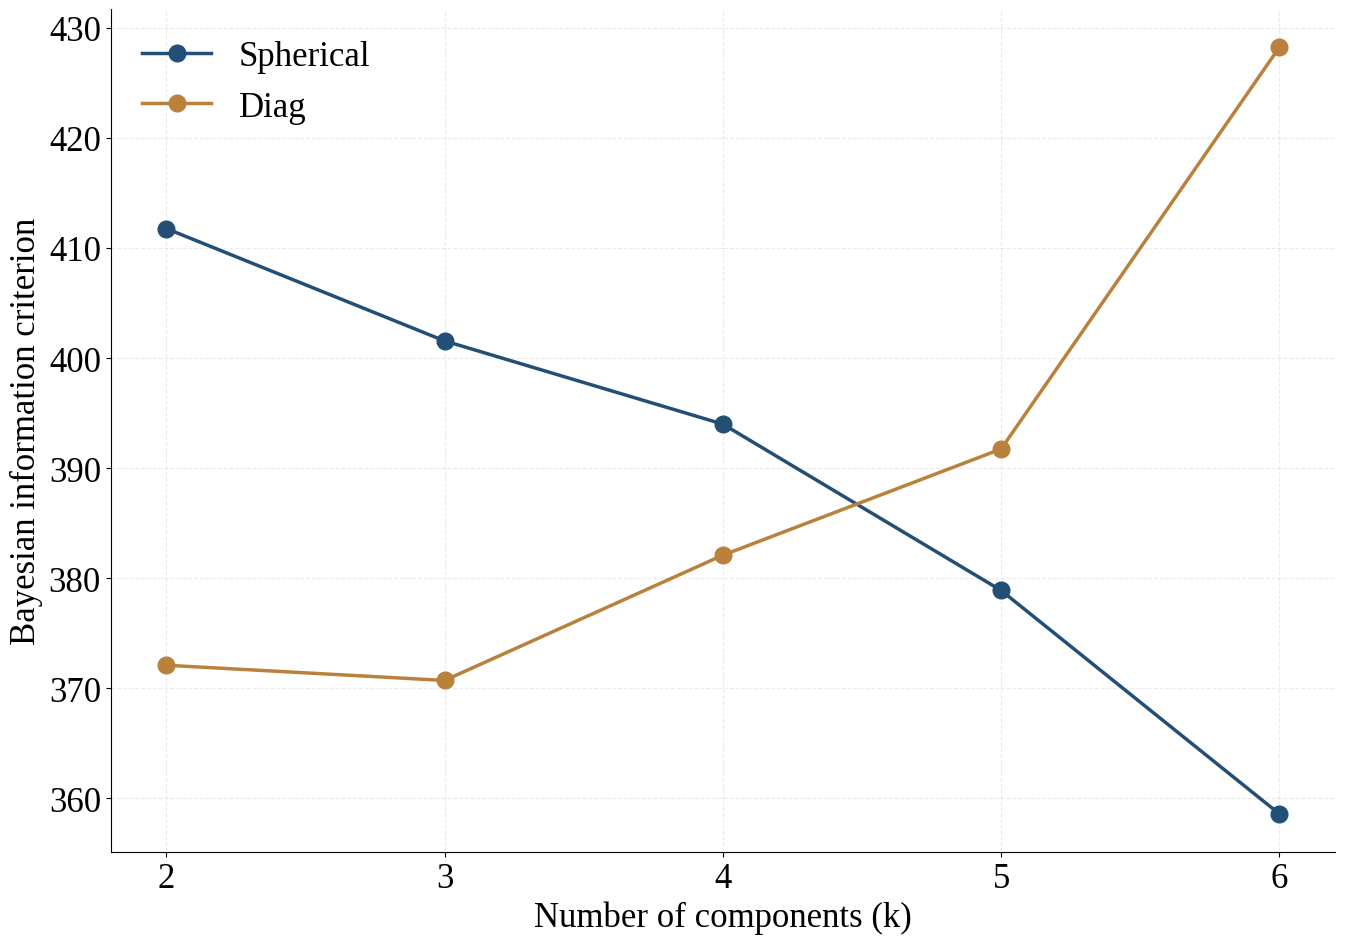


G.2.C SELESAI
File hasil: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2/G2C_Hasil_GMM_Seimbang.xlsx
Visualisasi: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2

Model GMM terbaik belum ditetapkan. BIC, konvergensi, ukuran komponen, dan potensi degenerasi harus diperiksa.


In [ ]:
# ============================================================
# G.2.C — GAUSSIAN MIXTURE MODEL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from pathlib import Path
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

# ------------------------------------------------------------
# G.2.C.1 — VALIDASI INPUT
# ------------------------------------------------------------

assert "SEIMBANG_G" in globals()

X_GMM_G2C = SEIMBANG_G.copy()

assert X_GMM_G2C.shape == (22, 14)
assert X_GMM_G2C.index.is_unique
assert X_GMM_G2C.columns.is_unique

X = X_GMM_G2C.to_numpy(dtype=float)

assert np.isfinite(X).all()

# ------------------------------------------------------------
# G.2.C.2 — PARAMETER
# ------------------------------------------------------------

K_RANGE_GMM = range(2, 7)

COV_TYPES_GMM = [
    "spherical",
    "diag"
]

REG_COVAR_GMM = 0.01
N_INIT_GMM = 30
MAX_ITER_GMM = 500
RANDOM_STATE_GMM = 42

OUT_G2C = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Pemilihan_Parameter_G2"
)

OUT_G2C.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# G.2.C.3 — FITTING SELURUH KONFIGURASI
# ------------------------------------------------------------

MODEL_GMM_G2C = {}
LABEL_GMM_G2C = {}
PROBA_GMM_G2C = {}

hasil_gmm = []

for covariance_type in COV_TYPES_GMM:

    for k in K_RANGE_GMM:

        model = GaussianMixture(
            n_components=k,
            covariance_type=covariance_type,
            reg_covar=REG_COVAR_GMM,
            n_init=N_INIT_GMM,
            init_params="kmeans",
            random_state=RANDOM_STATE_GMM,
            max_iter=MAX_ITER_GMM,
            tol=1e-4
        )

        with warnings.catch_warnings(record=True) as w:

            warnings.simplefilter(
                "always",
                ConvergenceWarning
            )

            model.fit(X)

        labels = model.predict(X)

        proba = model.predict_proba(X)

        assert np.allclose(
            proba.sum(axis=1), 1.0
        )

        assert np.isfinite(
            proba
        ).all()

        ukuran = np.bincount(
            labels, minlength=k
        )

        jumlah_aktual = int(
            np.sum(ukuran > 0)
        )

        if 2 <= jumlah_aktual < len(X):

            silhouette = silhouette_score(
                X,
                labels,
                metric="euclidean"
            )

        else:

            silhouette = np.nan

        # Total probabilitas masing-masing komponen.
        ukuran_efektif = proba.sum(axis=0)

        # Ukuran kepastian probabilitas keanggotaan.
        probabilitas_terbesar = proba.max(axis=1)

        jumlah_warning = sum(
            issubclass(
                item.category,
                ConvergenceWarning
            )
            for item in w
        )

        # Diagnostik komponen dengan varians
        # yang berada di batas regularisasi.
        cov_min = float(
            np.min(model.covariances_)
        )

        hasil_gmm.append({
            "covariance_type": covariance_type,
            "k": k,
            "BIC": float(model.bic(X)),
            "AIC": float(model.aic(X)),
            "Silhouette": silhouette,
            "converged": bool(model.converged_),
            "warning_konvergensi": jumlah_warning,
            "jumlah_cluster_aktual": jumlah_aktual,
            "ukuran_minimum": int(ukuran.min()),
            "ukuran_cluster": ", ".join(
                map(str, sorted(ukuran.tolist()))
            ),
            "jumlah_singleton": int(
                np.sum(ukuran == 1)
            ),
            "ukuran_efektif_min": float(
                ukuran_efektif.min()
            ),
            "mean_max_probability": float(
                probabilitas_terbesar.mean()
            ),
            "wilayah_prob_kurang_08": int(
                np.sum(probabilitas_terbesar < 0.8)
            ),
            "covariance_minimum": cov_min,
            "covariance_dekat_batas": bool(
                cov_min <= REG_COVAR_GMM + 1e-7
            )
        })

        key = (covariance_type, k)

        MODEL_GMM_G2C[key] = model

        LABEL_GMM_G2C[key] = pd.Series(
            labels,
            index=X_GMM_G2C.index,
            name=f"GMM_{covariance_type}_k{k}"
        )

        PROBA_GMM_G2C[key] = pd.DataFrame(
            proba,
            index=X_GMM_G2C.index,
            columns=[
                f"Komponen_{i}"
                for i in range(k)
            ]
        )

# ------------------------------------------------------------
# G.2.C.4 — HASIL PARAMETER
# ------------------------------------------------------------

HASIL_GMM_G2C = pd.DataFrame(
    hasil_gmm
)

print("=" * 65)
print("G.2.C — HASIL GAUSSIAN MIXTURE MODEL")
print("=" * 65)

print("Observasi:", X.shape[0])
print("Indikator:", X.shape[1])
print("Jumlah komponen: 2–6")
print("Regularisasi:", REG_COVAR_GMM)

print("\nA. SELURUH KONFIGURASI")

display(
    HASIL_GMM_G2C.round(5)
)

print("\nB. KANDIDAT BERDASARKAN BIC")

kandidat_gmm = (
    HASIL_GMM_G2C[
        HASIL_GMM_G2C["converged"]
        & HASIL_GMM_G2C["BIC"].notna()
    ]
    .sort_values(
        "BIC",
        ascending=True
    )
)

display(
    kandidat_gmm[
        [
            "covariance_type",
            "k",
            "BIC",
            "Silhouette",
            "ukuran_cluster",
            "jumlah_singleton",
            "ukuran_efektif_min",
            "covariance_dekat_batas"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# G.2.C.5 — VISUALISASI BIC
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(
    figsize=(14, 10)
)

warna = {
    "spherical": "#234F77",
    "diag": "#B9813B"
}

for covariance_type in COV_TYPES_GMM:

    subset = (
        HASIL_GMM_G2C[
            HASIL_GMM_G2C["covariance_type"]
            == covariance_type
        ]
        .sort_values("k")
    )

    ax.plot(
        subset["k"],
        subset["BIC"],
        marker="o",
        markersize=12,
        linewidth=2.5,
        color=warna[covariance_type],
        label=covariance_type.capitalize()
    )

ax.set_xlabel(
    "Number of components (k)"
)

ax.set_ylabel(
    "Bayesian information criterion"
)

ax.set_xticks(
    list(K_RANGE_GMM)
)

ax.legend(
    frameon=False
)

ax.grid(
    alpha=0.25,
    linestyle="--"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUT_G2C / "G2C_GMM_BIC_Seimbang.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# G.2.C.6 — SIMPAN HASIL
# ------------------------------------------------------------

FILE_GMM_G2C = (
    OUT_G2C / "G2C_Hasil_GMM_Seimbang.xlsx"
)

keanggotaan_gmm = pd.DataFrame(
    LABEL_GMM_G2C,
    index=X_GMM_G2C.index
)

# Gunakan nama kolom yang eksplisit
# agar seluruh konfigurasi mudah dibaca.
keanggotaan_gmm.columns = [
    f"GMM_{cov}_k{k}"
    for cov, k in LABEL_GMM_G2C
]

with pd.ExcelWriter(
    FILE_GMM_G2C,
    engine="openpyxl"
) as writer:

    HASIL_GMM_G2C.to_excel(
        writer,
        sheet_name="Evaluasi_GMM",
        index=False
    )

    keanggotaan_gmm.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )

print("\nG.2.C SELESAI")
print("File hasil:", FILE_GMM_G2C)
print("Visualisasi:", OUT_G2C)

print(
    "\nModel GMM terbaik belum ditetapkan. "
    "BIC, konvergensi, ukuran komponen, "
    "dan potensi degenerasi harus diperiksa."
)

# DBSCAN: Analisis clustering berbasis kepadatan

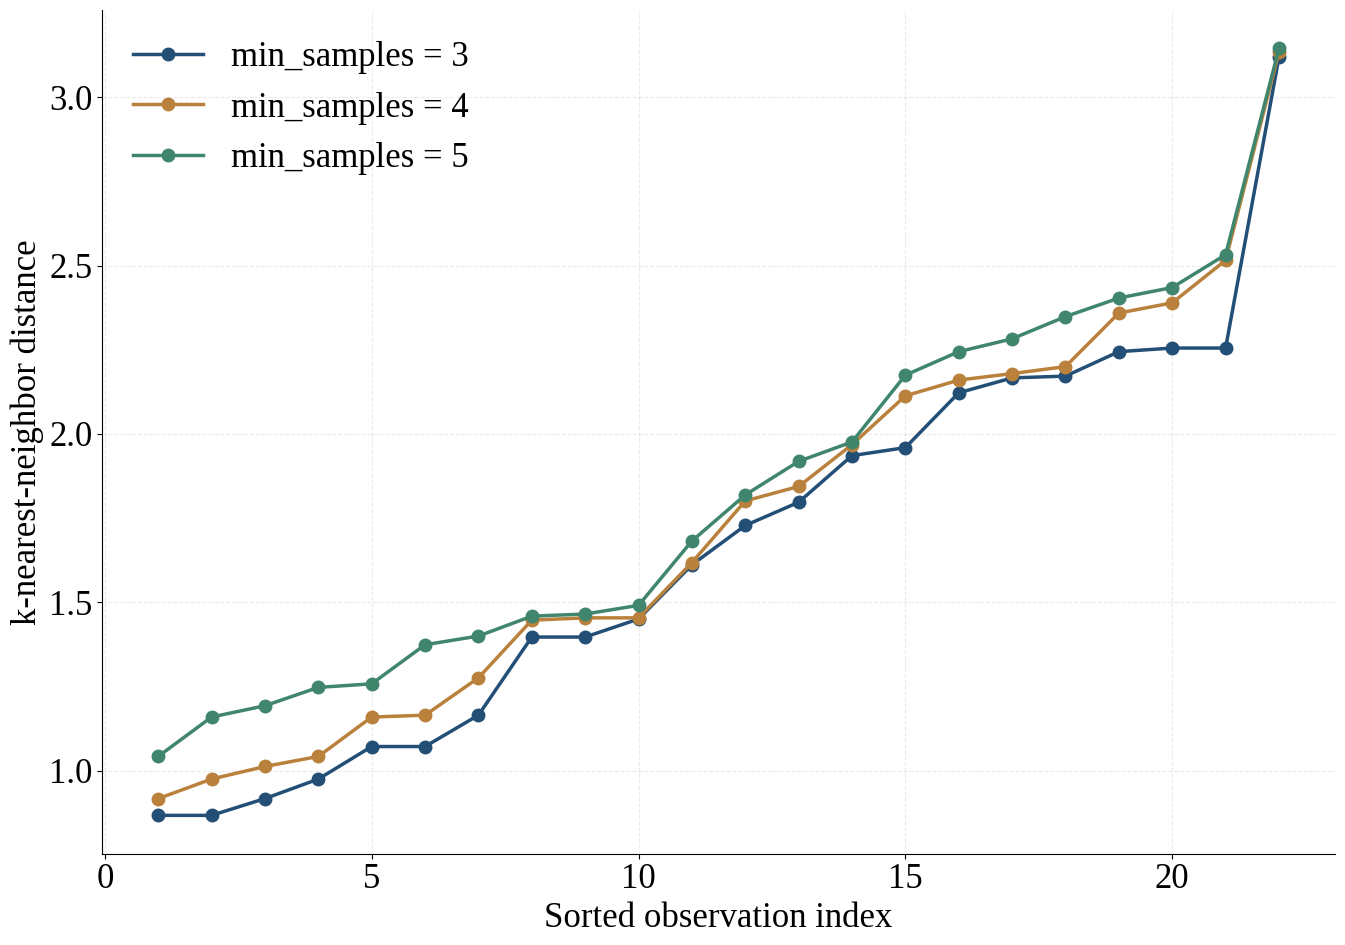

G.2.D — HASIL DBSCAN
Jumlah wilayah: 22
Jumlah fitur: 14
Representasi: Seimbang
min_samples: [3, 4, 5]

A. RINGKASAN SELURUH KONFIGURASI


,min_samples,jumlah_konfigurasi,min_cluster,max_cluster,min_noise,max_noise,konfigurasi_2plus
0,3,18,1,1,0,18,0
1,4,21,1,1,0,18,0
2,5,22,1,1,0,17,0



B. KONFIGURASI YANG DAPAT DIEVALUASI
Jumlah kandidat: 0
Belum ada konfigurasi yang menghasilkan minimal dua cluster dengan Silhouette yang dapat dihitung.

C. JENIS HASIL DBSCAN


,kategori,jumlah_konfigurasi
0,Satu cluster,61



G.2.D SELESAI
Hasil tersimpan: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2/G2D_Hasil_DBSCAN_Seimbang.xlsx
Visualisasi tersimpan: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2

Tidak ada model DBSCAN yang dipilih secara otomatis. Cakupan, noise, struktur cluster dan Silhouette harus diperiksa bersama.


In [ ]:
# ============================================================
# G.2.D — DBSCAN: DENSITY-BASED CLUSTERING
#
# Referensi:
# Ester et al. (1996) — DBSCAN
# Lukito et al. (2026) — Perbandingan clustering
#
# Input       : SEIMBANG_G
# Observasi   : 22 wilayah
# Fitur       : 14
# Jarak       : Euclidean
# min_samples : 3, 4, 5
# eps         : Berdasarkan k-distance
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples
)
from IPython.display import display


# ============================================================
# G.2.D.1 — VALIDASI INPUT
# ============================================================

assert "SEIMBANG_G" in globals(), (
    "SEIMBANG_G tidak ditemukan."
)

X_DBSCAN_G2D = SEIMBANG_G.copy()

assert X_DBSCAN_G2D.shape == (22, 14)
assert X_DBSCAN_G2D.index.is_unique

X = X_DBSCAN_G2D.to_numpy(dtype=float)

assert np.isfinite(X).all()

D = squareform(
    pdist(X, metric="euclidean")
)

assert D.shape == (22, 22)
assert np.allclose(D, D.T)
assert np.allclose(np.diag(D), 0)


# ============================================================
# G.2.D.2 — PARAMETER
# ============================================================

MIN_SAMPLES_G2D = [3, 4, 5]

OUT_G2D = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Pemilihan_Parameter_G2"
)

OUT_G2D.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# G.2.D.3 — K-DISTANCE
# ============================================================

# Setiap baris D memuat jarak terhadap 22 wilayah,
# termasuk jarak nol terhadap wilayah itu sendiri.
D_TERURUT = np.sort(D, axis=1)

HASIL_KDIST_G2D = {}
EPS_KANDIDAT_G2D = {}

for m in MIN_SAMPLES_G2D:

    # Indeks m-1 karena jarak ke diri sendiri = 0.
    kth_distance = D_TERURUT[:, m - 1]

    HASIL_KDIST_G2D[m] = np.sort(
        kth_distance
    )

    # Semua nilai batas yang teramati.
    # nextafter menggeser sedikit ke atas agar
    # titik pada batas eps ikut tercakup.
    EPS_KANDIDAT_G2D[m] = np.nextafter(
        np.unique(kth_distance),
        np.inf
    )


# ============================================================
# G.2.D.4 — VISUALISASI K-DISTANCE
# ============================================================

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "savefig.dpi": 300
})

warna_g2d = {
    3: "#234F77",
    4: "#B9813B",
    5: "#40866D"
}

fig, ax = plt.subplots(
    figsize=(14, 10)
)

for m in MIN_SAMPLES_G2D:

    nilai = HASIL_KDIST_G2D[m]

    ax.plot(
        np.arange(1, len(nilai) + 1),
        nilai,
        marker="o",
        markersize=9,
        linewidth=2.5,
        color=warna_g2d[m],
        label=f"min_samples = {m}"
    )

ax.set_xlabel(
    "Sorted observation index"
)

ax.set_ylabel(
    "k-nearest-neighbor distance"
)

ax.legend(
    frameon=False
)

ax.grid(
    linestyle="--",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUT_G2D / "G2D_DBSCAN_KDistance_Seimbang.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# G.2.D.5 — GRID PARAMETER DBSCAN
# ============================================================

HASIL_LIST_DBSCAN_G2D = []

MODEL_DBSCAN_G2D = {}
LABEL_DBSCAN_G2D = {}

n = X.shape[0]

for m in MIN_SAMPLES_G2D:

    for j, eps in enumerate(
        EPS_KANDIDAT_G2D[m],
        start=1
    ):

        model = DBSCAN(
            eps=float(eps),
            min_samples=m,
            metric="precomputed"
        )

        labels = model.fit_predict(D)

        mask = labels != -1

        n_noise = int(
            np.sum(~mask)
        )

        n_assigned = int(
            np.sum(mask)
        )

        cluster_labels = np.unique(
            labels[mask]
        )

        n_clusters = len(cluster_labels)

        if n_clusters > 0:

            ukuran = np.array([
                np.sum(labels == c)
                for c in cluster_labels
            ])

            ukuran_cluster = ", ".join(
                map(
                    str,
                    sorted(ukuran.tolist())
                )
            )

            ukuran_minimum = int(
                ukuran.min()
            )

            ukuran_maksimum = int(
                ukuran.max()
            )

            singleton = int(
                np.sum(ukuran == 1)
            )

        else:

            ukuran_cluster = "-"
            ukuran_minimum = 0
            ukuran_maksimum = 0
            singleton = 0

        # Silhouette hanya dihitung untuk
        # wilayah yang mendapatkan label cluster.
        #
        # Harus terdapat minimal dua cluster,
        # dengan jumlah cluster lebih kecil
        # daripada jumlah observasi terkelompok.
        if 2 <= n_clusters < n_assigned:

            X_assigned = X[mask]
            label_assigned = labels[mask]

            silhouette = silhouette_score(
                X_assigned,
                label_assigned,
                metric="euclidean"
            )

            sil_individu = silhouette_samples(
                X_assigned,
                label_assigned,
                metric="euclidean"
            )

            n_sil_negatif = int(
                np.sum(sil_individu < 0)
            )

        else:

            silhouette = np.nan
            n_sil_negatif = np.nan

        key = (m, j)

        MODEL_DBSCAN_G2D[key] = model

        LABEL_DBSCAN_G2D[key] = pd.Series(
            labels,
            index=X_DBSCAN_G2D.index,
            name=f"DBSCAN_m{m}_e{j:02d}"
        )

        HASIL_LIST_DBSCAN_G2D.append({
            "min_samples": m,
            "eps_id": j,
            "eps": float(eps),
            "jumlah_cluster": n_clusters,
            "jumlah_noise": n_noise,
            "cakupan_persen": (
                100 * n_assigned / n
            ),
            "jumlah_terkelompok": n_assigned,
            "jumlah_core": len(
                model.core_sample_indices_
            ),
            "ukuran_minimum": ukuran_minimum,
            "ukuran_maksimum": ukuran_maksimum,
            "jumlah_singleton": singleton,
            "ukuran_cluster": ukuran_cluster,
            "Silhouette_non_noise": silhouette,
            "silhouette_negatif_non_noise":
                n_sil_negatif
        })


# ============================================================
# G.2.D.6 — TABEL HASIL
# ============================================================

HASIL_DBSCAN_G2D = pd.DataFrame(
    HASIL_LIST_DBSCAN_G2D
)

print("=" * 70)
print("G.2.D — HASIL DBSCAN")
print("=" * 70)

print("Jumlah wilayah:", n)
print("Jumlah fitur:", X.shape[1])
print("Representasi:", "Seimbang")
print("min_samples:", MIN_SAMPLES_G2D)

print("\nA. RINGKASAN SELURUH KONFIGURASI")

ringkasan_grid = (
    HASIL_DBSCAN_G2D
    .groupby("min_samples")
    .agg(
        jumlah_konfigurasi=("eps", "size"),
        min_cluster=("jumlah_cluster", "min"),
        max_cluster=("jumlah_cluster", "max"),
        min_noise=("jumlah_noise", "min"),
        max_noise=("jumlah_noise", "max"),
        konfigurasi_2plus=(
            "jumlah_cluster",
            lambda s: int((s >= 2).sum())
        )
    )
    .reset_index()
)

display(ringkasan_grid)


# ============================================================
# G.2.D.7 — KONFIGURASI DENGAN >= 2 CLUSTER
# ============================================================

kandidat_dbscan = (
    HASIL_DBSCAN_G2D[
        (HASIL_DBSCAN_G2D["jumlah_cluster"] >= 2)
        & HASIL_DBSCAN_G2D[
            "Silhouette_non_noise"
        ].notna()
    ]
    .copy()
)

print("\nB. KONFIGURASI YANG DAPAT DIEVALUASI")

print(
    "Jumlah kandidat:",
    len(kandidat_dbscan)
)

if not kandidat_dbscan.empty:

    # Peringkat ini hanya untuk memudahkan telaah.
    # Bukan pemilihan model secara otomatis.
    kandidat_dbscan = (
        kandidat_dbscan
        .sort_values(
            [
                "Silhouette_non_noise",
                "cakupan_persen"
            ],
            ascending=[False, False]
        )
    )

    display(
        kandidat_dbscan[
            [
                "min_samples",
                "eps",
                "jumlah_cluster",
                "jumlah_noise",
                "cakupan_persen",
                "ukuran_cluster",
                "Silhouette_non_noise",
                "silhouette_negatif_non_noise"
            ]
        ]
        .head(20)
        .round(5)
    )

else:

    print(
        "Belum ada konfigurasi yang menghasilkan "
        "minimal dua cluster dengan Silhouette "
        "yang dapat dihitung."
    )


# ============================================================
# G.2.D.8 — DISTRIBUSI JENIS HASIL
# ============================================================

def kategori_hasil_dbscan(row):

    if row["jumlah_cluster"] == 0:
        return "Seluruh wilayah noise"

    if row["jumlah_cluster"] == 1:
        return "Satu cluster"

    if row["jumlah_noise"] == 0:
        return ">=2 cluster, tanpa noise"

    return ">=2 cluster, dengan noise"


HASIL_DBSCAN_G2D["kategori_hasil"] = (
    HASIL_DBSCAN_G2D.apply(
        kategori_hasil_dbscan,
        axis=1
    )
)

print("\nC. JENIS HASIL DBSCAN")

display(
    HASIL_DBSCAN_G2D[
        "kategori_hasil"
    ]
    .value_counts()
    .rename_axis("kategori")
    .reset_index(name="jumlah_konfigurasi")
)


# ============================================================
# G.2.D.9 — SIMPAN HASIL
# ============================================================

FILE_DBSCAN_G2D = (
    OUT_G2D / "G2D_Hasil_DBSCAN_Seimbang.xlsx"
)

tabel_label_dbscan = pd.DataFrame(
    LABEL_DBSCAN_G2D,
    index=X_DBSCAN_G2D.index
)

with pd.ExcelWriter(
    FILE_DBSCAN_G2D,
    engine="openpyxl"
) as writer:

    HASIL_DBSCAN_G2D.to_excel(
        writer,
        sheet_name="Seluruh_Grid",
        index=False
    )

    kandidat_dbscan.to_excel(
        writer,
        sheet_name="Kandidat_2plus",
        index=False
    )

    tabel_label_dbscan.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )

print("\n" + "=" * 70)
print("G.2.D SELESAI")
print("=" * 70)

print("Hasil tersimpan:", FILE_DBSCAN_G2D)
print("Visualisasi tersimpan:", OUT_G2D)

print(
    "\nTidak ada model DBSCAN yang dipilih "
    "secara otomatis. Cakupan, noise, "
    "struktur cluster dan Silhouette "
    "harus diperiksa bersama."
)

In [ ]:
# ============================================================
# G.2.D.10 — VERIFIKASI MENYELURUH DBSCAN
#
# Tujuan:
# Memastikan apakah DBSCAN dapat membentuk >= 2 cluster
# pada seluruh perubahan ketetanggaan Euclidean.
#
# Input       : SEIMBANG_G
# min_samples : 3, 4, 5
# eps         : Interval seluruh jarak antarpasangan
#
# Dasar:
# Ester et al. (1996), DBSCAN
# Scikit-learn DBSCAN documentation
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from IPython.display import display


# ------------------------------------------------------------
# 1. VALIDASI DATA
# ------------------------------------------------------------

X_D10 = SEIMBANG_G.to_numpy(dtype=float)

assert X_D10.shape == (22, 14)
assert np.isfinite(X_D10).all()

WILAYAH_D10 = SEIMBANG_G.index

jarak_pasangan = pdist(
    X_D10,
    metric="euclidean"
)

D_D10 = squareform(jarak_pasangan)

assert len(jarak_pasangan) == 231
assert np.allclose(D_D10, D_D10.T)
assert np.allclose(np.diag(D_D10), 0)


# ------------------------------------------------------------
# 2. SUSUN KANDIDAT EPS
# ------------------------------------------------------------

# Semua jarak antarpasangan yang berbeda.
batas_jarak = np.unique(
    jarak_pasangan[jarak_pasangan > 0]
)

assert len(batas_jarak) >= 2

# Nilai eps di antara dua jarak berturutan.
# Dalam interval tersebut, hubungan ketetanggaan
# tidak berubah.
eps_tengah = (
    batas_jarak[:-1]
    + (batas_jarak[1:] - batas_jarak[:-1]) / 2
)

# Sertakan radius:
# - sebelum pasangan pertama terhubung
# - sesudah jarak pasangan terbesar
eps_awal = batas_jarak[0] / 2

eps_akhir = (
    batas_jarak[-1]
    + max(1e-6, batas_jarak[-1] * 0.01)
)

EPS_GRID_D10 = np.concatenate([
    [eps_awal],
    eps_tengah,
    [eps_akhir]
])

assert np.all(np.diff(EPS_GRID_D10) > 0)

print("Jumlah jarak pasangan:", len(jarak_pasangan))
print("Jarak unik:", len(batas_jarak))
print("Kandidat eps:", len(EPS_GRID_D10))
print("Rentang eps:",
      round(EPS_GRID_D10.min(), 5),
      "-",
      round(EPS_GRID_D10.max(), 5))


# ------------------------------------------------------------
# 3. JALANKAN DBSCAN
# ------------------------------------------------------------

MIN_SAMPLES_D10 = [3, 4, 5]

hasil_d10 = []
label_d10 = {}

for m in MIN_SAMPLES_D10:

    for nomor, eps in enumerate(EPS_GRID_D10):

        model = DBSCAN(
            eps=float(eps),
            min_samples=m,
            metric="precomputed"
        )

        labels = model.fit_predict(D_D10)

        mask = labels != -1

        n_noise = int((~mask).sum())
        n_terkelompok = int(mask.sum())

        cluster_id = np.unique(
            labels[mask]
        )

        n_cluster = len(cluster_id)

        ukuran = sorted([
            int(np.sum(labels == c))
            for c in cluster_id
        ])

        if 2 <= n_cluster < n_terkelompok:

            silhouette = silhouette_score(
                X_D10[mask],
                labels[mask],
                metric="euclidean"
            )

        else:

            silhouette = np.nan

        # Kunci untuk menyimpan hasil keanggotaan.
        key = (m, nomor)

        label_d10[key] = labels.copy()

        hasil_d10.append({
            "min_samples": m,
            "eps_id": nomor,
            "eps": float(eps),
            "jumlah_cluster": n_cluster,
            "jumlah_noise": n_noise,
            "cakupan_persen": 100 * n_terkelompok / 22,
            "jumlah_core": len(
                model.core_sample_indices_
            ),
            "ukuran_cluster": ", ".join(map(str, ukuran)),
            "ukuran_minimum": min(ukuran) if ukuran else 0,
            "singleton": sum(u == 1 for u in ukuran),
            "Silhouette_non_noise": silhouette,
            "signature": tuple(labels.tolist())
        })


HASIL_DBSCAN_D10 = pd.DataFrame(hasil_d10)


# ------------------------------------------------------------
# 4. RINGKASAN KESELURUHAN
# ------------------------------------------------------------

print("\nA. HASIL PENCARIAN EPS MENYELURUH")

ringkasan_d10 = (
    HASIL_DBSCAN_D10
    .groupby("min_samples")
    .agg(
        konfigurasi=("eps", "size"),
        jumlah_cluster_min=("jumlah_cluster", "min"),
        jumlah_cluster_max=("jumlah_cluster", "max"),
        noise_min=("jumlah_noise", "min"),
        noise_max=("jumlah_noise", "max"),
        konfigurasi_2plus=(
            "jumlah_cluster",
            lambda x: int((x >= 2).sum())
        ),
        seluruh_noise=(
            "jumlah_cluster",
            lambda x: int((x == 0).sum())
        )
    )
    .reset_index()
)

display(ringkasan_d10)


# ------------------------------------------------------------
# 5. JENIS HASIL
# ------------------------------------------------------------

def kategori_d10(r):

    if r["jumlah_cluster"] == 0:
        return "Seluruh wilayah noise"

    if r["jumlah_cluster"] == 1:
        return "Satu cluster"

    if r["jumlah_noise"] == 0:
        return ">=2 cluster, tanpa noise"

    return ">=2 cluster, dengan noise"


HASIL_DBSCAN_D10["kategori"] = (
    HASIL_DBSCAN_D10.apply(
        kategori_d10,
        axis=1
    )
)

print("\nB. DISTRIBUSI JENIS HASIL")

display(
    HASIL_DBSCAN_D10[
        "kategori"
    ]
    .value_counts()
    .rename_axis("kategori")
    .reset_index(name="jumlah_konfigurasi")
)


# ------------------------------------------------------------
# 6. PERIKSA KANDIDAT >= 2 CLUSTER
# ------------------------------------------------------------

kandidat_d10 = HASIL_DBSCAN_D10[
    HASIL_DBSCAN_D10["jumlah_cluster"] >= 2
].copy()

print("\nC. KANDIDAT DENGAN >= 2 CLUSTER")
print("Jumlah konfigurasi:", len(kandidat_d10))

if not kandidat_d10.empty:

    # Ambil satu konfigurasi untuk setiap pola
    # keanggotaan yang sama.
    kandidat_unik_d10 = (
        kandidat_d10
        .sort_values(
            ["min_samples", "eps"]
        )
        .drop_duplicates(
            subset=["min_samples", "signature"]
        )
        .sort_values(
            [
                "cakupan_persen",
                "Silhouette_non_noise"
            ],
            ascending=[False, False]
        )
    )

    print(
        "Pola keanggotaan berbeda:",
        len(kandidat_unik_d10)
    )

    display(
        kandidat_unik_d10[
            [
                "min_samples",
                "eps",
                "jumlah_cluster",
                "jumlah_noise",
                "cakupan_persen",
                "ukuran_cluster",
                "Silhouette_non_noise"
            ]
        ]
        .head(25)
        .round(5)
    )

else:

    kandidat_unik_d10 = kandidat_d10.copy()

    print(
        "Tidak ditemukan dua atau lebih cluster "
        "pada parameter yang diuji."
    )


# ------------------------------------------------------------
# 7. SIMPAN AUDIT
# ------------------------------------------------------------

OUT_D10 = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Pemilihan_Parameter_G2"
)

OUT_D10.mkdir(
    parents=True,
    exist_ok=True
)

FILE_D10 = (
    OUT_D10
    / "G2D_Verifikasi_Eps_Menyeluruh_DBSCAN.xlsx"
)

# Tuple dipisahkan dari tabel Excel.
tabel_simpan = HASIL_DBSCAN_D10.drop(
    columns="signature"
)

tabel_kandidat = kandidat_unik_d10.drop(
    columns="signature"
)

# Simpan label hanya untuk pola unik kandidat.
label_unik = pd.DataFrame(
    index=WILAYAH_D10
)

for _, row in kandidat_unik_d10.iterrows():

    m = int(row["min_samples"])
    e = int(row["eps_id"])

    label_unik[f"m{m}_eps{e}"] = label_d10[(m, e)]

with pd.ExcelWriter(
    FILE_D10,
    engine="openpyxl"
) as writer:

    ringkasan_d10.to_excel(
        writer,
        sheet_name="Ringkasan",
        index=False
    )

    tabel_simpan.to_excel(
        writer,
        sheet_name="Seluruh_Konfigurasi",
        index=False
    )

    tabel_kandidat.to_excel(
        writer,
        sheet_name="Kandidat_2plus",
        index=False
    )

    label_unik.to_excel(
        writer,
        sheet_name="Keanggotaan_Kandidat"
    )


print("\nVERIFIKASI DBSCAN SELESAI")
print("File:", FILE_D10)

Jumlah jarak pasangan: 231
Jarak unik: 231
Kandidat eps: 232
Rentang eps: 0.37533 - 4.49317

A. HASIL PENCARIAN EPS MENYELURUH


,min_samples,konfigurasi,jumlah_cluster_min,jumlah_cluster_max,noise_min,noise_max,konfigurasi_2plus,seluruh_noise
0,3,232,0,1,0,22,0,4
1,4,232,0,1,0,22,0,5
2,5,232,0,1,0,22,0,8



B. DISTRIBUSI JENIS HASIL


,kategori,jumlah_konfigurasi
0,Satu cluster,679
1,Seluruh wilayah noise,17



C. KANDIDAT DENGAN >= 2 CLUSTER
Jumlah konfigurasi: 0
Tidak ditemukan dua atau lebih cluster pada parameter yang diuji.

VERIFIKASI DBSCAN SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Pemilihan_Parameter_G2/G2D_Verifikasi_Eps_Menyeluruh_DBSCAN.xlsx


# Evaluasi komparatif algoritme clustering

In [ ]:
# ============================================================
# G.3.A — EVALUASI KOMPARATIF CLUSTERING NTT
#
# Acuan:
# Rousseeuw (1987)       — Silhouette
# Calinski & Harabasz    — Variance Ratio Criterion
# Davies & Bouldin (1979)— Cluster Separation
# Lukito et al. (2026)   — Perbandingan clustering
#
# Input         : F6C_Seimbang
# Wilayah       : 22 kabupaten/kota
# Indikator     : 14
# Kandidat      : K-Means, PAM, GMM
# DBSCAN        : Tidak membentuk >= 2 cluster
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    calinski_harabasz_score,
    davies_bouldin_score
)


# ============================================================
# G.3.A.1 — VALIDASI OBJEK
# ============================================================

objek_wajib = [
    "SEIMBANG_G",
    "LABEL_KMEANS_G2A",
    "LABEL_PAM_G2B",
    "LABEL_GMM_G2C"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"Objek {nama} tidak ditemukan."
    )

X_G3 = SEIMBANG_G.copy()

assert X_G3.shape == (22, 14)
assert X_G3.index.is_unique
assert X_G3.columns.is_unique

X = X_G3.to_numpy(dtype=float)

assert np.isfinite(X).all()

WILAYAH_G3 = X_G3.index


# ============================================================
# G.3.A.2 — KANDIDAT MODEL
# ============================================================

KANDIDAT_G3 = {
    "KMeans_k2": LABEL_KMEANS_G2A[2],
    "KMeans_k3": LABEL_KMEANS_G2A[3],

    "PAM_k2": LABEL_PAM_G2B[2],
    "PAM_k3": LABEL_PAM_G2B[3],

    "GMM_diag_k2": LABEL_GMM_G2C[("diag", 2)],
    "GMM_diag_k3": LABEL_GMM_G2C[("diag", 3)]
}

assert len(KANDIDAT_G3) == 6


# ============================================================
# G.3.A.3 — PERHITUNGAN METRIK
# ============================================================

hasil_evaluasi_g3 = []
hasil_per_cluster_g3 = []

KEANGGOTAAN_G3 = pd.DataFrame(
    index=WILAYAH_G3
)

SILHOUETTE_INDIVIDU_G3 = pd.DataFrame(
    index=WILAYAH_G3
)

for nama_model, series_label in KANDIDAT_G3.items():

    assert isinstance(series_label, pd.Series), (
        f"{nama_model}: label harus berupa Series "
        "dengan index kabupaten/kota."
    )

    assert series_label.index.is_unique, (
        f"{nama_model}: index wilayah duplikat."
    )

    # Penyelarasan berdasarkan nama wilayah.
    labels = series_label.reindex(
        WILAYAH_G3
    )

    assert labels.notna().all(), (
        f"{nama_model}: terdapat wilayah "
        "yang tidak memiliki label."
    )

    labels = labels.to_numpy(dtype=int)

    cluster_unik = np.unique(labels)

    jumlah_cluster = len(cluster_unik)

    assert 2 <= jumlah_cluster < len(X), (
        f"{nama_model}: jumlah cluster tidak valid."
    )

    assert not np.any(labels == -1), (
        f"{nama_model}: ditemukan label noise."
    )

    # --------------------------------------------------------
    # SILHOUETTE
    # --------------------------------------------------------

    sil_rata = silhouette_score(
        X,
        labels,
        metric="euclidean"
    )

    sil_individu = silhouette_samples(
        X,
        labels,
        metric="euclidean"
    )

    assert np.isclose(
        sil_rata,
        sil_individu.mean()
    )

    # --------------------------------------------------------
    # CALINSKI-HARABASZ INDEX
    # --------------------------------------------------------

    chi = calinski_harabasz_score(
        X,
        labels
    )

    # --------------------------------------------------------
    # DAVIES-BOULDIN INDEX
    # --------------------------------------------------------

    dbi = davies_bouldin_score(
        X,
        labels
    )

    # --------------------------------------------------------
    # UKURAN CLUSTER
    # --------------------------------------------------------

    ukuran = pd.Series(
        labels
    ).value_counts().sort_index()

    jumlah_singleton = int(
        (ukuran == 1).sum()
    )

    jumlah_sil_negatif = int(
        (sil_individu < 0).sum()
    )

    # --------------------------------------------------------
    # HASIL PER MODEL
    # --------------------------------------------------------

    hasil_evaluasi_g3.append({
        "model": nama_model,
        "jumlah_cluster": jumlah_cluster,
        "jumlah_wilayah": len(X),
        "cakupan_persen": 100.0,
        "Silhouette": sil_rata,
        "CHI": chi,
        "DBI": dbi,
        "ukuran_minimum": int(ukuran.min()),
        "ukuran_maksimum": int(ukuran.max()),
        "jumlah_singleton": jumlah_singleton,
        "silhouette_negatif": jumlah_sil_negatif,
        "ukuran_cluster": ", ".join(
            map(
                str,
                sorted(ukuran.tolist())
            )
        )
    })

    KEANGGOTAAN_G3[nama_model] = labels

    SILHOUETTE_INDIVIDU_G3[nama_model] = (
        sil_individu
    )

    # --------------------------------------------------------
    # HASIL PER CLUSTER
    # --------------------------------------------------------

    for c in cluster_unik:

        posisi = np.where(
            labels == c
        )[0]

        nilai_sil = sil_individu[posisi]

        anggota = [
            str(WILAYAH_G3[i])
            for i in posisi
        ]

        hasil_per_cluster_g3.append({
            "model": nama_model,
            "cluster": int(c),
            "jumlah_wilayah": len(posisi),
            "mean_silhouette": float(
                nilai_sil.mean()
            ),
            "min_silhouette": float(
                nilai_sil.min()
            ),
            "jumlah_silhouette_negatif": int(
                (nilai_sil < 0).sum()
            ),
            "anggota": ", ".join(anggota)
        })


# ============================================================
# G.3.A.4 — TABEL EVALUASI ANTARMODEL
# ============================================================

EVALUASI_MODEL_G3 = pd.DataFrame(
    hasil_evaluasi_g3
)

EVALUASI_CLUSTER_G3 = pd.DataFrame(
    hasil_per_cluster_g3
)

print("=" * 75)
print("G.3.A — EVALUASI KOMPARATIF MODEL")
print("=" * 75)

print("Representasi : Seimbang")
print("Observasi    : 22")
print("Indikator    : 14")
print("Kandidat     :", len(EVALUASI_MODEL_G3))

print("\nA. METRIK VALIDASI INTERNAL")

display(
    EVALUASI_MODEL_G3[
        [
            "model",
            "jumlah_cluster",
            "Silhouette",
            "CHI",
            "DBI",
            "ukuran_cluster",
            "jumlah_singleton",
            "silhouette_negatif"
        ]
    ].round(5)
)


# ============================================================
# G.3.A.5 — KUALITAS SETIAP CLUSTER
# ============================================================

print("\nB. EVALUASI SETIAP CLUSTER")

display(
    EVALUASI_CLUSTER_G3[
        [
            "model",
            "cluster",
            "jumlah_wilayah",
            "mean_silhouette",
            "min_silhouette",
            "jumlah_silhouette_negatif"
        ]
    ].round(5)
)


# ============================================================
# G.3.A.6 — PEMERIKSAAN KONSISTENSI METRIK LAMA
# ============================================================

print("\nC. PEMERIKSAAN NILAI SILHOUETTE TERDAHULU")

sil_referensi = {
    "KMeans_k2": 0.26119,
    "KMeans_k3": 0.25556,
    "PAM_k2": 0.24907,
    "PAM_k3": 0.26384,
    "GMM_diag_k2": 0.26119,
    "GMM_diag_k3": 0.17587
}

for model, nilai_sebelumnya in sil_referensi.items():

    nilai_baru = EVALUASI_MODEL_G3.loc[
        EVALUASI_MODEL_G3["model"] == model,
        "Silhouette"
    ].iloc[0]

    sesuai = np.isclose(
        nilai_baru,
        nilai_sebelumnya,
        atol=1e-4,
        rtol=0
    )

    print(
        f"{model:15s} | "
        f"Sebelumnya={nilai_sebelumnya:.5f} | "
        f"Sekarang={nilai_baru:.5f} | "
        f"Sesuai={sesuai}"
    )

    assert sesuai, (
        f"Nilai Silhouette {model} berbeda "
        "dari hasil G.2."
    )


# ============================================================
# G.3.A.7 — SIMPAN HASIL
# ============================================================

OUT_G3 = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Evaluasi_Komparatif_G3"
)

OUT_G3.mkdir(
    parents=True,
    exist_ok=True
)

EVALUASI_MODEL_G3.to_csv(
    OUT_G3 / "G3A_Evaluasi_Model.csv",
    index=False,
    encoding="utf-8-sig"
)

EVALUASI_CLUSTER_G3.to_csv(
    OUT_G3 / "G3A_Evaluasi_PerCluster.csv",
    index=False,
    encoding="utf-8-sig"
)

KEANGGOTAAN_G3.to_csv(
    OUT_G3 / "G3A_Keanggotaan.csv",
    index_label="kabupaten_kota",
    encoding="utf-8-sig"
)

SILHOUETTE_INDIVIDU_G3.to_csv(
    OUT_G3 / "G3A_Silhouette_Individu.csv",
    index_label="kabupaten_kota",
    encoding="utf-8-sig"
)

print("\n" + "=" * 75)
print("G.3.A SELESAI")
print("=" * 75)

print("Folder hasil:", OUT_G3)
print("Belum ada model terbaik yang ditetapkan.")

G.3.A — EVALUASI KOMPARATIF MODEL
Representasi : Seimbang
Observasi    : 22
Indikator    : 14
Kandidat     : 6

A. METRIK VALIDASI INTERNAL


,model,jumlah_cluster,Silhouette,CHI,DBI,ukuran_cluster,jumlah_singleton,silhouette_negatif
0,KMeans_k2,2,0.26119,5.27249,1.67986,"5, 17",0,3
1,KMeans_k3,3,0.25556,4.86661,1.08089,"1, 4, 17",1,0
2,PAM_k2,2,0.24907,4.49603,1.28200,"3, 19",0,1
3,PAM_k3,3,0.26384,4.60817,0.96414,"1, 3, 18",1,1
4,GMM_diag_k2,2,0.26119,5.27249,1.67986,"5, 17",0,3
5,GMM_diag_k3,3,0.17587,4.42603,1.31426,"1, 6, 15",1,2



B. EVALUASI SETIAP CLUSTER


,model,cluster,jumlah_wilayah,mean_silhouette,min_silhouette,jumlah_silhouette_negatif
0,KMeans_k2,0,17,0.32786,0.22264,0
1,KMeans_k2,1,5,0.03452,-0.08887,3
2,KMeans_k3,0,4,0.15114,0.00476,0
3,KMeans_k3,1,17,0.29517,0.17009,0
4,KMeans_k3,2,1,0.00000,0.00000,0
5,PAM_k2,0,19,0.24910,-0.02179,1
6,PAM_k2,1,3,0.24885,0.10828,0
7,PAM_k3,0,18,0.28299,-0.01048,1
8,PAM_k3,1,3,0.23686,0.08984,0
9,PAM_k3,2,1,0.00000,0.00000,0



C. PEMERIKSAAN NILAI SILHOUETTE TERDAHULU
KMeans_k2       | Sebelumnya=0.26119 | Sekarang=0.26119 | Sesuai=True
KMeans_k3       | Sebelumnya=0.25556 | Sekarang=0.25556 | Sesuai=True
PAM_k2          | Sebelumnya=0.24907 | Sekarang=0.24907 | Sesuai=True
PAM_k3          | Sebelumnya=0.26384 | Sekarang=0.26384 | Sesuai=True
GMM_diag_k2     | Sebelumnya=0.26119 | Sekarang=0.26119 | Sesuai=True
GMM_diag_k3     | Sebelumnya=0.17587 | Sekarang=0.17587 | Sesuai=True

G.3.A SELESAI
Folder hasil: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Evaluasi_Komparatif_G3
Belum ada model terbaik yang ditetapkan.


# Konsistensi keanggotaan antarmodel dengan Adjusted Rand Index (ARI)

G.3.B — KESESUAIAN PARTISI ANTARMODEL

A. MATRIKS ADJUSTED RAND INDEX


,KMeans_k2,KMeans_k3,PAM_k2,PAM_k3,GMM_diag_k2,GMM_diag_k3
KMeans_k2,1.0000,0.9631,0.6002,0.7710,1.0000,0.6326
KMeans_k3,0.9631,1.0000,0.6277,0.8117,0.9631,0.6680
PAM_k2,0.6002,0.6277,1.0000,0.8105,0.6002,0.3641
PAM_k3,0.7710,0.8117,0.8105,1.0000,0.7710,0.5260
GMM_diag_k2,1.0000,0.9631,0.6002,0.7710,1.0000,0.6326
GMM_diag_k3,0.6326,0.6680,0.3641,0.5260,0.6326,1.0000



B. PERBANDINGAN SELURUH PASANGAN MODEL


,model_a,model_b,ARI,partisi_identik
3,KMeans_k2,GMM_diag_k2,1.00000,True
0,KMeans_k2,KMeans_k3,0.96313,False
7,KMeans_k3,GMM_diag_k2,0.96313,False
6,KMeans_k3,PAM_k3,0.81169,False
9,PAM_k2,PAM_k3,0.81050,False
2,KMeans_k2,PAM_k3,0.77100,False
12,PAM_k3,GMM_diag_k2,0.77100,False
8,KMeans_k3,GMM_diag_k3,0.66803,False
14,GMM_diag_k2,GMM_diag_k3,0.63258,False
4,KMeans_k2,GMM_diag_k3,0.63258,False



C. PASANGAN PARTISI IDENTIK


...

PAM_k3,0,1,2
KMeans_k3,,,
0,1,3,0
1,17,0,0
2,0,0,1



------------------------------------------------------------
PAM_k2 vs PAM_k3
ARI = 0.81050


PAM_k3,0,1,2
PAM_k2,,,
0,18,0,1
1,0,3,0



E. KEANGGOTAAN ENAM MODEL


,kabupaten_kota,KMeans_k2,KMeans_k3,PAM_k2,PAM_k3,GMM_diag_k2,GMM_diag_k3
0,Sumba Barat,0,1,0,0,0,0
1,Sumba Timur,0,1,0,0,0,0
2,Kupang,0,1,0,0,0,1
3,Timor Tengah Selatan,0,1,0,0,0,0
4,Timor Tengah Utara,0,1,0,0,0,0
5,Belu,0,1,0,0,0,0
6,Alor,1,0,0,0,1,1
7,Lembata,1,0,1,1,1,1
8,Flores Timur,1,0,1,1,1,1
9,Sikka,0,1,0,0,0,0


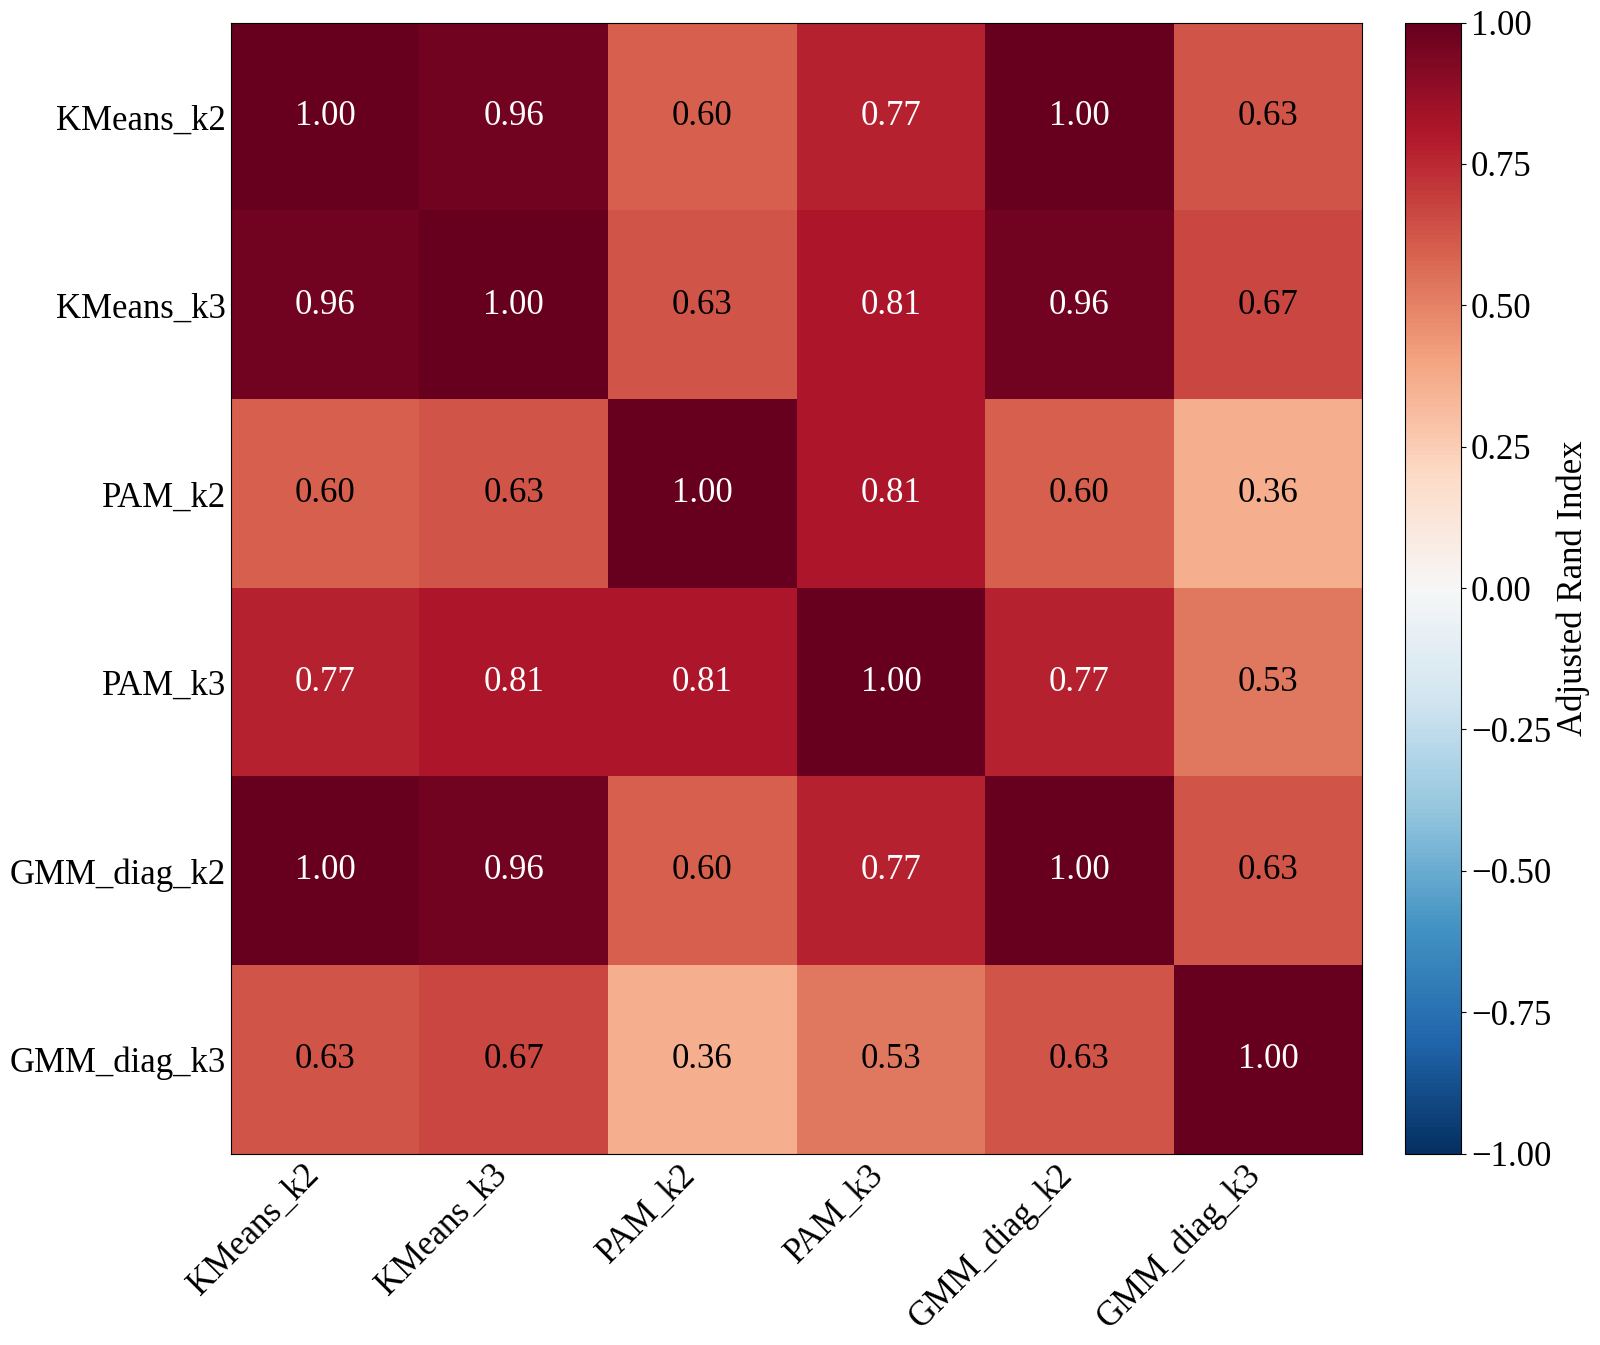


G.3.B SELESAI
File evaluasi: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Evaluasi_Komparatif_G3/G3B_Kesesuaian_Partisi.xlsx
Heatmap tersimpan: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Evaluasi_Komparatif_G3

ARI mengukur kesesuaian antarmodel, bukan kebenaran atau kualitas model.


In [ ]:
# ============================================================
# G.3.B — KESESUAIAN PARTISI ANTARMODEL (ARI)
#
# Referensi:
# Hubert & Arabie (1985) — Adjusted Rand Index
# scikit-learn — adjusted_rand_score
#
# Input:
# KEANGGOTAAN_G3, hasil G.3.A
#
# Tujuan:
# 1. Mengukur kesesuaian enam partisi
# 2. Memeriksa partisi yang identik
# 3. Mengidentifikasi perbedaan keanggotaan wilayah
# 4. Menyusun heatmap ARI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import adjusted_rand_score
from IPython.display import display


# ============================================================
# G.3.B.1 — VALIDASI INPUT
# ============================================================

assert "KEANGGOTAAN_G3" in globals(), (
    "Hasil keanggotaan G.3.A tidak ditemukan."
)

MODEL_G3B = [
    "KMeans_k2",
    "KMeans_k3",
    "PAM_k2",
    "PAM_k3",
    "GMM_diag_k2",
    "GMM_diag_k3"
]

LABEL_G3B = KEANGGOTAAN_G3.copy()

assert LABEL_G3B.shape == (22, 6)

assert LABEL_G3B.index.equals(
    SEIMBANG_G.index
), "Urutan kabupaten/kota berbeda."

assert set(LABEL_G3B.columns) == set(MODEL_G3B)

LABEL_G3B = LABEL_G3B[MODEL_G3B]

assert LABEL_G3B.notna().all().all()

for kolom in LABEL_G3B.columns:

    assert np.all(
        LABEL_G3B[kolom].to_numpy()
        == LABEL_G3B[kolom].to_numpy(dtype=int)
    )

LABEL_G3B = LABEL_G3B.astype(int)


# ============================================================
# G.3.B.2 — MATRIKS ADJUSTED RAND INDEX
# ============================================================

ARI_G3B = pd.DataFrame(
    np.eye(len(MODEL_G3B)),
    index=MODEL_G3B,
    columns=MODEL_G3B
)

hasil_pasangan = []

for i, model_a in enumerate(MODEL_G3B):

    for j, model_b in enumerate(MODEL_G3B):

        if j <= i:
            continue

        nilai_ari = adjusted_rand_score(
            LABEL_G3B[model_a],
            LABEL_G3B[model_b]
        )

        ARI_G3B.loc[model_a, model_b] = nilai_ari
        ARI_G3B.loc[model_b, model_a] = nilai_ari

        hasil_pasangan.append({
            "model_a": model_a,
            "model_b": model_b,
            "ARI": nilai_ari,
            "partisi_identik": np.isclose(
                nilai_ari, 1.0,
                atol=1e-12
            )
        })

PASANGAN_ARI_G3B = pd.DataFrame(
    hasil_pasangan
)

assert np.allclose(
    ARI_G3B.to_numpy(float),
    ARI_G3B.to_numpy(float).T
)

assert np.allclose(
    np.diag(ARI_G3B), 1.0
)

print("=" * 70)
print("G.3.B — KESESUAIAN PARTISI ANTARMODEL")
print("=" * 70)

print("\nA. MATRIKS ADJUSTED RAND INDEX")

display(
    ARI_G3B.round(4)
)


# ============================================================
# G.3.B.3 — PERINGKAT KESESUAIAN ANTARMODEL
# ============================================================

print("\nB. PERBANDINGAN SELURUH PASANGAN MODEL")

display(
    PASANGAN_ARI_G3B
    .sort_values(
        "ARI",
        ascending=False
    )
    .round(5)
)

print("\nC. PASANGAN PARTISI IDENTIK")

partisi_identik = PASANGAN_ARI_G3B[
    PASANGAN_ARI_G3B["partisi_identik"]
]

if partisi_identik.empty:

    print("Tidak ditemukan partisi yang identik.")

else:

    display(partisi_identik)


# ============================================================
# G.3.B.4 — TABEL SILANG KEANGGOTAAN
# ============================================================

pasangan_fokus = [
    ("KMeans_k2", "GMM_diag_k2"),
    ("KMeans_k2", "PAM_k2"),
    ("KMeans_k3", "PAM_k3"),
    ("PAM_k2", "PAM_k3")
]

print("\nD. TABEL SILANG KEANGGOTAAN")

for model_a, model_b in pasangan_fokus:

    nilai_ari = ARI_G3B.loc[
        model_a, model_b
    ]

    print("\n" + "-" * 60)
    print(f"{model_a} vs {model_b}")
    print(f"ARI = {nilai_ari:.5f}")

    display(
        pd.crosstab(
            LABEL_G3B[model_a],
            LABEL_G3B[model_b],
            rownames=[model_a],
            colnames=[model_b]
        )
    )


# ============================================================
# G.3.B.5 — KEANGGOTAAN SELURUH KABUPATEN/KOTA
# ============================================================

print("\nE. KEANGGOTAAN ENAM MODEL")

display(
    LABEL_G3B.reset_index()
)


# ============================================================
# G.3.B.6 — VISUALISASI HEATMAP ARI
# ============================================================

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(
    figsize=(17, 14)
)

nilai = ARI_G3B.to_numpy(float)

im = ax.imshow(
    nilai,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(MODEL_G3B))
)

ax.set_yticks(
    np.arange(len(MODEL_G3B))
)

ax.set_xticklabels(
    MODEL_G3B,
    rotation=45,
    ha="right",
    fontsize=25
)

ax.set_yticklabels(
    MODEL_G3B,
    fontsize=25
)

# Angka ARI ditampilkan pada setiap sel.
for i in range(len(MODEL_G3B)):

    for j in range(len(MODEL_G3B)):

        v = nilai[i, j]

        warna_teks = (
            "white"
            if abs(v) >= 0.7
            else "black"
        )

        ax.text(
            j, i,
            f"{v:.2f}",
            ha="center",
            va="center",
            fontsize=25,
            color=warna_teks
        )

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

cbar.set_label(
    "Adjusted Rand Index",
    fontsize=25
)

cbar.ax.tick_params(
    labelsize=25
)

ax.tick_params(
    length=0
)

fig.tight_layout()


# ============================================================
# G.3.B.7 — SIMPAN OUTPUT
# ============================================================

OUT_G3B = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Evaluasi_Komparatif_G3"
)

OUT_G3B.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    OUT_G3B / "G3B_Heatmap_ARI_Antarmodel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

FILE_ARI_G3B = (
    OUT_G3B / "G3B_Kesesuaian_Partisi.xlsx"
)

with pd.ExcelWriter(
    FILE_ARI_G3B,
    engine="openpyxl"
) as writer:

    ARI_G3B.to_excel(
        writer,
        sheet_name="Matriks_ARI"
    )

    PASANGAN_ARI_G3B.to_excel(
        writer,
        sheet_name="Pasangan_Model",
        index=False
    )

    LABEL_G3B.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )

print("\n" + "=" * 70)
print("G.3.B SELESAI")
print("=" * 70)

print("File evaluasi:", FILE_ARI_G3B)
print("Heatmap tersimpan:", OUT_G3B)

print(
    "\nARI mengukur kesesuaian antarmodel, "
    "bukan kebenaran atau kualitas model."
)

## Tiga grafik komparatif

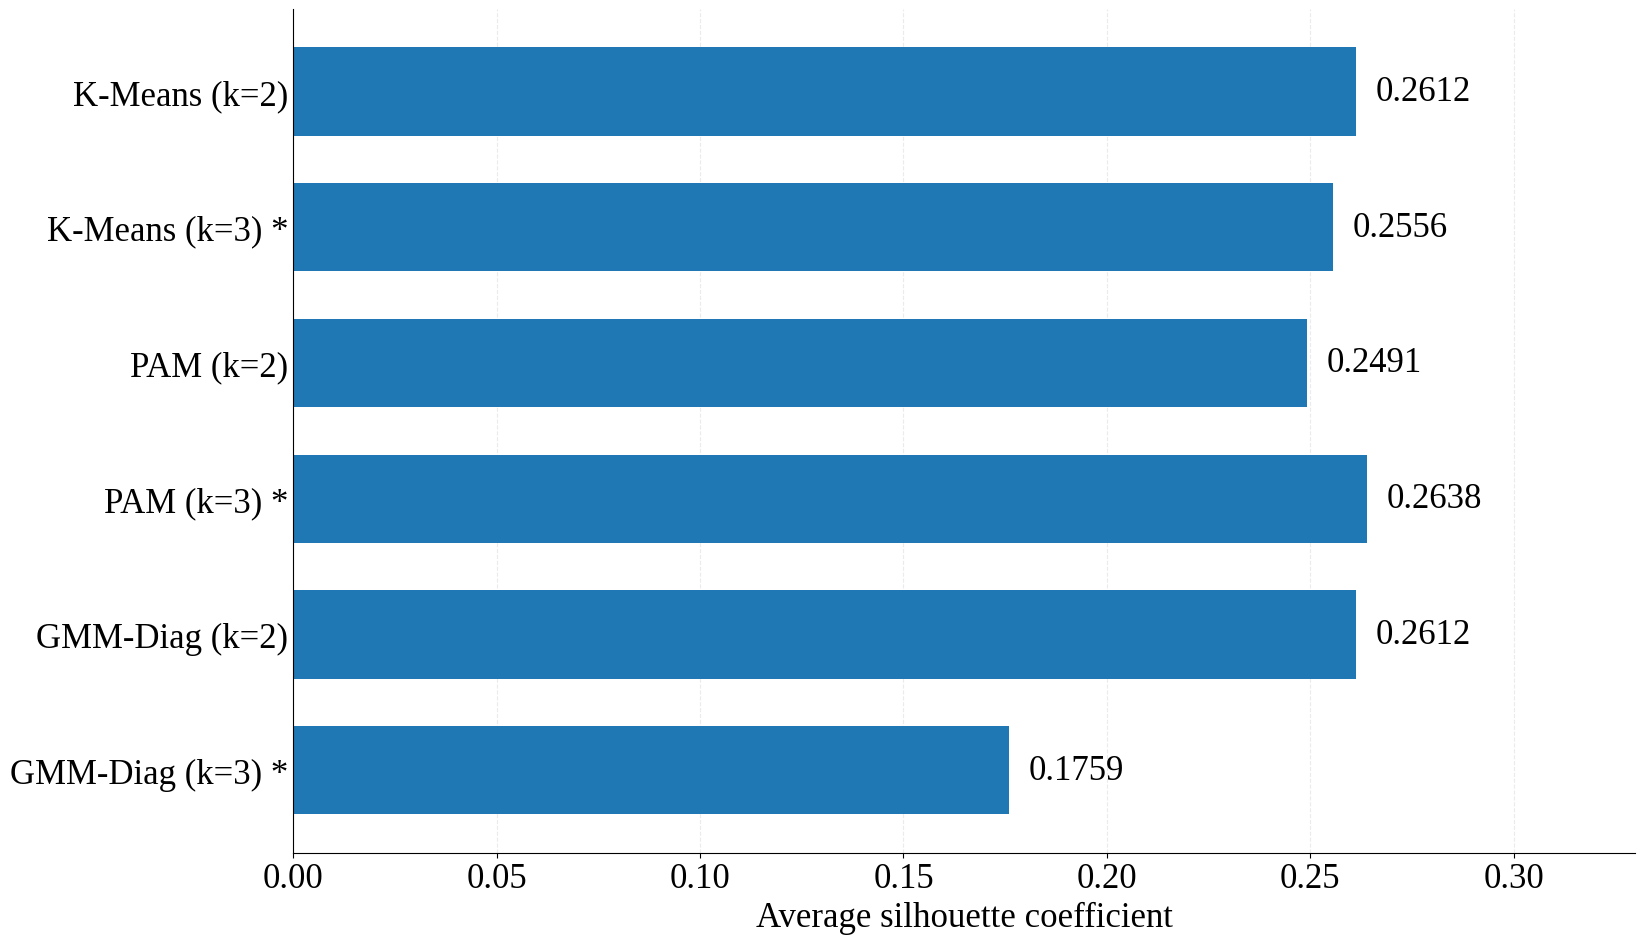

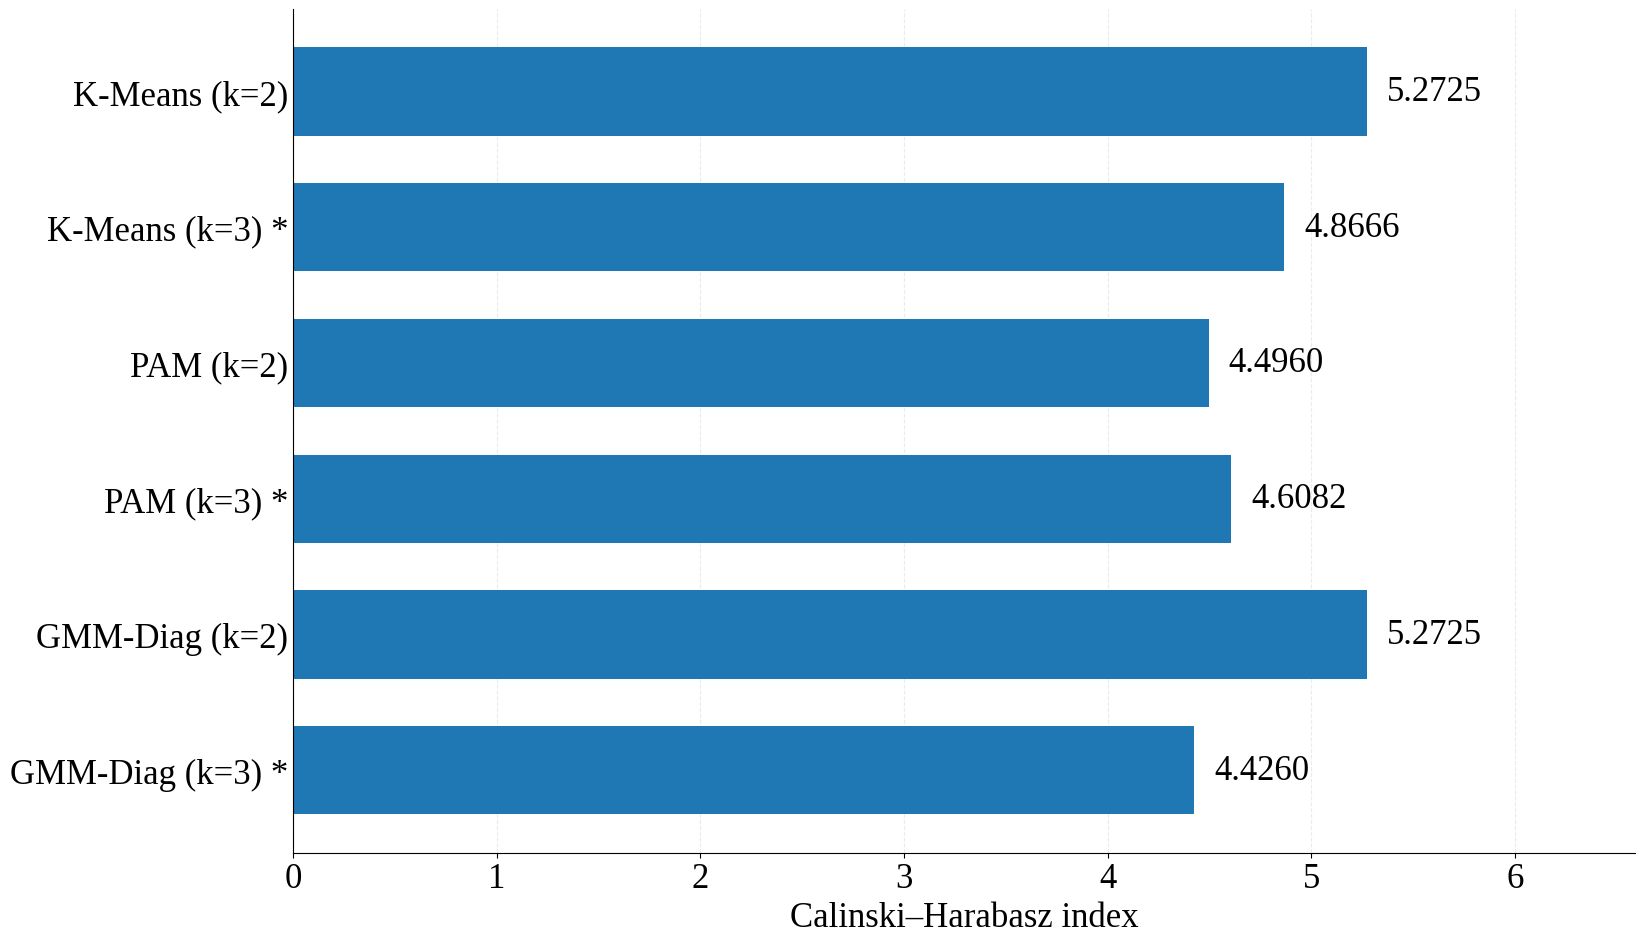

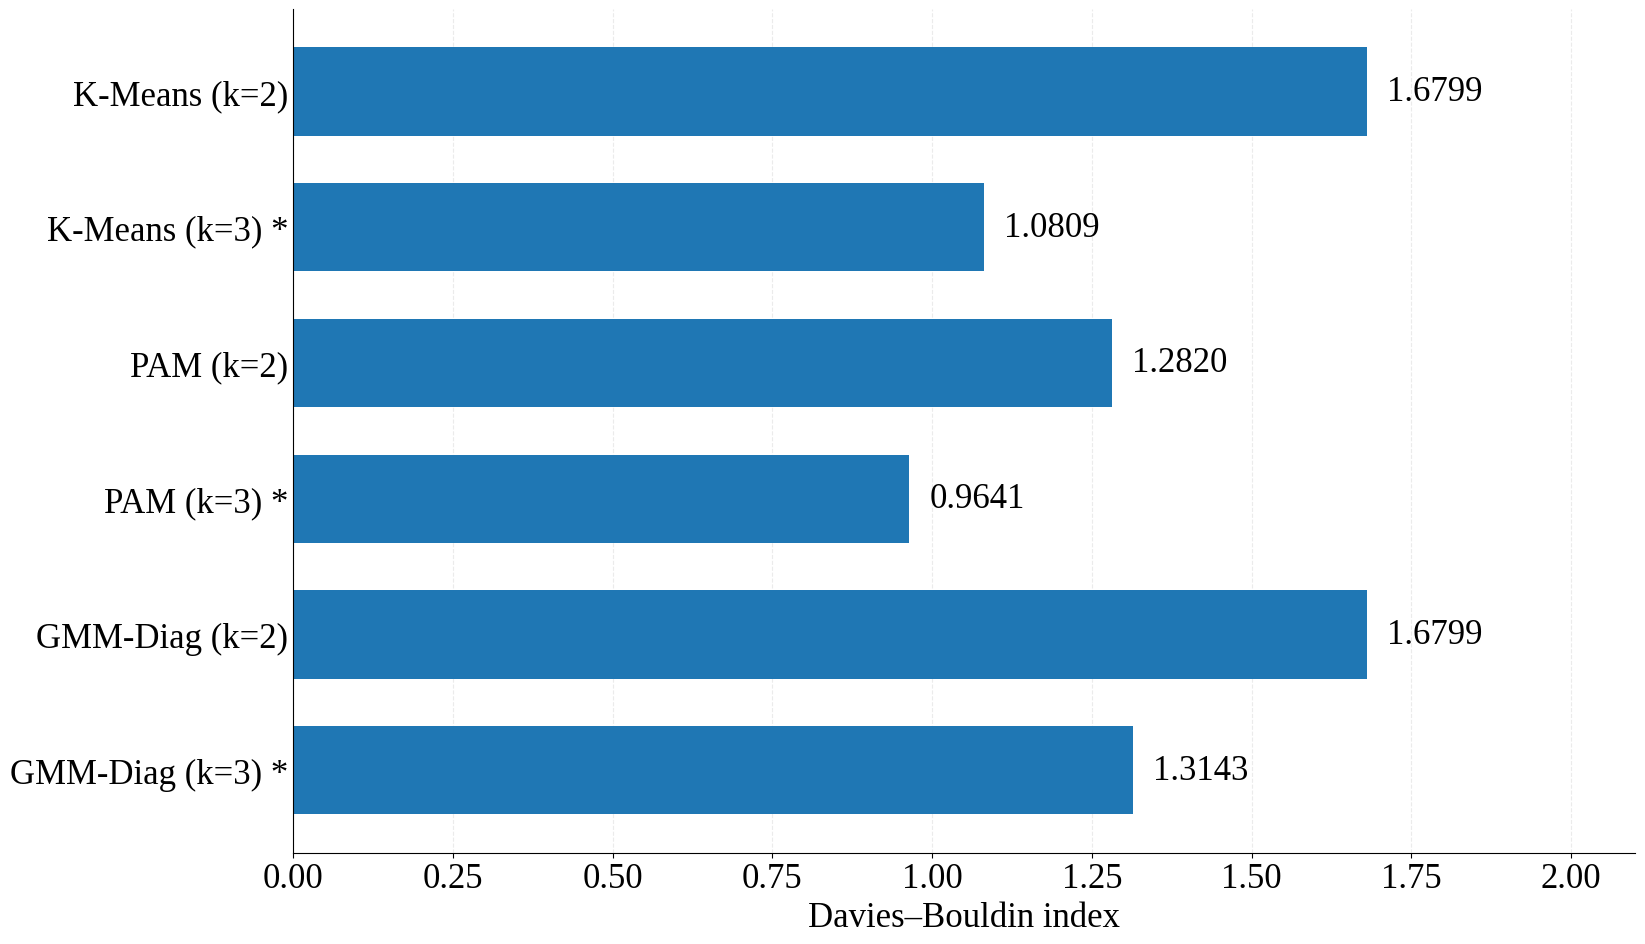


G.3.C SELESAI
Lokasi grafik: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Evaluasi_Komparatif_G3
* Menunjukkan konfigurasi dengan singleton.
Semua grafik tanpa judul, fontsize 25, 300 DPI.


In [ ]:
# ============================================================
# G.3.C — VISUALISASI KOMPARATIF MODEL CLUSTERING
#
# Dasar evaluasi:
# Rousseeuw (1987)          — Silhouette
# Calinski & Harabasz (1974) — CHI
# Davies & Bouldin (1979)  — DBI
#
# Input: EVALUASI_MODEL_G3
# Output: 3 grafik PNG, 300 DPI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ------------------------------------------------------------
# 1. VALIDASI INPUT
# ------------------------------------------------------------

assert "EVALUASI_MODEL_G3" in globals(), (
    "Hasil G.3.A tidak tersedia."
)

df_plot = EVALUASI_MODEL_G3.copy()

urutan_model = [
    "KMeans_k2",
    "KMeans_k3",
    "PAM_k2",
    "PAM_k3",
    "GMM_diag_k2",
    "GMM_diag_k3"
]

assert set(df_plot["model"]) == set(urutan_model)
assert df_plot["model"].is_unique

df_plot = (
    df_plot
    .set_index("model")
    .loc[urutan_model]
    .reset_index()
)

for metrik in ["Silhouette", "CHI", "DBI"]:
    assert np.isfinite(
        df_plot[metrik].to_numpy(float)
    ).all()

# Nama yang digunakan pada sumbu grafik.
label_model = {
    "KMeans_k2": "K-Means (k=2)",
    "KMeans_k3": "K-Means (k=3)",
    "PAM_k2": "PAM (k=2)",
    "PAM_k3": "PAM (k=3)",
    "GMM_diag_k2": "GMM-Diag (k=2)",
    "GMM_diag_k3": "GMM-Diag (k=3)"
}

df_plot["label_grafik"] = [
    label_model[m] + (
        " *" if n > 0 else ""
    )
    for m, n in zip(
        df_plot["model"],
        df_plot["jumlah_singleton"]
    )
]

# ------------------------------------------------------------
# 2. FOLDER OUTPUT
# ------------------------------------------------------------

OUT_G3C = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Evaluasi_Komparatif_G3"
)

OUT_G3C.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. FORMAT VISUALISASI
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ------------------------------------------------------------
# 4. FUNGSI GRAFIK
# ------------------------------------------------------------

def plot_metrik_g3c(
    data,
    kolom,
    label_sumbu,
    nama_file
):

    nilai = data[kolom].to_numpy(float)
    posisi = np.arange(len(data))

    fig, ax = plt.subplots(
        figsize=(17, 10)
    )

    batang = ax.barh(
        posisi,
        nilai,
        height=0.65
    )

    ax.set_yticks(posisi)
    ax.set_yticklabels(
        data["label_grafik"]
    )

    ax.invert_yaxis()

    ax.set_xlabel(label_sumbu)

    # Semua nilai positif; sumbu mulai dari nol.
    batas = float(np.max(nilai)) * 1.25
    ax.set_xlim(0, batas)

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="y",
        length=0
    )

    # Label nilai dengan 4 angka desimal.
    for bar, angka in zip(batang, nilai):

        ax.text(
            bar.get_width() + batas * 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{angka:.4f}",
            va="center",
            ha="left",
            fontsize=25
        )

    fig.tight_layout()

    fig.savefig(
        OUT_G3C / nama_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ------------------------------------------------------------
# 5. SILHOUETTE
# ------------------------------------------------------------

plot_metrik_g3c(
    data=df_plot,
    kolom="Silhouette",
    label_sumbu="Average silhouette coefficient",
    nama_file="G3C_Perbandingan_Silhouette.png"
)


# ------------------------------------------------------------
# 6. CALINSKI-HARABASZ INDEX
# ------------------------------------------------------------

plot_metrik_g3c(
    data=df_plot,
    kolom="CHI",
    label_sumbu="Calinski–Harabasz index",
    nama_file="G3C_Perbandingan_CHI.png"
)


# ------------------------------------------------------------
# 7. DAVIES-BOULDIN INDEX
# ------------------------------------------------------------

plot_metrik_g3c(
    data=df_plot,
    kolom="DBI",
    label_sumbu="Davies–Bouldin index",
    nama_file="G3C_Perbandingan_DBI.png"
)


print("\nG.3.C SELESAI")
print("Lokasi grafik:", OUT_G3C)
print("* Menunjukkan konfigurasi dengan singleton.")
print("Semua grafik tanpa judul, fontsize 25, 300 DPI.")

# Persiapan analisis sensitivitas

## Sensitivitas skenario BNPB: S1 (2021–2025), S2 (2022–2025), dan S3 (2021–2025 dengan log1p).

### Validasi baseline dan pembentukan skenario

In [ ]:
# ============================================================
# G.4 — PEMBENTUKAN SKENARIO SENSITIVITAS CLUSTERING
#
# S1 : BNPB 2021–2025 (baseline)
# S2 : BNPB 2022–2025
# S3 : log1p indikator BNPB 2021–2025
#
# Dasar:
# - Preprocessing penelitian, Bagian F
# - Rogel-Salazar (2017), Bab 4.5–4.6
# - McKinney (2022), pengolahan data Pandas
#
# Tidak mengubah master maupun F6C asli.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from IPython.display import display


# ============================================================
# G.4.1 — VALIDASI INPUT
# ============================================================

for nama in ["INTI_G", "STANDAR_G", "SEIMBANG_G"]:
    assert nama in globals(), (
        f"Objek {nama} belum tersedia. "
        "Jalankan G.0 terlebih dahulu."
    )

assert INTI_G.shape == (22, 14)
assert STANDAR_G.shape == (22, 14)
assert SEIMBANG_G.shape == (22, 14)

assert INTI_G.index.equals(STANDAR_G.index)
assert INTI_G.index.equals(SEIMBANG_G.index)

assert INTI_G.columns.equals(STANDAR_G.columns)
assert INTI_G.columns.equals(SEIMBANG_G.columns)


ROOT_G4 = Path(
    "/content/drive/MyDrive/NTT_Disaster_Analysis data"
)

FILE_MASTER_G4 = (
    ROOT_G4 / "Master_Dataset_Kebencanaan_NTT_Artikel1.xlsx"
)

OUT_G4 = (
    ROOT_G4 / "Hasil_G_Artikel1_Baru" / "Sensitivitas_G4"
)

assert FILE_MASTER_G4.is_file()

OUT_G4.mkdir(parents=True, exist_ok=True)


# ============================================================
# G.4.2 — BACA MASTER DATASET
# ============================================================

master_g4 = pd.read_excel(
    FILE_MASTER_G4,
    sheet_name="Master_NTT"
)

assert "kabupaten_kota" in master_g4.columns

master_g4["kabupaten_kota"] = (
    master_g4["kabupaten_kota"]
    .astype(str)
    .str.strip()
)

assert master_g4["kabupaten_kota"].is_unique

master_g4 = master_g4.set_index("kabupaten_kota")

# Validasi himpunan kabupaten/kota.
assert set(master_g4.index) == set(INTI_G.index), (
    "Daftar wilayah master berbeda dari F.6.C."
)

# Selaraskan berdasarkan nama, bukan posisi.
master_g4 = master_g4.loc[INTI_G.index].copy()

assert master_g4.index.equals(INTI_G.index)

print("=" * 70)
print("G.4 — PEMERIKSAAN SUMBER")
print("=" * 70)

print("Master dataset:", master_g4.shape)
print("Matriks F6C:", INTI_G.shape)


# ============================================================
# G.4.3 — TETAPKAN EMPAT INDIKATOR BNPB
# ============================================================

BNPB_MAP_G4 = {
    "laporan_per100rb_2021_2025":
        "baris_laporan_raw",

    "meninggal_per100rb_2021_2025":
        "meninggal_jumlah_raw",

    "luka_per100rb_2021_2025":
        "luka_jumlah_raw",

    "pengungsi_per100rb_2021_2025":
        "pengungsi_jumlah_raw"
}

FITUR_BNPB_G4 = list(BNPB_MAP_G4)

assert all(
    kolom in INTI_G.columns
    for kolom in FITUR_BNPB_G4
)

KOLOM_POP_G4 = "bps_penduduk_2025_ribu"

assert KOLOM_POP_G4 in master_g4.columns


# ============================================================
# G.4.4 — VALIDASI PENDUDUK DAN DATA TAHUNAN
# ============================================================

pop_ribu_g4 = pd.to_numeric(
    master_g4[KOLOM_POP_G4],
    errors="coerce"
)

assert pop_ribu_g4.notna().all(), (
    "Terdapat data penduduk yang tidak numerik/kosong."
)

assert (pop_ribu_g4 > 0).all(), (
    "Penyebut jumlah penduduk harus positif."
)

# Konversi dari ribu jiwa menjadi jiwa.
pop_jiwa_g4 = pop_ribu_g4 * 1000

TAHUN_G4 = list(range(2021, 2026))

kolom_tahunan_g4 = [
    f"bencana_{tahun}_{jenis}"
    for tahun in TAHUN_G4
    for jenis in BNPB_MAP_G4.values()
]

kolom_tidak_ada = [
    c for c in kolom_tahunan_g4
    if c not in master_g4.columns
]

assert not kolom_tidak_ada, (
    f"Kolom BNPB tidak ditemukan: {kolom_tidak_ada}"
)

RAW_BNPB_G4 = master_g4[
    kolom_tahunan_g4
].apply(
    pd.to_numeric,
    errors="coerce"
)

if RAW_BNPB_G4.isna().any().any():

    lokasi_missing = (
        RAW_BNPB_G4
        .stack(dropna=False)
        .loc[lambda s: s.isna()]
    )

    print("\nDATA BNPB KOSONG / TIDAK NUMERIK:")
    display(lokasi_missing.head(20))

    raise ValueError(
        "Data BNPB belum lengkap secara numerik. "
        "Periksa sumber sebelum membentuk skenario."
    )

assert (RAW_BNPB_G4 >= 0).all().all(), (
    "Terdapat nilai negatif pada data BNPB."
)


# ============================================================
# G.4.5 — FUNGSI RERATA TAHUNAN PER 100.000
# ============================================================

def hitung_bnpb_per100rb_g4(tahun_digunakan):
    """
    Rumus:

    indikator = (jumlah selama T tahun / T)
                / penduduk_2025
                * 100000

    Penyebut penduduk tetap menggunakan
    jumlah penduduk tahun 2025.
    """

    tahun_digunakan = list(tahun_digunakan)

    jumlah_tahun = len(tahun_digunakan)

    assert jumlah_tahun > 0

    hasil = pd.DataFrame(
        index=INTI_G.index
    )

    for nama_fitur, jenis in BNPB_MAP_G4.items():

        kolom = [
            f"bencana_{tahun}_{jenis}"
            for tahun in tahun_digunakan
        ]

        jumlah = RAW_BNPB_G4[kolom].sum(axis=1)

        rata_rata_tahunan = (
            jumlah / jumlah_tahun
        )

        hasil[nama_fitur] = (
            rata_rata_tahunan
            / pop_jiwa_g4
            * 100000
        )

    return hasil[FITUR_BNPB_G4]


# ============================================================
# G.4.6 — REPRODUKSI S1 DAN VALIDASI TERHADAP F6C
# ============================================================

BNPB_S1_HITUNG_G4 = hitung_bnpb_per100rb_g4(
    range(2021, 2026)
)

BNPB_S1_F6C_G4 = INTI_G[
    FITUR_BNPB_G4
].copy()

selisih_s1 = (
    BNPB_S1_HITUNG_G4
    - BNPB_S1_F6C_G4
)

TOLERANSI_G4 = 1e-5

verifikasi_s1_g4 = pd.DataFrame(
    [
        {
            "indikator": fitur,
            "selisih_maksimum": float(
                selisih_s1[fitur].abs().max()
            ),
            "sesuai": bool(
                np.allclose(
                    BNPB_S1_HITUNG_G4[fitur],
                    BNPB_S1_F6C_G4[fitur],
                    atol=TOLERANSI_G4,
                    rtol=1e-8
                )
            )
        }
        for fitur in FITUR_BNPB_G4
    ]
)

print("\nA. VERIFIKASI REPRODUKSI S1")
display(verifikasi_s1_g4.round(8))

if not verifikasi_s1_g4["sesuai"].all():

    print("\nRINCIAN PERBEDAAN TERBESAR:")

    detail_selisih = (
        selisih_s1.abs()
        .stack()
        .sort_values(ascending=False)
        .head(15)
        .reset_index()
    )

    detail_selisih.columns = [
        "kabupaten_kota",
        "indikator",
        "selisih_absolut"
    ]

    display(detail_selisih)

    raise ValueError(
        "Rumus BNPB yang direproduksi belum "
        "sesuai dengan F.6.C. "
        "Pembentukan S2 dan S3 dihentikan. "
        "Periksa rumus Bagian F terlebih dahulu."
    )

print(
    "\nReproduksi BNPB S1 sesuai matriks F.6.C."
)


# ============================================================
# G.4.7 — BENTUK S1, S2, DAN S3
# ============================================================

# S1 adalah matriks final F.6.C.
S1_INTI_G4 = INTI_G.copy()

# S2: BNPB 2022–2025.
S2_INTI_G4 = INTI_G.copy()

BNPB_S2_G4 = hitung_bnpb_per100rb_g4(
    range(2022, 2026)
)

S2_INTI_G4.loc[
    :, FITUR_BNPB_G4
] = BNPB_S2_G4.to_numpy(dtype=float)


# S3: log1p pada empat indikator BNPB per 100.000.
# Transformasi dilakukan setelah pembentukan rasio,
# bukan pada jumlah kejadian mentah.
S3_INTI_G4 = INTI_G.copy()

assert (
    S3_INTI_G4[FITUR_BNPB_G4] >= 0
).all().all()

S3_INTI_G4.loc[
    :, FITUR_BNPB_G4
] = np.log1p(
    INTI_G[FITUR_BNPB_G4].to_numpy(dtype=float)
)


# ============================================================
# G.4.8 — NAMA FITUR KONSISTEN ANTARSKENARIO
# ============================================================

# Nama kolom BNPB disederhanakan pada salinan
# skenario supaya akhiran "2021_2025" tidak
# menyesatkan ketika digunakan untuk S2.
#
# Informasi periode disimpan pada metadata.
# Nama dan nilai file F6C asli tidak diubah.

NAMA_GENERIK_BNPB_G4 = {
    nama: nama.replace("_2021_2025", "")
    for nama in FITUR_BNPB_G4
}

SKENARIO_INTI_G4 = {
    "S1": S1_INTI_G4.rename(
        columns=NAMA_GENERIK_BNPB_G4
    ),
    "S2": S2_INTI_G4.rename(
        columns=NAMA_GENERIK_BNPB_G4
    ),
    "S3": S3_INTI_G4.rename(
        columns=NAMA_GENERIK_BNPB_G4
    )
}


# ============================================================
# G.4.9 — STANDARDISASI DAN PENYEIMBANGAN
# ============================================================

# Tetapkan kelompok menurut nama indikator,
# bukan hasil seleksi atau urutan yang berubah.
FITUR_BPS_G4 = list(INTI_G.columns[:3])

FITUR_BNPB_GENERIK_G4 = [
    NAMA_GENERIK_BNPB_G4[f]
    for f in FITUR_BNPB_G4
]

FITUR_KRB_G4 = list(INTI_G.columns[7:14])

KELOMPOK_G4 = {
    "BPS": FITUR_BPS_G4,
    "BNPB": FITUR_BNPB_GENERIK_G4,
    "KRB": FITUR_KRB_G4
}

FITUR_TETAP_G4 = (
    FITUR_BPS_G4
    + FITUR_BNPB_GENERIK_G4
    + FITUR_KRB_G4
)

assert len(FITUR_TETAP_G4) == 14
assert len(set(FITUR_TETAP_G4)) == 14


def bentuk_representasi_g4(df_inti):

    assert df_inti.shape == (22, 14)

    df_inti = df_inti.loc[
        INTI_G.index,
        FITUR_TETAP_G4
    ].copy()

    assert np.isfinite(
        df_inti.to_numpy(dtype=float)
    ).all()

    # StandardScaler menggunakan ddof=0.
    scaler = StandardScaler()

    nilai_z = scaler.fit_transform(
        df_inti.to_numpy(dtype=float)
    )

    assert np.all(scaler.scale_ > 0), (
        "Ada fitur dengan simpangan baku nol."
    )

    df_z = pd.DataFrame(
        nilai_z,
        index=df_inti.index,
        columns=df_inti.columns
    )

    # Pembobotan seimbang per kelompok.
    df_seimbang = df_z.copy()

    for kelompok, fitur in KELOMPOK_G4.items():

        bobot = 1 / np.sqrt(len(fitur))

        df_seimbang.loc[:, fitur] = (
            df_z[fitur] * bobot
        )

    return {
        "Inti": df_inti,
        "Standar": df_z,
        "Seimbang": df_seimbang
    }


SKENARIO_G4 = {
    nama: bentuk_representasi_g4(df)
    for nama, df in SKENARIO_INTI_G4.items()
}


# ============================================================
# G.4.10 — VALIDASI ULANG BASELINE S1
# ============================================================

# Nama generik tidak mengubah posisi atau nilai kolom.
assert np.allclose(
    SKENARIO_G4["S1"]["Inti"].to_numpy(float),
    INTI_G.to_numpy(float),
    rtol=1e-9,
    atol=1e-8
)

assert np.allclose(
    SKENARIO_G4["S1"]["Standar"].to_numpy(float),
    STANDAR_G.to_numpy(float),
    rtol=1e-9,
    atol=1e-7
), (
    "Reproduksi standardisasi S1 berbeda dari F6C."
)

assert np.allclose(
    SKENARIO_G4["S1"]["Seimbang"].to_numpy(float),
    SEIMBANG_G.to_numpy(float),
    rtol=1e-9,
    atol=1e-7
), (
    "Reproduksi pembobotan S1 berbeda dari F6C."
)

# BPS dan KRB pada seluruh skenario harus identik.
fitur_tidak_berubah = (
    FITUR_BPS_G4 + FITUR_KRB_G4
)

for nama in ["S2", "S3"]:

    assert np.array_equal(
        SKENARIO_G4[nama]["Inti"][
            fitur_tidak_berubah
        ].to_numpy(),
        SKENARIO_G4["S1"]["Inti"][
            fitur_tidak_berubah
        ].to_numpy()
    ), (
        f"{nama}: indikator BPS/KRB berubah."
    )

print("\nB. VALIDASI BASELINE")
print("S1 Inti      : sesuai F6C")
print("S1 Standar   : sesuai F6C")
print("S1 Seimbang  : sesuai F6C")
print("BPS dan KRB  : tidak berubah pada S2/S3")


# ============================================================
# G.4.11 — RINGKASAN SKENARIO
# ============================================================

ringkasan_g4 = []

for nama, paket in SKENARIO_G4.items():

    inti = paket["Inti"]
    z = paket["Standar"]
    seimbang = paket["Seimbang"]

    ringkasan_g4.append({
        "skenario": nama,
        "observasi": inti.shape[0],
        "indikator": inti.shape[1],
        "missing": int(
            inti.isna().sum().sum()
        ),
        "mean_z_maks_absolut": float(
            z.mean().abs().max()
        ),
        "deviasi_sd_z_dari_1": float(
            (z.std(ddof=0) - 1).abs().max()
        ),
        "norma_seimbang_rata_rata": float(
            np.linalg.norm(
                seimbang.to_numpy(float),
                axis=1
            ).mean()
        )
    })

RINGKASAN_G4 = pd.DataFrame(
    ringkasan_g4
)

print("\nC. RINGKASAN KETIGA SKENARIO")
display(RINGKASAN_G4.round(7))


# ============================================================
# G.4.12 — PERUBAHAN NILAI BNPB ANTARSKENARIO
# ============================================================

# Bandingkan pada skala z-score, agar S3 yang
# menggunakan log tidak dibandingkan langsung
# dengan nilai rasio asli.

perubahan_g4 = []

for nama in ["S2", "S3"]:

    perubahan_z = (
        SKENARIO_G4[nama]["Standar"][
            FITUR_BNPB_GENERIK_G4
        ]
        -
        SKENARIO_G4["S1"]["Standar"][
            FITUR_BNPB_GENERIK_G4
        ]
    )

    for fitur in FITUR_BNPB_GENERIK_G4:

        perubahan_g4.append({
            "perbandingan": f"S1 vs {nama}",
            "indikator": fitur,
            "mean_abs_perubahan_z": float(
                perubahan_z[fitur].abs().mean()
            ),
            "max_abs_perubahan_z": float(
                perubahan_z[fitur].abs().max()
            ),
            "wilayah_perubahan_terbesar":
                perubahan_z[fitur].abs().idxmax()
        })

PERUBAHAN_BNPB_G4 = pd.DataFrame(
    perubahan_g4
)

print("\nD. PERUBAHAN STANDARDISASI INDIKATOR BNPB")

display(
    PERUBAHAN_BNPB_G4.round(5)
)


# ============================================================
# G.4.13 — METADATA SKENARIO
# ============================================================

METADATA_G4 = pd.DataFrame([
    {
        "skenario": "S1",
        "periode_BNPB": "2021–2025",
        "jumlah_tahun": 5,
        "transformasi_BNPB": "Tidak",
        "populasi_penyebut": "Penduduk 2025",
        "status": "Baseline F6C"
    },
    {
        "skenario": "S2",
        "periode_BNPB": "2022–2025",
        "jumlah_tahun": 4,
        "transformasi_BNPB": "Tidak",
        "populasi_penyebut": "Penduduk 2025",
        "status": "Sensitivitas periode"
    },
    {
        "skenario": "S3",
        "periode_BNPB": "2021–2025",
        "jumlah_tahun": 5,
        "transformasi_BNPB": "log1p pada rasio per 100rb",
        "populasi_penyebut": "Penduduk 2025",
        "status": "Sensitivitas transformasi"
    }
])


# ============================================================
# G.4.14 — SIMPAN MATRIKS SKENARIO
# ============================================================

FILE_HASIL_G4 = (
    OUT_G4 / "G4_Matriks_Skenario_Sensitivitas.xlsx"
)

with pd.ExcelWriter(
    FILE_HASIL_G4,
    engine="openpyxl"
) as writer:

    METADATA_G4.to_excel(
        writer,
        sheet_name="Metadata",
        index=False
    )

    verifikasi_s1_g4.to_excel(
        writer,
        sheet_name="Validasi_S1",
        index=False
    )

    RINGKASAN_G4.to_excel(
        writer,
        sheet_name="Ringkasan",
        index=False
    )

    PERUBAHAN_BNPB_G4.to_excel(
        writer,
        sheet_name="Perubahan_BNPB",
        index=False
    )

    for nama, paket in SKENARIO_G4.items():

        for jenis, df in paket.items():

            df.to_excel(
                writer,
                sheet_name=f"{nama}_{jenis}"
            )


print("\n" + "=" * 70)
print("G.4 SELESAI")
print("=" * 70)

print("Skenario tersedia:", list(SKENARIO_G4))
print("File:", FILE_HASIL_G4)
print("Matriks utama F6C tidak diubah.")
print("Belum dilakukan fitting clustering sensitivitas.")

G.4 — PEMERIKSAAN SUMBER
Master dataset: (22, 196)
Matriks F6C: (22, 14)

A. VERIFIKASI REPRODUKSI S1


,indikator,selisih_maksimum,sesuai
0,laporan_per100rb_2021_2025,0.0,True
1,meninggal_per100rb_2021_2025,0.0,True
2,luka_per100rb_2021_2025,0.0,True
3,pengungsi_per100rb_2021_2025,0.0,True



Reproduksi BNPB S1 sesuai matriks F.6.C.

B. VALIDASI BASELINE
S1 Inti      : sesuai F6C
S1 Standar   : sesuai F6C
S1 Seimbang  : sesuai F6C
BPS dan KRB  : tidak berubah pada S2/S3

C. RINGKASAN KETIGA SKENARIO


,skenario,observasi,indikator,missing,mean_z_maks_absolut,deviasi_sd_z_dari_1,norma_seimbang_rata_rata
0,S1,22,14,0,0.0,0.0,1.636686
1,S2,22,14,0,0.0,0.0,1.632560
2,S3,22,14,0,0.0,0.0,1.662610



D. PERUBAHAN STANDARDISASI INDIKATOR BNPB


,perbandingan,indikator,mean_abs_perubahan_z,max_abs_perubahan_z,wilayah_perubahan_terbesar
0,S1 vs S2,laporan_per100rb,0.27821,1.30057,Ngada
1,S1 vs S2,meninggal_per100rb,0.69343,3.84861,Lembata
2,S1 vs S2,luka_per100rb,0.53651,3.04897,Rote Ndao
3,S1 vs S2,pengungsi_per100rb,0.53099,2.57785,Alor
4,S1 vs S3,laporan_per100rb,0.14240,0.34199,Rote Ndao
5,S1 vs S3,meninggal_per100rb,0.23407,0.47240,Alor
6,S1 vs S3,luka_per100rb,0.19982,0.59462,Alor
7,S1 vs S3,pengungsi_per100rb,0.51178,1.59202,Sabu Raijua



G.4 SELESAI
Skenario tersedia: ['S1', 'S2', 'S3']
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Sensitivitas_G4/G4_Matriks_Skenario_Sensitivitas.xlsx
Matriks utama F6C tidak diubah.
Belum dilakukan fitting clustering sensitivitas.


In [ ]:
# ============================================================
# G.5.A — SENSITIVITAS CLUSTERING ANTARSKENARIO BNPB
#
# S1: BNPB 2021–2025
# S2: BNPB 2022–2025
# S3: BNPB 2021–2025 + log1p
#
# Algoritme:
# - K-Means k=2 dan k=3
# - PAM k=2 dan k=3
#
# Referensi:
# - Rogel-Salazar (2017), Chapter 5
# - Kaufman & Rousseeuw (1990), PAM
# - Hubert & Arabie (1985), ARI
#
# Tidak mengubah data F6C.
# Tidak memilih model terbaik secara otomatis.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.spatial.distance import pdist, squareform
from scipy.optimize import linear_sum_assignment

from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

from IPython.display import display


# ============================================================
# G.5.A.1 — VALIDASI INPUT
# ============================================================

objek_wajib = [
    "SKENARIO_G4",
    "SEIMBANG_G",
    "KEANGGOTAAN_G3",
    "pam_build_g2b",
    "pam_swap_g2b"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"Objek/fungsi {nama} belum tersedia."
    )

SKENARIO_UJI_G5 = ["S1", "S2", "S3"]

MODEL_UJI_G5 = [
    "KMeans_k2",
    "KMeans_k3",
    "PAM_k2",
    "PAM_k3"
]

INDEX_G5 = SEIMBANG_G.index

for skenario in SKENARIO_UJI_G5:

    assert skenario in SKENARIO_G4

    df = SKENARIO_G4[skenario]["Seimbang"]

    assert df.shape == (22, 14)
    assert df.index.equals(INDEX_G5)
    assert df.columns.is_unique

    assert np.isfinite(
        df.to_numpy(dtype=float)
    ).all()

# S1 wajib identik dengan baseline F6C.
assert np.allclose(
    SKENARIO_G4["S1"]["Seimbang"].to_numpy(float),
    SEIMBANG_G.to_numpy(float),
    rtol=1e-9,
    atol=1e-7
)

print("=" * 70)
print("G.5.A — VALIDASI INPUT")
print("=" * 70)

print("Skenario:", SKENARIO_UJI_G5)
print("Jumlah wilayah:", len(INDEX_G5))
print("Jumlah kandidat:", len(MODEL_UJI_G5))


# ============================================================
# G.5.A.2 — PARAMETER TETAP
# ============================================================

K_UJI_G5 = [2, 3]

RANDOM_STATE_G5 = 42

# Sama dengan G.2.A
N_INIT_KMEANS_G5 = 100
MAX_ITER_KMEANS_G5 = 500

# Sama dengan G.2.B
N_RANDOM_STARTS_PAM_G5 = 30
MAX_SWAP_PAM_G5 = 200
TOL_PAM_G5 = 1e-10


# ============================================================
# G.5.A.3 — FUNGSI FITTING K-MEANS
# ============================================================

def fit_kmeans_g5(X, k):

    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=N_INIT_KMEANS_G5,
        random_state=RANDOM_STATE_G5,
        max_iter=MAX_ITER_KMEANS_G5,
        tol=1e-4,
        algorithm="lloyd"
    )

    labels = model.fit_predict(X)

    assert len(np.unique(labels)) == k

    return labels


# ============================================================
# G.5.A.4 — FUNGSI FITTING PAM
# ============================================================

def fit_pam_g5(D, k, rng):

    # Inisialisasi BUILD.
    daftar_awal = [
        pam_build_g2b(D, k)
    ]

    # 30 inisialisasi acak tambahan.
    for _ in range(N_RANDOM_STARTS_PAM_G5):

        awal = sorted(
            rng.choice(
                D.shape[0],
                size=k,
                replace=False
            ).tolist()
        )

        daftar_awal.append(awal)

    solusi = []

    for awal in daftar_awal:

        hasil = pam_swap_g2b(
            D,
            awal,
            max_iter=MAX_SWAP_PAM_G5,
            tol=TOL_PAM_G5
        )

        solusi.append(hasil)

    terbaik = min(
        solusi,
        key=lambda s: (
            s["cost"],
            tuple(s["medoids"])
        )
    )

    medoids = terbaik["medoids"]

    labels = np.argmin(
        D[:, medoids],
        axis=1
    )

    assert len(np.unique(labels)) == k

    return labels


# ============================================================
# G.5.A.5 — FITTING MODEL PADA S1, S2, DAN S3
# ============================================================

LABEL_G5 = {}
HASIL_LIST_G5 = []

for skenario in SKENARIO_UJI_G5:

    df = SKENARIO_G4[skenario]["Seimbang"]

    X = df.to_numpy(dtype=float)

    D = squareform(
        pdist(X, metric="euclidean")
    )

    # Reset RNG setiap skenario untuk PAM.
    rng = np.random.default_rng(
        RANDOM_STATE_G5
    )

    # --------------------------------------------------------
    # A. K-MEANS
    # --------------------------------------------------------

    for k in K_UJI_G5:

        nama_model = f"KMeans_k{k}"

        labels = fit_kmeans_g5(X, k)

        LABEL_G5[(skenario, nama_model)] = pd.Series(
            labels,
            index=INDEX_G5
        )

    # --------------------------------------------------------
    # B. PAM
    # --------------------------------------------------------

    for k in K_UJI_G5:

        nama_model = f"PAM_k{k}"

        labels = fit_pam_g5(
            D,
            k,
            rng
        )

        LABEL_G5[(skenario, nama_model)] = pd.Series(
            labels,
            index=INDEX_G5
        )

    # --------------------------------------------------------
    # C. VALIDASI BASELINE DENGAN G.3
    # --------------------------------------------------------

    if skenario == "S1":

        for nama_model in MODEL_UJI_G5:

            label_lama = (
                KEANGGOTAAN_G3[nama_model]
                .reindex(INDEX_G5)
                .to_numpy(dtype=int)
            )

            label_baru = (
                LABEL_G5[(skenario, nama_model)]
                .to_numpy(dtype=int)
            )

            ari = adjusted_rand_score(
                label_lama,
                label_baru
            )

            print(
                f"Reproduksi S1 {nama_model}: "
                f"ARI = {ari:.6f}"
            )

            assert np.isclose(
                ari,
                1.0,
                atol=1e-12
            ), (
                f"Baseline {nama_model} berbeda "
                "dari hasil G.3. "
                "Pengujian sensitivitas dihentikan."
            )

    # --------------------------------------------------------
    # D. EVALUASI INTERNAL SETIAP SKENARIO
    # --------------------------------------------------------

    for nama_model in MODEL_UJI_G5:

        labels = LABEL_G5[
            (skenario, nama_model)
        ].to_numpy(dtype=int)

        ukuran = pd.Series(
            labels
        ).value_counts()

        hasil = {
            "skenario": skenario,
            "model": nama_model,
            "jumlah_cluster": len(
                np.unique(labels)
            ),
            "Silhouette": silhouette_score(
                X, labels, metric="euclidean"
            ),
            "CHI": calinski_harabasz_score(
                X, labels
            ),
            "DBI": davies_bouldin_score(
                X, labels
            ),
            "jumlah_singleton": int(
                (ukuran == 1).sum()
            ),
            "ukuran_cluster": ", ".join(
                map(str, sorted(ukuran.tolist()))
            )
        }

        HASIL_LIST_G5.append(hasil)


# ============================================================
# G.5.A.6 — TABEL EVALUASI PER SKENARIO
# ============================================================

EVALUASI_G5 = pd.DataFrame(
    HASIL_LIST_G5
)

print("\n" + "=" * 70)
print("A. EVALUASI INTERNAL SETIAP SKENARIO")
print("=" * 70)

display(
    EVALUASI_G5.round(5)
)


# ============================================================
# G.5.A.7 — FUNGSI MENYEJAJARKAN LABEL CLUSTER
# ============================================================

def sejajarkan_label_g5(label_acuan, label_uji):
    """
    Penomoran cluster dapat berubah antarfitting.

    Hungarian assignment digunakan untuk
    memasangkan label dengan jumlah anggota
    yang sama sebanyak mungkin.

    ARI tetap dihitung menggunakan partisi asli.
    """

    acuan = np.asarray(
        label_acuan, dtype=int
    )

    uji = np.asarray(
        label_uji, dtype=int
    )

    cluster_acuan = np.unique(acuan)
    cluster_uji = np.unique(uji)

    assert len(cluster_acuan) == len(cluster_uji)

    kontingensi = np.array([
        [
            np.sum(
                (acuan == a) & (uji == b)
            )
            for b in cluster_uji
        ]
        for a in cluster_acuan
    ])

    baris, kolom = linear_sum_assignment(
        -kontingensi
    )

    pemetaan = {
        int(cluster_uji[j]): int(cluster_acuan[i])
        for i, j in zip(baris, kolom)
    }

    label_sejajar = np.array([
        pemetaan[int(x)]
        for x in uji
    ])

    return label_sejajar


# ============================================================
# G.5.A.8 — ARI DAN PERUBAHAN KEANGGOTAAN
# ============================================================

HASIL_ARI_G5 = []
DETAIL_PERUBAHAN_G5 = []

for nama_model in MODEL_UJI_G5:

    acuan = LABEL_G5[
        ("S1", nama_model)
    ].to_numpy(dtype=int)

    for skenario in ["S2", "S3"]:

        label_uji = LABEL_G5[
            (skenario, nama_model)
        ].to_numpy(dtype=int)

        nilai_ari = adjusted_rand_score(
            acuan,
            label_uji
        )

        label_sejajar = sejajarkan_label_g5(
            acuan,
            label_uji
        )

        berubah = (
            acuan != label_sejajar
        )

        wilayah_berubah = INDEX_G5[
            berubah
        ].tolist()

        HASIL_ARI_G5.append({
            "model": nama_model,
            "perbandingan": f"S1 vs {skenario}",
            "ARI": nilai_ari,
            "jumlah_wilayah_berubah": int(
                berubah.sum()
            ),
            "wilayah_berubah": ", ".join(
                wilayah_berubah
            ) if wilayah_berubah else "-"
        })

        for i, wilayah in enumerate(INDEX_G5):

            DETAIL_PERUBAHAN_G5.append({
                "model": nama_model,
                "skenario_uji": skenario,
                "kabupaten_kota": wilayah,
                "cluster_S1": int(acuan[i]),
                "cluster_skenario_disejajarkan":
                    int(label_sejajar[i]),
                "berubah": bool(berubah[i])
            })


ARI_SENSITIVITAS_G5 = pd.DataFrame(
    HASIL_ARI_G5
)

DETAIL_SENSITIVITAS_G5 = pd.DataFrame(
    DETAIL_PERUBAHAN_G5
)

print("\n" + "=" * 70)
print("B. KONSISTENSI PARTISI — ARI")
print("=" * 70)

display(
    ARI_SENSITIVITAS_G5.round(5)
)


# ============================================================
# G.5.A.9 — TABEL PERUBAHAN WILAYAH
# ============================================================

print("\n" + "=" * 70)
print("C. WILAYAH DENGAN KEANGGOTAAN BERUBAH")
print("=" * 70)

perubahan_saja_g5 = (
    DETAIL_SENSITIVITAS_G5[
        DETAIL_SENSITIVITAS_G5["berubah"]
    ]
)

if perubahan_saja_g5.empty:

    print(
        "Tidak ditemukan perubahan keanggotaan "
        "pada skenario yang diuji."
    )

else:

    display(
        perubahan_saja_g5
        .sort_values(
            [
                "model",
                "skenario_uji",
                "kabupaten_kota"
            ]
        )
    )


# ============================================================
# G.5.A.10 — TABEL SELURUH KEANGGOTAAN
# ============================================================

KEANGGOTAAN_SENSITIVITAS_G5 = pd.DataFrame(
    {
        f"{skenario}_{model}": label
        for (skenario, model), label in LABEL_G5.items()
    },
    index=INDEX_G5
)

print("\nD. KEANGGOTAAN SELURUH SKENARIO")

display(
    KEANGGOTAAN_SENSITIVITAS_G5
)


# ============================================================
# G.5.A.11 — SIMPAN HASIL
# ============================================================

OUT_G5 = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Sensitivitas_G5"
)

OUT_G5.mkdir(
    parents=True,
    exist_ok=True
)

FILE_G5 = (
    OUT_G5 / "G5A_Sensitivitas_Cluster_S1_S2_S3.xlsx"
)

with pd.ExcelWriter(
    FILE_G5,
    engine="openpyxl"
) as writer:

    EVALUASI_G5.to_excel(
        writer,
        sheet_name="Evaluasi_Skenario",
        index=False
    )

    ARI_SENSITIVITAS_G5.to_excel(
        writer,
        sheet_name="ARI_Sensitivitas",
        index=False
    )

    DETAIL_SENSITIVITAS_G5.to_excel(
        writer,
        sheet_name="Detail_Perubahan",
        index=False
    )

    KEANGGOTAAN_SENSITIVITAS_G5.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )


print("\n" + "=" * 70)
print("G.5.A SELESAI")
print("=" * 70)

print("Hasil tersimpan:", FILE_G5)
print("Jumlah model:", len(MODEL_UJI_G5))
print("Jumlah skenario:", len(SKENARIO_UJI_G5))

print(
    "\nModel terbaik belum ditetapkan. "
    "ARI dan perubahan keanggotaan perlu "
    "diinterpretasikan terlebih dahulu."
)

G.5.A — VALIDASI INPUT
Skenario: ['S1', 'S2', 'S3']
Jumlah wilayah: 22
Jumlah kandidat: 4
Reproduksi S1 KMeans_k2: ARI = 1.000000
Reproduksi S1 KMeans_k3: ARI = 1.000000
Reproduksi S1 PAM_k2: ARI = 1.000000
Reproduksi S1 PAM_k3: ARI = 1.000000

A. EVALUASI INTERNAL SETIAP SKENARIO


,skenario,model,jumlah_cluster,Silhouette,CHI,DBI,jumlah_singleton,ukuran_cluster
0,S1,KMeans_k2,2,0.26119,5.27249,1.67986,0,"5, 17"
1,S1,KMeans_k3,3,0.25556,4.86661,1.08089,1,"1, 4, 17"
2,S1,PAM_k2,2,0.24907,4.49603,1.28200,0,"3, 19"
3,S1,PAM_k3,3,0.26384,4.60817,0.96414,1,"1, 3, 18"
4,S2,KMeans_k2,2,0.29468,4.34878,1.01060,0,"2, 20"
5,S2,KMeans_k3,3,0.25033,4.45731,1.05338,0,"2, 2, 18"
6,S2,PAM_k2,2,0.29468,4.34878,1.01060,0,"2, 20"
7,S2,PAM_k3,3,0.29520,4.31234,0.80459,1,"1, 2, 19"
8,S3,KMeans_k2,2,0.17250,5.04485,1.62890,0,"6, 16"
9,S3,KMeans_k3,3,0.18375,4.63479,1.53454,0,"3, 6, 13"



B. KONSISTENSI PARTISI — ARI


,model,perbandingan,ARI,jumlah_wilayah_berubah,wilayah_berubah
0,KMeans_k2,S1 vs S2,0.11053,5,"Alor, Lembata, Rote Ndao, Nagekeo, Sabu Raijua"
1,KMeans_k2,S1 vs S3,0.48346,3,"Kupang, Ende, Sabu Raijua"
2,KMeans_k3,S1 vs S2,-0.00529,7,"Alor, Lembata, Ngada, Rote Ndao, Sumba Tengah,..."
3,KMeans_k3,S1 vs S3,0.28318,6,"Sumba Timur, Kupang, Ende, Ngada, Sumba Tengah..."
4,PAM_k2,S1 vs S2,0.26223,3,"Lembata, Rote Ndao, Nagekeo"
5,PAM_k2,S1 vs S3,0.77532,1,Alor
6,PAM_k3,S1 vs S2,0.43567,3,"Lembata, Rote Ndao, Nagekeo"
7,PAM_k3,S1 vs S3,0.81169,1,Alor



C. WILAYAH DENGAN KEANGGOTAAN BERUBAH


,model,skenario_uji,kabupaten_kota,cluster_S1,cluster_skenario_disejajarkan,berubah
6,KMeans_k2,S2,Alor,1,0,True
7,KMeans_k2,S2,Lembata,1,0,True
17,KMeans_k2,S2,Nagekeo,0,1,True
13,KMeans_k2,S2,Rote Ndao,1,0,True
19,KMeans_k2,S2,Sabu Raijua,1,0,True
32,KMeans_k2,S3,Ende,0,1,True
24,KMeans_k2,S3,Kupang,0,1,True
41,KMeans_k2,S3,Sabu Raijua,1,0,True
50,KMeans_k3,S2,Alor,0,1,True
51,KMeans_k3,S2,Lembata,0,1,True



D. KEANGGOTAAN SELURUH SKENARIO


,S1_KMeans_k2,S1_KMeans_k3,S1_PAM_k2,S1_PAM_k3,S2_KMeans_k2,S2_KMeans_k3,S2_PAM_k2,S2_PAM_k3,S3_KMeans_k2,S3_KMeans_k3,S3_PAM_k2,S3_PAM_k3
kabupaten_kota,,,,,,,,,,,,
Sumba Barat,0,1,0,0,1,1,0,0,0,0,0,0
Sumba Timur,0,1,0,0,1,1,0,0,0,2,0,0
Kupang,0,1,0,0,1,1,0,0,1,1,0,0
Timor Tengah Selatan,0,1,0,0,1,1,0,0,0,0,0,0
Timor Tengah Utara,0,1,0,0,1,1,0,0,0,0,0,0
Belu,0,1,0,0,1,1,0,0,0,0,0,0
Alor,1,0,0,0,1,1,0,0,1,1,1,1
Lembata,1,0,1,1,1,1,0,0,1,1,1,1
Flores Timur,1,0,1,1,0,2,1,1,1,1,1,1



G.5.A SELESAI
Hasil tersimpan: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Sensitivitas_G5/G5A_Sensitivitas_Cluster_S1_S2_S3.xlsx
Jumlah model: 4
Jumlah skenario: 3

Model terbaik belum ditetapkan. ARI dan perubahan keanggotaan perlu diinterpretasikan terlebih dahulu.


## Visualisasi konsistensi hasil sensitivitas

G.5.B — TABEL ARI


perbandingan,S1 vs S2,S1 vs S3
model,,
KMeans_k2,0.11053,0.48346
KMeans_k3,-0.00529,0.28318
PAM_k2,0.26223,0.77532
PAM_k3,0.43567,0.81169



JUMLAH WILAYAH BERUBAH


perbandingan,S1 vs S2,S1 vs S3
model,,
KMeans_k2,5,3
KMeans_k3,7,6
PAM_k2,3,1
PAM_k3,3,1


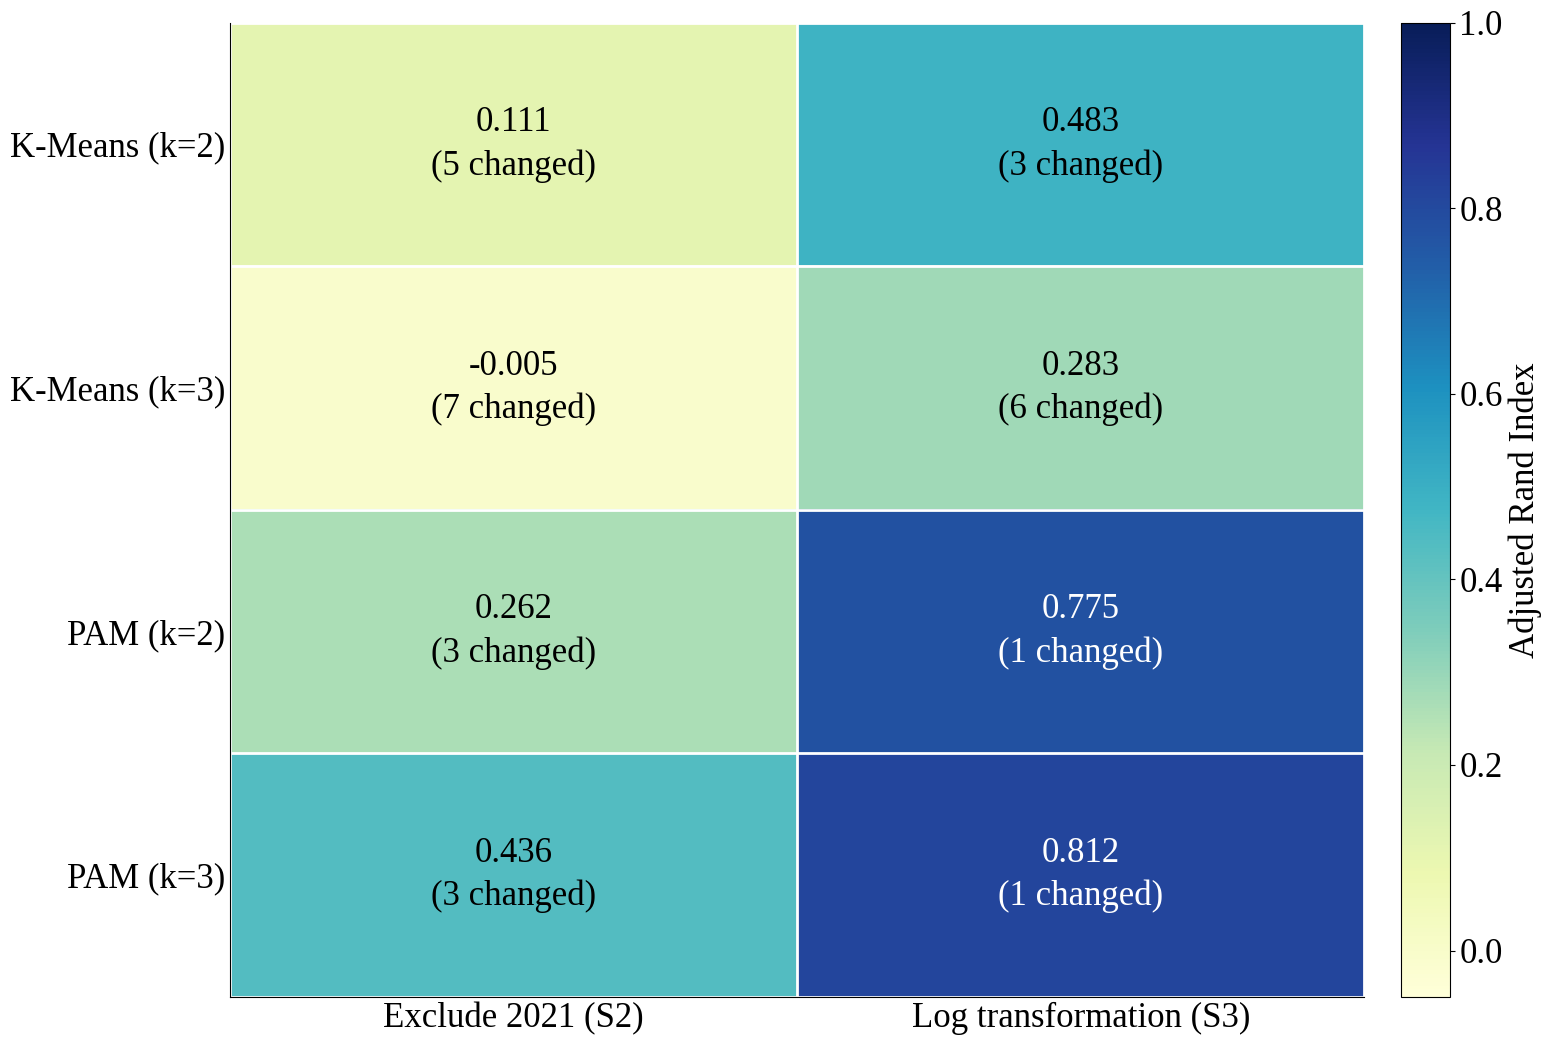


G.5.B — VISUALISASI SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Sensitivitas_G5/G5B_Heatmap_ARI_Sensitivitas.png


In [ ]:
# ============================================================
# G.5.B — HEATMAP SENSITIVITAS KEANGGOTAAN CLUSTER
#
# Dasar: Adjusted Rand Index (Hubert & Arabie, 1985)
# Input: ARI_SENSITIVITAS_G5 dari G.5.A
# Tidak melakukan fitting ulang model.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. VALIDASI INPUT
# ------------------------------------------------------------

assert "ARI_SENSITIVITAS_G5" in globals()

MODEL_URUT_G5 = [
    "KMeans_k2",
    "KMeans_k3",
    "PAM_k2",
    "PAM_k3"
]

SKENARIO_URUT_G5 = [
    "S1 vs S2",
    "S1 vs S3"
]

df_g5b = ARI_SENSITIVITAS_G5.copy()

assert len(df_g5b) == 8
assert not df_g5b.duplicated(
    ["model", "perbandingan"]
).any()

# ------------------------------------------------------------
# 2. MATRIKS ARI DAN JUMLAH PERUBAHAN
# ------------------------------------------------------------

M_ARIG5 = (
    df_g5b.pivot(
        index="model",
        columns="perbandingan",
        values="ARI"
    )
    .loc[MODEL_URUT_G5, SKENARIO_URUT_G5]
)

M_UBAHG5 = (
    df_g5b.pivot(
        index="model",
        columns="perbandingan",
        values="jumlah_wilayah_berubah"
    )
    .loc[MODEL_URUT_G5, SKENARIO_URUT_G5]
)

assert np.isfinite(
    M_ARIG5.to_numpy(dtype=float)
).all()

print("G.5.B — TABEL ARI")
display(M_ARIG5.round(5))

print("\nJUMLAH WILAYAH BERUBAH")
display(M_UBAHG5.astype(int))

# ------------------------------------------------------------
# 3. PENGATURAN VISUALISASI
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "savefig.dpi": 300
})

label_model = [
    "K-Means (k=2)",
    "K-Means (k=3)",
    "PAM (k=2)",
    "PAM (k=3)"
]

label_skenario = [
    "Exclude 2021 (S2)",
    "Log transformation (S3)"
]

nilai_ari = M_ARIG5.to_numpy(dtype=float)
nilai_ubah = M_UBAHG5.to_numpy(dtype=int)

# ------------------------------------------------------------
# 4. HEATMAP
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(16, 11)
)

im = ax.imshow(
    nilai_ari,
    cmap="YlGnBu",
    vmin=-0.05,
    vmax=1.00,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(label_skenario))
)

ax.set_xticklabels(
    label_skenario,
    fontsize=25
)

ax.set_yticks(
    np.arange(len(label_model))
)

ax.set_yticklabels(
    label_model,
    fontsize=25
)

# Garis pemisah sel
ax.set_xticks(
    np.arange(-0.5, len(label_skenario), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(label_model), 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=2
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

ax.tick_params(
    which="major",
    length=0
)

# ------------------------------------------------------------
# 5. ANOTASI NILAI ARI DAN WILAYAH BERUBAH
# ------------------------------------------------------------

for i in range(nilai_ari.shape[0]):

    for j in range(nilai_ari.shape[1]):

        ari = nilai_ari[i, j]
        n_ubah = nilai_ubah[i, j]

        warna_teks = (
            "white" if ari >= 0.65
            else "black"
        )

        ax.text(
            j,
            i,
            f"{ari:.3f}\n({n_ubah} changed)",
            ha="center",
            va="center",
            fontsize=25,
            color=warna_teks,
            linespacing=1.4
        )

# ------------------------------------------------------------
# 6. COLORBAR
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.045,
    pad=0.03
)

cbar.set_label(
    "Adjusted Rand Index",
    fontsize=25
)

cbar.ax.tick_params(
    labelsize=25
)

# Tanpa judul di dalam grafik.
fig.tight_layout()

# ------------------------------------------------------------
# 7. SIMPAN GAMBAR
# ------------------------------------------------------------

OUT_G5B = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Sensitivitas_G5"
)

OUT_G5B.mkdir(
    parents=True,
    exist_ok=True
)

FILE_G5B = (
    OUT_G5B / "G5B_Heatmap_ARI_Sensitivitas.png"
)

fig.savefig(
    FILE_G5B,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nG.5.B — VISUALISASI SELESAI")
print("File:", FILE_G5B)

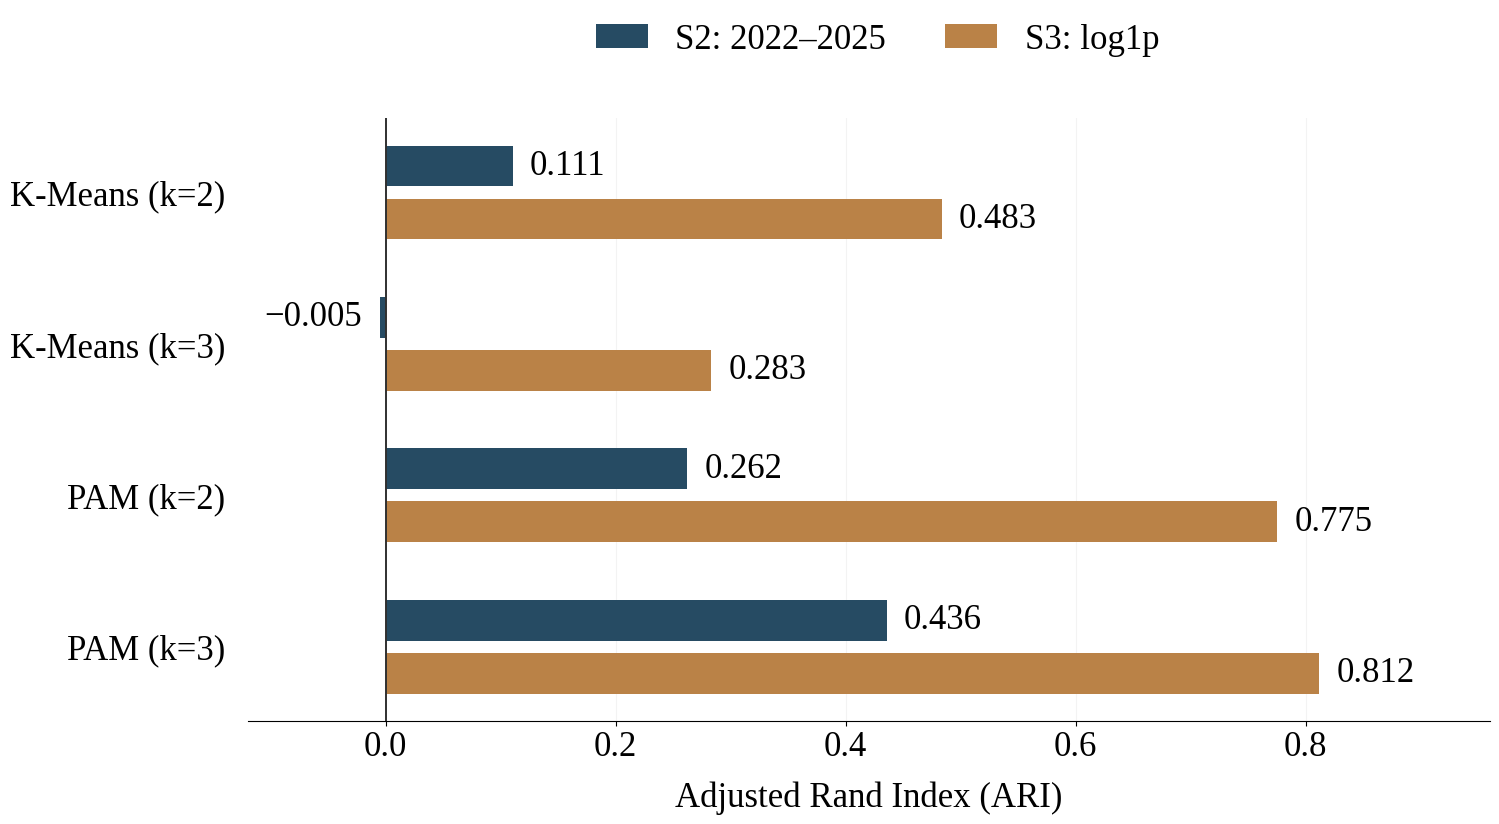

Visualisasi final tersimpan:
/content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Sensitivitas_G5/G5B_ARI_Sensitivitas_FINAL.png


In [ ]:
# ============================================================
# G.5.B — REVISI FINAL VISUALISASI SENSITIVITAS
# Grouped horizontal bar plot
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. AMBIL HASIL G.5.A
# ------------------------------------------------------------

assert "ARI_SENSITIVITAS_G5" in globals()

urutan_model = [
    "KMeans_k2",
    "KMeans_k3",
    "PAM_k2",
    "PAM_k3"
]

nama_model = [
    "K-Means (k=2)",
    "K-Means (k=3)",
    "PAM (k=2)",
    "PAM (k=3)"
]

tabel = (
    ARI_SENSITIVITAS_G5
    .pivot(
        index="model",
        columns="perbandingan",
        values="ARI"
    )
    .loc[
        urutan_model,
        ["S1 vs S2", "S1 vs S3"]
    ]
)

ari_s2 = tabel["S1 vs S2"].to_numpy(float)
ari_s3 = tabel["S1 vs S3"].to_numpy(float)

assert np.isfinite(tabel.to_numpy(float)).all()

# ------------------------------------------------------------
# 2. FORMAT ARTIKEL
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "savefig.dpi": 300
})

# ------------------------------------------------------------
# 3. MEMBANGUN GROUPED BAR PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(18, 9)
)

y = np.arange(len(urutan_model))

offset = 0.175
tinggi_batang = 0.27

bar_s2 = ax.barh(
    y - offset,
    ari_s2,
    height=tinggi_batang,
    color="#264B63",
    label="S2: 2022–2025",
    zorder=3
)

bar_s3 = ax.barh(
    y + offset,
    ari_s3,
    height=tinggi_batang,
    color="#BA8247",
    label="S3: log1p",
    zorder=3
)

# ------------------------------------------------------------
# 4. SUMBU DAN TAMPILAN
# ------------------------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(nama_model)

ax.invert_yaxis()

ax.tick_params(
    axis="y",
    length=0,
    pad=16
)

ax.set_xlabel(
    "Adjusted Rand Index (ARI)",
    labelpad=12
)

# Sedikit area negatif diperlukan untuk ARI -0.005.
ax.set_xlim(-0.12, 0.96)

ax.set_xticks(
    np.arange(0, 1.0, 0.2)
)

ax.axvline(
    0,
    color="#303030",
    linewidth=1.4,
    zorder=4
)

ax.xaxis.grid(
    True,
    linestyle="-",
    alpha=0.14
)

ax.set_axisbelow(True)

for sisi in ["top", "right", "left"]:
    ax.spines[sisi].set_visible(False)

# ------------------------------------------------------------
# 5. ANOTASI NILAI
# ------------------------------------------------------------

for kumpulan_batang in [bar_s2, bar_s3]:

    for batang in kumpulan_batang:

        nilai = batang.get_width()

        posisi_y = (
            batang.get_y()
            + batang.get_height() / 2
        )

        if nilai >= 0:
            posisi_x = nilai + 0.015
            alignment = "left"

        else:
            posisi_x = nilai - 0.015
            alignment = "right"

        ax.text(
            posisi_x,
            posisi_y,
            f"{nilai:.3f}".replace("-", "−"),
            ha=alignment,
            va="center",
            fontsize=25
        )

# ------------------------------------------------------------
# 6. LEGENDA DI LUAR AREA GRAFIK
# ------------------------------------------------------------

fig.legend(
    [bar_s2, bar_s3],
    ["S2: 2022–2025", "S3: log1p"],
    loc="upper center",
    bbox_to_anchor=(0.62, 0.97),
    ncol=2,
    frameon=False,
    handlelength=1.5,
    columnspacing=1.7
)

# Mengalokasikan ruang khusus untuk legenda,
# nama model, dan label sumbu.
fig.subplots_adjust(
    left=0.27,
    right=0.96,
    top=0.83,
    bottom=0.16
)

# ------------------------------------------------------------
# 7. SIMPAN HASIL FINAL
# ------------------------------------------------------------

OUT_G5B = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_G_Artikel1_Baru/"
    "Sensitivitas_G5"
)

OUT_G5B.mkdir(
    parents=True,
    exist_ok=True
)

FILE_G5B_FINAL = (
    OUT_G5B /
    "G5B_ARI_Sensitivitas_FINAL.png"
)

fig.savefig(
    FILE_G5B_FINAL,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("Visualisasi final tersimpan:")
print(FILE_G5B_FINAL)

## Sensitivitas pembobotan Standar versus Seimbang

In [ ]:
# ============================================================
# G.5.C — SENSITIVITAS PEMBOBOTAN INDIKATOR
#
# Perbandingan:
# 1. F6C_Seimbang (representasi utama)
# 2. F6C_Standar  (representasi alternatif)
#
# Model:
# - K-Means k=2 dan k=3
# - PAM k=2 dan k=3
#
# Dasar metodologis:
# - Jain & Dubes (1988): ketidakmiripan dan clustering
# - Rogel-Salazar (2017): standardisasi dan clustering
# - Kaufman & Rousseeuw (1990): PAM
# - Hubert & Arabie (1985): Adjusted Rand Index
#
# Tidak mengubah matriks F6C.
# Tidak memilih model terbaik secara otomatis.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.spatial.distance import pdist, squareform

from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    silhouette_samples,
    calinski_harabasz_score,
    davies_bouldin_score
)

from IPython.display import display


# ============================================================
# G.5.C.1 — VALIDASI INPUT
# ============================================================

objek_wajib = [
    "STANDAR_G",
    "SEIMBANG_G",
    "LABEL_G5",
    "fit_kmeans_g5",
    "fit_pam_g5",
    "sejajarkan_label_g5"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"{nama} belum tersedia. "
        "Periksa kembali G.0 dan G.5.A."
    )

X_STANDAR_G5C = STANDAR_G.copy()
X_SEIMBANG_G5C = SEIMBANG_G.copy()

assert X_STANDAR_G5C.shape == (22, 14)
assert X_SEIMBANG_G5C.shape == (22, 14)

assert X_STANDAR_G5C.index.equals(
    X_SEIMBANG_G5C.index
)

assert X_STANDAR_G5C.columns.equals(
    X_SEIMBANG_G5C.columns
)

assert np.isfinite(
    X_STANDAR_G5C.to_numpy(float)
).all()

assert np.isfinite(
    X_SEIMBANG_G5C.to_numpy(float)
).all()

WILAYAH_G5C = X_SEIMBANG_G5C.index

MODEL_G5C = [
    "KMeans_k2",
    "KMeans_k3",
    "PAM_k2",
    "PAM_k3"
]

print("=" * 70)
print("G.5.C — VALIDASI INPUT PEMBOBOTAN")
print("=" * 70)

print("Representasi utama    : Seimbang")
print("Representasi alternatif: Standar")
print("Jumlah wilayah        :", len(WILAYAH_G5C))
print("Jumlah indikator      :", X_STANDAR_G5C.shape[1])
print("Jumlah kandidat model :", len(MODEL_G5C))


# ============================================================
# G.5.C.2 — VERIFIKASI PERBEDAAN BOBOT
# ============================================================

FITUR_BPS_G5C = list(
    X_STANDAR_G5C.columns[:3]
)

FITUR_BNPB_G5C = list(
    X_STANDAR_G5C.columns[3:7]
)

FITUR_KRB_G5C = list(
    X_STANDAR_G5C.columns[7:14]
)

KELOMPOK_G5C = {
    "BPS": FITUR_BPS_G5C,
    "BNPB": FITUR_BNPB_G5C,
    "KRB": FITUR_KRB_G5C
}

hasil_bobot_g5c = []

for kelompok, fitur in KELOMPOK_G5C.items():

    bobot = 1 / np.sqrt(len(fitur))

    aktual = X_SEIMBANG_G5C[
        fitur
    ].to_numpy(float)

    harapan = (
        X_STANDAR_G5C[fitur]
        .to_numpy(float) * bobot
    )

    sesuai = np.allclose(
        aktual,
        harapan,
        atol=1e-8,
        rtol=1e-8
    )

    assert sesuai, (
        f"Pembobotan {kelompok} tidak sesuai F6C."
    )

    hasil_bobot_g5c.append({
        "kelompok": kelompok,
        "jumlah_indikator": len(fitur),
        "bobot_standar": 1.0,
        "bobot_seimbang": bobot,
        "sesuai_F6C": sesuai
    })

BOBOT_G5C = pd.DataFrame(
    hasil_bobot_g5c
)

print("\nA. VERIFIKASI BOBOT KELOMPOK")

display(BOBOT_G5C.round(6))


# ============================================================
# G.5.C.3 — AMBIL LABEL BASELINE SEIMBANG
# ============================================================

LABEL_SEIMBANG_G5C = {}

for model in MODEL_G5C:

    assert ("S1", model) in LABEL_G5, (
        f"Label baseline {model} tidak tersedia."
    )

    label = LABEL_G5[
        ("S1", model)
    ].reindex(WILAYAH_G5C)

    assert label.notna().all()

    LABEL_SEIMBANG_G5C[model] = (
        label.to_numpy(dtype=int)
    )

    # Konsistensi dengan hasil G.3.
    if "KEANGGOTAAN_G3" in globals():

        label_g3 = (
            KEANGGOTAAN_G3[model]
            .reindex(WILAYAH_G5C)
            .to_numpy(dtype=int)
        )

        ari_validasi = adjusted_rand_score(
            label_g3,
            LABEL_SEIMBANG_G5C[model]
        )

        assert np.isclose(
            ari_validasi, 1.0
        ), (
            f"Baseline {model} berbeda "
            "antara G.3 dan G.5."
        )

print("\nB. BASELINE SEIMBANG")
print("Keempat partisi S1 tersedia dan tervalidasi.")


# ============================================================
# G.5.C.4 — FITTING ULANG PADA MATRIKS STANDAR
# ============================================================

X_STD = X_STANDAR_G5C.to_numpy(
    dtype=float
)

D_STD = squareform(
    pdist(X_STD, metric="euclidean")
)

LABEL_STANDAR_G5C = {}

# ------------------------------
# A. K-MEANS
# ------------------------------

for k in [2, 3]:

    nama = f"KMeans_k{k}"

    labels = fit_kmeans_g5(
        X_STD,
        k
    )

    assert len(np.unique(labels)) == k

    LABEL_STANDAR_G5C[nama] = labels.copy()


# ------------------------------
# B. K-MEDOIDS PAM
# ------------------------------

# Reset RNG seperti G.5.A.
# Urutan k=2 kemudian k=3 dipertahankan
# agar prosedur inisialisasi tetap sama.

rng_g5c = np.random.default_rng(42)

for k in [2, 3]:

    nama = f"PAM_k{k}"

    labels = fit_pam_g5(
        D_STD,
        k,
        rng_g5c
    )

    assert len(np.unique(labels)) == k

    LABEL_STANDAR_G5C[nama] = labels.copy()

print("\nC. FITTING MATRIKS STANDAR")
print("K-Means k=2 dan k=3: selesai")
print("PAM k=2 dan k=3    : selesai")


# ============================================================
# G.5.C.5 — FUNGSI EVALUASI INTERNAL
# ============================================================

def evaluasi_internal_g5c(X, labels):

    labels = np.asarray(
        labels,
        dtype=int
    )

    jumlah_cluster = len(
        np.unique(labels)
    )

    assert 2 <= jumlah_cluster < len(X)

    ukuran = (
        pd.Series(labels)
        .value_counts()
        .sort_values()
    )

    sil_individu = silhouette_samples(
        X,
        labels,
        metric="euclidean"
    )

    return {
        "jumlah_cluster": jumlah_cluster,

        "Silhouette": silhouette_score(
            X,
            labels,
            metric="euclidean"
        ),

        "CHI": calinski_harabasz_score(
            X,
            labels
        ),

        "DBI": davies_bouldin_score(
            X,
            labels
        ),

        "jumlah_singleton": int(
            (ukuran == 1).sum()
        ),

        "silhouette_negatif": int(
            (sil_individu < 0).sum()
        ),

        "ukuran_cluster": ", ".join(
            map(str, ukuran.tolist())
        )
    }


# ============================================================
# G.5.C.6 — EVALUASI KEDUA REPRESENTASI
# ============================================================

HASIL_INTERNAL_G5C = []

X_BAL = X_SEIMBANG_G5C.to_numpy(
    dtype=float
)

for model in MODEL_G5C:

    untuk_evaluasi = [
        (
            "Seimbang",
            X_BAL,
            LABEL_SEIMBANG_G5C[model]
        ),
        (
            "Standar",
            X_STD,
            LABEL_STANDAR_G5C[model]
        )
    ]

    for representasi, X, labels in untuk_evaluasi:

        hasil = evaluasi_internal_g5c(
            X, labels
        )

        HASIL_INTERNAL_G5C.append({
            "model": model,
            "representasi": representasi,
            **hasil
        })


EVALUASI_INTERNAL_G5C = pd.DataFrame(
    HASIL_INTERNAL_G5C
)

print("\n" + "=" * 70)
print("D. EVALUASI INTERNAL KEDUA REPRESENTASI")
print("=" * 70)

display(
    EVALUASI_INTERNAL_G5C.round(5)
)


# ============================================================
# G.5.C.7 — ARI STANDAR VS SEIMBANG
# ============================================================

HASIL_KONSISTENSI_G5C = []
DETAIL_WILAYAH_G5C = []

LABEL_SEJAJAR_G5C = {}

for model in MODEL_G5C:

    acuan = LABEL_SEIMBANG_G5C[
        model
    ]

    alternatif = LABEL_STANDAR_G5C[
        model
    ]

    # ARI tidak memerlukan penyelarasan label.
    ari = adjusted_rand_score(
        acuan,
        alternatif
    )

    # Penyelarasan diperlukan untuk
    # menghitung wilayah yang berubah.
    alternatif_sejajar = sejajarkan_label_g5(
        acuan,
        alternatif
    )

    LABEL_SEJAJAR_G5C[model] = (
        alternatif_sejajar
    )

    berubah = (
        acuan != alternatif_sejajar
    )

    wilayah_berubah = (
        WILAYAH_G5C[berubah].tolist()
    )

    ukuran_bal = sorted(
        pd.Series(acuan)
        .value_counts()
        .tolist()
    )

    ukuran_std = sorted(
        pd.Series(alternatif)
        .value_counts()
        .tolist()
    )

    HASIL_KONSISTENSI_G5C.append({
        "model": model,
        "ARI_Standar_Seimbang": ari,
        "jumlah_wilayah_berubah": int(
            berubah.sum()
        ),
        "ukuran_Seimbang": ", ".join(
            map(str, ukuran_bal)
        ),
        "ukuran_Standar": ", ".join(
            map(str, ukuran_std)
        ),
        "wilayah_berubah": (
            ", ".join(wilayah_berubah)
            if wilayah_berubah
            else "-"
        )
    })

    for i, wilayah in enumerate(WILAYAH_G5C):

        DETAIL_WILAYAH_G5C.append({
            "kabupaten_kota": wilayah,
            "model": model,
            "cluster_Seimbang": int(acuan[i]),
            "cluster_Standar_disejajarkan":
                int(alternatif_sejajar[i]),
            "berubah": bool(berubah[i])
        })


KONSISTENSI_G5C = pd.DataFrame(
    HASIL_KONSISTENSI_G5C
)

DETAIL_G5C = pd.DataFrame(
    DETAIL_WILAYAH_G5C
)

print("\n" + "=" * 70)
print("E. KONSISTENSI PARTISI STANDAR VS SEIMBANG")
print("=" * 70)

display(
    KONSISTENSI_G5C.round(5)
)


# ============================================================
# G.5.C.8 — IDENTIFIKASI WILAYAH YANG BERUBAH
# ============================================================

PERUBAHAN_G5C = (
    DETAIL_G5C[
        DETAIL_G5C["berubah"]
    ]
    .sort_values(
        ["model", "kabupaten_kota"]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("F. RINCIAN WILAYAH YANG BERUBAH")
print("=" * 70)

if PERUBAHAN_G5C.empty:

    print(
        "Tidak ada perubahan keanggotaan "
        "pada keempat model."
    )

else:

    display(PERUBAHAN_G5C)


# ============================================================
# G.5.C.9 — FREKUENSI WILAYAH BERUBAH
# ============================================================

FREKUENSI_PERUBAHAN_G5C = (
    DETAIL_G5C
    .groupby(
        "kabupaten_kota",
        as_index=False
    )["berubah"]
    .sum()
    .rename(
        columns={
            "berubah": "jumlah_model_berubah"
        }
    )
    .sort_values(
        [
            "jumlah_model_berubah",
            "kabupaten_kota"
        ],
        ascending=[False, True]
    )
)

print("\nG. FREKUENSI PERUBAHAN PER WILAYAH")

display(
    FREKUENSI_PERUBAHAN_G5C
)


# ============================================================
# G.5.C.10 — TABEL KEANGGOTAAN SELURUH MODEL
# ============================================================

KEANGGOTAAN_G5C = pd.DataFrame(
    index=WILAYAH_G5C
)

for model in MODEL_G5C:

    KEANGGOTAAN_G5C[
        f"Seimbang_{model}"
    ] = LABEL_SEIMBANG_G5C[model]

    KEANGGOTAAN_G5C[
        f"Standar_{model}"
    ] = LABEL_SEJAJAR_G5C[model]


print("\nH. KEANGGOTAAN SELURUH MODEL")

display(KEANGGOTAAN_G5C)


# ============================================================
# G.5.C.11 — SIMPAN HASIL DAN TABEL
# ============================================================

OUT_G5C = (
    Path(
        "/content/drive/MyDrive/"
        "NTT_Disaster_Analysis data"
    )
    / "Hasil_G_Artikel1_Baru"
    / "Sensitivitas_G5"
)

OUT_G5C.mkdir(
    parents=True,
    exist_ok=True
)

FILE_G5C = (
    OUT_G5C
    / "G5C_Sensitivitas_Pembobotan.xlsx"
)

with pd.ExcelWriter(
    FILE_G5C,
    engine="openpyxl"
) as writer:

    BOBOT_G5C.to_excel(
        writer,
        sheet_name="Bobot_Kelompok",
        index=False
    )

    EVALUASI_INTERNAL_G5C.to_excel(
        writer,
        sheet_name="Metrik_Internal",
        index=False
    )

    KONSISTENSI_G5C.to_excel(
        writer,
        sheet_name="Ringkasan_ARI",
        index=False
    )

    PERUBAHAN_G5C.to_excel(
        writer,
        sheet_name="Wilayah_Berubah",
        index=False
    )

    FREKUENSI_PERUBAHAN_G5C.to_excel(
        writer,
        sheet_name="Frekuensi_Perubahan",
        index=False
    )

    KEANGGOTAAN_G5C.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )


print("\n" + "=" * 70)
print("G.5.C SELESAI")
print("=" * 70)

print("File hasil:", FILE_G5C)
print("Model diuji:", len(MODEL_G5C))
print("Representasi: Standar dan Seimbang")
print("Data utama F6C tidak diubah.")
print("Model terbaik belum ditetapkan.")

G.5.C — VALIDASI INPUT PEMBOBOTAN
Representasi utama    : Seimbang
Representasi alternatif: Standar
Jumlah wilayah        : 22
Jumlah indikator      : 14
Jumlah kandidat model : 4

A. VERIFIKASI BOBOT KELOMPOK


,kelompok,jumlah_indikator,bobot_standar,bobot_seimbang,sesuai_F6C
0,BPS,3,1.0,0.577350,True
1,BNPB,4,1.0,0.500000,True
2,KRB,7,1.0,0.377964,True



B. BASELINE SEIMBANG
Keempat partisi S1 tersedia dan tervalidasi.

C. FITTING MATRIKS STANDAR
K-Means k=2 dan k=3: selesai
PAM k=2 dan k=3    : selesai

D. EVALUASI INTERNAL KEDUA REPRESENTASI


,model,representasi,jumlah_cluster,Silhouette,CHI,DBI,jumlah_singleton,silhouette_negatif,ukuran_cluster
0,KMeans_k2,Seimbang,2,0.26119,5.27249,1.67986,0,3,"5, 17"
1,KMeans_k2,Standar,2,0.28361,5.38151,1.52668,0,0,"4, 18"
2,KMeans_k3,Seimbang,3,0.25556,4.86661,1.08089,1,0,"1, 4, 17"
3,KMeans_k3,Standar,3,0.24793,5.29747,1.08322,1,1,"1, 4, 17"
4,PAM_k2,Seimbang,2,0.24907,4.49603,1.28200,0,1,"3, 19"
5,PAM_k2,Standar,2,0.27027,4.59260,1.68586,0,2,"4, 18"
6,PAM_k3,Seimbang,3,0.26384,4.60817,0.96414,1,1,"1, 3, 18"
7,PAM_k3,Standar,3,0.25241,4.95149,0.97999,1,1,"1, 3, 18"



E. KONSISTENSI PARTISI STANDAR VS SEIMBANG


...


G. FREKUENSI PERUBAHAN PER WILAYAH


,kabupaten_kota,jumlah_model_berubah
13,Rote Ndao,1
14,Sabu Raijua,1
0,Alor,0
1,Belu,0
2,Ende,0
3,Flores Timur,0
4,Kota Kupang,0
5,Kupang,0
6,Lembata,0
7,Malaka,0



H. KEANGGOTAAN SELURUH MODEL


,Seimbang_KMeans_k2,Standar_KMeans_k2,Seimbang_KMeans_k3,Standar_KMeans_k3,Seimbang_PAM_k2,Standar_PAM_k2,Seimbang_PAM_k3,Standar_PAM_k3
kabupaten_kota,,,,,,,,
Sumba Barat,0,0,1,1,0,0,0,0
Sumba Timur,0,0,1,1,0,0,0,0
Kupang,0,0,1,1,0,0,0,0
Timor Tengah Selatan,0,0,1,1,0,0,0,0
Timor Tengah Utara,0,0,1,1,0,0,0,0
Belu,0,0,1,1,0,0,0,0
Alor,1,1,0,0,0,0,0,0
Lembata,1,1,0,0,1,1,1,1
Flores Timur,1,1,0,0,1,1,1,1



G.5.C SELESAI
File hasil: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Sensitivitas_G5/G5C_Sensitivitas_Pembobotan.xlsx
Model diuji: 4
Representasi: Standar dan Seimbang
Data utama F6C tidak diubah.
Model terbaik belum ditetapkan.


## Pemeriksaan sensitivitas GMM sebagai algoritme pembanding

In [ ]:
# ============================================================
# G.5.D — SENSITIVITAS GMM DIAGONAL k=2
#
# Dasar:
# - Lukito et al. (2026): GMM sebagai pembanding clustering
# - GaussianMixture, scikit-learn
# - Hubert & Arabie (1985): Adjusted Rand Index
#
# Tujuan:
# 1. Memeriksa konsistensi GMM terhadap S2 dan S3
# 2. Memeriksa sensitivitas pembobotan Standar–Seimbang
# 3. Memeriksa kesamaan partisi GMM dan K-Means
#
# Tidak mengulang grid search.
# Tidak mengubah dataset utama.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from IPython.display import display


# ============================================================
# G.5.D.1 — VALIDASI INPUT
# ============================================================

objek_wajib = [
    "SKENARIO_G4",
    "STANDAR_G",
    "SEIMBANG_G",
    "LABEL_GMM_G2C",
    "MODEL_GMM_G2C",
    "LABEL_G5",
    "LABEL_STANDAR_G5C",
    "sejajarkan_label_g5"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"Objek {nama} tidak tersedia."
    )

MODEL_ACUAN_G5D = MODEL_GMM_G2C[("diag", 2)]

assert MODEL_ACUAN_G5D.n_components == 2
assert MODEL_ACUAN_G5D.covariance_type == "diag"

assert np.isclose(
    MODEL_ACUAN_G5D.reg_covar, 0.01
)

WILAYAH_G5D = SEIMBANG_G.index

LABEL_ACUAN_GMM_G5D = (
    LABEL_GMM_G2C[("diag", 2)]
    .reindex(WILAYAH_G5D)
    .to_numpy(dtype=int)
)


# ============================================================
# G.5.D.2 — REPRESENTASI YANG DIUJI
# ============================================================

INPUT_GMM_G5D = {
    "S1_Seimbang": SKENARIO_G4["S1"]["Seimbang"],
    "S2_Seimbang": SKENARIO_G4["S2"]["Seimbang"],
    "S3_Seimbang": SKENARIO_G4["S3"]["Seimbang"],
    "S1_Standar": STANDAR_G
}

assert np.allclose(
    INPUT_GMM_G5D["S1_Seimbang"].to_numpy(float),
    SEIMBANG_G.to_numpy(float),
    atol=1e-7,
    rtol=1e-9
)

for nama, df in INPUT_GMM_G5D.items():

    assert df.shape == (22, 14)
    assert df.index.equals(WILAYAH_G5D)
    assert np.isfinite(df.to_numpy(float)).all()


# ============================================================
# G.5.D.3 — FITTING GMM DENGAN PARAMETER TETAP
# ============================================================

HASIL_LIST_GMM_G5D = []
LABEL_GMM_G5D = {}
MODEL_GMM_G5D = {}

for nama, df in INPUT_GMM_G5D.items():

    X = df.to_numpy(dtype=float)

    model = GaussianMixture(
        n_components=2,
        covariance_type="diag",
        reg_covar=0.01,
        n_init=30,
        init_params="kmeans",
        random_state=42,
        max_iter=500,
        tol=1e-4
    )

    model.fit(X)

    labels = model.predict(X)
    proba = model.predict_proba(X)

    jumlah_aktual = len(np.unique(labels))

    ukuran = sorted(
        pd.Series(labels).value_counts().tolist()
    )

    # ARI GMM terhadap baseline S1
    ari_baseline = adjusted_rand_score(
        LABEL_ACUAN_GMM_G5D,
        labels
    )

    # Validasi reproduksi baseline
    if nama == "S1_Seimbang":

        assert np.isclose(
            ari_baseline, 1.0,
            atol=1e-12
        ), (
            "Reproduksi GMM baseline berbeda "
            "dari hasil G.2.C."
        )

        assert np.isclose(
            model.bic(X),
            MODEL_ACUAN_G5D.bic(X),
            atol=1e-4,
            rtol=1e-6
        )

    # Label K-Means yang sesuai setiap skenario
    if nama == "S1_Standar":

        label_kmeans = LABEL_STANDAR_G5C[
            "KMeans_k2"
        ]

    else:

        skenario = nama.split("_")[0]

        label_kmeans = LABEL_G5[
            (skenario, "KMeans_k2")
        ].reindex(WILAYAH_G5D).to_numpy(dtype=int)

    ari_kmeans = adjusted_rand_score(
        labels,
        label_kmeans
    )

    # Metrik internal hanya terdefinisi
    # apabila minimal dua cluster terbentuk.
    if 2 <= jumlah_aktual < len(X):

        sil = silhouette_score(
            X, labels, metric="euclidean"
        )

        chi = calinski_harabasz_score(
            X, labels
        )

        dbi = davies_bouldin_score(
            X, labels
        )

    else:

        sil = np.nan
        chi = np.nan
        dbi = np.nan

    HASIL_LIST_GMM_G5D.append({
        "input": nama,
        "cluster_aktual": jumlah_aktual,
        "ukuran_cluster": ", ".join(map(str, ukuran)),
        "singleton": int(
            sum(u == 1 for u in ukuran)
        ),
        "Silhouette": sil,
        "CHI": chi,
        "DBI": dbi,
        "ARI_vs_GMM_S1": ari_baseline,
        "ARI_vs_KMeans_k2": ari_kmeans,
        "BIC": float(model.bic(X)),
        "konvergen": bool(model.converged_),
        "kovarians_minimum": float(
            np.min(model.covariances_)
        ),
        "kovarians_dekat_batas": bool(
            np.min(model.covariances_) <= 0.0100001
        ),
        "mean_max_probability": float(
            proba.max(axis=1).mean()
        )
    })

    LABEL_GMM_G5D[nama] = pd.Series(
        labels,
        index=WILAYAH_G5D
    )

    MODEL_GMM_G5D[nama] = model


# ============================================================
# G.5.D.4 — TABEL KONSISTENSI GMM
# ============================================================

EVALUASI_GMM_G5D = pd.DataFrame(
    HASIL_LIST_GMM_G5D
)

print("=" * 70)
print("G.5.D — SENSITIVITAS GMM DIAGONAL k=2")
print("=" * 70)

display(
    EVALUASI_GMM_G5D.round(5)
)


# ============================================================
# G.5.D.5 — IDENTIFIKASI WILAYAH BERUBAH
# ============================================================

HASIL_WILAYAH_GMM_G5D = []

for nama, series in LABEL_GMM_G5D.items():

    if nama == "S1_Seimbang":
        continue

    labels = series.to_numpy(dtype=int)

    if len(np.unique(labels)) != 2:

        # Penyelarasan satu-ke-satu tidak dilakukan
        # jika jumlah cluster aktual berbeda.
        continue

    sejajar = sejajarkan_label_g5(
        LABEL_ACUAN_GMM_G5D,
        labels
    )

    berubah = (
        LABEL_ACUAN_GMM_G5D != sejajar
    )

    daftar_berubah = (
        WILAYAH_G5D[berubah].tolist()
    )

    HASIL_WILAYAH_GMM_G5D.append({
        "input": nama,
        "ARI": adjusted_rand_score(
            LABEL_ACUAN_GMM_G5D,
            labels
        ),
        "jumlah_wilayah_berubah": int(
            berubah.sum()
        ),
        "wilayah_berubah": (
            ", ".join(daftar_berubah)
            if daftar_berubah else "-"
        )
    })


PERUBAHAN_GMM_G5D = pd.DataFrame(
    HASIL_WILAYAH_GMM_G5D
)

print("\nB. PERUBAHAN KEANGGOTAAN GMM")

display(
    PERUBAHAN_GMM_G5D.round(5)
)


# ============================================================
# G.5.D.6 — SIMPAN HASIL
# ============================================================

OUT_G5D = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_G_Artikel1_Baru/"
    "Sensitivitas_G5"
)

OUT_G5D.mkdir(
    parents=True,
    exist_ok=True
)

FILE_G5D = (
    OUT_G5D /
    "G5D_Sensitivitas_GMM_Diagonal_k2.xlsx"
)

TABEL_LABEL_GMM_G5D = pd.DataFrame(
    LABEL_GMM_G5D,
    index=WILAYAH_G5D
)

with pd.ExcelWriter(
    FILE_G5D,
    engine="openpyxl"
) as writer:

    EVALUASI_GMM_G5D.to_excel(
        writer,
        sheet_name="Evaluasi",
        index=False
    )

    PERUBAHAN_GMM_G5D.to_excel(
        writer,
        sheet_name="Perubahan_Wilayah",
        index=False
    )

    TABEL_LABEL_GMM_G5D.to_excel(
        writer,
        sheet_name="Keanggotaan"
    )


print("\nG.5.D SELESAI")
print("Hasil tersimpan:", FILE_G5D)
print("Model utama belum diubah.")

G.5.D — SENSITIVITAS GMM DIAGONAL k=2


,input,cluster_aktual,ukuran_cluster,singleton,Silhouette,CHI,DBI,ARI_vs_GMM_S1,ARI_vs_KMeans_k2,BIC,konvergen,kovarians_minimum,kovarians_dekat_batas,mean_max_probability
0,S1_Seimbang,2,"5, 17",0,0.26119,5.27249,1.67986,1.00000,1.00000,372.09567,True,0.01255,False,0.99984
1,S2_Seimbang,2,"9, 13",0,0.13546,3.57696,2.23381,0.17167,0.09856,377.45457,True,0.01031,False,0.99993
2,S3_Seimbang,2,"8, 14",0,0.16880,4.79883,1.89820,0.50251,0.65190,407.19260,True,0.01275,False,0.99974
3,S1_Standar,2,"5, 17",0,0.26352,5.26528,1.69487,1.00000,0.79810,849.13832,True,0.02788,False,0.99989



B. PERUBAHAN KEANGGOTAAN GMM


,input,ARI,jumlah_wilayah_berubah,wilayah_berubah
0,S2_Seimbang,0.17167,6,"Kupang, Belu, Alor, Ende, Nagekeo, Malaka"
1,S3_Seimbang,0.50251,3,"Kupang, Ende, Nagekeo"
2,S1_Standar,1.00000,0,-



G.5.D SELESAI
Hasil tersimpan: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Sensitivitas_G5/G5D_Sensitivitas_GMM_Diagonal_k2.xlsx
Model utama belum diubah.


In [ ]:
# ============================================================
# G.6.A — TABEL KOMPARATIF FINAL CLUSTERING
#
# Menggabungkan:
# G.3.A — Validasi internal
# G.5.A — Sensitivitas BNPB S2 dan S3
# G.5.C — Sensitivitas pembobotan
# G.5.D — Sensitivitas GMM
#
# Tidak melakukan fitting ulang.
# Tidak menghitung skor gabungan buatan.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. VALIDASI OBJEK
# ------------------------------------------------------------

objek_wajib = [
    "EVALUASI_MODEL_G3",
    "ARI_SENSITIVITAS_G5",
    "KONSISTENSI_G5C",
    "EVALUASI_GMM_G5D"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"Objek {nama} belum tersedia."
    )

# ------------------------------------------------------------
# 2. SIAPKAN TABEL SUMBER
# ------------------------------------------------------------

evaluasi = EVALUASI_MODEL_G3.set_index("model")

ari_bnpb = ARI_SENSITIVITAS_G5.set_index(
    ["model", "perbandingan"]
)

ari_bobot = KONSISTENSI_G5C.set_index("model")

gmm_sens = EVALUASI_GMM_G5D.set_index("input")

model_urut = [
    "KMeans_k2",
    "KMeans_k3",
    "PAM_k2",
    "PAM_k3",
    "GMM_diag_k2",
    "GMM_diag_k3"
]

assert all(m in evaluasi.index for m in model_urut)

# ------------------------------------------------------------
# 3. GABUNGKAN SEMUA HASIL
# ------------------------------------------------------------

hasil = []

for model in model_urut:

    base = evaluasi.loc[model]

    if model in ["KMeans_k2", "KMeans_k3",
                 "PAM_k2", "PAM_k3"]:

        ari_s2 = float(
            ari_bnpb.loc[
                (model, "S1 vs S2"), "ARI"
            ]
        )

        ari_s3 = float(
            ari_bnpb.loc[
                (model, "S1 vs S3"), "ARI"
            ]
        )

        ari_weight = float(
            ari_bobot.loc[
                model, "ARI_Standar_Seimbang"
            ]
        )

    elif model == "GMM_diag_k2":

        ari_s2 = float(
            gmm_sens.loc[
                "S2_Seimbang", "ARI_vs_GMM_S1"
            ]
        )

        ari_s3 = float(
            gmm_sens.loc[
                "S3_Seimbang", "ARI_vs_GMM_S1"
            ]
        )

        ari_weight = float(
            gmm_sens.loc[
                "S1_Standar", "ARI_vs_GMM_S1"
            ]
        )

    else:
        # GMM diagonal k=3 tidak diuji
        # pada seluruh skenario sensitivitas.
        ari_s2 = np.nan
        ari_s3 = np.nan
        ari_weight = np.nan

    hasil.append({
        "Model": model,
        "k": int(base["jumlah_cluster"]),
        "Silhouette": float(base["Silhouette"]),
        "CHI": float(base["CHI"]),
        "DBI": float(base["DBI"]),
        "Cluster_size": base["ukuran_cluster"],
        "Singleton": int(base["jumlah_singleton"]),
        "Negative_silhouette": int(
            base["silhouette_negatif"]
        ),
        "ARI_S2": ari_s2,
        "ARI_S3": ari_s3,
        "ARI_Weight": ari_weight
    })

TABEL_SELEKSI_G6A = pd.DataFrame(hasil)

# DBSCAN tidak menghasilkan partisi multicluster.
baris_dbscan = pd.DataFrame([{
    "Model": "DBSCAN",
    "k": np.nan,
    "Silhouette": np.nan,
    "CHI": np.nan,
    "DBI": np.nan,
    "Cluster_size": "No multi-cluster solution",
    "Singleton": np.nan,
    "Negative_silhouette": np.nan,
    "ARI_S2": np.nan,
    "ARI_S3": np.nan,
    "ARI_Weight": np.nan
}])

TABEL_SELEKSI_G6A = pd.concat(
    [TABEL_SELEKSI_G6A, baris_dbscan],
    ignore_index=True
)

# ------------------------------------------------------------
# 4. KETERANGAN STATUS
# ------------------------------------------------------------

status = {
    "KMeans_k2": "Kandidat pembanding",
    "KMeans_k3": "Kandidat pembanding",
    "PAM_k2": "Alternatif tanpa singleton",
    "PAM_k3": "Kandidat utama",
    "GMM_diag_k2": "Pembanding probabilistik",
    "GMM_diag_k3": "Sensitivitas tidak lengkap",
    "DBSCAN": "Tidak memenuhi syarat multicluster"
}

TABEL_SELEKSI_G6A["Status"] = (
    TABEL_SELEKSI_G6A["Model"].map(status)
)

print("=" * 70)
print("G.6.A — TABEL SELEKSI MODEL CLUSTERING")
print("=" * 70)

display(
    TABEL_SELEKSI_G6A.round(4)
)

# ------------------------------------------------------------
# 5. SIMPAN TABEL DAN METADATA
# ------------------------------------------------------------

OUT_G6 = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_G_Artikel1_Baru/"
    "Seleksi_Model_G6"
)

OUT_G6.mkdir(parents=True, exist_ok=True)

FILE_G6A = (
    OUT_G6 / "G6A_Tabel_Seleksi_Model_Clustering.xlsx"
)

CATATAN_G6A = pd.DataFrame({
    "Keterangan": [
        "Representasi utama",
        "Wilayah",
        "Jumlah indikator",
        "Silhouette",
        "CHI",
        "DBI",
        "ARI_S2",
        "ARI_S3",
        "ARI_Weight",
        "Singleton",
        "Keterbatasan"
    ],
    "Penjelasan": [
        "F6C_Seimbang, skenario S1",
        "22 kabupaten/kota NTT",
        "14 indikator",
        "Semakin tinggi semakin baik",
        "Semakin tinggi semakin baik",
        "Semakin rendah semakin baik",
        "ARI baseline terhadap BNPB 2022–2025",
        "ARI baseline terhadap log1p BNPB",
        "ARI Standar versus Seimbang",
        "Cluster dengan satu anggota",
        "ARI sensitivitas GMM diagonal k=3 tidak diuji; "
        "DBSCAN tidak menghasilkan >=2 cluster"
    ]
})

with pd.ExcelWriter(
    FILE_G6A,
    engine="openpyxl"
) as writer:

    TABEL_SELEKSI_G6A.to_excel(
        writer,
        sheet_name="Seleksi_Model",
        index=False
    )

    CATATAN_G6A.to_excel(
        writer,
        sheet_name="Keterangan",
        index=False
    )

print("\nG.6.A SELESAI")
print("File:", FILE_G6A)
print("Model utama sementara: PAM k=3")

G.6.A — TABEL SELEKSI MODEL CLUSTERING


,Model,k,Silhouette,CHI,DBI,Cluster_size,Singleton,Negative_silhouette,ARI_S2,ARI_S3,ARI_Weight,Status
0,KMeans_k2,2.0,0.2612,5.2725,1.6799,"5, 17",0.0,3.0,0.1105,0.4835,0.7981,Kandidat pembanding
1,KMeans_k3,3.0,0.2556,4.8666,1.0809,"1, 4, 17",1.0,0.0,-0.0053,0.2832,1.0000,Kandidat pembanding
2,PAM_k2,2.0,0.2491,4.4960,1.2820,"3, 19",0.0,1.0,0.2622,0.7753,0.7753,Alternatif tanpa singleton
3,PAM_k3,3.0,0.2638,4.6082,0.9641,"1, 3, 18",1.0,1.0,0.4357,0.8117,1.0000,Kandidat utama
4,GMM_diag_k2,2.0,0.2612,5.2725,1.6799,"5, 17",0.0,3.0,0.1717,0.5025,1.0000,Pembanding probabilistik
5,GMM_diag_k3,3.0,0.1759,4.4260,1.3143,"1, 6, 15",1.0,2.0,NaN,NaN,NaN,Sensitivitas tidak lengkap
6,DBSCAN,NaN,NaN,NaN,NaN,No multi-cluster solution,NaN,NaN,NaN,NaN,NaN,Tidak memenuhi syarat multicluster



G.6.A SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Seleksi_Model_G6/G6A_Tabel_Seleksi_Model_Clustering.xlsx
Model utama sementara: PAM k=3


# Analisis profil tiga cluster PAM

In [ ]:
# ============================================================
# G.6.B — PROFIL INDIKATOR CLUSTER PAM k=3
#
# Model utama: K-Medoids PAM, k=3
# Input:
# - INTI_G              : 22 x 14, skala asli
# - STANDAR_G           : 22 x 14, z-score
# - LABEL_PAM_G2B[3]    : keanggotaan PAM k=3
# - MEDOID_PAM_G2B[3]   : wilayah medoid
#
# Output:
# A. Anggota dan medoid cluster
# B. Rata-rata z-score seluruh indikator
# C. Median indikator pada skala asli
# D. Rata-rata indikator pada skala asli
# E. Kontras indikator antarcluster
# F. Indikator pembeda utama setiap cluster
#
# Analisis deskriptif, tanpa uji signifikansi.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display


# ============================================================
# G.6.B.1 — VALIDASI INPUT
# ============================================================

objek_wajib = [
    "INTI_G",
    "STANDAR_G",
    "LABEL_PAM_G2B",
    "MEDOID_PAM_G2B"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"Objek {nama} belum tersedia."
    )

assert 3 in LABEL_PAM_G2B
assert 3 in MEDOID_PAM_G2B

DATA_ASLI_G6B = INTI_G.copy()
DATA_Z_G6B = STANDAR_G.copy()

assert DATA_ASLI_G6B.shape == (22, 14)
assert DATA_Z_G6B.shape == (22, 14)

assert DATA_ASLI_G6B.index.equals(
    DATA_Z_G6B.index
)

assert DATA_ASLI_G6B.columns.equals(
    DATA_Z_G6B.columns
)

assert np.isfinite(
    DATA_ASLI_G6B.to_numpy(float)
).all()

assert np.isfinite(
    DATA_Z_G6B.to_numpy(float)
).all()

# Selaraskan label berdasarkan nama wilayah.
LABEL_UTAMA_G6B = (
    LABEL_PAM_G2B[3]
    .reindex(DATA_ASLI_G6B.index)
)

assert LABEL_UTAMA_G6B.notna().all()

LABEL_UTAMA_G6B = LABEL_UTAMA_G6B.astype(int)

assert len(LABEL_UTAMA_G6B.unique()) == 3

UKURAN_G6B = (
    LABEL_UTAMA_G6B
    .value_counts()
    .sort_index()
)

assert sorted(UKURAN_G6B.tolist()) == [1, 3, 18]

MEDOID_G6B = MEDOID_PAM_G2B[3]

assert len(MEDOID_G6B) == 3


# ============================================================
# G.6.B.2 — KELOMPOK SUMBER INDIKATOR
# ============================================================

FITUR_G6B = list(DATA_ASLI_G6B.columns)

KELOMPOK_FITUR_G6B = {
    "BPS": FITUR_G6B[:3],
    "BNPB": FITUR_G6B[3:7],
    "KRB": FITUR_G6B[7:14]
}

PETA_KELOMPOK_G6B = {
    fitur: kelompok
    for kelompok, daftar_fitur
    in KELOMPOK_FITUR_G6B.items()
    for fitur in daftar_fitur
}

assert len(PETA_KELOMPOK_G6B) == 14
assert set(PETA_KELOMPOK_G6B) == set(FITUR_G6B)


# ============================================================
# G.6.B.3 — TABEL ANGGOTA DAN MEDOID
# ============================================================

RINGKASAN_ANGGOTA_G6B = []

for c in sorted(UKURAN_G6B.index):

    anggota = LABEL_UTAMA_G6B.index[
        LABEL_UTAMA_G6B == c
    ].tolist()

    medoid = MEDOID_G6B[c]

    assert medoid in anggota, (
        f"Medoid cluster {c} bukan anggotanya."
    )

    RINGKASAN_ANGGOTA_G6B.append({
        "cluster": c,
        "jumlah_wilayah": len(anggota),
        "medoid": medoid,
        "anggota": ", ".join(anggota)
    })

RINGKASAN_ANGGOTA_G6B = pd.DataFrame(
    RINGKASAN_ANGGOTA_G6B
)

print("=" * 72)
print("G.6.B — PROFIL CLUSTER PAM k=3")
print("=" * 72)

print("\nA. ANGGOTA DAN MEDOID CLUSTER")

display(RINGKASAN_ANGGOTA_G6B)


# ============================================================
# G.6.B.4 — PROFIL LENGKAP PER INDIKATOR
# ============================================================

profil_list_g6b = []

for c in sorted(UKURAN_G6B.index):

    mask = LABEL_UTAMA_G6B == c

    asli_c = DATA_ASLI_G6B.loc[mask]
    z_c = DATA_Z_G6B.loc[mask]

    z_luar = DATA_Z_G6B.loc[~mask]

    n_c = len(asli_c)

    for fitur in FITUR_G6B:

        mean_z = float(z_c[fitur].mean())

        mean_z_luar = float(
            z_luar[fitur].mean()
        )

        kontras_z = mean_z - mean_z_luar

        profil_list_g6b.append({
            "cluster": c,
            "jumlah_wilayah": n_c,
            "kelompok": PETA_KELOMPOK_G6B[fitur],
            "indikator": fitur,

            # Skala asli
            "mean_asli": float(
                asli_c[fitur].mean()
            ),
            "median_asli": float(
                asli_c[fitur].median()
            ),
            "minimum_asli": float(
                asli_c[fitur].min()
            ),
            "maksimum_asli": float(
                asli_c[fitur].max()
            ),

            # SD sampel tidak didefinisikan
            # untuk cluster beranggotakan satu wilayah.
            "sd_asli": (
                float(asli_c[fitur].std(ddof=1))
                if n_c > 1
                else np.nan
            ),

            # Profil terstandardisasi
            "mean_z": mean_z,
            "mean_z_luar_cluster": mean_z_luar,

            # Kontras deskriptif
            "kontras_z": kontras_z,
            "abs_kontras_z": abs(kontras_z)
        })

PROFIL_LENGKAP_G6B = pd.DataFrame(
    profil_list_g6b
)

assert len(PROFIL_LENGKAP_G6B) == 42

assert not PROFIL_LENGKAP_G6B.duplicated(
    ["cluster", "indikator"]
).any()


# ============================================================
# G.6.B.5 — FUNGSI TABEL PROFIL WIDE
# ============================================================

def tabel_profil_g6b(data, kolom_nilai):

    tabel = data.pivot(
        index="indikator",
        columns="cluster",
        values=kolom_nilai
    )

    tabel = tabel.reindex(FITUR_G6B)

    tabel.columns = [
        f"Cluster_{c}"
        for c in tabel.columns
    ]

    tabel.insert(
        0,
        "Kelompok",
        [
            PETA_KELOMPOK_G6B[f]
            for f in tabel.index
        ]
    )

    return tabel.reset_index()


# ============================================================
# G.6.B.6 — RATA-RATA Z-SCORE
# ============================================================

PROFIL_Z_G6B = tabel_profil_g6b(
    PROFIL_LENGKAP_G6B,
    "mean_z"
)

print("\nB. RATA-RATA Z-SCORE SELURUH INDIKATOR")

display(
    PROFIL_Z_G6B.round(4)
)


# ============================================================
# G.6.B.7 — MEDIAN SKALA ASLI
# ============================================================

PROFIL_MEDIAN_G6B = tabel_profil_g6b(
    PROFIL_LENGKAP_G6B,
    "median_asli"
)

print("\nC. MEDIAN INDIKATOR PADA SKALA ASLI")

display(
    PROFIL_MEDIAN_G6B.round(4)
)


# ============================================================
# G.6.B.8 — RATA-RATA SKALA ASLI
# ============================================================

PROFIL_MEAN_G6B = tabel_profil_g6b(
    PROFIL_LENGKAP_G6B,
    "mean_asli"
)

print("\nD. RATA-RATA INDIKATOR PADA SKALA ASLI")

display(
    PROFIL_MEAN_G6B.round(4)
)


# ============================================================
# G.6.B.9 — KONTRAS ANTARKLUSTER
# ============================================================

PROFIL_KONTRAS_G6B = tabel_profil_g6b(
    PROFIL_LENGKAP_G6B,
    "kontras_z"
)

print("\nE. KONTRAS Z-SCORE TERHADAP WILAYAH DI LUAR CLUSTER")

display(
    PROFIL_KONTRAS_G6B.round(4)
)


# ============================================================
# G.6.B.10 — INDIKATOR PEMBEDA UTAMA
# ============================================================

# Urutkan per cluster berdasarkan nilai absolut
# selisih rerata z-score terhadap wilayah lain.
#
# Tidak menggunakan ambang signifikansi,
# p-value, atau feature importance prediktif.

TOP_PEMBEDA_G6B = (
    PROFIL_LENGKAP_G6B
    .sort_values(
        ["cluster", "abs_kontras_z"],
        ascending=[True, False]
    )
    .groupby("cluster", group_keys=False)
    .head(7)
    .reset_index(drop=True)
)

print("\nF. TUJUH INDIKATOR PEMBEDA SETIAP CLUSTER")

display(
    TOP_PEMBEDA_G6B[
        [
            "cluster",
            "jumlah_wilayah",
            "kelompok",
            "indikator",
            "mean_z",
            "mean_z_luar_cluster",
            "kontras_z",
            "abs_kontras_z"
        ]
    ].round(4)
)


# ============================================================
# G.6.B.11 — TABEL GABUNGAN PROFIL UNTUK ARTIKEL
# ============================================================

TABEL_ARTIKEL_G6B = (
    PROFIL_Z_G6B
    .rename(
        columns={
            "Cluster_0": "C0_mean_z",
            "Cluster_1": "C1_mean_z",
            "Cluster_2": "C2_mean_z"
        }
    )
    .merge(
        PROFIL_MEDIAN_G6B[
            [
                "indikator",
                "Cluster_0",
                "Cluster_1",
                "Cluster_2"
            ]
        ].rename(
            columns={
                "Cluster_0": "C0_median_asli",
                "Cluster_1": "C1_median_asli",
                "Cluster_2": "C2_median_asli"
            }
        ),
        on="indikator",
        validate="one_to_one"
    )
)

print("\nG. TABEL PROFIL GABUNGAN UNTUK ARTIKEL")

display(
    TABEL_ARTIKEL_G6B.round(4)
)


# ============================================================
# G.6.B.12 — SIMPAN OUTPUT
# ============================================================

OUT_G6B = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_G_Artikel1_Baru/"
    "Seleksi_Model_G6"
)

OUT_G6B.mkdir(
    parents=True,
    exist_ok=True
)

FILE_G6B = (
    OUT_G6B /
    "G6B_Profil_Cluster_PAM_k3.xlsx"
)

CATATAN_G6B = pd.DataFrame({
    "Aspek": [
        "Model",
        "Representasi untuk pemodelan",
        "Data untuk interpretasi asli",
        "Rata-rata z-score",
        "Kontras z-score",
        "Singleton",
        "Interpretasi"
    ],
    "Keterangan": [
        "K-Medoids PAM, k=3",
        "F6C_Seimbang, S1",
        "F6C_Inti, S1",
        "Rata-rata z-score anggota cluster",
        "Rerata z cluster dikurangi rerata z luar cluster",
        "SD sampel tidak dihitung pada n=1",
        "Deskriptif; bukan pengujian kausal "
        "atau validasi eksternal"
    ]
})

with pd.ExcelWriter(
    FILE_G6B,
    engine="openpyxl"
) as writer:

    RINGKASAN_ANGGOTA_G6B.to_excel(
        writer,
        sheet_name="Anggota_Cluster",
        index=False
    )

    PROFIL_Z_G6B.to_excel(
        writer,
        sheet_name="Profil_Z",
        index=False
    )

    PROFIL_MEDIAN_G6B.to_excel(
        writer,
        sheet_name="Median_Asli",
        index=False
    )

    PROFIL_MEAN_G6B.to_excel(
        writer,
        sheet_name="Mean_Asli",
        index=False
    )

    PROFIL_KONTRAS_G6B.to_excel(
        writer,
        sheet_name="Kontras_Z",
        index=False
    )

    TOP_PEMBEDA_G6B.to_excel(
        writer,
        sheet_name="Indikator_Pembeda",
        index=False
    )

    TABEL_ARTIKEL_G6B.to_excel(
        writer,
        sheet_name="Tabel_Artikel",
        index=False
    )

    PROFIL_LENGKAP_G6B.to_excel(
        writer,
        sheet_name="Profil_Lengkap",
        index=False
    )

    CATATAN_G6B.to_excel(
        writer,
        sheet_name="Keterangan",
        index=False
    )


print("\n" + "=" * 72)
print("G.6.B SELESAI")
print("=" * 72)

print("Model utama      : PAM k=3")
print("Jumlah cluster   : 3")
print("File hasil       :", FILE_G6B)

print(
    "\nTidak dilakukan fitting ulang. "
    "Interpretasi substantif belum ditetapkan."
)

G.6.B — PROFIL CLUSTER PAM k=3

A. ANGGOTA DAN MEDOID CLUSTER


,cluster,jumlah_wilayah,medoid,anggota
0,0,18,Timor Tengah Utara,"Sumba Barat, Sumba Timur, Kupang, Timor Tengah..."
1,1,3,Lembata,"Lembata, Flores Timur, Rote Ndao"
2,2,1,Sabu Raijua,Sabu Raijua



B. RATA-RATA Z-SCORE SELURUH INDIKATOR


,indikator,Kelompok,Cluster_0,Cluster_1,Cluster_2
0,persen_miskin_maret_2025,BPS,-0.0772,0.0408,1.2663
1,persen_desa_tanpa_sinyal_2025,BPS,0.1302,-0.5328,-0.7456
2,puskesmas_per_100rb_2025,BPS,0.0677,-0.1540,-0.7563
3,laporan_per100rb_2021_2025,BNPB,-0.2240,1.6117,-0.8038
4,meninggal_per100rb_2021_2025,BNPB,-0.3004,1.8788,-0.2298
5,luka_per100rb_2021_2025,BNPB,-0.3727,2.4147,-0.5356
6,pengungsi_per100rb_2021_2025,BNPB,-0.2441,0.4322,3.0973
7,krb_prop_tinggi_gelombang_abrasi,KRB,-0.2721,0.6794,2.8591
8,krb_prop_tinggi_gempa_bumi,KRB,-0.2394,-0.0618,4.4948
9,krb_prop_tinggi_karhutla,KRB,-0.0637,-0.3938,2.3278



C. MEDIAN INDIKATOR PADA SKALA ASLI


...


F. TUJUH INDIKATOR PEMBEDA SETIAP CLUSTER


,cluster,jumlah_wilayah,kelompok,indikator,mean_z,mean_z_luar_cluster,kontras_z,abs_kontras_z
0,0,18,BNPB,luka_per100rb_2021_2025,-0.3727,1.6772,-2.0499,2.0499
1,0,18,BNPB,meninggal_per100rb_2021_2025,-0.3004,1.3516,-1.6520,1.6520
2,0,18,KRB,krb_prop_tinggi_likuefaksi,-0.2766,1.2446,-1.5212,1.5212
3,0,18,KRB,krb_prop_tinggi_gelombang_abrasi,-0.2721,1.2243,-1.4964,1.4964
4,0,18,BNPB,pengungsi_per100rb_2021_2025,-0.2441,1.0985,-1.3426,1.3426
5,0,18,KRB,krb_prop_tinggi_gempa_bumi,-0.2394,1.0774,-1.3168,1.3168
6,0,18,BNPB,laporan_per100rb_2021_2025,-0.2240,1.0078,-1.2318,1.2318
7,1,3,BNPB,luka_per100rb_2021_2025,2.4147,-0.3813,2.7960,2.7960
8,1,3,BNPB,meninggal_per100rb_2021_2025,1.8788,-0.2966,2.1754,2.1754
9,1,3,BNPB,laporan_per100rb_2021_2025,1.6117,-0.2545,1.8662,1.8662



G. TABEL PROFIL GABUNGAN UNTUK ARTIKEL


,indikator,Kelompok,C0_mean_z,C1_mean_z,C2_mean_z,C0_median_asli,C1_median_asli,C2_median_asli
0,persen_miskin_maret_2025,BPS,-0.0772,0.0408,1.2663,19.2300,23.2700,27.1800
1,persen_desa_tanpa_sinyal_2025,BPS,0.1302,-0.5328,-0.7456,0.7194,0.0000,0.0000
2,puskesmas_per_100rb_2025,BPS,0.0677,-0.1540,-0.7563,8.3541,7.7235,6.2331
3,laporan_per100rb_2021_2025,BNPB,-0.2240,1.6117,-0.8038,0.9767,3.7172,0.6233
4,meninggal_per100rb_2021_2025,BNPB,-0.3004,1.8788,-0.2298,0.2326,5.9307,0.6233
5,luka_per100rb_2021_2025,BNPB,-0.3727,2.4147,-0.5356,0.0796,9.1657,0.0000
6,pengungsi_per100rb_2021_2025,BNPB,-0.2441,0.4322,3.0973,534.4573,7366.5588,19203.8230
7,krb_prop_tinggi_gelombang_abrasi,KRB,-0.2721,0.6794,2.8591,4.5685,51.6420,95.8964
8,krb_prop_tinggi_gempa_bumi,KRB,-0.2394,-0.0618,4.4948,0.3063,2.1060,100.0000
9,krb_prop_tinggi_karhutla,KRB,-0.0637,-0.3938,2.3278,4.8307,5.8074,44.1720



G.6.B SELESAI
Model utama      : PAM k=3
Jumlah cluster   : 3
File hasil       : /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Seleksi_Model_G6/G6B_Profil_Cluster_PAM_k3.xlsx

Tidak dilakukan fitting ulang. Interpretasi substantif belum ditetapkan.


G.6.C — PEMERIKSAAN PROFIL CLUSTER

Anggota Cluster 1:
- Lembata
- Flores Timur
- Rote Ndao

A. NILAI ASLI TIGA ANGGOTA CLUSTER 1


,kelompok,indikator,Lembata,Flores Timur,Rote Ndao,Mean_C1,Median_C1,Mean_22_wilayah
0,BPS,persen_miskin_maret_2025,23.2700,10.8800,24.3700,19.5067,23.2700,19.2509
1,BPS,persen_desa_tanpa_sinyal_2025,0.0000,0.0000,0.8403,0.2801,0.0000,0.9815
2,BPS,puskesmas_per_100rb_2025,8.2605,7.0764,7.7235,7.6868,7.7235,8.0585
3,BNPB,laporan_per100rb_2021_2025,3.7172,1.8870,4.2479,3.2841,3.7172,1.5087
4,BNPB,meninggal_per100rb_2021_2025,6.3330,5.9307,0.5149,4.2596,5.9307,1.0196
5,BNPB,luka_per100rb_2021_2025,7.5721,9.1657,9.5256,8.7545,9.1657,1.5894
6,BNPB,pengungsi_per100rb_2021_2025,7553.7964,7366.5588,3125.9574,6015.4375,7366.5588,3876.8310
7,KRB,krb_prop_tinggi_gelombang_abrasi,51.6420,55.1677,10.3516,39.0538,51.6420,21.3375
8,KRB,krb_prop_tinggi_gempa_bumi,15.8840,2.1060,0.0000,5.9967,2.1060,7.2707
9,KRB,krb_prop_tinggi_karhutla,8.9484,3.5296,5.8074,6.0951,5.8074,11.6041



B. Z-SCORE INDIVIDUAL CLUSTER 1


,kelompok,indikator,Lembata,Flores Timur,Rote Ndao,Mean_Z_C1,Rentang_Z_C1,Anggota_Z_di_atas_0
0,BPS,persen_miskin_maret_2025,0.6419,-1.3368,0.8175,0.0408,2.1544,2
1,BPS,persen_desa_tanpa_sinyal_2025,-0.7456,-0.7456,-0.1073,-0.5328,0.6383,0
2,BPS,puskesmas_per_100rb_2025,0.0837,-0.4069,-0.1388,-0.1540,0.4906,1
3,BNPB,laporan_per100rb_2021_2025,2.0049,0.3435,2.4867,1.6117,2.1432,3
4,BNPB,meninggal_per100rb_2021_2025,3.0811,2.8478,-0.2927,1.8788,3.3738,2
5,BNPB,luka_per100rb_2021_2025,2.0163,2.5533,2.6746,2.4147,0.6584,3
6,BNPB,pengungsi_per100rb_2021_2025,0.7431,0.7052,-0.1517,0.4322,0.8948,2
7,KRB,krb_prop_tinggi_gelombang_abrasi,1.1621,1.2973,-0.4213,0.6794,1.7186,2
8,KRB,krb_prop_tinggi_gempa_bumi,0.4175,-0.2503,-0.3524,-0.0618,0.7699,1
9,KRB,krb_prop_tinggi_karhutla,-0.1898,-0.5771,-0.4143,-0.3938,0.3873,0



C. INDIKATOR DENGAN PERBEDAAN
   INDIVIDUAL TERBESAR PADA CLUSTER 1


,kelompok,indikator,Lembata,Flores Timur,Rote Ndao,Mean_Z_C1,Rentang_Z_C1,Anggota_Z_di_atas_0
0,BNPB,meninggal_per100rb_2021_2025,3.0811,2.8478,-0.2927,1.8788,3.3738,2
1,KRB,krb_prop_tinggi_kekeringan,-1.3135,-0.7763,0.9275,-0.3874,2.2411,1
2,BPS,persen_miskin_maret_2025,0.6419,-1.3368,0.8175,0.0408,2.1544,2
3,BNPB,laporan_per100rb_2021_2025,2.0049,0.3435,2.4867,1.6117,2.1432,3
4,KRB,krb_prop_tinggi_tanah_longsor,0.7449,0.5214,-1.0891,0.0591,1.8340,2
5,KRB,krb_prop_tinggi_gelombang_abrasi,1.1621,1.2973,-0.4213,0.6794,1.7186,2
6,KRB,krb_prop_tinggi_likuefaksi,1.9509,0.3733,1.5416,1.2886,1.5776,3
7,KRB,krb_prop_tinggi_tsunami,-0.1009,0.8135,-0.6171,0.0318,1.4306,1
8,BNPB,pengungsi_per100rb_2021_2025,0.7431,0.7052,-0.1517,0.4322,0.8948,2
9,KRB,krb_prop_tinggi_gempa_bumi,0.4175,-0.2503,-0.3524,-0.0618,0.7699,1



Catatan: rentang z-score merupakan ukuran deskriptif, bukan uji signifikansi.

D. PROFIL Z-SCORE UNTUK VISUALISASI


,C0,C1,C2
persen_miskin_maret_2025,-0.0772,0.0408,1.2663
persen_desa_tanpa_sinyal_2025,0.1302,-0.5328,-0.7456
puskesmas_per_100rb_2025,0.0677,-0.1540,-0.7563
laporan_per100rb_2021_2025,-0.2240,1.6117,-0.8038
meninggal_per100rb_2021_2025,-0.3004,1.8788,-0.2298
luka_per100rb_2021_2025,-0.3727,2.4147,-0.5356
pengungsi_per100rb_2021_2025,-0.2441,0.4322,3.0973
krb_prop_tinggi_gelombang_abrasi,-0.2721,0.6794,2.8591
krb_prop_tinggi_gempa_bumi,-0.2394,-0.0618,4.4948
krb_prop_tinggi_karhutla,-0.0637,-0.3938,2.3278


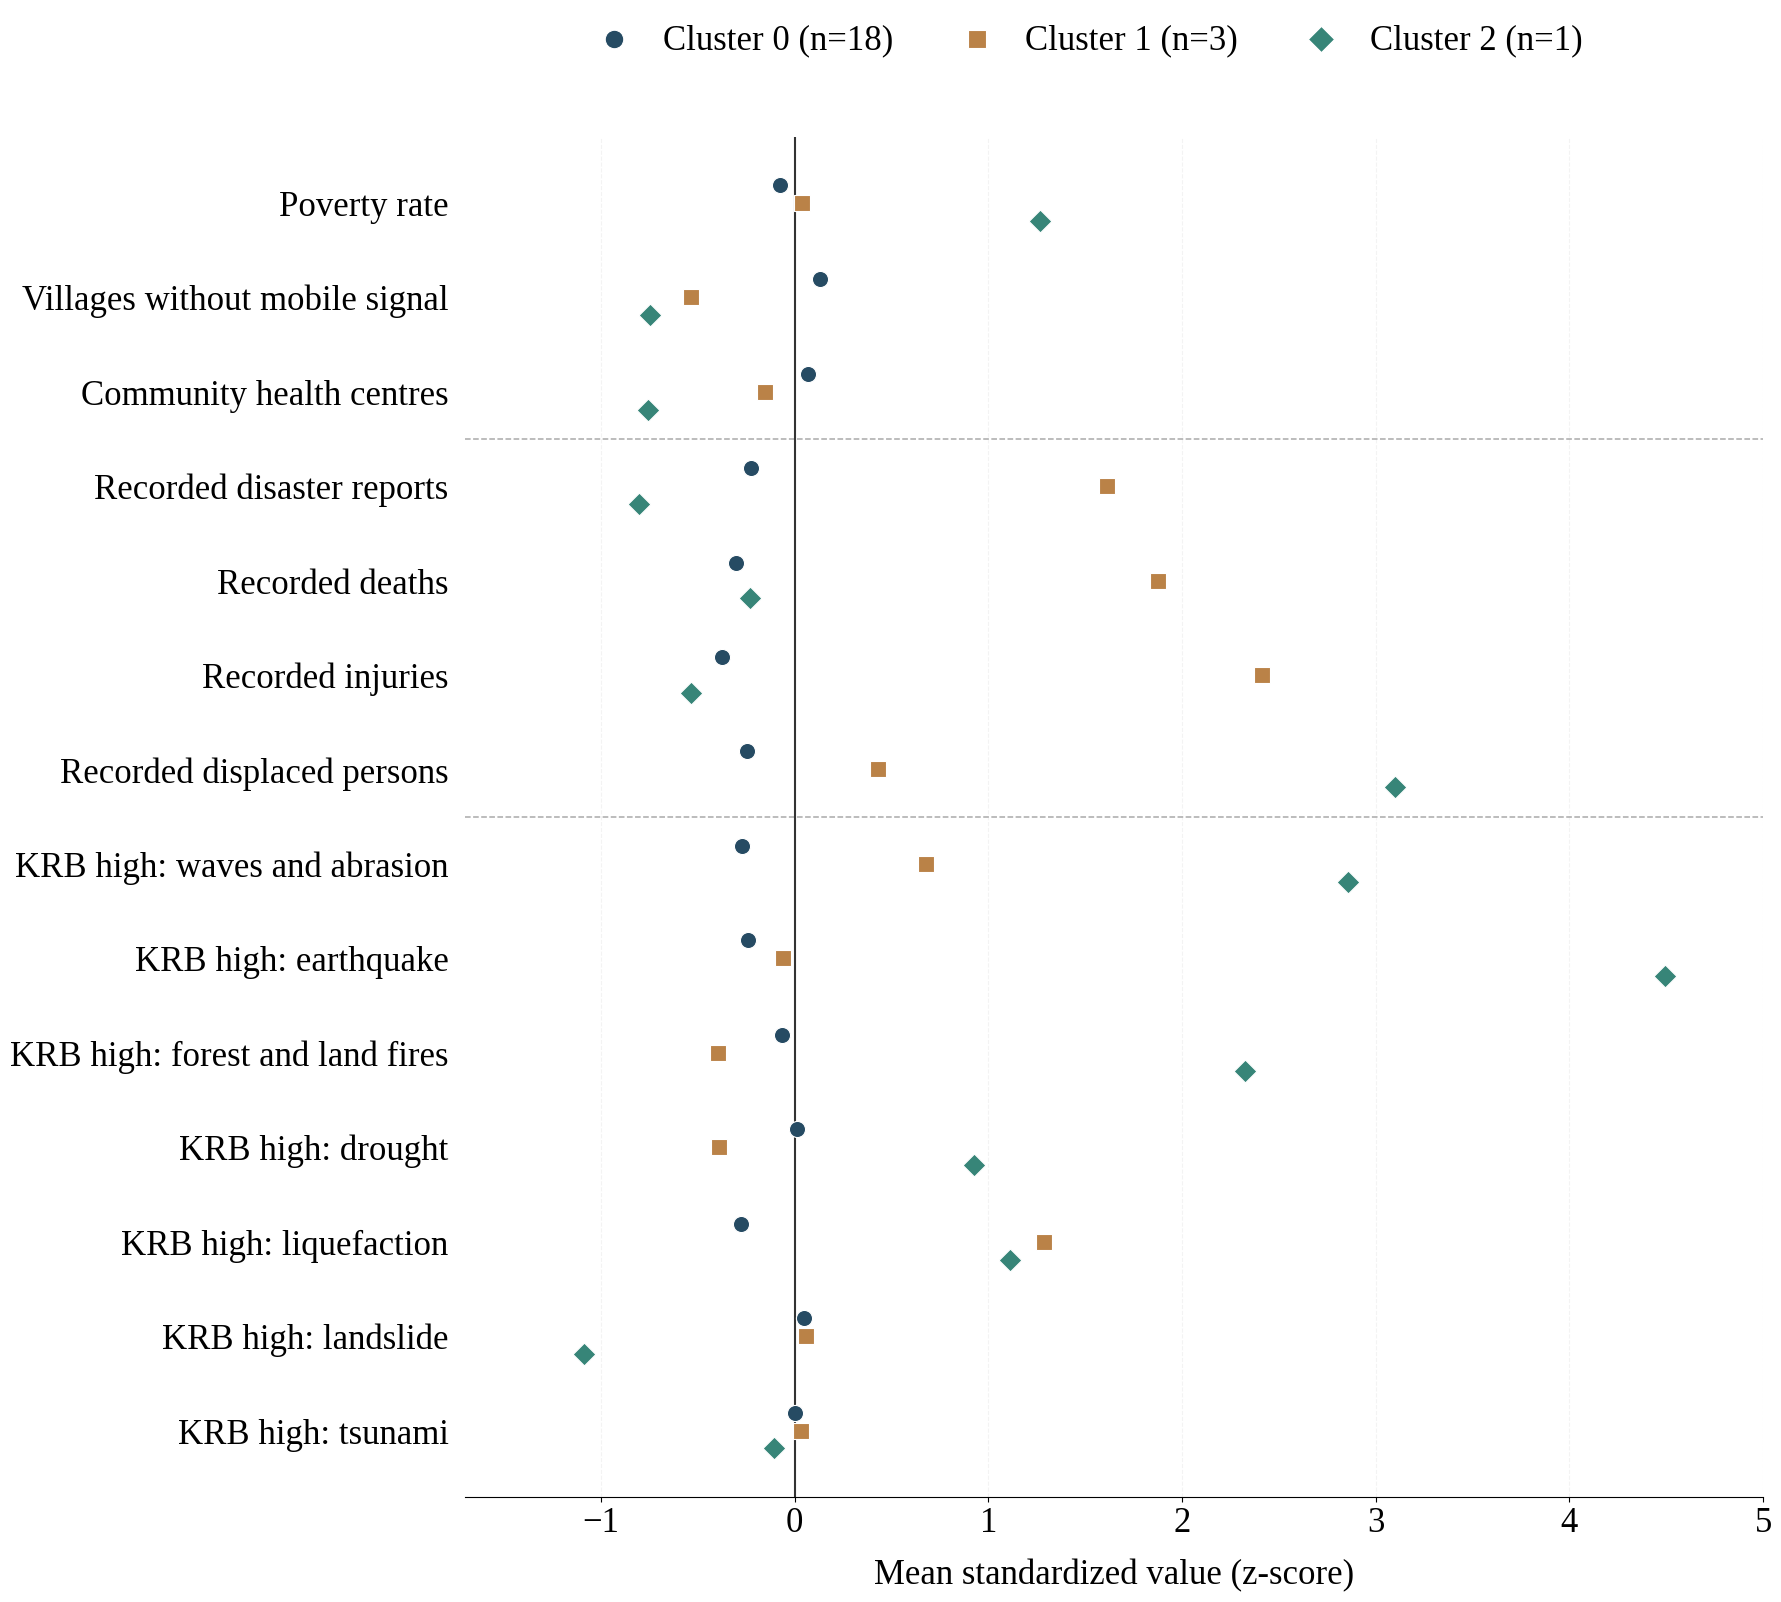


G.6.C SELESAI
Grafik: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Seleksi_Model_G6/G6C_DotPlot_Profil_Cluster_PAM_k3.png
Tabel : /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Seleksi_Model_G6/G6C_Profil_Individual_dan_DotPlot.xlsx

Model utama  : PAM k=3
Indikator   : 14
Wilayah     : 22
Visualisasi : Horizontal dot plot
Font        : Liberation Serif, 25 pt
Resolusi    : 300 DPI

Tidak ada perubahan keanggotaan cluster.


In [ ]:
# ============================================================
# G.6.C — PROFIL INDIVIDUAL DAN VISUALISASI TIPOLOGI
#
# Model     : K-Medoids PAM, k=3
# Data asli : INTI_G
# Z-score   : STANDAR_G
# Cluster   : LABEL_PAM_G2B[3]
#
# Dasar analisis:
# - Jain & Dubes (1988): interpretasi struktur cluster
# - Kaufman & Rousseeuw (1990): PAM dan medoid
# - Rogel-Salazar (2017): clustering dan standardisasi
#
# Visualisasi:
# Horizontal dot plot
# Liberation Serif, fontsize 25
# Tanpa judul, 300 DPI
#
# Tidak melakukan fitting ulang.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display


# ============================================================
# G.6.C.1 — VALIDASI INPUT
# ============================================================

objek_wajib = [
    "INTI_G",
    "STANDAR_G",
    "LABEL_PAM_G2B"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"Objek {nama} belum tersedia."
    )

assert 3 in LABEL_PAM_G2B

ASLI_G6C = INTI_G.copy()
Z_G6C = STANDAR_G.copy()

assert ASLI_G6C.shape == (22, 14)
assert Z_G6C.shape == (22, 14)

assert ASLI_G6C.index.equals(Z_G6C.index)
assert ASLI_G6C.columns.equals(Z_G6C.columns)

assert np.isfinite(
    ASLI_G6C.to_numpy(dtype=float)
).all()

assert np.isfinite(
    Z_G6C.to_numpy(dtype=float)
).all()

LABEL_G6C = (
    LABEL_PAM_G2B[3]
    .reindex(ASLI_G6C.index)
    .astype(int)
)

assert sorted(LABEL_G6C.unique()) == [0, 1, 2]

assert (
    LABEL_G6C.value_counts()
    .sort_index()
    .tolist()
) == [18, 3, 1]


# ============================================================
# G.6.C.2 — IDENTITAS INDIKATOR
# ============================================================

KELOMPOK_G6C = {
    "BPS": list(ASLI_G6C.columns[:3]),
    "BNPB": list(ASLI_G6C.columns[3:7]),
    "KRB": list(ASLI_G6C.columns[7:14])
}

PETA_KELOMPOK_G6C = {
    fitur: kelompok
    for kelompok, daftar in KELOMPOK_G6C.items()
    for fitur in daftar
}

FITUR_G6C = list(ASLI_G6C.columns)

assert set(PETA_KELOMPOK_G6C) == set(FITUR_G6C)


# ============================================================
# G.6.C.3 — ANGGOTA CLUSTER 1
# ============================================================

ANGGOTA_C1_G6C = LABEL_G6C.index[
    LABEL_G6C == 1
].tolist()

assert set(ANGGOTA_C1_G6C) == {
    "Lembata",
    "Flores Timur",
    "Rote Ndao"
}

# Urutan tetap untuk tabel artikel.
ANGGOTA_C1_G6C = [
    "Lembata",
    "Flores Timur",
    "Rote Ndao"
]

print("=" * 72)
print("G.6.C — PEMERIKSAAN PROFIL CLUSTER")
print("=" * 72)

print("\nAnggota Cluster 1:")
for wilayah in ANGGOTA_C1_G6C:
    print("-", wilayah)


# ============================================================
# G.6.C.4 — NILAI ASLI KETIGA WILAYAH
# ============================================================

TABEL_ASLI_C1_G6C = pd.DataFrame({
    "kelompok": [
        PETA_KELOMPOK_G6C[f]
        for f in FITUR_G6C
    ],
    "indikator": FITUR_G6C
})

for wilayah in ANGGOTA_C1_G6C:

    TABEL_ASLI_C1_G6C[wilayah] = (
        ASLI_G6C.loc[
            wilayah, FITUR_G6C
        ].to_numpy(dtype=float)
    )

TABEL_ASLI_C1_G6C["Mean_C1"] = (
    ASLI_G6C.loc[
        ANGGOTA_C1_G6C, FITUR_G6C
    ]
    .mean(axis=0)
    .to_numpy()
)

TABEL_ASLI_C1_G6C["Median_C1"] = (
    ASLI_G6C.loc[
        ANGGOTA_C1_G6C, FITUR_G6C
    ]
    .median(axis=0)
    .to_numpy()
)

TABEL_ASLI_C1_G6C["Mean_22_wilayah"] = (
    ASLI_G6C[
        FITUR_G6C
    ]
    .mean(axis=0)
    .to_numpy()
)

print("\nA. NILAI ASLI TIGA ANGGOTA CLUSTER 1")

display(
    TABEL_ASLI_C1_G6C.round(4)
)


# ============================================================
# G.6.C.5 — PROFIL Z-SCORE INDIVIDUAL
# ============================================================

TABEL_Z_C1_G6C = pd.DataFrame({
    "kelompok": [
        PETA_KELOMPOK_G6C[f]
        for f in FITUR_G6C
    ],
    "indikator": FITUR_G6C
})

for wilayah in ANGGOTA_C1_G6C:

    TABEL_Z_C1_G6C[wilayah] = (
        Z_G6C.loc[
            wilayah, FITUR_G6C
        ].to_numpy(dtype=float)
    )

z_anggota = Z_G6C.loc[
    ANGGOTA_C1_G6C,
    FITUR_G6C
]

TABEL_Z_C1_G6C["Mean_Z_C1"] = (
    z_anggota.mean(axis=0).to_numpy()
)

# Rentang menunjukkan perbedaan nilai
# tertinggi dan terendah dalam cluster.
TABEL_Z_C1_G6C["Rentang_Z_C1"] = (
    z_anggota.max(axis=0)
    - z_anggota.min(axis=0)
).to_numpy()

# Berapa anggota C1 yang mempunyai z-score > 0.
# Nol merupakan rata-rata seluruh 22 wilayah.
TABEL_Z_C1_G6C[
    "Anggota_Z_di_atas_0"
] = (
    (z_anggota > 0)
    .sum(axis=0)
    .to_numpy(dtype=int)
)

print("\nB. Z-SCORE INDIVIDUAL CLUSTER 1")

display(
    TABEL_Z_C1_G6C.round(4)
)


# ============================================================
# G.6.C.6 — INDIKATOR DENGAN VARIASI TERBESAR
# ============================================================

VARIASI_C1_G6C = (
    TABEL_Z_C1_G6C
    .sort_values(
        "Rentang_Z_C1",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nC. INDIKATOR DENGAN PERBEDAAN")
print("   INDIVIDUAL TERBESAR PADA CLUSTER 1")

display(
    VARIASI_C1_G6C[
        [
            "kelompok",
            "indikator",
            "Lembata",
            "Flores Timur",
            "Rote Ndao",
            "Mean_Z_C1",
            "Rentang_Z_C1",
            "Anggota_Z_di_atas_0"
        ]
    ]
    .head(10)
    .round(4)
)

print(
    "\nCatatan: rentang z-score merupakan "
    "ukuran deskriptif, bukan uji signifikansi."
)


# ============================================================
# G.6.C.7 — PROFIL RATA-RATA Z-SCORE TIGA CLUSTER
# ============================================================

PROFIL_PLOT_G6C = (
    Z_G6C
    .groupby(LABEL_G6C)
    .mean()
    .T
    .loc[FITUR_G6C, [0, 1, 2]]
)

PROFIL_PLOT_G6C.columns = [
    "C0",
    "C1",
    "C2"
]

# Validasi terhadap profiling G.6.B.
if "PROFIL_Z_G6B" in globals():

    referensi = (
        PROFIL_Z_G6B
        .set_index("indikator")
        .loc[
            FITUR_G6C,
            ["Cluster_0", "Cluster_1", "Cluster_2"]
        ]
        .to_numpy(dtype=float)
    )

    assert np.allclose(
        PROFIL_PLOT_G6C.to_numpy(float),
        referensi,
        rtol=1e-9,
        atol=1e-8
    ), (
        "Profil z-score berbeda dari G.6.B."
    )

print("\nD. PROFIL Z-SCORE UNTUK VISUALISASI")

display(
    PROFIL_PLOT_G6C.round(4)
)


# ============================================================
# G.6.C.8 — LABEL INDIKATOR UNTUK ARTIKEL
# ============================================================

LABEL_INDIKATOR_G6C = {
    "persen_miskin_maret_2025":
        "Poverty rate",

    "persen_desa_tanpa_sinyal_2025":
        "Villages without mobile signal",

    "puskesmas_per_100rb_2025":
        "Community health centres",

    "laporan_per100rb_2021_2025":
        "Recorded disaster reports",

    "meninggal_per100rb_2021_2025":
        "Recorded deaths",

    "luka_per100rb_2021_2025":
        "Recorded injuries",

    "pengungsi_per100rb_2021_2025":
        "Recorded displaced persons",

    "krb_prop_tinggi_gelombang_abrasi":
        "KRB high: waves and abrasion",

    "krb_prop_tinggi_gempa_bumi":
        "KRB high: earthquake",

    "krb_prop_tinggi_karhutla":
        "KRB high: forest and land fires",

    "krb_prop_tinggi_kekeringan":
        "KRB high: drought",

    "krb_prop_tinggi_likuefaksi":
        "KRB high: liquefaction",

    "krb_prop_tinggi_tanah_longsor":
        "KRB high: landslide",

    "krb_prop_tinggi_tsunami":
        "KRB high: tsunami"
}

assert set(LABEL_INDIKATOR_G6C) == set(
    FITUR_G6C
)


# ============================================================
# G.6.C.9 — PENGATURAN VISUALISASI
# ============================================================

plt.rcParams.update({
    "font.family": "Liberation Serif",
    "font.size": 25,
    "axes.labelsize": 25,
    "xtick.labelsize": 25,
    "ytick.labelsize": 25,
    "legend.fontsize": 25,
    "savefig.dpi": 300
})


# ============================================================
# G.6.C.10 — HORIZONTAL DOT PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(22, 17)
)

posisi = np.arange(len(FITUR_G6C))

# Offset vertikal agar tiga titik pada indikator
# yang sama tidak saling menutupi.
konfigurasi_plot = [
    {
        "kolom": "C0",
        "offset": -0.19,
        "label": "Cluster 0 (n=18)",
        "warna": "#264B63",
        "marker": "o"
    },
    {
        "kolom": "C1",
        "offset": 0.00,
        "label": "Cluster 1 (n=3)",
        "warna": "#BA8247",
        "marker": "s"
    },
    {
        "kolom": "C2",
        "offset": 0.19,
        "label": "Cluster 2 (n=1)",
        "warna": "#378578",
        "marker": "D"
    }
]

for conf in konfigurasi_plot:

    ax.scatter(
        PROFIL_PLOT_G6C[
            conf["kolom"]
        ].to_numpy(dtype=float),
        posisi + conf["offset"],
        s=135,
        marker=conf["marker"],
        color=conf["warna"],
        edgecolors="white",
        linewidths=0.8,
        label=conf["label"],
        zorder=5
    )


# ============================================================
# G.6.C.11 — SUMBU DAN REFERENSI
# ============================================================

ax.set_yticks(posisi)

ax.set_yticklabels(
    [
        LABEL_INDIKATOR_G6C[f]
        for f in FITUR_G6C
    ],
    fontsize=25
)

ax.set_ylim(
    -0.7,
    len(FITUR_G6C) - 0.3
)

ax.invert_yaxis()

ax.set_xlabel(
    "Mean standardized value (z-score)",
    fontsize=25,
    labelpad=14
)

# Nilai nol adalah rata-rata seluruh wilayah.
ax.axvline(
    x=0,
    color="#333333",
    linewidth=1.5,
    zorder=3
)

# Rentang berdasarkan nilai aktual.
nilai_profil = PROFIL_PLOT_G6C.to_numpy(float)

batas_kiri = min(
    -1.25,
    np.floor(nilai_profil.min() * 2) / 2 - 0.2
)

batas_kanan = max(
    5.0,
    nilai_profil.max() + 0.3
)

ax.set_xlim(
    batas_kiri,
    batas_kanan
)

ax.grid(
    axis="x",
    alpha=0.15,
    linestyle="--",
    zorder=0
)

# Garis pemisah kelompok sumber:
# BPS = indikator 0–2
# BNPB = indikator 3–6
# KRB = indikator 7–13

for y_pemisah in [2.5, 6.5]:

    ax.axhline(
        y=y_pemisah,
        color="#AAAAAA",
        linewidth=1.1,
        linestyle="--",
        zorder=1
    )

ax.tick_params(
    axis="y",
    length=0,
    pad=12
)

ax.tick_params(
    axis="x",
    labelsize=25
)

for sisi in ["top", "right", "left"]:
    ax.spines[sisi].set_visible(False)


# ============================================================
# G.6.C.12 — LEGENDA DI LUAR AREA PLOT
# ============================================================

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.65, 0.985),
    ncol=3,
    frameon=False,
    fontsize=25,
    markerscale=1.15,
    columnspacing=1.4,
    handletextpad=0.4
)

fig.subplots_adjust(
    left=0.37,
    right=0.96,
    top=0.90,
    bottom=0.10
)


# ============================================================
# G.6.C.13 — SIMPAN VISUALISASI
# ============================================================

OUT_G6C = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_G_Artikel1_Baru/"
    "Seleksi_Model_G6"
)

OUT_G6C.mkdir(
    parents=True,
    exist_ok=True
)

FILE_PLOT_G6C = (
    OUT_G6C /
    "G6C_DotPlot_Profil_Cluster_PAM_k3.png"
)

fig.savefig(
    FILE_PLOT_G6C,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    pad_inches=0.15
)

plt.show()
plt.close(fig)


# ============================================================
# G.6.C.14 — SIMPAN TABEL DIAGNOSTIK
# ============================================================

FILE_TABEL_G6C = (
    OUT_G6C /
    "G6C_Profil_Individual_dan_DotPlot.xlsx"
)

with pd.ExcelWriter(
    FILE_TABEL_G6C,
    engine="openpyxl"
) as writer:

    TABEL_ASLI_C1_G6C.to_excel(
        writer,
        sheet_name="C1_Nilai_Asli",
        index=False
    )

    TABEL_Z_C1_G6C.to_excel(
        writer,
        sheet_name="C1_ZScore",
        index=False
    )

    VARIASI_C1_G6C.to_excel(
        writer,
        sheet_name="C1_Variasi",
        index=False
    )

    PROFIL_PLOT_G6C.to_excel(
        writer,
        sheet_name="Profil_Tiga_Cluster",
        index_label="indikator"
    )


print("\n" + "=" * 72)
print("G.6.C SELESAI")
print("=" * 72)

print("Grafik:", FILE_PLOT_G6C)
print("Tabel :", FILE_TABEL_G6C)

print("\nModel utama  : PAM k=3")
print("Indikator   : 14")
print("Wilayah     : 22")
print("Visualisasi : Horizontal dot plot")
print("Font        : Liberation Serif, 25 pt")
print("Resolusi    : 300 DPI")

print(
    "\nTidak ada perubahan keanggotaan cluster."
)

## Pemeriksaan heterogenitas 18 wilayah Cluster 0

In [ ]:
# ============================================================
# G.6.D — HETEROGENITAS INTERNAL CLUSTER 0
# Model utama: PAM k=3, baseline S1, Seimbang
#
# Tidak melakukan fitting ulang.
# Tidak membuat visualisasi.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. VALIDASI INPUT
# ------------------------------------------------------------

for nama in [
    "INTI_G",
    "STANDAR_G",
    "SEIMBANG_G",
    "LABEL_PAM_G2B",
    "MEDOID_PAM_G2B"
]:
    assert nama in globals(), f"Objek {nama} tidak tersedia."

assert 3 in LABEL_PAM_G2B
assert 3 in MEDOID_PAM_G2B

ASLI_G6D = INTI_G.copy()
Z_G6D = STANDAR_G.copy()
BAL_G6D = SEIMBANG_G.copy()

assert ASLI_G6D.shape == (22, 14)
assert Z_G6D.shape == (22, 14)
assert BAL_G6D.shape == (22, 14)

assert ASLI_G6D.index.equals(Z_G6D.index)
assert ASLI_G6D.index.equals(BAL_G6D.index)
assert ASLI_G6D.columns.equals(Z_G6D.columns)
assert ASLI_G6D.columns.equals(BAL_G6D.columns)

LABEL_G6D = (
    LABEL_PAM_G2B[3]
    .reindex(ASLI_G6D.index)
    .astype(int)
)

assert LABEL_G6D.notna().all()
assert sorted(LABEL_G6D.value_counts().tolist()) == [1, 3, 18]

# ------------------------------------------------------------
# 2. IDENTIFIKASI CLUSTER 0 DAN MEDOID
# ------------------------------------------------------------

WILAYAH_C0_G6D = LABEL_G6D.index[
    LABEL_G6D == 0
].tolist()

MEDOID_C0_G6D = MEDOID_PAM_G2B[3][0]

assert len(WILAYAH_C0_G6D) == 18
assert MEDOID_C0_G6D in WILAYAH_C0_G6D

C0_ASLI_G6D = ASLI_G6D.loc[WILAYAH_C0_G6D].copy()
C0_Z_G6D = Z_G6D.loc[WILAYAH_C0_G6D].copy()
C0_BAL_G6D = BAL_G6D.loc[WILAYAH_C0_G6D].copy()

FITUR_G6D = list(C0_ASLI_G6D.columns)

PETA_KELOMPOK_G6D = {
    fitur: kelompok
    for kelompok, daftar in {
        "BPS": FITUR_G6D[:3],
        "BNPB": FITUR_G6D[3:7],
        "KRB": FITUR_G6D[7:14]
    }.items()
    for fitur in daftar
}

# ------------------------------------------------------------
# 3. RINGKASAN HETEROGENITAS SETIAP INDIKATOR
# ------------------------------------------------------------

ringkasan = []

for fitur in FITUR_G6D:

    nilai = C0_ASLI_G6D[fitur]
    z = C0_Z_G6D[fitur]

    q1 = nilai.quantile(0.25)
    q3 = nilai.quantile(0.75)

    maksimum = nilai.max()
    minimum = nilai.min()

    wilayah_maks = nilai.index[
        np.isclose(nilai.to_numpy(float), maksimum)
    ].tolist()

    wilayah_min = nilai.index[
        np.isclose(nilai.to_numpy(float), minimum)
    ].tolist()

    ringkasan.append({
        "kelompok": PETA_KELOMPOK_G6D[fitur],
        "indikator": fitur,
        "n": len(nilai),
        "mean_asli": nilai.mean(),
        "median_asli": nilai.median(),
        "sd_asli": nilai.std(ddof=1),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
        "minimum": minimum,
        "maksimum": maksimum,
        "rentang_asli": maksimum - minimum,
        "mean_z": z.mean(),
        "min_z": z.min(),
        "max_z": z.max(),
        "rentang_z": z.max() - z.min(),
        "n_z_positif": int((z > 0).sum()),
        "n_z_diatas_1": int((z > 1).sum()),
        "wilayah_maksimum": ", ".join(wilayah_maks),
        "wilayah_minimum": ", ".join(wilayah_min)
    })

RINGKASAN_C0_G6D = pd.DataFrame(ringkasan)

print("=" * 72)
print("G.6.D — HETEROGENITAS INTERNAL CLUSTER 0")
print("=" * 72)

print("Jumlah wilayah:", len(WILAYAH_C0_G6D))
print("Medoid:", MEDOID_C0_G6D)

print("\nA. RINGKASAN INDIKATOR CLUSTER 0")

display(
    RINGKASAN_C0_G6D[
        [
            "kelompok", "indikator",
            "mean_asli", "median_asli",
            "Q1", "Q3", "IQR",
            "minimum", "maksimum",
            "mean_z", "rentang_z",
            "n_z_positif", "n_z_diatas_1"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 4. WILAYAH DENGAN NILAI EKSTREM PER INDIKATOR
# ------------------------------------------------------------

EKSTREM_C0_G6D = RINGKASAN_C0_G6D[
    [
        "kelompok", "indikator",
        "minimum", "wilayah_minimum",
        "maksimum", "wilayah_maksimum"
    ]
].copy()

print("\nB. WILAYAH NILAI MINIMUM DAN MAKSIMUM")

display(EKSTREM_C0_G6D.round(4))

# ------------------------------------------------------------
# 5. JARAK SETIAP WILAYAH TERHADAP MEDOID C0
# ------------------------------------------------------------

# Jarak Euclidean dalam ruang Seimbang yang sama
# dengan ruang pembentukan cluster PAM.

vektor_medoid = BAL_G6D.loc[
    MEDOID_C0_G6D
].to_numpy(dtype=float)

matriks_c0 = C0_BAL_G6D.to_numpy(dtype=float)

jarak = np.linalg.norm(
    matriks_c0 - vektor_medoid,
    axis=1
)

JARAK_MEDOID_C0_G6D = (
    pd.DataFrame({
        "kabupaten_kota": WILAYAH_C0_G6D,
        "jarak_ke_medoid": jarak,
        "medoid": MEDOID_C0_G6D
    })
    .sort_values(
        "jarak_ke_medoid",
        ascending=False
    )
    .reset_index(drop=True)
)

assert np.isclose(
    JARAK_MEDOID_C0_G6D.loc[
        JARAK_MEDOID_C0_G6D["kabupaten_kota"]
        == MEDOID_C0_G6D,
        "jarak_ke_medoid"
    ].iloc[0],
    0.0
)

print("\nC. JARAK ANGGOTA CLUSTER 0 KE MEDOID")

display(JARAK_MEDOID_C0_G6D.round(4))

# ------------------------------------------------------------
# 6. NILAI INDIVIDUAL SELURUH 18 WILAYAH
# ------------------------------------------------------------

TABEL_INDIVIDUAL_C0_G6D = (
    C0_ASLI_G6D
    .reset_index()
    .rename(
        columns={
            "index": "kabupaten_kota"
        }
    )
)

TABEL_Z_C0_G6D = (
    C0_Z_G6D
    .reset_index()
    .rename(
        columns={
            "index": "kabupaten_kota"
        }
    )
)

print("\nD. NILAI ASLI SELURUH WILAYAH C0")
display(TABEL_INDIVIDUAL_C0_G6D.round(4))

print("\nE. Z-SCORE SELURUH WILAYAH C0")
display(TABEL_Z_C0_G6D.round(4))

# ------------------------------------------------------------
# 7. VALIDASI RATA-RATA TERHADAP G.6.B
# ------------------------------------------------------------

if "PROFIL_Z_G6B" in globals():

    profil_acuan = (
        PROFIL_Z_G6B
        .set_index("indikator")
        .loc[FITUR_G6D, "Cluster_0"]
        .to_numpy(dtype=float)
    )

    assert np.allclose(
        C0_Z_G6D.mean().to_numpy(float),
        profil_acuan,
        atol=1e-8,
        rtol=1e-8
    )

    print("\nValidasi: rata-rata profil C0 sesuai G.6.B.")

# ------------------------------------------------------------
# 8. SIMPAN OUTPUT
# ------------------------------------------------------------

OUT_G6D = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_G_Artikel1_Baru/"
    "Seleksi_Model_G6"
)

OUT_G6D.mkdir(parents=True, exist_ok=True)

FILE_G6D = (
    OUT_G6D /
    "G6D_Heterogenitas_Internal_Cluster0.xlsx"
)

with pd.ExcelWriter(
    FILE_G6D,
    engine="openpyxl"
) as writer:

    RINGKASAN_C0_G6D.to_excel(
        writer,
        sheet_name="Ringkasan_Indikator",
        index=False
    )

    EKSTREM_C0_G6D.to_excel(
        writer,
        sheet_name="Wilayah_Ekstrem",
        index=False
    )

    JARAK_MEDOID_C0_G6D.to_excel(
        writer,
        sheet_name="Jarak_Medoid",
        index=False
    )

    TABEL_INDIVIDUAL_C0_G6D.to_excel(
        writer,
        sheet_name="Nilai_Asli_C0",
        index=False
    )

    TABEL_Z_C0_G6D.to_excel(
        writer,
        sheet_name="ZScore_C0",
        index=False
    )

print("\n" + "=" * 72)
print("G.6.D SELESAI")
print("=" * 72)
print("File:", FILE_G6D)
print("Tidak ada fitting ulang.")
print("Tidak ada visualisasi baru.")

G.6.D — HETEROGENITAS INTERNAL CLUSTER 0
Jumlah wilayah: 18
Medoid: Timor Tengah Utara

A. RINGKASAN INDIKATOR CLUSTER 0


,kelompok,indikator,mean_asli,median_asli,Q1,Q3,IQR,minimum,maksimum,mean_z,rentang_z,n_z_positif,n_z_diatas_1
0,BPS,persen_miskin_maret_2025,18.7678,19.2300,12.9725,24.2525,11.2800,7.5700,29.2300,-0.0772,3.4591,9,4
1,BPS,persen_desa_tanpa_sinyal_2025,1.1530,0.7194,0.0000,1.4075,1.4075,0.0000,4.6154,0.1302,3.5058,7,3
2,BPS,puskesmas_per_100rb_2025,8.2219,8.3541,6.8542,9.5376,2.6835,2.4859,13.6008,0.0677,4.6052,9,3
3,BNPB,laporan_per100rb_2021_2025,1.2620,0.9767,0.7323,1.2760,0.5437,0.4173,3.7038,-0.2240,2.9835,4,1
4,BNPB,meninggal_per100rb_2021_2025,0.5017,0.2326,0.0711,0.7400,0.6689,0.0000,2.6258,-0.3004,1.5227,3,0
5,BNPB,luka_per100rb_2021_2025,0.4835,0.0796,0.0000,0.3533,0.3533,0.0000,2.7133,-0.3727,0.9144,3,0
6,BNPB,pengungsi_per100rb_2021_2025,2668.8970,534.4573,115.7373,4046.4162,3930.6789,54.6647,13843.3260,-0.2441,2.7865,5,1
7,KRB,krb_prop_tinggi_gelombang_abrasi,14.2426,4.5685,1.1134,20.5666,19.4532,0.0000,68.9751,-0.2721,2.6450,5,1
8,KRB,krb_prop_tinggi_gempa_bumi,2.3315,0.3063,0.0797,4.0837,4.0040,0.0000,8.6803,-0.2394,0.4208,3,0
9,KRB,krb_prop_tinggi_karhutla,10.7130,4.8307,2.3747,12.0427,9.6680,0.0000,43.7695,-0.0637,3.1285,5,3



B. WILAYAH NILAI MINIMUM DAN MAKSIMUM


,kelompok,indikator,minimum,wilayah_minimum,maksimum,wilayah_maksimum
0,BPS,persen_miskin_maret_2025,7.5700,Kota Kupang,29.2300,Sumba Tengah
1,BPS,persen_desa_tanpa_sinyal_2025,0.0000,"Sumba Barat, Belu, Alor, Manggarai, Sumba Bara...",4.6154,Sumba Tengah
2,BPS,puskesmas_per_100rb_2025,2.4859,Kota Kupang,13.6008,Ngada
3,BNPB,laporan_per100rb_2021_2025,0.4173,Sumba Barat Daya,3.7038,Kupang
4,BNPB,meninggal_per100rb_2021_2025,0.0000,"Sumba Barat, Manggarai, Sumba Tengah",2.6258,Alor
5,BNPB,luka_per100rb_2021_2025,0.0000,"Sumba Barat, Timor Tengah Selatan, Timor Tenga...",2.7133,Alor
6,BNPB,pengungsi_per100rb_2021_2025,54.6647,Sumba Barat Daya,13843.3260,Alor
7,KRB,krb_prop_tinggi_gelombang_abrasi,0.0000,"Timor Tengah Utara, Ngada, Sumba Barat Daya",68.9751,Alor
8,KRB,krb_prop_tinggi_gempa_bumi,0.0000,"Sumba Barat, Belu, Ende, Kota Kupang",8.6803,Alor
9,KRB,krb_prop_tinggi_karhutla,0.0000,Kota Kupang,43.7695,Sumba Timur



C. JARAK ANGGOTA CLUSTER 0 KE MEDOID


...


D. NILAI ASLI SELURUH WILAYAH C0


,kabupaten_kota,persen_miskin_maret_2025,persen_desa_tanpa_sinyal_2025,puskesmas_per_100rb_2025,laporan_per100rb_2021_2025,meninggal_per100rb_2021_2025,luka_per100rb_2021_2025,pengungsi_per100rb_2021_2025,krb_prop_tinggi_gelombang_abrasi,krb_prop_tinggi_gempa_bumi,krb_prop_tinggi_karhutla,krb_prop_tinggi_kekeringan,krb_prop_tinggi_likuefaksi,krb_prop_tinggi_tanah_longsor,krb_prop_tinggi_tsunami
0,Sumba Barat,26.47,0.0000,6.3452,0.8883,0.0000,0.0000,278.6802,21.5719,0.0000,5.2073,79.2279,6.6254,0.1370,81.0345
1,Sumba Timur,25.64,1.5000,9.1262,1.2929,0.1521,0.0761,8442.0108,17.5508,8.3447,43.7695,0.0000,5.7493,1.4017,53.7827
2,Kupang,20.32,1.1299,6.7816,3.7038,1.3042,1.6172,2893.3462,10.1263,0.1420,2.2251,100.0000,4.0901,2.5579,77.9665
3,Timor Tengah Selatan,24.50,0.7194,7.5820,0.6148,0.0820,0.0000,452.3361,1.2076,0.1267,2.2376,100.0000,18.4305,7.1082,68.5579
4,Timor Tengah Utara,20.17,1.0363,9.2977,0.8582,0.0715,0.0000,616.5785,0.0000,0.0640,4.4542,38.1292,5.9510,9.2623,94.9932
5,Belu,12.79,0.0000,7.0718,2.4959,0.4992,0.0832,1260.2022,2.5586,0.0000,0.2539,0.0000,1.8361,3.7836,97.2222
6,Alor,18.29,0.0000,12.2538,1.2254,2.6258,2.7133,13843.3260,68.9751,8.6803,6.6003,0.0000,8.2120,16.1582,89.7166
7,Sikka,11.25,2.0619,7.2397,1.1004,0.2896,0.0000,370.6128,23.9993,0.4494,2.7860,0.8565,6.1104,15.4633,86.6552
8,Ende,21.31,0.7194,9.1495,2.3929,0.9853,0.4223,2549.8821,41.9756,0.0000,4.3820,11.0781,7.0716,17.2673,85.0047
9,Ngada,11.22,4.3689,13.6008,1.9268,0.2267,0.3400,107.6731,0.0000,2.3446,19.9759,100.0000,0.5393,5.4970,99.5665



E. Z-SCORE SELURUH WILAYAH C0


,kabupaten_kota,persen_miskin_maret_2025,persen_desa_tanpa_sinyal_2025,puskesmas_per_100rb_2025,laporan_per100rb_2021_2025,meninggal_per100rb_2021_2025,luka_per100rb_2021_2025,pengungsi_per100rb_2021_2025,krb_prop_tinggi_gelombang_abrasi,krb_prop_tinggi_gempa_bumi,krb_prop_tinggi_karhutla,krb_prop_tinggi_kekeringan,krb_prop_tinggi_likuefaksi,krb_prop_tinggi_tanah_longsor,krb_prop_tinggi_tsunami
0,Sumba Barat,1.1529,-0.7456,-0.7099,-0.5632,-0.5913,-0.5356,-0.7271,0.0090,-0.3524,-0.4572,0.4602,-0.4542,-1.0648,-0.3332
1,Sumba Timur,1.0203,0.3938,0.4424,-0.1959,-0.5031,-0.5100,0.9226,-0.1452,0.0521,2.2991,-1.3223,-0.5857,-0.8402,-2.3367
2,Kupang,0.1707,0.1127,-0.5291,1.9927,0.1650,0.0094,-0.1987,-0.4299,-0.3455,-0.6704,0.9275,-0.8347,-0.6348,-0.5587
3,Timor Tengah Selatan,0.8383,-0.1991,-0.1975,-0.8115,-0.5437,-0.5356,-0.6920,-0.7719,-0.3463,-0.6695,0.9275,1.3178,0.1734,-1.2504
4,Timor Tengah Utara,0.1468,0.0416,0.5134,-0.5905,-0.5498,-0.5356,-0.6588,-0.8182,-0.3493,-0.5111,-0.4644,-0.5554,0.5560,0.6931
5,Belu,-1.0318,-0.7456,-0.4088,0.8962,-0.3018,-0.5076,-0.5288,-0.7201,-0.3524,-0.8113,-1.3223,-1.1730,-0.4171,0.8569
6,Alor,-0.1535,-0.7456,1.7382,-0.2572,0.9314,0.3788,2.0141,1.8268,0.0683,-0.3577,-1.3223,-0.2160,1.7808,0.3051
7,Sikka,-1.2778,0.8206,-0.3393,-0.3706,-0.4233,-0.5356,-0.7086,0.1021,-0.3306,-0.6303,-1.3030,-0.5315,1.6574,0.0801
8,Ende,0.3288,-0.1991,0.4520,0.8027,-0.0199,-0.3933,-0.2682,0.7914,-0.3524,-0.5162,-1.0730,-0.3872,1.9778,-0.0413
9,Ngada,-1.2825,2.5731,2.2963,0.3795,-0.4598,-0.4210,-0.7617,-0.8182,-0.2388,0.5984,0.9275,-1.3677,-0.1128,1.0293



Validasi: rata-rata profil C0 sesuai G.6.B.

G.6.D SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_G_Artikel1_Baru/Seleksi_Model_G6/G6D_Heterogenitas_Internal_Cluster0.xlsx
Tidak ada fitting ulang.
Tidak ada visualisasi baru.


# Multi-Criteria Analysis Decision

## Penyusunan matriks keputusan MCDA/WASPAS
Tujuan operasional tahap ini adalah:
Menyusun pemeringkatan indikatif prioritas relatif 22 kabupaten/kota di NTT untuk perhatian mitigasi multibahaya, berdasarkan kerentanan sosial, keterbatasan layanan, dampak bencana historis yang tercatat, dan karakteristik bahaya.

In [ ]:
# ============================================================
# H.1 — AUDIT MATRIKS KEPUTUSAN MCDA / WASPAS
#
# Alternatif : 22 kabupaten/kota NTT
# Kriteria   : 14 indikator F6C_Inti
# Baseline   : S1, BNPB 2021–2025
#
# Normalisasi:
# Guo & Matsuda (2023), Equation (8)
#
# Belum menghitung skor WASPAS atau peringkat.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# H.1.1 — DEFINISI 14 KRITERIA
# ------------------------------------------------------------

SPESIFIKASI_H1 = [
    # Indikator, kelompok, arah
    ("persen_miskin_maret_2025", "BPS", "Benefit"),
    ("persen_desa_tanpa_sinyal_2025", "BPS", "Benefit"),
    ("puskesmas_per_100rb_2025", "BPS", "Cost"),

    ("laporan_per100rb_2021_2025", "BNPB", "Benefit"),
    ("meninggal_per100rb_2021_2025", "BNPB", "Benefit"),
    ("luka_per100rb_2021_2025", "BNPB", "Benefit"),
    ("pengungsi_per100rb_2021_2025", "BNPB", "Benefit"),

    ("krb_prop_tinggi_gelombang_abrasi", "KRB", "Benefit"),
    ("krb_prop_tinggi_gempa_bumi", "KRB", "Benefit"),
    ("krb_prop_tinggi_karhutla", "KRB", "Benefit"),
    ("krb_prop_tinggi_kekeringan", "KRB", "Benefit"),
    ("krb_prop_tinggi_likuefaksi", "KRB", "Benefit"),
    ("krb_prop_tinggi_tanah_longsor", "KRB", "Benefit"),
    ("krb_prop_tinggi_tsunami", "KRB", "Benefit")
]

KRITERIA_H1 = pd.DataFrame(
    SPESIFIKASI_H1,
    columns=["indikator", "kelompok", "arah"]
)

KRITERIA_H1.insert(
    0, "kode",
    [f"C{i:02d}" for i in range(1, 15)]
)

assert len(KRITERIA_H1) == 14
assert KRITERIA_H1["indikator"].is_unique


# ------------------------------------------------------------
# H.1.2 — MEMBANGUN MATRIKS KEPUTUSAN
# ------------------------------------------------------------

assert "INTI_G" in globals(), (
    "INTI_G belum tersedia dari tahap F6C/G."
)

FITUR_H1 = KRITERIA_H1["indikator"].tolist()

assert INTI_G.shape == (22, 14)
assert set(INTI_G.columns) == set(FITUR_H1)
assert INTI_G.index.is_unique
assert INTI_G.index.notna().all()

# Pengurutan eksplisit, tidak mengubah nilai.
MATRIKS_KEPUTUSAN_H1 = (
    INTI_G.loc[:, FITUR_H1].copy()
)

assert np.isfinite(
    MATRIKS_KEPUTUSAN_H1.to_numpy(float)
).all()

assert (
    MATRIKS_KEPUTUSAN_H1.to_numpy(float) >= 0
).all()

assert len(MATRIKS_KEPUTUSAN_H1) == 22

# BPS persentase dan seluruh KRB diasumsikan
# menggunakan skala 0–100 sesuai F6C.
FITUR_PERSEN_H1 = [
    "persen_miskin_maret_2025",
    "persen_desa_tanpa_sinyal_2025",
] + KRITERIA_H1.loc[
    KRITERIA_H1["kelompok"] == "KRB",
    "indikator"
].tolist()

for fitur in FITUR_PERSEN_H1:
    nilai = MATRIKS_KEPUTUSAN_H1[fitur]
    assert nilai.between(0, 100).all(), (
        f"Periksa skala persentase: {fitur}"
    )

print("=" * 72)
print("H.1 — VALIDASI MATRIKS KEPUTUSAN")
print("=" * 72)
print("Jumlah alternatif :", MATRIKS_KEPUTUSAN_H1.shape[0])
print("Jumlah kriteria   :", MATRIKS_KEPUTUSAN_H1.shape[1])
print("Missing value     :",
      MATRIKS_KEPUTUSAN_H1.isna().sum().sum())


# ------------------------------------------------------------
# H.1.3 — AUDIT DISTRIBUSI DAN NILAI NOL
# ------------------------------------------------------------

AUDIT_H1 = []

for _, baris in KRITERIA_H1.iterrows():

    fitur = baris["indikator"]
    nilai = MATRIKS_KEPUTUSAN_H1[fitur].astype(float)

    AUDIT_H1.append({
        "kode": baris["kode"],
        "kelompok": baris["kelompok"],
        "indikator": fitur,
        "arah": baris["arah"],
        "minimum": nilai.min(),
        "Q1": nilai.quantile(0.25),
        "median": nilai.median(),
        "mean": nilai.mean(),
        "Q3": nilai.quantile(0.75),
        "maksimum": nilai.max(),
        "rentang": nilai.max() - nilai.min(),
        "n_nol": int((nilai == 0).sum()),
        "n_nilai_100": int((nilai == 100).sum()),
        "n_unik": nilai.nunique()
    })

AUDIT_KRITERIA_H1 = pd.DataFrame(AUDIT_H1)

# Normalisasi min–max tidak didefinisikan
# jika seluruh alternatif memiliki nilai sama.
KRITERIA_KONSTAN_H1 = AUDIT_KRITERIA_H1.loc[
    AUDIT_KRITERIA_H1["rentang"] <= 0,
    "indikator"
].tolist()

assert not KRITERIA_KONSTAN_H1, (
    "Terdapat kriteria konstan: "
    + str(KRITERIA_KONSTAN_H1)
)

print("\nA. AUDIT SELURUH KRITERIA")
display(AUDIT_KRITERIA_H1.round(4))

print("\nB. KRITERIA YANG MENGANDUNG NOL")
display(
    AUDIT_KRITERIA_H1.loc[
        AUDIT_KRITERIA_H1["n_nol"] > 0,
        ["kode", "indikator", "n_nol"]
    ]
)


# ------------------------------------------------------------
# H.1.4 — BOBOT SETARA ANTARKELOMPOK
# ------------------------------------------------------------

BOBOT_KELOMPOK_H1 = {
    "BPS": 1 / 3,
    "BNPB": 1 / 3,
    "KRB": 1 / 3
}

JUMLAH_FITUR_H1 = (
    KRITERIA_H1["kelompok"]
    .value_counts()
    .to_dict()
)

assert JUMLAH_FITUR_H1 == {
    "BPS": 3,
    "BNPB": 4,
    "KRB": 7
}

KRITERIA_H1["bobot_kelompok"] = (
    KRITERIA_H1["kelompok"]
    .map(BOBOT_KELOMPOK_H1)
)

KRITERIA_H1["bobot_indikator"] = (
    KRITERIA_H1["bobot_kelompok"]
    / KRITERIA_H1["kelompok"].map(JUMLAH_FITUR_H1)
)

assert np.isclose(
    KRITERIA_H1["bobot_indikator"].sum(),
    1.0
)

JUMLAH_BOBOT_H1 = (
    KRITERIA_H1.groupby("kelompok")[
        "bobot_indikator"
    ].sum()
)

assert np.allclose(
    JUMLAH_BOBOT_H1.to_numpy(float),
    np.full(3, 1 / 3)
)

print("\nC. SPESIFIKASI KRITERIA DAN BOBOT")
display(KRITERIA_H1.round(6))

print("\nD. VERIFIKASI JUMLAH BOBOT PER KELOMPOK")
display(JUMLAH_BOBOT_H1.to_frame("total_bobot"))


# ------------------------------------------------------------
# H.1.5 — NORMALISASI GUO & MATSUDA (2023)
#
# Benefit: 1 + (x - min) / (max - min)
# Cost   : 1 + (max - x) / (max - min)
#
# Hasil setiap kriteria berada pada [1, 2].
# ------------------------------------------------------------

MATRIKS_NORMAL_H1 = pd.DataFrame(
    index=MATRIKS_KEPUTUSAN_H1.index,
    columns=FITUR_H1,
    dtype=float
)

for _, baris in KRITERIA_H1.iterrows():

    fitur = baris["indikator"]
    arah = baris["arah"]

    x = MATRIKS_KEPUTUSAN_H1[fitur].astype(float)

    minimum = float(x.min())
    maksimum = float(x.max())
    rentang = maksimum - minimum

    assert rentang > 0

    if arah == "Benefit":
        nilai_normal = 1 + (x - minimum) / rentang

    elif arah == "Cost":
        nilai_normal = 1 + (maksimum - x) / rentang

    else:
        raise ValueError(
            f"Arah kriteria tidak dikenal: {arah}"
        )

    MATRIKS_NORMAL_H1[fitur] = nilai_normal


# ------------------------------------------------------------
# H.1.6 — VALIDASI MATRIKS TERNORMALISASI
# ------------------------------------------------------------

N_H1 = MATRIKS_NORMAL_H1.to_numpy(dtype=float)

assert np.isfinite(N_H1).all()
assert (N_H1 >= 1 - 1e-12).all()
assert (N_H1 <= 2 + 1e-12).all()
assert (N_H1 > 0).all()

# Periksa orientasi minimum/maksimum.
for _, baris in KRITERIA_H1.iterrows():

    fitur = baris["indikator"]
    arah = baris["arah"]

    x = MATRIKS_KEPUTUSAN_H1[fitur]
    r = MATRIKS_NORMAL_H1[fitur]

    if arah == "Benefit":

        assert np.isclose(
            r.loc[x.idxmax()], 2.0
        )

        assert np.isclose(
            r.loc[x.idxmin()], 1.0
        )

    else:

        assert np.isclose(
            r.loc[x.idxmin()], 2.0
        )

        assert np.isclose(
            r.loc[x.idxmax()], 1.0
        )

print("\nE. VALIDASI NORMALISASI")
print("Nilai normalisasi minimum :", N_H1.min())
print("Nilai normalisasi maksimum:", N_H1.max())
print("Seluruh nilai positif     :", bool((N_H1 > 0).all()))
print("Seluruh arah benar        : True")

print("\nF. CONTOH MATRIKS NORMALISASI")
display(MATRIKS_NORMAL_H1.head().round(5))


# ------------------------------------------------------------
# H.1.7 — METADATA DAN CATATAN METODOLOGIS
# ------------------------------------------------------------

CATATAN_H1 = pd.DataFrame([
    {
        "aspek": "Tujuan",
        "keterangan": (
            "Peringkat indikatif prioritas relatif "
            "wilayah untuk perhatian mitigasi multibahaya"
        )
    },
    {
        "aspek": "Alternatif",
        "keterangan": "22 kabupaten/kota NTT"
    },
    {
        "aspek": "Baseline",
        "keterangan": "F6C_Inti, S1"
    },
    {
        "aspek": "Data BNPB",
        "keterangan": "Rerata tahunan 2021–2025 per 100.000 penduduk"
    },
    {
        "aspek": "Normalisasi",
        "keterangan": (
            "Guo dan Matsuda (2023), persamaan (8); "
            "nilai pada rentang 1–2"
        )
    },
    {
        "aspek": "Bobot",
        "keterangan": (
            "Equal group weighting; "
            "bukan bobot hasil AHP atau survei ahli"
        )
    },
    {
        "aspek": "Puskesmas",
        "keterangan": (
            "Cost criterion sebagai proksi "
            "ketersediaan layanan relatif"
        )
    },
    {
        "aspek": "KRB",
        "keterangan": (
            "Proporsi kelas bahaya tinggi sesuai "
            "penyebut data sumber; tidak otomatis "
            "proporsi luas administratif"
        )
    },
    {
        "aspek": "Batasan",
        "keterangan": (
            "Bukan indeks risiko resmi, bukan "
            "ukuran kesiapsiagaan atau biaya mitigasi"
        )
    }
])


# ------------------------------------------------------------
# H.1.8 — SIMPAN OUTPUT DIAGNOSTIK
# ------------------------------------------------------------

OUT_H1 = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H1_Matriks_Keputusan"
)

OUT_H1.mkdir(parents=True, exist_ok=True)

FILE_H1 = (
    OUT_H1 / "H1_Audit_Matriks_Keputusan_WASPAS.xlsx"
)

with pd.ExcelWriter(
    FILE_H1,
    engine="openpyxl"
) as writer:

    MATRIKS_KEPUTUSAN_H1.to_excel(
        writer,
        sheet_name="Matriks_Asli",
        index_label="kabupaten_kota"
    )

    KRITERIA_H1.to_excel(
        writer,
        sheet_name="Kriteria_Bobot",
        index=False
    )

    AUDIT_KRITERIA_H1.to_excel(
        writer,
        sheet_name="Audit_Kriteria",
        index=False
    )

    MATRIKS_NORMAL_H1.to_excel(
        writer,
        sheet_name="Matriks_Normal",
        index_label="kabupaten_kota"
    )

    CATATAN_H1.to_excel(
        writer,
        sheet_name="Catatan_Metode",
        index=False
    )

print("\n" + "=" * 72)
print("H.1 SELESAI")
print("=" * 72)

print("File:", FILE_H1)
print("Alternatif :", len(MATRIKS_KEPUTUSAN_H1))
print("Kriteria   :", len(KRITERIA_H1))
print("Total bobot:", KRITERIA_H1["bobot_indikator"].sum())

print(
    "\nBelum menghitung WSM, WPM, "
    "skor WASPAS, atau peringkat."
)

H.1 — VALIDASI MATRIKS KEPUTUSAN
Jumlah alternatif : 22
Jumlah kriteria   : 14
Missing value     : 0

A. AUDIT SELURUH KRITERIA


,kode,kelompok,indikator,arah,minimum,Q1,median,mean,Q3,maksimum,rentang,n_nol,n_nilai_100,n_unik
0,C01,BPS,persen_miskin_maret_2025,Benefit,7.5700,12.9725,20.2450,19.2509,24.4675,29.2300,21.6600,0,0,22
1,C02,BPS,persen_desa_tanpa_sinyal_2025,Benefit,0.0000,0.0000,0.6556,0.9815,1.1065,4.6154,4.6154,9,0,13
2,C03,BPS,puskesmas_per_100rb_2025,Cost,2.4859,6.8542,7.6527,8.0585,9.2808,13.6008,11.1150,0,0,22
3,C04,BNPB,laporan_per100rb_2021_2025,Benefit,0.4173,0.7323,1.0827,1.5087,1.9168,4.2479,3.8306,0,0,22
4,C05,BNPB,meninggal_per100rb_2021_2025,Benefit,0.0000,0.0741,0.3312,1.0196,0.9441,6.3330,6.3330,3,0,20
5,C06,BNPB,luka_per100rb_2021_2025,Benefit,0.0000,0.0000,0.1037,1.5894,1.3184,9.5256,9.5256,8,0,15
6,C07,BNPB,pengungsi_per100rb_2021_2025,Benefit,54.6647,174.6175,1905.0421,3876.8310,6740.2569,19203.8230,19149.1583,0,0,22
7,C08,KRB,krb_prop_tinggi_gelombang_abrasi,Benefit,0.0000,1.2167,10.2389,21.3375,36.4410,95.8964,95.8964,3,0,20
8,C09,KRB,krb_prop_tinggi_gempa_bumi,Benefit,0.0000,0.0797,1.0466,7.2707,5.7116,100.0000,100.0000,5,1,18
9,C10,KRB,krb_prop_tinggi_karhutla,Benefit,0.0000,2.9247,5.3315,11.6041,12.5097,44.1720,44.1720,1,0,22



B. KRITERIA YANG MENGANDUNG NOL


,kode,indikator,n_nol
1,C02,persen_desa_tanpa_sinyal_2025,9
4,C05,meninggal_per100rb_2021_2025,3
5,C06,luka_per100rb_2021_2025,8
7,C08,krb_prop_tinggi_gelombang_abrasi,3
8,C09,krb_prop_tinggi_gempa_bumi,5
9,C10,krb_prop_tinggi_karhutla,1
10,C11,krb_prop_tinggi_kekeringan,3
12,C13,krb_prop_tinggi_tanah_longsor,4



C. SPESIFIKASI KRITERIA DAN BOBOT


...


D. VERIFIKASI JUMLAH BOBOT PER KELOMPOK


,total_bobot
kelompok,
BNPB,0.333333
BPS,0.333333
KRB,0.333333



E. VALIDASI NORMALISASI
Nilai normalisasi minimum : 1.0
Nilai normalisasi maksimum: 2.0
Seluruh nilai positif     : True
Seluruh arah benar        : True

F. CONTOH MATRIKS NORMALISASI


,persen_miskin_maret_2025,persen_desa_tanpa_sinyal_2025,puskesmas_per_100rb_2025,laporan_per100rb_2021_2025,meninggal_per100rb_2021_2025,luka_per100rb_2021_2025,pengungsi_per100rb_2021_2025,krb_prop_tinggi_gelombang_abrasi,krb_prop_tinggi_gempa_bumi,krb_prop_tinggi_karhutla,krb_prop_tinggi_kekeringan,krb_prop_tinggi_likuefaksi,krb_prop_tinggi_tanah_longsor,krb_prop_tinggi_tsunami
kabupaten_kota,,,,,,,,,,,,,,
Sumba Barat,1.87258,1.00000,1.65278,1.12297,1.00000,1.00000,1.01170,1.22495,1.00000,1.11789,1.79228,1.27257,1.00794,1.65032
Sumba Timur,1.83426,1.32500,1.40258,1.22857,1.02402,1.00798,1.43800,1.18302,1.08345,1.99089,1.00000,1.23333,1.08117,1.13610
Kupang,1.58864,1.24482,1.61352,1.85795,1.20593,1.16977,1.14824,1.10560,1.00142,1.05037,2.00000,1.15902,1.14813,1.59243
Timor Tengah Selatan,1.78163,1.15588,1.54151,1.05155,1.01294,1.00000,1.02077,1.01259,1.00127,1.05066,2.00000,1.80126,1.41165,1.41489
Timor Tengah Utara,1.58172,1.22453,1.38715,1.11511,1.01129,1.00000,1.02934,1.00000,1.00064,1.10084,1.38129,1.24236,1.53640,1.91371



H.1 SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H1_Matriks_Keputusan/H1_Audit_Matriks_Keputusan_WASPAS.xlsx
Alternatif : 22
Kriteria   : 14
Total bobot: 1.0000000000000002

Belum menghitung WSM, WPM, skor WASPAS, atau peringkat.


## DIAGNOSTIK MULTIVARIAT KRITERIA MCDA

In [ ]:
# ============================================================
# H.1.B — DIAGNOSTIK MULTIVARIAT KRITERIA MCDA
#
# Mengikuti prinsip pemeriksaan multivariat,
# normalisasi, dan redundansi indikator OECD/JRC.
#
# Tidak mengubah data atau bobot.
# Tidak menghitung peringkat.
# ============================================================

import numpy as np
import pandas as pd
from itertools import combinations
from pathlib import Path
from IPython.display import display

# 1. VALIDASI
for nama in [
    "MATRIKS_KEPUTUSAN_H1",
    "MATRIKS_NORMAL_H1",
    "KRITERIA_H1"
]:
    assert nama in globals(), f"{nama} belum tersedia."

X = MATRIKS_KEPUTUSAN_H1.copy()
R = MATRIKS_NORMAL_H1.copy()

assert X.shape == (22, 14)
assert R.shape == (22, 14)
assert X.index.equals(R.index)
assert X.columns.equals(R.columns)

# 2. KORELASI
SPEARMAN_H1B = X.corr(method="spearman")
PEARSON_H1B = X.corr(method="pearson")

peta_kelompok = KRITERIA_H1.set_index(
    "indikator"
)["kelompok"].to_dict()

pasangan = []

for a, b in combinations(X.columns, 2):
    rho = float(SPEARMAN_H1B.loc[a, b])
    r = float(PEARSON_H1B.loc[a, b])

    pasangan.append({
        "indikator_1": a,
        "kelompok_1": peta_kelompok[a],
        "indikator_2": b,
        "kelompok_2": peta_kelompok[b],
        "Spearman": rho,
        "Pearson": r,
        "abs_Spearman": abs(rho),
        "abs_Pearson": abs(r)
    })

PASANGAN_H1B = (
    pd.DataFrame(pasangan)
    .sort_values(
        "abs_Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)

assert len(PASANGAN_H1B) == 91

print("=" * 70)
print("H.1.B — DIAGNOSTIK MULTIVARIAT")
print("=" * 70)

print("\nA. 15 PASANGAN KORELASI SPEARMAN TERKUAT")
display(PASANGAN_H1B.head(15).round(4))

# |rho| >= 0.70 hanya batas penanda eksploratif,
# bukan aturan otomatis penghapusan variabel.
KORELASI_KUAT_H1B = PASANGAN_H1B.loc[
    PASANGAN_H1B["abs_Spearman"] >= 0.70
].copy()

print("\nB. PASANGAN DENGAN |SPEARMAN| >= 0.70")
print("Jumlah pasangan:", len(KORELASI_KUAT_H1B))

if not KORELASI_KUAT_H1B.empty:
    display(KORELASI_KUAT_H1B.round(4))
else:
    print("Tidak ditemukan pasangan pada batas eksploratif.")

# 3. DAYA PEMBEDA SETELAH NORMALISASI
diagnostik = []

for fitur in X.columns:
    asli = X[fitur].astype(float)
    normal = R[fitur].astype(float)

    iqr_normal = (
        normal.quantile(0.75)
        - normal.quantile(0.25)
    )

    diagnostik.append({
        "indikator": fitur,
        "kelompok": peta_kelompok[fitur],
        "jumlah_nilai_unik": asli.nunique(),
        "jumlah_nol": int((asli == 0).sum()),
        "jumlah_di_minimum": int(
            np.isclose(asli, asli.min()).sum()
        ),
        "jumlah_di_maksimum": int(
            np.isclose(asli, asli.max()).sum()
        ),
        "IQR_normalisasi": iqr_normal,
        "SD_normalisasi": normal.std(ddof=1),
        "rentang_normalisasi": (
            normal.max() - normal.min()
        )
    })

DAYA_PEMBEDA_H1B = (
    pd.DataFrame(diagnostik)
    .sort_values("IQR_normalisasi")
    .reset_index(drop=True)
)

print("\nC. DIAGNOSTIK DAYA PEMBEDA INDIKATOR")
display(DAYA_PEMBEDA_H1B.round(5))

# 4. SIMPAN HASIL
OUT_H1B = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H1_Matriks_Keputusan"
)

OUT_H1B.mkdir(parents=True, exist_ok=True)

FILE_H1B = OUT_H1B / (
    "H1B_Diagnostik_Multivariat_Kriteria.xlsx"
)

with pd.ExcelWriter(FILE_H1B, engine="openpyxl") as writer:

    PASANGAN_H1B.to_excel(
        writer, "Semua_Korelasi", index=False
    )

    KORELASI_KUAT_H1B.to_excel(
        writer, "Korelasi_Kuat", index=False
    )

    DAYA_PEMBEDA_H1B.to_excel(
        writer, "Daya_Pembeda", index=False
    )

    SPEARMAN_H1B.to_excel(
        writer, "Matriks_Spearman"
    )

    PEARSON_H1B.to_excel(
        writer, "Matriks_Pearson"
    )

print("\nH.1.B SELESAI")
print("File:", FILE_H1B)
print("Jumlah pasangan indikator:", len(PASANGAN_H1B))
print("Tidak ada perubahan matriks atau bobot.")

H.1.B — DIAGNOSTIK MULTIVARIAT

A. 15 PASANGAN KORELASI SPEARMAN TERKUAT


,indikator_1,kelompok_1,indikator_2,kelompok_2,Spearman,Pearson,abs_Spearman,abs_Pearson
0,meninggal_per100rb_2021_2025,BNPB,pengungsi_per100rb_2021_2025,BNPB,0.7321,0.4130,0.7321,0.4130
1,meninggal_per100rb_2021_2025,BNPB,luka_per100rb_2021_2025,BNPB,0.6400,0.7428,0.6400,0.7428
2,laporan_per100rb_2021_2025,BNPB,luka_per100rb_2021_2025,BNPB,0.5942,0.6668,0.5942,0.6668
3,persen_desa_tanpa_sinyal_2025,BPS,krb_prop_tinggi_likuefaksi,KRB,-0.5827,-0.4753,0.5827,0.4753
4,krb_prop_tinggi_gempa_bumi,KRB,krb_prop_tinggi_karhutla,KRB,0.5775,0.5411,0.5775,0.5411
5,laporan_per100rb_2021_2025,BNPB,meninggal_per100rb_2021_2025,BNPB,0.5432,0.4456,0.5432,0.4456
6,pengungsi_per100rb_2021_2025,BNPB,krb_prop_tinggi_tsunami,KRB,-0.5155,-0.2884,0.5155,0.2884
7,pengungsi_per100rb_2021_2025,BNPB,krb_prop_tinggi_gelombang_abrasi,KRB,0.4686,0.7583,0.4686,0.7583
8,persen_miskin_maret_2025,BPS,krb_prop_tinggi_karhutla,KRB,0.4534,0.3514,0.4534,0.3514
9,persen_miskin_maret_2025,BPS,krb_prop_tinggi_tsunami,KRB,-0.4297,-0.2392,0.4297,0.2392



B. PASANGAN DENGAN |SPEARMAN| >= 0.70
Jumlah pasangan: 1


,indikator_1,kelompok_1,indikator_2,kelompok_2,Spearman,Pearson,abs_Spearman,abs_Pearson
0,meninggal_per100rb_2021_2025,BNPB,pengungsi_per100rb_2021_2025,BNPB,0.7321,0.413,0.7321,0.413



C. DIAGNOSTIK DAYA PEMBEDA INDIKATOR


,indikator,kelompok,jumlah_nilai_unik,jumlah_nol,jumlah_di_minimum,jumlah_di_maksimum,IQR_normalisasi,SD_normalisasi,rentang_normalisasi
0,krb_prop_tinggi_gempa_bumi,KRB,18,5,5,1,0.05632,0.21116,1.0
1,meninggal_per100rb_2021_2025,BNPB,20,3,3,1,0.13736,0.27871,1.0
2,luka_per100rb_2021_2025,BNPB,15,8,8,1,0.13841,0.31883,1.0
3,krb_prop_tinggi_karhutla,KRB,22,1,1,1,0.21699,0.32419,1.0
4,puskesmas_per_100rb_2025,BPS,22,0,1,1,0.21832,0.22225,1.0
5,persen_desa_tanpa_sinyal_2025,BPS,13,9,9,1,0.23975,0.29195,1.0
6,krb_prop_tinggi_tsunami,KRB,22,0,1,1,0.24715,0.26270,1.0
7,laporan_per100rb_2021_2025,BNPB,22,0,1,1,0.30923,0.29433,1.0
8,pengungsi_per100rb_2021_2025,BNPB,22,0,1,1,0.34287,0.26450,1.0
9,krb_prop_tinggi_gelombang_abrasi,KRB,20,3,3,1,0.36732,0.27833,1.0



H.1.B SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H1_Matriks_Keputusan/H1B_Diagnostik_Multivariat_Kriteria.xlsx
Jumlah pasangan indikator: 91
Tidak ada perubahan matriks atau bobot.


/tmp/ipykernel_5720/1390199248.py:145: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  PASANGAN_H1B.to_excel(
/tmp/ipykernel_5720/1390199248.py:149: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  KORELASI_KUAT_H1B.to_excel(
/tmp/ipykernel_5720/1390199248.py:153: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  DAYA_PEMBEDA_H1B.to_excel(
/tmp/ipykernel_5720/1390199248.py:157: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  SPEARMAN_H1B.to_excel(
/tmp/ipykernel_5720/1390199248.py:161: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  PEARSON_H1B.to_exce

## Perhitungan skor dan peringkat dasar WASPAS

### WASPAS baseline

In [ ]:
# ============================================================
# H.2 — PERHITUNGAN WASPAS BASELINE
#
# Referensi:
# Guo & Matsuda (2023), Eq. (9)–(12)
#
# Alternatif : 22 kabupaten/kota NTT
# Kriteria   : 14 indikator
# Normalisasi: Guo & Matsuda, rentang 1–2
# Bobot      : 1/3 BPS, 1/3 BNPB, 1/3 KRB
# Lambda     : 0.5
#
# Tidak mengubah data, kriteria, atau bobot.
# Belum melakukan analisis sensitivitas.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display
from scipy.stats import spearmanr, kendalltau


# ============================================================
# H.2.1 — VALIDASI INPUT
# ============================================================

for nama in [
    "MATRIKS_KEPUTUSAN_H1",
    "MATRIKS_NORMAL_H1",
    "KRITERIA_H1"
]:
    assert nama in globals(), (
        f"Objek {nama} belum tersedia."
    )

X_H2 = MATRIKS_KEPUTUSAN_H1.copy()
R_H2 = MATRIKS_NORMAL_H1.copy()
K_H2 = KRITERIA_H1.copy()

assert X_H2.shape == (22, 14)
assert R_H2.shape == (22, 14)
assert X_H2.index.equals(R_H2.index)
assert X_H2.columns.equals(R_H2.columns)

assert set(K_H2["indikator"]) == set(R_H2.columns)
assert K_H2["indikator"].is_unique

# Urutan bobot wajib mengikuti urutan kolom matriks.
K_H2 = K_H2.set_index("indikator").loc[
    R_H2.columns
].reset_index()

w_H2 = K_H2["bobot_indikator"].to_numpy(float)
r_H2 = R_H2.to_numpy(float)

assert np.isfinite(r_H2).all()
assert np.isfinite(w_H2).all()

assert np.all(r_H2 >= 1 - 1e-12)
assert np.all(r_H2 <= 2 + 1e-12)

assert np.all(w_H2 > 0)
assert np.isclose(w_H2.sum(), 1.0)

assert K_H2["kelompok"].value_counts().to_dict() == {
    "BPS": 3,
    "BNPB": 4,
    "KRB": 7
}

bobot_per_kelompok = K_H2.groupby(
    "kelompok"
)["bobot_indikator"].sum()

assert np.allclose(
    bobot_per_kelompok.to_numpy(float),
    1 / 3
)

LAMBDA_H2 = 0.5

print("=" * 72)
print("H.2 — VALIDASI INPUT WASPAS")
print("=" * 72)

print("Alternatif :", len(R_H2))
print("Kriteria   :", len(K_H2))
print("Total bobot:", w_H2.sum())
print("Lambda     :", LAMBDA_H2)


# ============================================================
# H.2.2 — WEIGHTED SUM MODEL (WSM)
# ============================================================

# Q1 = sum(w_j * r_ij)
Q_WSM_H2 = np.sum(
    r_H2 * w_H2[np.newaxis, :],
    axis=1
)


# ============================================================
# H.2.3 — WEIGHTED PRODUCT MODEL (WPM)
# ============================================================

# Q2 = product(r_ij ** w_j)
#
# Dihitung dengan log untuk kestabilan numerik:
# log(Q2) = sum(w_j * log(r_ij))
#
# Secara matematis identik dengan produk berpangkat.

LOG_WPM_H2 = np.sum(
    np.log(r_H2) * w_H2[np.newaxis, :],
    axis=1
)

Q_WPM_H2 = np.exp(LOG_WPM_H2)

# Verifikasi terhadap perhitungan produk langsung.
Q_WPM_LANGSUNG_H2 = np.prod(
    np.power(r_H2, w_H2[np.newaxis, :]),
    axis=1
)

assert np.allclose(
    Q_WPM_H2,
    Q_WPM_LANGSUNG_H2,
    atol=1e-12,
    rtol=1e-12
)


# ============================================================
# H.2.4 — KOMBINASI WASPAS
# ============================================================

Q_WASPAS_H2 = (
    LAMBDA_H2 * Q_WSM_H2
    + (1 - LAMBDA_H2) * Q_WPM_H2
)


# ============================================================
# H.2.5 — VALIDASI MATEMATIS
# ============================================================

assert np.isfinite(Q_WSM_H2).all()
assert np.isfinite(Q_WPM_H2).all()
assert np.isfinite(Q_WASPAS_H2).all()

# Karena semua nilai normalisasi berada pada 1–2
# dan total bobot = 1, seluruh skor juga berada
# pada rentang 1–2.
for skor in [
    Q_WSM_H2,
    Q_WPM_H2,
    Q_WASPAS_H2
]:
    assert np.all(skor >= 1 - 1e-12)
    assert np.all(skor <= 2 + 1e-12)

# Weighted Arithmetic Mean >= Weighted Geometric Mean
# berlaku untuk input positif dan bobot yang totalnya 1.
assert np.all(
    Q_WSM_H2 >= Q_WPM_H2 - 1e-12
)

# Skor gabungan berada di antara WPM dan WSM.
assert np.all(
    Q_WASPAS_H2 >= Q_WPM_H2 - 1e-12
)

assert np.all(
    Q_WASPAS_H2 <= Q_WSM_H2 + 1e-12
)

print("\nA. VALIDASI PERHITUNGAN")
print("WPM log vs produk langsung: sesuai")
print("WSM >= WPM               : sesuai")
print("WPM <= WASPAS <= WSM     : sesuai")
print("Rentang skor             : valid")


# ============================================================
# H.2.6 — TABEL SKOR DAN PERINGKAT
# ============================================================

SKOR_WASPAS_H2 = pd.DataFrame({
    "kabupaten_kota": R_H2.index.to_numpy(),
    "WSM": Q_WSM_H2,
    "WPM": Q_WPM_H2,
    "WASPAS": Q_WASPAS_H2
})

# Ranking berdasarkan nilai penuh,
# bukan nilai yang dibulatkan.
# Rank 1 = skor tertinggi.
for kolom in ["WSM", "WPM", "WASPAS"]:

    SKOR_WASPAS_H2[
        f"Rank_{kolom}"
    ] = (
        SKOR_WASPAS_H2[kolom]
        .rank(method="min", ascending=False)
        .astype(int)
    )

SKOR_WASPAS_H2["Selisih_WSM_WPM"] = (
    SKOR_WASPAS_H2["WSM"]
    - SKOR_WASPAS_H2["WPM"]
)

SKOR_WASPAS_H2 = (
    SKOR_WASPAS_H2
    .sort_values(
        ["WASPAS", "kabupaten_kota"],
        ascending=[False, True],
        kind="mergesort"
    )
    .reset_index(drop=True)
)

# Selisih skor antarposisi berurutan,
# untuk mendeteksi peringkat yang berdekatan.
SKOR_WASPAS_H2["Gap_ke_posisi_berikut"] = (
    SKOR_WASPAS_H2["WASPAS"]
    - SKOR_WASPAS_H2["WASPAS"].shift(-1)
)

print("\nB. SKOR DAN PERINGKAT 22 KABUPATEN/KOTA")

display(
    SKOR_WASPAS_H2[
        [
            "kabupaten_kota",
            "WSM",
            "WPM",
            "WASPAS",
            "Rank_WSM",
            "Rank_WPM",
            "Rank_WASPAS",
            "Gap_ke_posisi_berikut"
        ]
    ].round(6)
)


# ============================================================
# H.2.7 — KONTRIBUSI KELOMPOK TERHADAP WSM
# ============================================================

# Kontribusi ini merupakan penjumlahan berbobot
# setiap kelompok pada komponen WSM.
#
# Ini bukan feature importance statistik.

KONTRIBUSI_WSM_H2 = pd.DataFrame(
    index=R_H2.index
)

for kelompok in ["BPS", "BNPB", "KRB"]:

    mask = (
        K_H2["kelompok"].to_numpy()
        == kelompok
    )

    KONTRIBUSI_WSM_H2[
        f"WSM_{kelompok}"
    ] = np.sum(
        r_H2[:, mask] * w_H2[mask],
        axis=1
    )

assert np.allclose(
    KONTRIBUSI_WSM_H2.sum(axis=1).to_numpy(float),
    Q_WSM_H2,
    atol=1e-12,
    rtol=1e-12
)

KONTRIBUSI_WSM_H2 = (
    KONTRIBUSI_WSM_H2
    .rename_axis("kabupaten_kota")
    .reset_index()
)

KONTRIBUSI_WSM_H2 = (
    SKOR_WASPAS_H2[
        ["kabupaten_kota", "Rank_WASPAS"]
    ]
    .merge(
        KONTRIBUSI_WSM_H2,
        on="kabupaten_kota",
        validate="one_to_one"
    )
    .sort_values("Rank_WASPAS")
)

print("\nC. KONTRIBUSI KELOMPOK PADA KOMPONEN WSM")

display(KONTRIBUSI_WSM_H2.round(5))


# ============================================================
# H.2.8 — KESESUAIAN RANKING WSM DAN WPM
# ============================================================

rho_H2 = spearmanr(
    SKOR_WASPAS_H2["Rank_WSM"],
    SKOR_WASPAS_H2["Rank_WPM"]
).statistic

tau_H2 = kendalltau(
    SKOR_WASPAS_H2["Rank_WSM"],
    SKOR_WASPAS_H2["Rank_WPM"]
).statistic

selisih_rank_H2 = abs(
    SKOR_WASPAS_H2["Rank_WSM"]
    - SKOR_WASPAS_H2["Rank_WPM"]
)

DIAGNOSTIK_RANKING_H2 = pd.DataFrame([{
    "Spearman_WSM_WPM": rho_H2,
    "Kendall_WSM_WPM": tau_H2,
    "Mean_abs_rank_difference":
        selisih_rank_H2.mean(),
    "Max_abs_rank_difference":
        selisih_rank_H2.max(),
    "Jumlah_rank_berbeda":
        int((selisih_rank_H2 > 0).sum())
}])

print("\nD. KESESUAIAN PERINGKAT WSM DAN WPM")
display(DIAGNOSTIK_RANKING_H2.round(6))


# ============================================================
# H.2.9 — INTEGRASI DESKRIPTIF DENGAN CLUSTER PAM
# ============================================================

assert "LABEL_PAM_G2B" in globals()
assert 3 in LABEL_PAM_G2B

LABEL_H2 = (
    LABEL_PAM_G2B[3]
    .reindex(R_H2.index)
)

assert LABEL_H2.notna().all()

TABEL_CLUSTER_WASPAS_H2 = (
    SKOR_WASPAS_H2
    .merge(
        LABEL_H2
        .rename("cluster_PAM")
        .rename_axis("kabupaten_kota")
        .reset_index(),
        on="kabupaten_kota",
        validate="one_to_one"
    )
)

RINGKASAN_CLUSTER_H2 = (
    TABEL_CLUSTER_WASPAS_H2
    .groupby("cluster_PAM")
    .agg(
        jumlah_wilayah=("kabupaten_kota", "size"),
        median_rank=("Rank_WASPAS", "median"),
        min_rank=("Rank_WASPAS", "min"),
        max_rank=("Rank_WASPAS", "max"),
        mean_skor=("WASPAS", "mean")
    )
    .reset_index()
)

print("\nE. PERINGKAT BERDASARKAN TIPOLOGI PAM")

display(
    TABEL_CLUSTER_WASPAS_H2[
        [
            "kabupaten_kota",
            "cluster_PAM",
            "Rank_WASPAS",
            "WASPAS"
        ]
    ].round(6)
)

print("\nF. RINGKASAN DESKRIPTIF PER CLUSTER")
display(RINGKASAN_CLUSTER_H2.round(5))


# ============================================================
# H.2.10 — SIMPAN SELURUH HASIL
# ============================================================

OUT_H2 = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H2_WASPAS_Baseline"
)

OUT_H2.mkdir(parents=True, exist_ok=True)

FILE_H2 = (
    OUT_H2 / "H2_WASPAS_Baseline_22_Wilayah.xlsx"
)

METADATA_H2 = pd.DataFrame({
    "aspek": [
        "Jumlah alternatif",
        "Jumlah kriteria",
        "Normalisasi",
        "Bobot",
        "Lambda",
        "Interpretasi",
        "Referensi"
    ],
    "keterangan": [
        "22 kabupaten/kota NTT",
        "14 indikator",
        "Guo dan Matsuda (2023), rentang 1–2",
        "Equal group weighting: BPS, BNPB, KRB",
        "0.5",
        "Peringkat indikatif prioritas relatif",
        "Guo dan Matsuda (2023), Eq. 8–12"
    ]
})

with pd.ExcelWriter(
    FILE_H2,
    engine="openpyxl"
) as writer:

    SKOR_WASPAS_H2.to_excel(
        writer,
        sheet_name="Skor_Ranking",
        index=False
    )

    KONTRIBUSI_WSM_H2.to_excel(
        writer,
        sheet_name="Kontribusi_WSM",
        index=False
    )

    DIAGNOSTIK_RANKING_H2.to_excel(
        writer,
        sheet_name="Kesesuaian_WSM_WPM",
        index=False
    )

    TABEL_CLUSTER_WASPAS_H2.to_excel(
        writer,
        sheet_name="Ranking_dan_Cluster",
        index=False
    )

    RINGKASAN_CLUSTER_H2.to_excel(
        writer,
        sheet_name="Ringkasan_Cluster",
        index=False
    )

    METADATA_H2.to_excel(
        writer,
        sheet_name="Metadata",
        index=False
    )

print("\n" + "=" * 72)
print("H.2 SELESAI")
print("=" * 72)

print("File hasil:", FILE_H2)
print("Jumlah wilayah:", len(SKOR_WASPAS_H2))
print("Lambda:", LAMBDA_H2)
print("Sensitivitas peringkat belum dilakukan.")

H.2 — VALIDASI INPUT WASPAS
Alternatif : 22
Kriteria   : 14
Total bobot: 1.0000000000000002
Lambda     : 0.5

A. VALIDASI PERHITUNGAN
WPM log vs produk langsung: sesuai
WSM >= WPM               : sesuai
WPM <= WASPAS <= WSM     : sesuai
Rentang skor             : valid

B. SKOR DAN PERINGKAT 22 KABUPATEN/KOTA


,kabupaten_kota,WSM,WPM,WASPAS,Rank_WSM,Rank_WPM,Rank_WASPAS,Gap_ke_posisi_berikut
0,Lembata,1.540394,1.502508,1.521451,1,1,1,0.023954
1,Sabu Raijua,1.529756,1.465238,1.497497,2,2,2,0.041487
2,Rote Ndao,1.479824,1.432197,1.456011,3,3,3,0.031690
3,Flores Timur,1.442702,1.405939,1.424320,4,4,4,0.029626
4,Nagekeo,1.408997,1.380391,1.394694,5,5,5,0.035053
5,Kupang,1.373884,1.345398,1.359641,6,6,6,0.024238
6,Alor,1.349522,1.321284,1.335403,8,7,7,0.009448
7,Sumba Tengah,1.355426,1.296484,1.325955,7,9,8,0.008316
8,Ende,1.329726,1.305552,1.317639,9,8,9,0.018624
9,Sumba Timur,1.313083,1.284947,1.299015,11,10,10,0.007255



C. KONTRIBUSI KELOMPOK PADA KOMPONEN WSM


,kabupaten_kota,Rank_WASPAS,WSM_BPS,WSM_BNPB,WSM_KRB
0,Lembata,1,0.46726,0.58733,0.48581
1,Sabu Raijua,2,0.50758,0.42935,0.59283
2,Rote Ndao,3,0.49850,0.52014,0.46119
3,Flores Timur,4,0.41553,0.55535,0.47182
4,Nagekeo,5,0.50414,0.40214,0.50272
5,Kupang,6,0.49411,0.44849,0.43128
6,Alor,7,0.40179,0.46921,0.47852
7,Sumba Tengah,8,0.58539,0.34310,0.42694
8,Ende,9,0.46563,0.40383,0.46026
9,Sumba Timur,10,0.50687,0.39155,0.41466



D. KESESUAIAN PERINGKAT WSM DAN WPM


...


E. PERINGKAT BERDASARKAN TIPOLOGI PAM


,kabupaten_kota,cluster_PAM,Rank_WASPAS,WASPAS
0,Lembata,1,1,1.521451
1,Sabu Raijua,2,2,1.497497
2,Rote Ndao,1,3,1.456011
3,Flores Timur,1,4,1.424320
4,Nagekeo,0,5,1.394694
5,Kupang,0,6,1.359641
6,Alor,0,7,1.335403
7,Sumba Tengah,0,8,1.325955
8,Ende,0,9,1.317639
9,Sumba Timur,0,10,1.299015



F. RINGKASAN DESKRIPTIF PER CLUSTER


,cluster_PAM,jumlah_wilayah,median_rank,min_rank,max_rank,mean_skor
0,0,18,13.5,5,22,1.27890
1,1,3,3.0,1,4,1.46726
2,2,1,2.0,2,2,1.49750



H.2 SELESAI
File hasil: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H2_WASPAS_Baseline/H2_WASPAS_Baseline_22_Wilayah.xlsx
Jumlah wilayah: 22
Lambda: 0.5
Sensitivitas peringkat belum dilakukan.


### Analisis sensitivitas parameter \(\lambda\)

In [ ]:
# ============================================================
# H.3.A — SENSITIVITAS PARAMETER LAMBDA WASPAS
#
# Dasar: Guo & Matsuda (2023), Eq. (11)–(12)
# Baseline lambda = 0.5
# Sensitivitas lambda = 0.0, 0.1, ..., 1.0
#
# Tidak mengubah bobot, data, atau normalisasi.
# Tidak membuat visualisasi.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import spearmanr, kendalltau
from IPython.display import display

# ------------------------------------------------------------
# 1. VALIDASI INPUT
# ------------------------------------------------------------

for nama in [
    "MATRIKS_NORMAL_H1",
    "KRITERIA_H1",
    "SKOR_WASPAS_H2"
]:
    assert nama in globals(), f"{nama} belum tersedia."

R_H3A = MATRIKS_NORMAL_H1.copy()

K_H3A = (
    KRITERIA_H1
    .set_index("indikator")
    .loc[R_H3A.columns]
)

W_H3A = K_H3A["bobot_indikator"].to_numpy(float)
X_H3A = R_H3A.to_numpy(float)

assert R_H3A.shape == (22, 14)
assert np.isfinite(X_H3A).all()
assert np.all(X_H3A > 0)
assert np.isclose(W_H3A.sum(), 1.0)

# ------------------------------------------------------------
# 2. HITUNG KOMPONEN WSM DAN WPM
# ------------------------------------------------------------

WSM_H3A = np.sum(
    X_H3A * W_H3A[None, :],
    axis=1
)

WPM_H3A = np.exp(
    np.sum(
        np.log(X_H3A) * W_H3A[None, :],
        axis=1
    )
)

# Verifikasi reproduksi terhadap H.2
REFERENSI_H2 = (
    SKOR_WASPAS_H2
    .set_index("kabupaten_kota")
    .loc[R_H3A.index]
)

assert np.allclose(
    WSM_H3A,
    REFERENSI_H2["WSM"].to_numpy(float),
    atol=1e-10
)

assert np.allclose(
    WPM_H3A,
    REFERENSI_H2["WPM"].to_numpy(float),
    atol=1e-10
)

# ------------------------------------------------------------
# 3. BASELINE LAMBDA 0.5
# ------------------------------------------------------------

Q_BASE_H3A = (
    0.5 * WSM_H3A
    + 0.5 * WPM_H3A
)

assert np.allclose(
    Q_BASE_H3A,
    REFERENSI_H2["WASPAS"].to_numpy(float),
    atol=1e-10
)

RANK_BASE_H3A = (
    pd.Series(Q_BASE_H3A, index=R_H3A.index)
    .rank(method="min", ascending=False)
    .astype(int)
)

assert np.array_equal(
    RANK_BASE_H3A.to_numpy(),
    REFERENSI_H2["Rank_WASPAS"].to_numpy(int)
)

TOP5_BASE_H3A = set(
    RANK_BASE_H3A.index[
        RANK_BASE_H3A <= 5
    ]
)

# ------------------------------------------------------------
# 4. UJI SEBELAS NILAI LAMBDA
# ------------------------------------------------------------

LAMBDA_H3A = np.arange(11) / 10

RANK_MATRIKS_H3A = pd.DataFrame(
    index=R_H3A.index
)

SKOR_MATRIKS_H3A = pd.DataFrame(
    index=R_H3A.index
)

hasil_ringkasan = []

for lam in LAMBDA_H3A:

    Q = lam * WSM_H3A + (1 - lam) * WPM_H3A

    skor = pd.Series(
        Q, index=R_H3A.index
    )

    ranking = (
        skor.rank(
            method="min",
            ascending=False
        ).astype(int)
    )

    kolom = f"lambda_{lam:.1f}"

    RANK_MATRIKS_H3A[kolom] = ranking
    SKOR_MATRIKS_H3A[kolom] = skor

    selisih_rank = (
        ranking - RANK_BASE_H3A
    ).abs()

    top5 = set(
        ranking.index[ranking <= 5]
    )

    top5_jaccard = (
        len(top5 & TOP5_BASE_H3A)
        / len(top5 | TOP5_BASE_H3A)
    )

    hasil_ringkasan.append({
        "lambda": lam,
        "Spearman_vs_baseline": spearmanr(
            RANK_BASE_H3A, ranking
        ).statistic,
        "Kendall_vs_baseline": kendalltau(
            RANK_BASE_H3A, ranking
        ).statistic,
        "Top5_Jaccard": top5_jaccard,
        "jumlah_rank_berubah": int(
            (selisih_rank > 0).sum()
        ),
        "mean_abs_rank_shift": float(
            selisih_rank.mean()
        ),
        "max_abs_rank_shift": int(
            selisih_rank.max()
        )
    })

RINGKASAN_LAMBDA_H3A = pd.DataFrame(
    hasil_ringkasan
)

# ------------------------------------------------------------
# 5. RENTANG PERINGKAT SETIAP WILAYAH
# ------------------------------------------------------------

STABILITAS_WILAYAH_H3A = pd.DataFrame({
    "kabupaten_kota": RANK_MATRIKS_H3A.index,
    "rank_baseline": RANK_BASE_H3A.to_numpy(),
    "rank_tertinggi": RANK_MATRIKS_H3A.min(axis=1).to_numpy(),
    "rank_terendah": RANK_MATRIKS_H3A.max(axis=1).to_numpy()
})

STABILITAS_WILAYAH_H3A["rentang_rank"] = (
    STABILITAS_WILAYAH_H3A["rank_terendah"]
    - STABILITAS_WILAYAH_H3A["rank_tertinggi"]
)

STABILITAS_WILAYAH_H3A = (
    STABILITAS_WILAYAH_H3A
    .sort_values("rank_baseline")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. VERIFIKASI MATEMATIS ENAM PERINGKAT TERATAS
# ------------------------------------------------------------

# Karena Q(lambda) affine dalam lambda,
# urutan pasangan yang sama pada kedua endpoint
# tidak mungkin berbalik untuk lambda dalam [0,1].

rank_wpm = RANK_MATRIKS_H3A["lambda_0.0"]
rank_wsm = RANK_MATRIKS_H3A["lambda_1.0"]

top6_baseline = (
    RANK_BASE_H3A.sort_values()
    .head(6).index.tolist()
)

top6_wpm = (
    rank_wpm.sort_values()
    .head(6).index.tolist()
)

top6_wsm = (
    rank_wsm.sort_values()
    .head(6).index.tolist()
)

assert top6_wpm == top6_wsm == top6_baseline, (
    "Enam peringkat teratas tidak identik "
    "di kedua endpoint."
)

# Pemeriksaan numerik tambahan seluruh grid.
for kolom in RANK_MATRIKS_H3A.columns:
    top6_uji = (
        RANK_MATRIKS_H3A[kolom]
        .sort_values()
        .head(6).index.tolist()
    )
    assert top6_uji == top6_baseline

print("=" * 72)
print("H.3.A — SENSITIVITAS PARAMETER LAMBDA")
print("=" * 72)

print("\nA. KESESUAIAN RANKING TERHADAP BASELINE")
display(RINGKASAN_LAMBDA_H3A.round(5))

print("\nB. RENTANG RANKING SETIAP WILAYAH")
display(STABILITAS_WILAYAH_H3A)

print("\nC. MATRIKS RANKING SELURUH LAMBDA")
display(
    RANK_MATRIKS_H3A
    .loc[
        STABILITAS_WILAYAH_H3A["kabupaten_kota"]
    ]
)

print("\nD. ENAM PERINGKAT TERATAS")
print(
    "Urutan identik pada kedua endpoint; "
    "karenanya tetap untuk seluruh lambda 0–1."
)

for posisi, wilayah in enumerate(top6_baseline, start=1):
    print(f"{posisi}. {wilayah}")

# ------------------------------------------------------------
# 7. SIMPAN OUTPUT
# ------------------------------------------------------------

OUT_H3A = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H3_Sensitivitas"
)

OUT_H3A.mkdir(
    parents=True,
    exist_ok=True
)

FILE_H3A = (
    OUT_H3A /
    "H3A_Sensitivitas_Lambda_WASPAS.xlsx"
)

with pd.ExcelWriter(
    FILE_H3A,
    engine="openpyxl"
) as writer:

    RINGKASAN_LAMBDA_H3A.to_excel(
        writer,
        sheet_name="Ringkasan_Lambda",
        index=False
    )

    STABILITAS_WILAYAH_H3A.to_excel(
        writer,
        sheet_name="Rentang_Rank",
        index=False
    )

    RANK_MATRIKS_H3A.to_excel(
        writer,
        sheet_name="Rank_Per_Lambda",
        index_label="kabupaten_kota"
    )

    SKOR_MATRIKS_H3A.to_excel(
        writer,
        sheet_name="Skor_Per_Lambda",
        index_label="kabupaten_kota"
    )

print("\nH.3.A SELESAI")
print("File:", FILE_H3A)
print("Baseline H.2 berhasil direproduksi.")
print("Bobot dan normalisasi tidak berubah.")

H.3.A — SENSITIVITAS PARAMETER LAMBDA

A. KESESUAIAN RANKING TERHADAP BASELINE


,lambda,Spearman_vs_baseline,Kendall_vs_baseline,Top5_Jaccard,jumlah_rank_berubah,mean_abs_rank_shift,max_abs_rank_shift
0,0.0,0.98984,0.94805,1.0,7,0.45455,3
1,0.1,0.99322,0.95671,1.0,6,0.36364,2
2,0.2,0.99435,0.96537,1.0,7,0.36364,2
3,0.3,0.99774,0.98268,1.0,4,0.18182,1
4,0.4,0.99887,0.99134,1.0,2,0.09091,1
5,0.5,1.00000,1.00000,1.0,0,0.00000,0
6,0.6,1.00000,1.00000,1.0,0,0.00000,0
7,0.7,0.99887,0.99134,1.0,2,0.09091,1
8,0.8,0.99774,0.98268,1.0,4,0.18182,1
9,0.9,0.99661,0.97403,1.0,6,0.27273,1



B. RENTANG RANKING SETIAP WILAYAH


,kabupaten_kota,rank_baseline,rank_tertinggi,rank_terendah,rentang_rank
0,Lembata,1,1,1,0
1,Sabu Raijua,2,2,2,0
2,Rote Ndao,3,3,3,0
3,Flores Timur,4,4,4,0
4,Nagekeo,5,5,5,0
5,Kupang,6,6,6,0
6,Alor,7,7,8,1
7,Sumba Tengah,8,7,9,2
8,Ende,9,8,9,1
9,Sumba Timur,10,10,11,1



C. MATRIKS RANKING SELURUH LAMBDA


,lambda_0.0,lambda_0.1,lambda_0.2,lambda_0.3,lambda_0.4,lambda_0.5,lambda_0.6,lambda_0.7,lambda_0.8,lambda_0.9,lambda_1.0
kabupaten_kota,,,,,,,,,,,
Lembata,1,1,1,1,1,1,1,1,1,1,1
Sabu Raijua,2,2,2,2,2,2,2,2,2,2,2
Rote Ndao,3,3,3,3,3,3,3,3,3,3,3
Flores Timur,4,4,4,4,4,4,4,4,4,4,4
Nagekeo,5,5,5,5,5,5,5,5,5,5,5
Kupang,6,6,6,6,6,6,6,6,6,6,6
Alor,7,7,7,7,7,7,7,7,7,8,8
Sumba Tengah,9,9,9,8,8,8,8,8,8,7,7
Ende,8,8,8,9,9,9,9,9,9,9,9



D. ENAM PERINGKAT TERATAS
Urutan identik pada kedua endpoint; karenanya tetap untuk seluruh lambda 0–1.
1. Lembata
2. Sabu Raijua
3. Rote Ndao
4. Flores Timur
5. Nagekeo
6. Kupang

H.3.A SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H3_Sensitivitas/H3A_Sensitivitas_Lambda_WASPAS.xlsx
Baseline H.2 berhasil direproduksi.
Bobot dan normalisasi tidak berubah.


### Sensitivitas bobot kelompok BPS, BNPB, dan KRB

In [ ]:
# ============================================================
# H.3.B — SENSITIVITAS BOBOT KELOMPOK WASPAS
#
# Baseline: bobot kelompok setara (1/3 masing-masing)
# Lambda  : 0.5
# Data    : MATRIKS_NORMAL_H1
#
# Uji:
# 1. Tiga skenario penekanan kelompok (50/25/25)
# 2. Grid bobot 0.05, masing-masing kelompok >= 0.10
#
# Tidak mengubah normalisasi atau data.
# Tidak menggunakan bobot AHP yang tidak tersedia.
# Tidak membuat visualisasi.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import spearmanr, kendalltau
from IPython.display import display


# ============================================================
# H.3.B.1 — VALIDASI INPUT
# ============================================================

for nama in [
    "MATRIKS_NORMAL_H1",
    "KRITERIA_H1",
    "SKOR_WASPAS_H2"
]:
    assert nama in globals(), f"Objek {nama} belum tersedia."

R_H3B = MATRIKS_NORMAL_H1.copy()

K_H3B = (
    KRITERIA_H1
    .set_index("indikator")
    .loc[R_H3B.columns]
)

X_H3B = R_H3B.to_numpy(dtype=float)
WILAYAH_H3B = R_H3B.index

assert R_H3B.shape == (22, 14)
assert np.isfinite(X_H3B).all()
assert (X_H3B >= 1 - 1e-12).all()
assert (X_H3B <= 2 + 1e-12).all()

GRUP_H3B = ["BPS", "BNPB", "KRB"]

JUMLAH_GRUP_H3B = (
    K_H3B["kelompok"].value_counts().to_dict()
)

assert JUMLAH_GRUP_H3B == {
    "BPS": 3,
    "BNPB": 4,
    "KRB": 7
}

LAMBDA_H3B = 0.5


# ============================================================
# H.3.B.2 — FUNGSI WASPAS DENGAN BOBOT KELOMPOK
# ============================================================

def hitung_waspas_bobot_h3b(bobot_kelompok):

    bobot_kelompok = np.asarray(
        bobot_kelompok, dtype=float
    )

    assert bobot_kelompok.shape == (3,)
    assert np.isfinite(bobot_kelompok).all()
    assert np.all(bobot_kelompok > 0)
    assert np.isclose(bobot_kelompok.sum(), 1.0)

    bobot_grup = dict(zip(
        GRUP_H3B, bobot_kelompok
    ))

    w = np.array([
        bobot_grup[g] / JUMLAH_GRUP_H3B[g]
        for g in K_H3B["kelompok"]
    ], dtype=float)

    assert len(w) == 14
    assert np.isclose(w.sum(), 1.0)

    q_wsm = np.sum(
        X_H3B * w[None, :],
        axis=1
    )

    q_wpm = np.exp(
        np.sum(
            np.log(X_H3B) * w[None, :],
            axis=1
        )
    )

    q = (
        LAMBDA_H3B * q_wsm
        + (1 - LAMBDA_H3B) * q_wpm
    )

    assert np.isfinite(q).all()
    assert np.all(q_wsm >= q_wpm - 1e-12)
    assert np.all(q >= 1 - 1e-12)
    assert np.all(q <= 2 + 1e-12)

    skor = pd.Series(q, index=WILAYAH_H3B)

    rank = (
        skor.rank(method="min", ascending=False)
        .astype(int)
    )

    return skor, rank


# ============================================================
# H.3.B.3 — REPRODUKSI BASELINE H.2
# ============================================================

SKOR_BASE_H3B, RANK_BASE_H3B = (
    hitung_waspas_bobot_h3b(
        [1/3, 1/3, 1/3]
    )
)

ACUAN_H2_H3B = (
    SKOR_WASPAS_H2
    .set_index("kabupaten_kota")
    .loc[WILAYAH_H3B]
)

assert np.allclose(
    SKOR_BASE_H3B.to_numpy(float),
    ACUAN_H2_H3B["WASPAS"].to_numpy(float),
    atol=1e-10,
    rtol=1e-10
)

assert np.array_equal(
    RANK_BASE_H3B.to_numpy(int),
    ACUAN_H2_H3B["Rank_WASPAS"].to_numpy(int)
)

TOP5_BASE_H3B = set(
    RANK_BASE_H3B.index[
        RANK_BASE_H3B <= 5
    ]
)

assert len(TOP5_BASE_H3B) == 5


# ============================================================
# H.3.B.4 — FUNGSI EVALUASI PERINGKAT
# ============================================================

def evaluasi_bobot_h3b(nama, bobot_kelompok):

    skor, rank = hitung_waspas_bobot_h3b(
        bobot_kelompok
    )

    selisih = (rank - RANK_BASE_H3B).abs()

    top5 = set(rank.index[rank <= 5])

    jaccard = (
        len(top5 & TOP5_BASE_H3B)
        / len(top5 | TOP5_BASE_H3B)
    )

    urut = skor.sort_values(
        ascending=False,
        kind="mergesort"
    )

    return {
        "nama_skenario": nama,
        "W_BPS": bobot_kelompok[0],
        "W_BNPB": bobot_kelompok[1],
        "W_KRB": bobot_kelompok[2],
        "Spearman": spearmanr(
            RANK_BASE_H3B, rank
        ).statistic,
        "Kendall": kendalltau(
            RANK_BASE_H3B, rank
        ).statistic,
        "Top5_Jaccard": jaccard,
        "jumlah_berubah": int((selisih > 0).sum()),
        "mean_abs_rank_shift": float(selisih.mean()),
        "max_abs_rank_shift": int(selisih.max()),
        "peringkat_pertama": urut.index[0]
    }, rank, skor


# ============================================================
# H.3.B.5 — SKENARIO TERARAH
# ============================================================

SKENARIO_TERARAH_H3B = {
    "Baseline": [1/3, 1/3, 1/3],
    "BPS_50": [0.50, 0.25, 0.25],
    "BNPB_50": [0.25, 0.50, 0.25],
    "KRB_50": [0.25, 0.25, 0.50]
}

hasil_terarah = []
rank_terarah = {}

for nama, bobot in SKENARIO_TERARAH_H3B.items():

    hasil, rank, _ = evaluasi_bobot_h3b(
        nama, bobot
    )

    hasil_terarah.append(hasil)
    rank_terarah[nama] = rank

TERARAH_H3B = pd.DataFrame(
    hasil_terarah
)

RANK_TERARAH_H3B = pd.DataFrame(
    rank_terarah,
    index=WILAYAH_H3B
)

print("=" * 72)
print("H.3.B — SENSITIVITAS BOBOT KELOMPOK")
print("=" * 72)

print("\nA. SKENARIO PENEKANAN KELOMPOK")
display(TERARAH_H3B.round(5))


# ============================================================
# H.3.B.6 — GRID SISTEMATIS BOBOT
#
# Satuan bobot 0.05:
# 20 satuan = 1.00
# Minimal 2 satuan = 0.10
#
# Semua kombinasi yang memenuhi:
# W_BPS + W_BNPB + W_KRB = 1
# ============================================================

GRID_BOBOT_H3B = []

for a in range(2, 17):
    for b in range(2, 17):

        c = 20 - a - b

        if 2 <= c <= 16:
            GRID_BOBOT_H3B.append(
                [a/20, b/20, c/20]
            )

assert len(GRID_BOBOT_H3B) == 120

hasil_grid = []
rank_grid = {}

for i, bobot in enumerate(GRID_BOBOT_H3B, start=1):

    nama = f"G{i:03d}"

    hasil, rank, _ = evaluasi_bobot_h3b(
        nama, bobot
    )

    hasil_grid.append(hasil)
    rank_grid[nama] = rank

GRID_RINGKAS_H3B = pd.DataFrame(
    hasil_grid
)

RANK_GRID_H3B = pd.DataFrame(
    rank_grid,
    index=WILAYAH_H3B
)

assert RANK_GRID_H3B.shape == (22, 120)

print("\nB. RINGKASAN 120 KOMBINASI BOBOT")

RINGKASAN_GRID_H3B = pd.DataFrame([{
    "jumlah_skenario": len(GRID_RINGKAS_H3B),
    "minimum_Spearman": GRID_RINGKAS_H3B["Spearman"].min(),
    "minimum_Kendall": GRID_RINGKAS_H3B["Kendall"].min(),
    "minimum_Top5_Jaccard":
        GRID_RINGKAS_H3B["Top5_Jaccard"].min(),
    "maksimum_mean_abs_shift":
        GRID_RINGKAS_H3B["mean_abs_rank_shift"].max(),
    "maksimum_individual_shift":
        GRID_RINGKAS_H3B["max_abs_rank_shift"].max(),
    "jumlah_pemimpin_berbeda":
        GRID_RINGKAS_H3B["peringkat_pertama"].nunique()
}])

display(RINGKASAN_GRID_H3B.round(5))


# ============================================================
# H.3.B.7 — KETAHANAN PERINGKAT TIAP WILAYAH
# ============================================================

STABILITAS_WILAYAH_H3B = pd.DataFrame({
    "kabupaten_kota": WILAYAH_H3B,
    "rank_baseline": RANK_BASE_H3B.to_numpy(int),
    "rank_min_grid": RANK_GRID_H3B.min(axis=1).to_numpy(int),
    "rank_max_grid": RANK_GRID_H3B.max(axis=1).to_numpy(int),
    "jumlah_top5_grid": (
        (RANK_GRID_H3B <= 5).sum(axis=1).to_numpy(int)
    ),
    "jumlah_rank1_grid": (
        (RANK_GRID_H3B == 1).sum(axis=1).to_numpy(int)
    )
})

STABILITAS_WILAYAH_H3B["rentang_rank_grid"] = (
    STABILITAS_WILAYAH_H3B["rank_max_grid"]
    - STABILITAS_WILAYAH_H3B["rank_min_grid"]
)

# Frekuensi ini bersifat deskriptif terhadap 120
# kombinasi, bukan probabilitas atau confidence level.
STABILITAS_WILAYAH_H3B["frekuensi_top5_grid"] = (
    STABILITAS_WILAYAH_H3B["jumlah_top5_grid"]
    / len(GRID_BOBOT_H3B)
)

STABILITAS_WILAYAH_H3B = (
    STABILITAS_WILAYAH_H3B
    .sort_values("rank_baseline")
    .reset_index(drop=True)
)

print("\nC. RENTANG PERINGKAT SETIAP WILAYAH")
display(STABILITAS_WILAYAH_H3B.round(4))


# ============================================================
# H.3.B.8 — SKENARIO DENGAN PERUBAHAN TERBESAR
# ============================================================

SKENARIO_EKSTREM_H3B = (
    GRID_RINGKAS_H3B
    .sort_values(
        ["Spearman", "Top5_Jaccard"],
        ascending=[True, True]
    )
    .head(10)
    .reset_index(drop=True)
)

print("\nD. SEPULUH SKENARIO DENGAN")
print("   KESESUAIAN SPEARMAN TERENDAH")

display(SKENARIO_EKSTREM_H3B.round(5))


# ============================================================
# H.3.B.9 — MATRIKS RANK SKENARIO TERARAH
# ============================================================

URUTAN_WILAYAH_H3B = (
    RANK_BASE_H3B.sort_values().index
)

print("\nE. PERINGKAT SKENARIO TERARAH")

display(
    RANK_TERARAH_H3B
    .loc[URUTAN_WILAYAH_H3B]
)


# ============================================================
# H.3.B.10 — VALIDASI AKHIR
# ============================================================

assert len(GRID_RINGKAS_H3B) == 120

assert np.allclose(
    GRID_RINGKAS_H3B[
        ["W_BPS", "W_BNPB", "W_KRB"]
    ].sum(axis=1),
    1.0
)

assert (
    GRID_RINGKAS_H3B[
        ["W_BPS", "W_BNPB", "W_KRB"]
    ] >= 0.10 - 1e-12
).all().all()

assert RANK_GRID_H3B.notna().all().all()


# ============================================================
# H.3.B.11 — SIMPAN HASIL
# ============================================================

OUT_H3B = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H3_Sensitivitas"
)

OUT_H3B.mkdir(parents=True, exist_ok=True)

FILE_H3B = (
    OUT_H3B /
    "H3B_Sensitivitas_Bobot_Kelompok.xlsx"
)

with pd.ExcelWriter(
    FILE_H3B,
    engine="openpyxl"
) as writer:

    TERARAH_H3B.to_excel(
        writer,
        sheet_name="Skenario_Terarah",
        index=False
    )

    RINGKASAN_GRID_H3B.to_excel(
        writer,
        sheet_name="Ringkasan_Grid",
        index=False
    )

    GRID_RINGKAS_H3B.to_excel(
        writer,
        sheet_name="120_Kombinasi",
        index=False
    )

    STABILITAS_WILAYAH_H3B.to_excel(
        writer,
        sheet_name="Stabilitas_Wilayah",
        index=False
    )

    SKENARIO_EKSTREM_H3B.to_excel(
        writer,
        sheet_name="Skenario_Ekstrem",
        index=False
    )

    RANK_TERARAH_H3B.to_excel(
        writer,
        sheet_name="Rank_Terarah",
        index_label="kabupaten_kota"
    )

    RANK_GRID_H3B.to_excel(
        writer,
        sheet_name="Rank_120_Skenario",
        index_label="kabupaten_kota"
    )

print("\n" + "=" * 72)
print("H.3.B SELESAI")
print("=" * 72)

print("File hasil:", FILE_H3B)
print("Jumlah kombinasi bobot:", len(GRID_BOBOT_H3B))
print("Baseline H.2 tervalidasi.")
print("Normalisasi dan lambda tidak berubah.")

H.3.B — SENSITIVITAS BOBOT KELOMPOK

A. SKENARIO PENEKANAN KELOMPOK


,nama_skenario,W_BPS,W_BNPB,W_KRB,Spearman,Kendall,Top5_Jaccard,jumlah_berubah,mean_abs_rank_shift,max_abs_rank_shift,peringkat_pertama
0,Baseline,0.33333,0.33333,0.33333,1.00000,1.00000,1.00000,0,0.00000,0,Lembata
1,BPS_50,0.50000,0.25000,0.25000,0.92772,0.79221,0.66667,16,1.72727,7,Sabu Raijua
2,BNPB_50,0.25000,0.50000,0.25000,0.96838,0.84416,0.66667,16,1.27273,3,Lembata
3,KRB_50,0.25000,0.25000,0.50000,0.93450,0.82684,1.00000,14,1.45455,7,Sabu Raijua



B. RINGKASAN 120 KOMBINASI BOBOT


,jumlah_skenario,minimum_Spearman,minimum_Kendall,minimum_Top5_Jaccard,maksimum_mean_abs_shift,maksimum_individual_shift,jumlah_pemimpin_berbeda
0,120,0.63862,0.49784,0.42857,3.81818,14,3



C. RENTANG PERINGKAT SETIAP WILAYAH


...


D. SEPULUH SKENARIO DENGAN
   KESESUAIAN SPEARMAN TERENDAH


,nama_skenario,W_BPS,W_BNPB,W_KRB,Spearman,Kendall,Top5_Jaccard,jumlah_berubah,mean_abs_rank_shift,max_abs_rank_shift,peringkat_pertama
0,G120,0.80,0.10,0.10,0.63862,0.51515,0.42857,19,3.81818,14,Sumba Tengah
1,G118,0.75,0.10,0.15,0.65330,0.51515,0.42857,18,3.72727,13,Sumba Tengah
2,G115,0.70,0.10,0.20,0.67137,0.53247,0.42857,19,3.63636,13,Sumba Tengah
3,G111,0.65,0.10,0.25,0.68492,0.54113,0.66667,20,3.63636,13,Sabu Raijua
4,G106,0.60,0.10,0.30,0.68944,0.54113,0.66667,19,3.54545,13,Sabu Raijua
5,G015,0.10,0.80,0.10,0.69735,0.49784,0.42857,18,3.63636,11,Lembata
6,G001,0.10,0.10,0.80,0.70299,0.54978,0.66667,18,3.54545,10,Sabu Raijua
7,G029,0.15,0.75,0.10,0.71880,0.54113,0.42857,20,3.63636,11,Lembata
8,G116,0.70,0.15,0.15,0.71880,0.58442,0.66667,17,3.27273,13,Sumba Tengah
9,G119,0.75,0.15,0.10,0.71880,0.58442,0.66667,17,3.27273,13,Sumba Tengah



E. PERINGKAT SKENARIO TERARAH


,Baseline,BPS_50,BNPB_50,KRB_50
kabupaten_kota,,,,
Lembata,1,2,1,2
Sabu Raijua,2,1,4,1
Rote Ndao,3,3,3,3
Flores Timur,4,7,2,4
Nagekeo,5,5,7,5
Kupang,6,6,5,7
Alor,7,14,6,6
Sumba Tengah,8,4,10,11
Ende,9,10,8,8



H.3.B SELESAI
File hasil: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H3_Sensitivitas/H3B_Sensitivitas_Bobot_Kelompok.xlsx
Jumlah kombinasi bobot: 120
Baseline H.2 tervalidasi.
Normalisasi dan lambda tidak berubah.


### Sensitivitas normalisasi dan pengaruh nilai ekstrem

In [ ]:
# ============================================================
# H.3.C — SENSITIVITAS NORMALISASI WASPAS
#
# N1 : Min-max + 1 (Guo & Matsuda, 2023)
# N2 : Winsor 5–95% + min-max + 1
# N3 : Rank-based normalization, skala 1–2
#
# Bobot  : tetap (1/3 per kelompok)
# Lambda : 0.5
#
# N2 dan N3 adalah skenario sensitivitas tambahan,
# bukan formulasi yang diklaim berasal dari Guo & Matsuda.
#
# Tidak mengubah data utama, hasil H.1, atau H.2.
# Tidak membuat visualisasi.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import spearmanr, kendalltau
from IPython.display import display


# ============================================================
# H.3.C.1 — VALIDASI INPUT
# ============================================================

for nama in [
    "MATRIKS_KEPUTUSAN_H1",
    "MATRIKS_NORMAL_H1",
    "KRITERIA_H1",
    "SKOR_WASPAS_H2"
]:
    assert nama in globals(), f"{nama} belum tersedia."

ASLI_H3C = MATRIKS_KEPUTUSAN_H1.copy()
BASE_NORMAL_H3C = MATRIKS_NORMAL_H1.copy()

K_H3C = (
    KRITERIA_H1
    .set_index("indikator")
    .loc[ASLI_H3C.columns]
)

assert ASLI_H3C.shape == (22, 14)
assert BASE_NORMAL_H3C.shape == (22, 14)

assert ASLI_H3C.index.equals(BASE_NORMAL_H3C.index)
assert ASLI_H3C.columns.equals(BASE_NORMAL_H3C.columns)

assert np.isfinite(ASLI_H3C.to_numpy(float)).all()

WILAYAH_H3C = ASLI_H3C.index
FITUR_H3C = ASLI_H3C.columns

BOBOT_H3C = K_H3C["bobot_indikator"].to_numpy(float)
ARAH_H3C = K_H3C["arah"].to_dict()

assert np.isclose(BOBOT_H3C.sum(), 1.0)
assert set(ARAH_H3C.values()) == {"Benefit", "Cost"}

LAMBDA_H3C = 0.5


# ============================================================
# H.3.C.2 — FUNGSI NORMALISASI MIN-MAX + 1
# ============================================================

def normalisasi_minmax_h3c(data):

    hasil = pd.DataFrame(
        index=data.index,
        columns=data.columns,
        dtype=float
    )

    for fitur in data.columns:

        x = data[fitur].astype(float)

        minimum = float(x.min())
        maksimum = float(x.max())
        rentang = maksimum - minimum

        if rentang <= 0:
            raise ValueError(
                f"Indikator konstan: {fitur}"
            )

        if ARAH_H3C[fitur] == "Benefit":

            r = 1 + (x - minimum) / rentang

        else:

            r = 1 + (maksimum - x) / rentang

        hasil[fitur] = r

    return hasil


# ============================================================
# H.3.C.3 — N1: REPRODUKSI BASELINE
# ============================================================

NORMAL_N1_H3C = normalisasi_minmax_h3c(
    ASLI_H3C
)

assert np.allclose(
    NORMAL_N1_H3C.to_numpy(float),
    BASE_NORMAL_H3C.to_numpy(float),
    atol=1e-10,
    rtol=1e-10
)


# ============================================================
# H.3.C.4 — N2: WINSORISASI 5% DAN 95%
# ============================================================

ASLI_WINSOR_H3C = ASLI_H3C.copy()

BATAS_WINSOR_H3C = []

for fitur in FITUR_H3C:

    x = ASLI_H3C[fitur].astype(float)

    p05 = float(x.quantile(0.05))
    p95 = float(x.quantile(0.95))

    assert p95 > p05, (
        f"Rentang winsorisasi tidak valid: {fitur}"
    )

    ASLI_WINSOR_H3C[fitur] = x.clip(
        lower=p05,
        upper=p95
    )

    BATAS_WINSOR_H3C.append({
        "indikator": fitur,
        "P05": p05,
        "P95": p95,
        "jumlah_dibawah_P05": int((x < p05).sum()),
        "jumlah_diatas_P95": int((x > p95).sum())
    })

BATAS_WINSOR_H3C = pd.DataFrame(
    BATAS_WINSOR_H3C
)

NORMAL_N2_H3C = normalisasi_minmax_h3c(
    ASLI_WINSOR_H3C
)


# ============================================================
# H.3.C.5 — N3: NORMALISASI BERDASARKAN PERINGKAT
#
# Untuk setiap indikator:
# r = 1 + (rank_preferensi - 1) / (n - 1)
#
# Rank preferensi:
#   Benefit: nilai lebih besar -> rank lebih besar
#   Cost   : nilai lebih kecil -> rank lebih besar
#
# Ties diberi average rank.
# Tidak menjamin semua kolom mencapai 1 atau 2
# apabila ada nilai ekstrem yang berulang.
# ============================================================

NORMAL_N3_H3C = pd.DataFrame(
    index=ASLI_H3C.index,
    columns=ASLI_H3C.columns,
    dtype=float
)

n = len(ASLI_H3C)

for fitur in FITUR_H3C:

    x = ASLI_H3C[fitur].astype(float)

    if ARAH_H3C[fitur] == "Benefit":
        preferensi = x
    else:
        preferensi = -x

    ranking = preferensi.rank(
        method="average",
        ascending=True
    )

    NORMAL_N3_H3C[fitur] = (
        1 + (ranking - 1) / (n - 1)
    )


# ============================================================
# H.3.C.6 — VALIDASI SELURUH NORMALISASI
# ============================================================

NORMALISASI_H3C = {
    "N1_Baseline": NORMAL_N1_H3C,
    "N2_Winsor_5_95": NORMAL_N2_H3C,
    "N3_Rank_Based": NORMAL_N3_H3C
}

for nama, matriks in NORMALISASI_H3C.items():

    assert matriks.shape == (22, 14)
    assert matriks.index.equals(WILAYAH_H3C)
    assert matriks.columns.equals(FITUR_H3C)

    nilai = matriks.to_numpy(float)

    assert np.isfinite(nilai).all()
    assert (nilai >= 1 - 1e-12).all()
    assert (nilai <= 2 + 1e-12).all()
    assert (nilai > 0).all()

    # Pastikan normalisasi tetap monoton
    # terhadap arah preferensi setiap kriteria.
    for fitur in FITUR_H3C:

        asli = ASLI_H3C[fitur].to_numpy(float)
        normal = matriks[fitur].to_numpy(float)

        urut = np.argsort(asli, kind="mergesort")
        selisih = np.diff(normal[urut])

        if ARAH_H3C[fitur] == "Benefit":
            assert np.all(selisih >= -1e-12)
        else:
            assert np.all(selisih <= 1e-12)

print("=" * 72)
print("H.3.C — SENSITIVITAS NORMALISASI")
print("=" * 72)

print("N1 berhasil direproduksi sesuai H.1.")
print("N2 dan N3 valid pada rentang [1,2].")
print("Arah preferensi seluruh kriteria tetap benar.")


# ============================================================
# H.3.C.7 — FUNGSI WASPAS
# ============================================================

def hitung_waspas_h3c(matriks):

    x = matriks.to_numpy(float)

    wsm = np.sum(
        x * BOBOT_H3C[None, :],
        axis=1
    )

    wpm = np.exp(
        np.sum(
            np.log(x) * BOBOT_H3C[None, :],
            axis=1
        )
    )

    q = (
        LAMBDA_H3C * wsm
        + (1 - LAMBDA_H3C) * wpm
    )

    skor = pd.Series(
        q,
        index=WILAYAH_H3C
    )

    ranking = skor.rank(
        ascending=False,
        method="min"
    ).astype(int)

    return skor, ranking


# ============================================================
# H.3.C.8 — REPRODUKSI BASELINE H.2
# ============================================================

SKOR_N1_H3C, RANK_N1_H3C = (
    hitung_waspas_h3c(NORMAL_N1_H3C)
)

ACUAN_H2_H3C = (
    SKOR_WASPAS_H2
    .set_index("kabupaten_kota")
    .loc[WILAYAH_H3C]
)

assert np.allclose(
    SKOR_N1_H3C.to_numpy(float),
    ACUAN_H2_H3C["WASPAS"].to_numpy(float),
    rtol=1e-10,
    atol=1e-10
)

assert np.array_equal(
    RANK_N1_H3C.to_numpy(int),
    ACUAN_H2_H3C["Rank_WASPAS"].to_numpy(int)
)

TOP5_BASE_H3C = set(
    RANK_N1_H3C.index[RANK_N1_H3C <= 5]
)


# ============================================================
# H.3.C.9 — EVALUASI SELURUH SKENARIO
# ============================================================

RINGKASAN_NORMALISASI_H3C = []
SKOR_PER_NORMALISASI_H3C = {}
RANK_PER_NORMALISASI_H3C = {}

for nama, matriks in NORMALISASI_H3C.items():

    skor, ranking = hitung_waspas_h3c(matriks)

    SKOR_PER_NORMALISASI_H3C[nama] = skor
    RANK_PER_NORMALISASI_H3C[nama] = ranking

    shift = (ranking - RANK_N1_H3C).abs()

    top5 = set(
        ranking.index[ranking <= 5]
    )

    jaccard = (
        len(top5 & TOP5_BASE_H3C)
        / len(top5 | TOP5_BASE_H3C)
    )

    urutan = skor.sort_values(
        ascending=False,
        kind="mergesort"
    )

    RINGKASAN_NORMALISASI_H3C.append({
        "normalisasi": nama,
        "Spearman_vs_baseline": spearmanr(
            RANK_N1_H3C, ranking
        ).statistic,
        "Kendall_vs_baseline": kendalltau(
            RANK_N1_H3C, ranking
        ).statistic,
        "Top5_Jaccard": jaccard,
        "jumlah_rank_berubah": int((shift > 0).sum()),
        "mean_abs_rank_shift": float(shift.mean()),
        "max_abs_rank_shift": int(shift.max()),
        "peringkat_pertama": urutan.index[0]
    })

RINGKASAN_NORMALISASI_H3C = pd.DataFrame(
    RINGKASAN_NORMALISASI_H3C
)

RANK_MATRIKS_H3C = pd.DataFrame(
    RANK_PER_NORMALISASI_H3C,
    index=WILAYAH_H3C
)

SKOR_MATRIKS_H3C = pd.DataFrame(
    SKOR_PER_NORMALISASI_H3C,
    index=WILAYAH_H3C
)


# ============================================================
# H.3.C.10 — PERGESERAN WILAYAH
# ============================================================

STABILITAS_WILAYAH_H3C = pd.DataFrame({
    "kabupaten_kota": WILAYAH_H3C,
    "rank_baseline": RANK_N1_H3C.to_numpy(int),
    "rank_winsor": (
        RANK_MATRIKS_H3C["N2_Winsor_5_95"]
        .to_numpy(int)
    ),
    "rank_based": (
        RANK_MATRIKS_H3C["N3_Rank_Based"]
        .to_numpy(int)
    )
})

for kolom in ["rank_winsor", "rank_based"]:

    STABILITAS_WILAYAH_H3C[
        f"abs_shift_{kolom}"
    ] = abs(
        STABILITAS_WILAYAH_H3C[kolom]
        - STABILITAS_WILAYAH_H3C["rank_baseline"]
    )

STABILITAS_WILAYAH_H3C = (
    STABILITAS_WILAYAH_H3C
    .sort_values("rank_baseline")
    .reset_index(drop=True)
)


# ============================================================
# H.3.C.11 — TAMPILKAN HASIL
# ============================================================

print("\nA. KESESUAIAN PERINGKAT ANTARNORMALISASI")

display(
    RINGKASAN_NORMALISASI_H3C.round(5)
)

print("\nB. PERINGKAT SELURUH WILAYAH")

display(
    STABILITAS_WILAYAH_H3C
)

print("\nC. BATAS WINSORISASI DAN JUMLAH NILAI TERPENGARUH")

display(
    BATAS_WINSOR_H3C.round(5)
)

print("\nD. MATRIKS SKOR SELURUH SKENARIO")

display(
    SKOR_MATRIKS_H3C.loc[
        RANK_N1_H3C.sort_values().index
    ].round(6)
)


# ============================================================
# H.3.C.12 — SIMPAN HASIL
# ============================================================

OUT_H3C = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H3_Sensitivitas"
)

OUT_H3C.mkdir(parents=True, exist_ok=True)

FILE_H3C = (
    OUT_H3C /
    "H3C_Sensitivitas_Normalisasi_WASPAS.xlsx"
)

CATATAN_H3C = pd.DataFrame([
    {
        "skenario": "N1",
        "penjelasan": (
            "Baseline min-max + 1; "
            "Guo dan Matsuda (2023)"
        )
    },
    {
        "skenario": "N2",
        "penjelasan": (
            "Winsorisasi kuantil 5%–95% per indikator, "
            "diikuti min-max + 1; skenario sensitivitas"
        )
    },
    {
        "skenario": "N3",
        "penjelasan": (
            "Normalisasi berdasarkan average rank "
            "pada skala 1–2; skenario sensitivitas"
        )
    }
])

with pd.ExcelWriter(
    FILE_H3C,
    engine="openpyxl"
) as writer:

    RINGKASAN_NORMALISASI_H3C.to_excel(
        writer,
        sheet_name="Ringkasan",
        index=False
    )

    STABILITAS_WILAYAH_H3C.to_excel(
        writer,
        sheet_name="Pergeseran_Wilayah",
        index=False
    )

    BATAS_WINSOR_H3C.to_excel(
        writer,
        sheet_name="Batas_Winsor",
        index=False
    )

    RANK_MATRIKS_H3C.to_excel(
        writer,
        sheet_name="Rank_Normalisasi",
        index_label="kabupaten_kota"
    )

    SKOR_MATRIKS_H3C.to_excel(
        writer,
        sheet_name="Skor_Normalisasi",
        index_label="kabupaten_kota"
    )

    NORMAL_N2_H3C.to_excel(
        writer,
        sheet_name="Matriks_N2",
        index_label="kabupaten_kota"
    )

    NORMAL_N3_H3C.to_excel(
        writer,
        sheet_name="Matriks_N3",
        index_label="kabupaten_kota"
    )

    CATATAN_H3C.to_excel(
        writer,
        sheet_name="Metodologi",
        index=False
    )

print("\n" + "=" * 72)
print("H.3.C SELESAI")
print("=" * 72)

print("File:", FILE_H3C)
print("Baseline H.2 tidak diubah.")
print("Bobot dan lambda tetap.")

H.3.C — SENSITIVITAS NORMALISASI
N1 berhasil direproduksi sesuai H.1.
N2 dan N3 valid pada rentang [1,2].
Arah preferensi seluruh kriteria tetap benar.

A. KESESUAIAN PERINGKAT ANTARNORMALISASI


,normalisasi,Spearman_vs_baseline,Kendall_vs_baseline,Top5_Jaccard,jumlah_rank_berubah,mean_abs_rank_shift,max_abs_rank_shift,peringkat_pertama
0,N1_Baseline,1.00000,1.00000,1.00000,0,0.00000,0,Lembata
1,N2_Winsor_5_95,0.98871,0.93939,1.00000,9,0.54545,3,Lembata
2,N3_Rank_Based,0.88481,0.72294,0.66667,18,2.27273,8,Lembata



B. PERINGKAT SELURUH WILAYAH


,kabupaten_kota,rank_baseline,rank_winsor,rank_based,abs_shift_rank_winsor,abs_shift_rank_based
0,Lembata,1,1,1,0,0
1,Sabu Raijua,2,2,4,0,2
2,Rote Ndao,3,3,3,0,0
3,Flores Timur,4,4,6,0,2
4,Nagekeo,5,5,2,0,3
5,Kupang,6,6,5,0,1
6,Alor,7,7,9,0,2
7,Sumba Tengah,8,11,14,3,6
8,Ende,9,9,7,0,2
9,Sumba Timur,10,8,8,2,2



C. BATAS WINSORISASI DAN JUMLAH NILAI TERPENGARUH


,indikator,P05,P95,jumlah_dibawah_P05,jumlah_diatas_P95
0,persen_miskin_maret_2025,10.89700,27.14450,2,2
1,persen_desa_tanpa_sinyal_2025,0.00000,4.28323,0,2
2,puskesmas_per_100rb_2025,4.79422,12.17198,2,2
3,laporan_per100rb_2021_2025,0.53346,3.71655,2,2
4,meninggal_per100rb_2021_2025,0.00000,5.76547,0,2
5,luka_per100rb_2021_2025,0.00000,9.08598,0,2
6,pengungsi_per100rb_2021_2025,63.24820,13573.26028,2,2
7,krb_prop_tinggi_gelombang_abrasi,0.00000,68.28473,0,2
8,krb_prop_tinggi_gempa_bumi,0.00000,15.52381,0,2
9,krb_prop_tinggi_karhutla,0.30067,43.42432,2,2



D. MATRIKS SKOR SELURUH SKENARIO


,N1_Baseline,N2_Winsor_5_95,N3_Rank_Based
kabupaten_kota,,,
Lembata,1.521451,1.609945,1.660051
Sabu Raijua,1.497497,1.518873,1.600970
Rote Ndao,1.456011,1.478203,1.611471
Flores Timur,1.424320,1.457808,1.574942
Nagekeo,1.394694,1.427509,1.652282
Kupang,1.359641,1.388870,1.594865
Alor,1.335403,1.376368,1.550648
Sumba Tengah,1.325955,1.318406,1.416693
Ende,1.317639,1.337521,1.553536



H.3.C SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H3_Sensitivitas/H3C_Sensitivitas_Normalisasi_WASPAS.xlsx
Baseline H.2 tidak diubah.
Bobot dan lambda tetap.


### Sensitivitas periode data BNPB

In [ ]:
# ============================================================
# H.3.D — SENSITIVITAS PERIODE BNPB PADA WASPAS
#
# S1: rerata tahunan BNPB 2021–2025
# S2: rerata tahunan BNPB 2022–2025
#
# Normalisasi: Min-max + 1 (Guo & Matsuda, 2023)
# Bobot      : BPS = BNPB = KRB = 1/3
# Lambda     : 0.5
#
# Menggunakan matriks G.4 yang sudah tervalidasi.
# Tidak mengubah baseline H.2.
# Tidak membuat visualisasi.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import spearmanr, kendalltau
from IPython.display import display


# ============================================================
# H.3.D.1 — VALIDASI OBJEK
# ============================================================

for nama in [
    "SKENARIO_G4",
    "MATRIKS_KEPUTUSAN_H1",
    "MATRIKS_NORMAL_H1",
    "KRITERIA_H1",
    "SKOR_WASPAS_H2"
]:
    assert nama in globals(), (
        f"Objek {nama} belum tersedia."
    )

assert "S1" in SKENARIO_G4
assert "S2" in SKENARIO_G4

assert "Inti" in SKENARIO_G4["S1"]
assert "Inti" in SKENARIO_G4["S2"]

X_S1_H3D = MATRIKS_KEPUTUSAN_H1.copy()
R_S1_H3D = MATRIKS_NORMAL_H1.copy()

K_H3D = (
    KRITERIA_H1
    .set_index("indikator")
    .loc[X_S1_H3D.columns]
)

FITUR_H3D = X_S1_H3D.columns
WILAYAH_H3D = X_S1_H3D.index

assert X_S1_H3D.shape == (22, 14)
assert R_S1_H3D.shape == (22, 14)

assert X_S1_H3D.index.equals(R_S1_H3D.index)
assert X_S1_H3D.columns.equals(R_S1_H3D.columns)


# ============================================================
# H.3.D.2 — MENYELARASKAN NAMA EMPAT INDIKATOR BNPB
#
# G.4 menggunakan nama BNPB generik.
# H.1 menggunakan nama yang mencantumkan periode.
#
# Penyelarasan hanya nama kolom, bukan transformasi nilai.
# ============================================================

PETA_BNPB_H3D = {
    "laporan_per100rb_2021_2025":
        "laporan_per100rb",

    "meninggal_per100rb_2021_2025":
        "meninggal_per100rb",

    "luka_per100rb_2021_2025":
        "luka_per100rb",

    "pengungsi_per100rb_2021_2025":
        "pengungsi_per100rb"
}

def selaraskan_matriks_g4_h3d(df):

    assert df.shape == (22, 14)
    assert df.index.is_unique

    assert set(df.index) == set(WILAYAH_H3D)

    hasil = pd.DataFrame(
        index=WILAYAH_H3D,
        columns=FITUR_H3D,
        dtype=float
    )

    df = df.reindex(WILAYAH_H3D)

    for fitur in FITUR_H3D:

        kolom_sumber = PETA_BNPB_H3D.get(
            fitur, fitur
        )

        assert kolom_sumber in df.columns, (
            f"Kolom G.4 tidak ditemukan: "
            f"{kolom_sumber}"
        )

        hasil[fitur] = pd.to_numeric(
            df[kolom_sumber],
            errors="raise"
        )

    assert np.isfinite(
        hasil.to_numpy(float)
    ).all()

    return hasil


X_S1_G4_H3D = selaraskan_matriks_g4_h3d(
    SKENARIO_G4["S1"]["Inti"]
)

X_S2_H3D = selaraskan_matriks_g4_h3d(
    SKENARIO_G4["S2"]["Inti"]
)

# G.4 S1 harus sama dengan H.1 baseline.
assert np.allclose(
    X_S1_G4_H3D.to_numpy(float),
    X_S1_H3D.to_numpy(float),
    rtol=1e-9,
    atol=1e-7
), "S1 G.4 tidak sesuai dengan matriks H.1."

# Selain BNPB, semua indikator wajib identik.
FITUR_NON_BNPB_H3D = [
    f for f in FITUR_H3D
    if f not in PETA_BNPB_H3D
]

assert np.allclose(
    X_S1_H3D[FITUR_NON_BNPB_H3D].to_numpy(float),
    X_S2_H3D[FITUR_NON_BNPB_H3D].to_numpy(float),
    rtol=1e-10,
    atol=1e-10
), "Indikator BPS atau KRB berubah pada S2."

assert (
    X_S2_H3D.to_numpy(float) >= 0
).all()


# ============================================================
# H.3.D.3 — AUDIT PERUBAHAN EMPAT INDIKATOR BNPB
# ============================================================

PERUBAHAN_INDIKATOR_H3D = []

for fitur in PETA_BNPB_H3D:

    selisih = (
        X_S2_H3D[fitur]
        - X_S1_H3D[fitur]
    )

    PERUBAHAN_INDIKATOR_H3D.append({
        "indikator": fitur,
        "mean_S1": X_S1_H3D[fitur].mean(),
        "mean_S2": X_S2_H3D[fitur].mean(),
        "mean_abs_perubahan": selisih.abs().mean(),
        "max_abs_perubahan": selisih.abs().max(),
        "wilayah_perubahan_terbesar":
            selisih.abs().idxmax(),
        "jumlah_wilayah_berubah":
            int((selisih.abs() > 1e-10).sum())
    })

AUDIT_PERIODE_H3D = pd.DataFrame(
    PERUBAHAN_INDIKATOR_H3D
)

assert (
    AUDIT_PERIODE_H3D[
        "jumlah_wilayah_berubah"
    ].sum() > 0
), "Tidak ditemukan perubahan BNPB antara S1 dan S2."

print("=" * 72)
print("H.3.D — VALIDASI MATRIKS SENSITIVITAS")
print("=" * 72)

print("Alternatif:", len(WILAYAH_H3D))
print("Kriteria:", len(FITUR_H3D))
print("Periode S1: 2021–2025")
print("Periode S2: 2022–2025")
print("BPS dan KRB: identik")

print("\nA. AUDIT PERUBAHAN INDIKATOR BNPB")
display(AUDIT_PERIODE_H3D.round(5))


# ============================================================
# H.3.D.4 — NORMALISASI MIN-MAX + 1
# ============================================================

def normalisasi_h3d(data):

    hasil = pd.DataFrame(
        index=data.index,
        columns=data.columns,
        dtype=float
    )

    for fitur in data.columns:

        x = data[fitur].astype(float)

        minimum = float(x.min())
        maksimum = float(x.max())
        rentang = maksimum - minimum

        assert rentang > 0, (
            f"Kriteria konstan: {fitur}"
        )

        arah = K_H3D.loc[fitur, "arah"]

        if arah == "Benefit":

            hasil[fitur] = (
                1 + (x - minimum) / rentang
            )

        elif arah == "Cost":

            hasil[fitur] = (
                1 + (maksimum - x) / rentang
            )

        else:

            raise ValueError(
                f"Arah tidak dikenal: {arah}"
            )

    assert np.isfinite(
        hasil.to_numpy(float)
    ).all()

    assert (
        hasil.to_numpy(float) >= 1 - 1e-12
    ).all()

    assert (
        hasil.to_numpy(float) <= 2 + 1e-12
    ).all()

    return hasil


R_S1_CEK_H3D = normalisasi_h3d(X_S1_H3D)

assert np.allclose(
    R_S1_CEK_H3D.to_numpy(float),
    R_S1_H3D.to_numpy(float),
    atol=1e-10,
    rtol=1e-10
)

R_S2_H3D = normalisasi_h3d(X_S2_H3D)

# Semua kriteria selain BNPB juga harus
# identik setelah normalisasi.
assert np.allclose(
    R_S1_H3D[FITUR_NON_BNPB_H3D].to_numpy(float),
    R_S2_H3D[FITUR_NON_BNPB_H3D].to_numpy(float),
    atol=1e-10,
    rtol=1e-10
)

print("\nB. VALIDASI NORMALISASI")
print("Normalisasi S1 sesuai H.1 : True")
print("Normalisasi S2 valid      : True")
print("BPS dan KRB tetap identik : True")


# ============================================================
# H.3.D.5 — PERHITUNGAN WASPAS DENGAN BOBOT TETAP
# ============================================================

W_H3D = K_H3D["bobot_indikator"].to_numpy(float)

assert np.isclose(W_H3D.sum(), 1.0)

LAMBDA_H3D = 0.5

def waspas_periode_h3d(R):

    x = R.to_numpy(dtype=float)

    wsm = np.sum(
        x * W_H3D[None, :],
        axis=1
    )

    wpm = np.exp(
        np.sum(
            np.log(x) * W_H3D[None, :],
            axis=1
        )
    )

    q = (
        LAMBDA_H3D * wsm
        + (1 - LAMBDA_H3D) * wpm
    )

    assert np.all(wsm >= wpm - 1e-12)

    hasil = pd.DataFrame({
        "WSM": wsm,
        "WPM": wpm,
        "WASPAS": q
    }, index=R.index)

    hasil["Rank"] = (
        hasil["WASPAS"]
        .rank(
            method="min",
            ascending=False
        )
        .astype(int)
    )

    return hasil


HASIL_S1_H3D = waspas_periode_h3d(
    R_S1_H3D
)

HASIL_S2_H3D = waspas_periode_h3d(
    R_S2_H3D
)


# ============================================================
# H.3.D.6 — REPRODUKSI BASELINE H.2
# ============================================================

BASELINE_H2_H3D = (
    SKOR_WASPAS_H2
    .set_index("kabupaten_kota")
    .reindex(WILAYAH_H3D)
)

assert BASELINE_H2_H3D["WASPAS"].notna().all()

for komponen in ["WSM", "WPM", "WASPAS"]:

    assert np.allclose(
        HASIL_S1_H3D[komponen].to_numpy(float),
        BASELINE_H2_H3D[komponen].to_numpy(float),
        atol=1e-10,
        rtol=1e-10
    )

assert np.array_equal(
    HASIL_S1_H3D["Rank"].to_numpy(int),
    BASELINE_H2_H3D["Rank_WASPAS"].to_numpy(int)
)

print("\nC. REPRODUKSI BASELINE H.2")
print("WSM     : sesuai")
print("WPM     : sesuai")
print("WASPAS  : sesuai")
print("Ranking : sesuai")


# ============================================================
# H.3.D.7 — EVALUASI KONSISTENSI PERINGKAT
# ============================================================

rank_s1 = HASIL_S1_H3D["Rank"]
rank_s2 = HASIL_S2_H3D["Rank"]

top5_s1 = set(
    rank_s1.index[rank_s1 <= 5]
)

top5_s2 = set(
    rank_s2.index[rank_s2 <= 5]
)

assert len(top5_s1) == 5
assert len(top5_s2) == 5

top5_jaccard = (
    len(top5_s1 & top5_s2)
    / len(top5_s1 | top5_s2)
)

selisih_rank = (
    rank_s2 - rank_s1
)

RINGKASAN_PERIODE_H3D = pd.DataFrame([{
    "skenario": "S1_vs_S2",
    "Spearman": spearmanr(
        rank_s1, rank_s2
    ).statistic,
    "Kendall": kendalltau(
        rank_s1, rank_s2
    ).statistic,
    "Top5_Jaccard": top5_jaccard,
    "jumlah_rank_berubah": int(
        (selisih_rank != 0).sum()
    ),
    "mean_abs_rank_shift": float(
        selisih_rank.abs().mean()
    ),
    "max_abs_rank_shift": int(
        selisih_rank.abs().max()
    ),
    "peringkat_pertama_S1":
        rank_s1.idxmin(),
    "peringkat_pertama_S2":
        rank_s2.idxmin()
}])

print("\nD. KONSISTENSI PERINGKAT S1 VS S2")
display(RINGKASAN_PERIODE_H3D.round(5))


# ============================================================
# H.3.D.8 — PERUBAHAN POSISI SELURUH WILAYAH
# ============================================================

PERGESERAN_PERIODE_H3D = pd.DataFrame({
    "kabupaten_kota": WILAYAH_H3D,
    "skor_S1": HASIL_S1_H3D["WASPAS"].to_numpy(float),
    "skor_S2": HASIL_S2_H3D["WASPAS"].to_numpy(float),
    "rank_S1": rank_s1.to_numpy(int),
    "rank_S2": rank_s2.to_numpy(int)
})

PERGESERAN_PERIODE_H3D["perubahan_rank"] = (
    PERGESERAN_PERIODE_H3D["rank_S2"]
    - PERGESERAN_PERIODE_H3D["rank_S1"]
)

PERGESERAN_PERIODE_H3D["abs_perubahan_rank"] = (
    PERGESERAN_PERIODE_H3D["perubahan_rank"].abs()
)

PERGESERAN_PERIODE_H3D["perubahan_skor"] = (
    PERGESERAN_PERIODE_H3D["skor_S2"]
    - PERGESERAN_PERIODE_H3D["skor_S1"]
)

PERGESERAN_PERIODE_H3D = (
    PERGESERAN_PERIODE_H3D
    .sort_values(
        ["rank_S1", "kabupaten_kota"]
    )
    .reset_index(drop=True)
)

print("\nE. PERGESERAN PERINGKAT 22 WILAYAH")

display(
    PERGESERAN_PERIODE_H3D.round(6)
)

print("\nF. WILAYAH DENGAN PERGESERAN TERBESAR")

display(
    PERGESERAN_PERIODE_H3D
    .sort_values(
        "abs_perubahan_rank",
        ascending=False
    )
    .head(10)
    .round(6)
)


# ============================================================
# H.3.D.9 — KONTRIBUSI PERUBAHAN BNPB PADA WSM
#
# Karena BPS dan KRB tidak berubah,
# selisih WSM hanya berasal dari BNPB.
# ============================================================

MASK_BNPB_H3D = (
    K_H3D["kelompok"].to_numpy()
    == "BNPB"
)

KONTRIBUSI_BNPB_S1_H3D = (
    R_S1_H3D.to_numpy(float)[:, MASK_BNPB_H3D]
    * W_H3D[MASK_BNPB_H3D]
).sum(axis=1)

KONTRIBUSI_BNPB_S2_H3D = (
    R_S2_H3D.to_numpy(float)[:, MASK_BNPB_H3D]
    * W_H3D[MASK_BNPB_H3D]
).sum(axis=1)

DELTA_BNPB_WSM_H3D = (
    KONTRIBUSI_BNPB_S2_H3D
    - KONTRIBUSI_BNPB_S1_H3D
)

assert np.allclose(
    DELTA_BNPB_WSM_H3D,
    (
        HASIL_S2_H3D["WSM"]
        - HASIL_S1_H3D["WSM"]
    ).to_numpy(float),
    atol=1e-12,
    rtol=1e-12
)

KONTRIBUSI_PERIODE_H3D = pd.DataFrame({
    "kabupaten_kota": WILAYAH_H3D,
    "WSM_BNPB_S1": KONTRIBUSI_BNPB_S1_H3D,
    "WSM_BNPB_S2": KONTRIBUSI_BNPB_S2_H3D,
    "perubahan_WSM_BNPB": DELTA_BNPB_WSM_H3D
})

print("\nG. PERUBAHAN KOMPONEN WSM BNPB")

display(
    KONTRIBUSI_PERIODE_H3D
    .sort_values("perubahan_WSM_BNPB")
    .round(6)
)


# ============================================================
# H.3.D.10 — SIMPAN OUTPUT
# ============================================================

OUT_H3D = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H3_Sensitivitas"
)

OUT_H3D.mkdir(
    parents=True,
    exist_ok=True
)

FILE_H3D = (
    OUT_H3D /
    "H3D_Sensitivitas_Periode_BNPB_WASPAS.xlsx"
)

METADATA_H3D = pd.DataFrame([
    {
        "aspek": "S1",
        "keterangan":
            "BNPB rerata tahunan 2021–2025"
    },
    {
        "aspek": "S2",
        "keterangan":
            "BNPB rerata tahunan 2022–2025"
    },
    {
        "aspek": "Data lainnya",
        "keterangan":
            "BPS dan KRB tidak berubah"
    },
    {
        "aspek": "Normalisasi",
        "keterangan":
            "Min-max + 1, dihitung per skenario"
    },
    {
        "aspek": "Bobot",
        "keterangan":
            "Equal group weighting, 1/3 per kelompok"
    },
    {
        "aspek": "Lambda",
        "keterangan": "0.5"
    },
    {
        "aspek": "Batasan",
        "keterangan":
            "Perubahan periode historis bukan "
            "validasi prediksi bencana"
    }
])

with pd.ExcelWriter(
    FILE_H3D,
    engine="openpyxl"
) as writer:

    AUDIT_PERIODE_H3D.to_excel(
        writer,
        sheet_name="Audit_Periode",
        index=False
    )

    RINGKASAN_PERIODE_H3D.to_excel(
        writer,
        sheet_name="Konsistensi_Ranking",
        index=False
    )

    PERGESERAN_PERIODE_H3D.to_excel(
        writer,
        sheet_name="Pergeseran_Wilayah",
        index=False
    )

    KONTRIBUSI_PERIODE_H3D.to_excel(
        writer,
        sheet_name="Perubahan_BNPB_WSM",
        index=False
    )

    X_S2_H3D.to_excel(
        writer,
        sheet_name="Matriks_S2_Asli",
        index_label="kabupaten_kota"
    )

    R_S2_H3D.to_excel(
        writer,
        sheet_name="Matriks_S2_Normal",
        index_label="kabupaten_kota"
    )

    HASIL_S2_H3D.to_excel(
        writer,
        sheet_name="Skor_S2",
        index_label="kabupaten_kota"
    )

    METADATA_H3D.to_excel(
        writer,
        sheet_name="Metodologi",
        index=False
    )

print("\n" + "=" * 72)
print("H.3.D SELESAI")
print("=" * 72)

print("File:", FILE_H3D)
print("Baseline H.2: tidak berubah")
print("Periode alternatif: 2022–2025")
print("Visualisasi: belum dilakukan")

H.3.D — VALIDASI MATRIKS SENSITIVITAS
Alternatif: 22
Kriteria: 14
Periode S1: 2021–2025
Periode S2: 2022–2025
BPS dan KRB: identik

A. AUDIT PERUBAHAN INDIKATOR BNPB


,indikator,mean_S1,mean_S2,mean_abs_perubahan,max_abs_perubahan,wilayah_perubahan_terbesar,jumlah_wilayah_berubah
0,laporan_per100rb_2021_2025,1.50871,1.23590,0.30222,1.64343,Ngada,20
1,meninggal_per100rb_2021_2025,1.01962,0.29842,0.76322,6.33304,Lembata,18
2,luka_per100rb_2021_2025,1.58936,0.48434,1.17478,9.52565,Rote Ndao,14
3,pengungsi_per100rb_2021_2025,3876.83096,1605.78912,2392.90580,13597.37418,Alor,22



B. VALIDASI NORMALISASI
Normalisasi S1 sesuai H.1 : True
Normalisasi S2 valid      : True
BPS dan KRB tetap identik : True

C. REPRODUKSI BASELINE H.2
WSM     : sesuai
WPM     : sesuai
WASPAS  : sesuai
Ranking : sesuai

D. KONSISTENSI PERINGKAT S1 VS S2


,skenario,Spearman,Kendall,Top5_Jaccard,jumlah_rank_berubah,mean_abs_rank_shift,max_abs_rank_shift,peringkat_pertama_S1,peringkat_pertama_S2
0,S1_vs_S2,0.77979,0.61905,0.42857,18,3.0,14,Lembata,Nagekeo



E. PERGESERAN PERINGKAT 22 WILAYAH


...


F. WILAYAH DENGAN PERGESERAN TERBESAR


,kabupaten_kota,skor_S1,skor_S2,rank_S1,rank_S2,perubahan_rank,abs_perubahan_rank,perubahan_skor
6,Alor,1.335403,1.223661,7,21,14,14,-0.111742
0,Lembata,1.521451,1.378917,1,6,5,5,-0.142534
18,Sikka,1.245690,1.259352,19,14,-5,5,0.013662
13,Ngada,1.272978,1.233007,14,19,5,5,-0.039970
8,Ende,1.317639,1.389851,9,4,-5,5,0.072212
2,Rote Ndao,1.456011,1.363431,3,7,4,4,-0.092580
19,Timor Tengah Utara,1.237678,1.247682,20,16,-4,4,0.010004
4,Nagekeo,1.394694,1.516104,5,1,-4,4,0.121410
16,Kota Kupang,1.252736,1.231295,17,20,3,3,-0.021441
15,Manggarai Barat,1.257640,1.259733,16,13,-3,3,0.002093



G. PERUBAHAN KOMPONEN WSM BNPB


,kabupaten_kota,WSM_BNPB_S1,WSM_BNPB_S2,perubahan_WSM_BNPB
7,Lembata,0.587333,0.446523,-0.140810
6,Alor,0.469208,0.357108,-0.112099
13,Rote Ndao,0.520141,0.422903,-0.097238
11,Ngada,0.372360,0.333601,-0.038759
1,Sumba Timur,0.391548,0.361821,-0.029727
21,Kota Kupang,0.366489,0.345921,-0.020569
19,Sabu Raijua,0.429350,0.422290,-0.007061
15,Sumba Tengah,0.343104,0.339228,-0.003875
0,Sumba Barat,0.344555,0.344063,-0.000492
12,Manggarai,0.336465,0.337510,0.001045



H.3.D SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H3_Sensitivitas/H3D_Sensitivitas_Periode_BNPB_WASPAS.xlsx
Baseline H.2: tidak berubah
Periode alternatif: 2022–2025
Visualisasi: belum dilakukan


### Sensitivitas penghilangan indikator (leave-one-criterion-out)

In [ ]:
# ============================================================
# H.3.E — SENSITIVITAS PENGHILANGAN KRITERIA WASPAS
#
# Metode:
# - Leave-one-criterion-out: 14 skenario
# - Penghilangan pasangan berkorelasi: 1 skenario
#
# Acuan:
# OECD/JRC (2008), Composite Indicators Handbook
#
# Baseline:
# - Normalisasi min-max + 1
# - Equal group weighting
# - Lambda = 0.5
#
# Tidak mengubah matriks utama.
# Tidak membuat visualisasi.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import spearmanr, kendalltau
from IPython.display import display


# ============================================================
# 1. VALIDASI INPUT
# ============================================================

for nama in [
    "MATRIKS_NORMAL_H1",
    "KRITERIA_H1",
    "SKOR_WASPAS_H2"
]:
    assert nama in globals(), f"{nama} belum tersedia."

R_H3E = MATRIKS_NORMAL_H1.copy()

K_H3E = (
    KRITERIA_H1
    .set_index("indikator")
    .loc[R_H3E.columns]
    .copy()
)

assert R_H3E.shape == (22, 14)
assert R_H3E.index.is_unique

assert np.isfinite(
    R_H3E.to_numpy(float)
).all()

assert (
    R_H3E.to_numpy(float) > 0
).all()

KELOMPOK_H3E = ["BPS", "BNPB", "KRB"]
LAMBDA_H3E = 0.5


# ============================================================
# 2. FUNGSI WASPAS DENGAN BOBOT KELOMPOK TETAP
# ============================================================

def hitung_loco_h3e(indikator_dihapus):

    indikator_dihapus = list(indikator_dihapus)

    fitur_tersisa = [
        f for f in R_H3E.columns
        if f not in indikator_dihapus
    ]

    assert len(fitur_tersisa) == (
        14 - len(indikator_dihapus)
    )

    R = R_H3E[fitur_tersisa]
    K = K_H3E.loc[fitur_tersisa]

    bobot = pd.Series(
        index=fitur_tersisa,
        dtype=float
    )

    for kelompok in KELOMPOK_H3E:

        fitur_grup = K.index[
            K["kelompok"] == kelompok
        ]

        assert len(fitur_grup) >= 1, (
            f"Kelompok {kelompok} tidak memiliki indikator."
        )

        bobot.loc[fitur_grup] = (
            (1 / 3) / len(fitur_grup)
        )

    w = bobot.to_numpy(float)
    x = R.to_numpy(float)

    assert np.isclose(w.sum(), 1.0)

    for kelompok in KELOMPOK_H3E:

        fitur_grup = K.index[
            K["kelompok"] == kelompok
        ]

        assert np.isclose(
            bobot.loc[fitur_grup].sum(),
            1 / 3
        )

    # Weighted Sum Model
    wsm = np.sum(
        x * w[None, :],
        axis=1
    )

    # Weighted Product Model
    wpm = np.exp(
        np.sum(
            np.log(x) * w[None, :],
            axis=1
        )
    )

    q = (
        LAMBDA_H3E * wsm
        + (1 - LAMBDA_H3E) * wpm
    )

    assert np.isfinite(q).all()
    assert np.all(wsm >= wpm - 1e-12)

    skor = pd.Series(
        q,
        index=R.index
    )

    rank = skor.rank(
        method="min",
        ascending=False
    ).astype(int)

    return skor, rank


# ============================================================
# 3. REPRODUKSI BASELINE
# ============================================================

SKOR_BASE_H3E, RANK_BASE_H3E = (
    hitung_loco_h3e([])
)

ACUAN_H2_H3E = (
    SKOR_WASPAS_H2
    .set_index("kabupaten_kota")
    .loc[R_H3E.index]
)

assert np.allclose(
    SKOR_BASE_H3E.to_numpy(float),
    ACUAN_H2_H3E["WASPAS"].to_numpy(float),
    atol=1e-10,
    rtol=1e-10
)

assert np.array_equal(
    RANK_BASE_H3E.to_numpy(int),
    ACUAN_H2_H3E["Rank_WASPAS"].to_numpy(int)
)

TOP5_BASE_H3E = set(
    RANK_BASE_H3E.index[
        RANK_BASE_H3E <= 5
    ]
)

assert len(TOP5_BASE_H3E) == 5


# ============================================================
# 4. DEFINISI SKENARIO
# ============================================================

SKENARIO_H3E = {}

# Empat belas penghilangan individual.
for fitur in R_H3E.columns:

    kode = K_H3E.loc[fitur, "kode"]

    SKENARIO_H3E[
        f"LOCO_{kode}"
    ] = [fitur]

# Pemeriksaan gabungan untuk pasangan
# dengan korelasi Spearman 0.7321 di H.1.B.
SKENARIO_H3E["PAIR_C05_C07"] = [
    "meninggal_per100rb_2021_2025",
    "pengungsi_per100rb_2021_2025"
]

assert len(SKENARIO_H3E) == 15


# ============================================================
# 5. EVALUASI SETIAP SKENARIO
# ============================================================

RINGKASAN_LIST_H3E = []

RANK_SKENARIO_H3E = pd.DataFrame(
    {"Baseline": RANK_BASE_H3E},
    index=R_H3E.index
)

SKOR_SKENARIO_H3E = pd.DataFrame(
    {"Baseline": SKOR_BASE_H3E},
    index=R_H3E.index
)

for nama, dihapus in SKENARIO_H3E.items():

    skor, rank = hitung_loco_h3e(dihapus)

    RANK_SKENARIO_H3E[nama] = rank
    SKOR_SKENARIO_H3E[nama] = skor

    selisih = (rank - RANK_BASE_H3E).abs()

    top5 = set(
        rank.index[rank <= 5]
    )

    assert len(top5) == 5

    jaccard = (
        len(top5 & TOP5_BASE_H3E)
        / len(top5 | TOP5_BASE_H3E)
    )

    RINGKASAN_LIST_H3E.append({
        "skenario": nama,
        "jumlah_dihapus": len(dihapus),
        "indikator_dihapus": ", ".join(dihapus),
        "Spearman": spearmanr(
            RANK_BASE_H3E, rank
        ).statistic,
        "Kendall": kendalltau(
            RANK_BASE_H3E, rank
        ).statistic,
        "Top5_Jaccard": jaccard,
        "jumlah_rank_berubah": int(
            (selisih > 0).sum()
        ),
        "mean_abs_rank_shift": float(
            selisih.mean()
        ),
        "max_abs_rank_shift": int(
            selisih.max()
        ),
        "peringkat_pertama": rank.idxmin()
    })

RINGKASAN_LOCO_H3E = pd.DataFrame(
    RINGKASAN_LIST_H3E
)

assert len(RINGKASAN_LOCO_H3E) == 15


# ============================================================
# 6. RINGKASAN BERDASARKAN PENGARUH
# ============================================================

PENGARUH_KRITERIA_H3E = (
    RINGKASAN_LOCO_H3E
    .sort_values(
        ["Spearman", "Top5_Jaccard"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

PENGARUH_INDIVIDUAL_H3E = (
    RINGKASAN_LOCO_H3E[
        RINGKASAN_LOCO_H3E["jumlah_dihapus"] == 1
    ]
    .sort_values("Spearman")
    .reset_index(drop=True)
)

print("=" * 72)
print("H.3.E — SENSITIVITAS PENGHILANGAN KRITERIA")
print("=" * 72)

print("\nA. SELURUH SKENARIO")
display(RINGKASAN_LOCO_H3E.round(5))

print("\nB. PENGARUH PENGHILANGAN INDIKATOR INDIVIDUAL")
display(PENGARUH_INDIVIDUAL_H3E.round(5))

print("\nC. SELURUH SKENARIO DIURUTKAN MENURUT SPEARMAN")
display(PENGARUH_KRITERIA_H3E.round(5))


# ============================================================
# 7. KETAHANAN PERINGKAT SETIAP WILAYAH
# ============================================================

KOLOM_UJI_H3E = list(SKENARIO_H3E.keys())

matriks_uji = RANK_SKENARIO_H3E[
    KOLOM_UJI_H3E
]

STABILITAS_WILAYAH_H3E = pd.DataFrame({
    "kabupaten_kota": R_H3E.index,
    "rank_baseline": RANK_BASE_H3E.to_numpy(int),
    "rank_min": matriks_uji.min(axis=1).to_numpy(int),
    "rank_max": matriks_uji.max(axis=1).to_numpy(int),
    "jumlah_top5": (
        (matriks_uji <= 5)
        .sum(axis=1)
        .to_numpy(int)
    ),
    "jumlah_rank1": (
        (matriks_uji == 1)
        .sum(axis=1)
        .to_numpy(int)
    )
})

STABILITAS_WILAYAH_H3E["rentang_rank"] = (
    STABILITAS_WILAYAH_H3E["rank_max"]
    - STABILITAS_WILAYAH_H3E["rank_min"]
)

STABILITAS_WILAYAH_H3E = (
    STABILITAS_WILAYAH_H3E
    .sort_values("rank_baseline")
    .reset_index(drop=True)
)

print("\nD. RENTANG PERINGKAT WILAYAH")
display(STABILITAS_WILAYAH_H3E)


# ============================================================
# 8. PERBANDINGAN PERINGKAT WILAYAH UTAMA
# ============================================================

WILAYAH_FOKUS_H3E = [
    "Lembata",
    "Sabu Raijua",
    "Rote Ndao",
    "Flores Timur",
    "Nagekeo",
    "Kupang",
    "Alor",
    "Sumba Tengah"
]

assert set(WILAYAH_FOKUS_H3E).issubset(
    RANK_SKENARIO_H3E.index
)

print("\nE. PERINGKAT WILAYAH FOKUS PADA SEMUA SKENARIO")

display(
    RANK_SKENARIO_H3E.loc[
        WILAYAH_FOKUS_H3E
    ]
)


# ============================================================
# 9. SIMPAN HASIL
# ============================================================

OUT_H3E = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H3_Sensitivitas"
)

OUT_H3E.mkdir(
    parents=True,
    exist_ok=True
)

FILE_H3E = (
    OUT_H3E /
    "H3E_Sensitivitas_Penghilangan_Kriteria.xlsx"
)

METADATA_H3E = pd.DataFrame([
    {
        "aspek": "Metode",
        "keterangan":
            "Leave-one-criterion-out dan satu penghilangan pasangan"
    },
    {
        "aspek": "Jumlah skenario",
        "keterangan": "14 individual + 1 pasangan"
    },
    {
        "aspek": "Bobot kelompok",
        "keterangan":
            "BPS, BNPB, KRB masing-masing tetap 1/3"
    },
    {
        "aspek": "Pembobotan ulang",
        "keterangan":
            "Bobot kelompok dibagi merata pada indikator tersisa"
    },
    {
        "aspek": "Normalisasi",
        "keterangan":
            "Min-max + 1, nilai indikator tersisa tidak berubah"
    },
    {
        "aspek": "Interpretasi",
        "keterangan":
            "Sensitivitas peringkat, bukan bukti tidak pentingnya indikator"
    }
])

with pd.ExcelWriter(
    FILE_H3E,
    engine="openpyxl"
) as writer:

    RINGKASAN_LOCO_H3E.to_excel(
        writer,
        sheet_name="Semua_Skenario",
        index=False
    )

    PENGARUH_INDIVIDUAL_H3E.to_excel(
        writer,
        sheet_name="Pengaruh_Individual",
        index=False
    )

    PENGARUH_KRITERIA_H3E.to_excel(
        writer,
        sheet_name="Urutan_Pengaruh",
        index=False
    )

    STABILITAS_WILAYAH_H3E.to_excel(
        writer,
        sheet_name="Stabilitas_Wilayah",
        index=False
    )

    RANK_SKENARIO_H3E.to_excel(
        writer,
        sheet_name="Rank_Skenario",
        index_label="kabupaten_kota"
    )

    SKOR_SKENARIO_H3E.to_excel(
        writer,
        sheet_name="Skor_Skenario",
        index_label="kabupaten_kota"
    )

    METADATA_H3E.to_excel(
        writer,
        sheet_name="Metodologi",
        index=False
    )

print("\n" + "=" * 72)
print("H.3.E SELESAI")
print("=" * 72)

print("File:", FILE_H3E)
print("Jumlah skenario:", len(SKENARIO_H3E))
print("Baseline H.2 tidak berubah.")
print("Visualisasi belum dilakukan.")

H.3.E — SENSITIVITAS PENGHILANGAN KRITERIA

A. SELURUH SKENARIO


,skenario,jumlah_dihapus,indikator_dihapus,Spearman,Kendall,Top5_Jaccard,jumlah_rank_berubah,mean_abs_rank_shift,max_abs_rank_shift,peringkat_pertama
0,LOCO_C01,1,persen_miskin_maret_2025,0.82270,0.68831,1.00000,17,2.72727,10,Lembata
1,LOCO_C02,1,persen_desa_tanpa_sinyal_2025,0.89159,0.75758,0.66667,15,1.90909,8,Lembata
2,LOCO_C03,1,puskesmas_per_100rb_2025,0.94015,0.79221,0.66667,17,1.63636,5,Lembata
3,LOCO_C04,1,laporan_per100rb_2021_2025,0.97177,0.87013,1.00000,15,1.09091,4,Sabu Raijua
4,LOCO_C05,1,meninggal_per100rb_2021_2025,0.99097,0.94805,1.00000,10,0.54545,2,Sabu Raijua
5,LOCO_C06,1,luka_per100rb_2021_2025,0.99548,0.96537,1.00000,8,0.36364,1,Sabu Raijua
6,LOCO_C07,1,pengungsi_per100rb_2021_2025,0.96838,0.86147,1.00000,16,1.18182,4,Lembata
7,LOCO_C08,1,krb_prop_tinggi_gelombang_abrasi,0.98532,0.92208,1.00000,14,0.81818,2,Lembata
8,LOCO_C09,1,krb_prop_tinggi_gempa_bumi,0.99774,0.98268,1.00000,4,0.18182,1,Lembata
9,LOCO_C10,1,krb_prop_tinggi_karhutla,0.93563,0.86147,1.00000,9,1.18182,8,Lembata



B. PENGARUH PENGHILANGAN INDIKATOR INDIVIDUAL


,skenario,jumlah_dihapus,indikator_dihapus,Spearman,Kendall,Top5_Jaccard,jumlah_rank_berubah,mean_abs_rank_shift,max_abs_rank_shift,peringkat_pertama
0,LOCO_C01,1,persen_miskin_maret_2025,0.82270,0.68831,1.00000,17,2.72727,10,Lembata
1,LOCO_C02,1,persen_desa_tanpa_sinyal_2025,0.89159,0.75758,0.66667,15,1.90909,8,Lembata
2,LOCO_C10,1,krb_prop_tinggi_karhutla,0.93563,0.86147,1.00000,9,1.18182,8,Lembata
3,LOCO_C03,1,puskesmas_per_100rb_2025,0.94015,0.79221,0.66667,17,1.63636,5,Lembata
4,LOCO_C11,1,krb_prop_tinggi_kekeringan,0.94918,0.87013,1.00000,14,1.27273,7,Lembata
5,LOCO_C07,1,pengungsi_per100rb_2021_2025,0.96838,0.86147,1.00000,16,1.18182,4,Lembata
6,LOCO_C04,1,laporan_per100rb_2021_2025,0.97177,0.87013,1.00000,15,1.09091,4,Sabu Raijua
7,LOCO_C12,1,krb_prop_tinggi_likuefaksi,0.97516,0.90476,1.00000,10,0.81818,4,Sabu Raijua
8,LOCO_C13,1,krb_prop_tinggi_tanah_longsor,0.97854,0.90476,1.00000,13,0.90909,3,Sabu Raijua
9,LOCO_C08,1,krb_prop_tinggi_gelombang_abrasi,0.98532,0.92208,1.00000,14,0.81818,2,Lembata



C. SELURUH SKENARIO DIURUTKAN MENURUT SPEARMAN


...


D. RENTANG PERINGKAT WILAYAH


,kabupaten_kota,rank_baseline,rank_min,rank_max,jumlah_top5,jumlah_rank1,rentang_rank
0,Lembata,1,1,3,15,9,2
1,Sabu Raijua,2,1,5,15,5,4
2,Rote Ndao,3,1,5,15,1,4
3,Flores Timur,4,3,5,15,0,2
4,Nagekeo,5,2,6,12,0,4
5,Kupang,6,4,9,2,0,5
6,Alor,7,6,12,0,0,6
7,Sumba Tengah,8,4,16,1,0,12
8,Ende,9,7,12,0,0,5
9,Sumba Timur,10,8,18,0,0,10



E. PERINGKAT WILAYAH FOKUS PADA SEMUA SKENARIO


,Baseline,LOCO_C01,LOCO_C02,LOCO_C03,LOCO_C04,LOCO_C05,LOCO_C06,LOCO_C07,LOCO_C08,LOCO_C09,LOCO_C10,LOCO_C11,LOCO_C12,LOCO_C13,LOCO_C14,PAIR_C05_C07
kabupaten_kota,,,,,,,,,,,,,,,,
Lembata,1,1,1,1,2,3,2,1,1,1,1,1,2,2,1,2
Sabu Raijua,2,4,2,2,1,1,1,4,2,2,2,2,1,1,2,5
Rote Ndao,3,5,3,3,4,2,3,2,3,3,3,4,3,3,3,1
Flores Timur,4,3,4,5,3,5,4,3,5,4,4,3,4,4,4,3
Nagekeo,5,2,6,6,5,4,5,5,4,5,5,5,5,5,5,6
Kupang,6,6,5,8,8,6,6,6,6,6,6,9,6,6,6,4
Alor,7,10,8,7,6,7,7,9,8,7,7,6,7,9,7,12
Sumba Tengah,8,9,16,4,7,8,9,7,7,8,12,7,8,7,10,8



H.3.E SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H3_Sensitivitas/H3E_Sensitivitas_Penghilangan_Kriteria.xlsx
Jumlah skenario: 15
Baseline H.2 tidak berubah.
Visualisasi belum dilakukan.


## Konsolidasi hasil 22 wilayah

In [ ]:
# ============================================================
# H.4 — KONSOLIDASI HASIL MCDA DAN SENSITIVITAS
#
# Input:
# H.2 dan H.3.A–H.3.E
#
# Tujuan:
# 1. Tabel konsolidasi 22 kabupaten/kota
# 2. Ringkasan tiap pengujian sensitivitas
# 3. Matriks final untuk integrasi tipologi PAM
#
# Tidak melakukan pemeringkatan ulang.
# Tidak membuat skor stabilitas komposit.
# Tidak membuat visualisasi.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display


# ------------------------------------------------------------
# 1. VALIDASI OBJEK
# ------------------------------------------------------------

objek_wajib = [
    "SKOR_WASPAS_H2",
    "STABILITAS_WILAYAH_H3A",
    "STABILITAS_WILAYAH_H3B",
    "STABILITAS_WILAYAH_H3C",
    "PERGESERAN_PERIODE_H3D",
    "STABILITAS_WILAYAH_H3E",
    "RINGKASAN_LAMBDA_H3A",
    "GRID_RINGKAS_H3B",
    "RINGKASAN_NORMALISASI_H3C",
    "RINGKASAN_PERIODE_H3D",
    "RINGKASAN_LOCO_H3E",
    "LABEL_PAM_G2B"
]

for nama in objek_wajib:
    assert nama in globals(), (
        f"Objek belum tersedia: {nama}"
    )


# ------------------------------------------------------------
# 2. BASELINE DAN TIPOLOGI PAM
# ------------------------------------------------------------

KONSOLIDASI_H4 = (
    SKOR_WASPAS_H2[
        ["kabupaten_kota", "WASPAS", "Rank_WASPAS"]
    ]
    .rename(columns={
        "WASPAS": "skor_baseline",
        "Rank_WASPAS": "rank_baseline"
    })
    .copy()
)

assert len(KONSOLIDASI_H4) == 22
assert KONSOLIDASI_H4["kabupaten_kota"].is_unique

label_pam = (
    LABEL_PAM_G2B[3]
    .rename("cluster_PAM")
    .rename_axis("kabupaten_kota")
    .reset_index()
)

KONSOLIDASI_H4 = KONSOLIDASI_H4.merge(
    label_pam,
    on="kabupaten_kota",
    how="left",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 3. GABUNGKAN H.3.A — LAMBDA
# ------------------------------------------------------------

A = STABILITAS_WILAYAH_H3A[
    [
        "kabupaten_kota",
        "rank_tertinggi",
        "rank_terendah"
    ]
].rename(columns={
    "rank_tertinggi": "rank_min_lambda",
    "rank_terendah": "rank_max_lambda"
})

KONSOLIDASI_H4 = KONSOLIDASI_H4.merge(
    A, on="kabupaten_kota",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 4. GABUNGKAN H.3.B — BOBOT
# ------------------------------------------------------------

B = STABILITAS_WILAYAH_H3B[
    [
        "kabupaten_kota",
        "rank_min_grid",
        "rank_max_grid",
        "jumlah_top5_grid",
        "jumlah_rank1_grid"
    ]
].copy()

KONSOLIDASI_H4 = KONSOLIDASI_H4.merge(
    B, on="kabupaten_kota",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 5. GABUNGKAN H.3.C — NORMALISASI
# ------------------------------------------------------------

C = STABILITAS_WILAYAH_H3C[
    [
        "kabupaten_kota",
        "rank_winsor",
        "rank_based"
    ]
].copy()

KONSOLIDASI_H4 = KONSOLIDASI_H4.merge(
    C, on="kabupaten_kota",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 6. GABUNGKAN H.3.D — PERIODE BNPB
# ------------------------------------------------------------

D = PERGESERAN_PERIODE_H3D[
    [
        "kabupaten_kota",
        "rank_S2",
        "skor_S2",
        "perubahan_rank"
    ]
].copy()

KONSOLIDASI_H4 = KONSOLIDASI_H4.merge(
    D, on="kabupaten_kota",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 7. GABUNGKAN H.3.E — PENGHILANGAN KRITERIA
# ------------------------------------------------------------

E = STABILITAS_WILAYAH_H3E[
    [
        "kabupaten_kota",
        "rank_min",
        "rank_max",
        "jumlah_top5",
        "jumlah_rank1"
    ]
].rename(columns={
    "rank_min": "rank_min_LOCO",
    "rank_max": "rank_max_LOCO",
    "jumlah_top5": "top5_LOCO_15",
    "jumlah_rank1": "rank1_LOCO_15"
})

KONSOLIDASI_H4 = KONSOLIDASI_H4.merge(
    E, on="kabupaten_kota",
    validate="one_to_one"
)


# ------------------------------------------------------------
# 8. INDIKATOR DESKRIPTIF KETAHANAN LIMA BESAR
#
# Tidak digabung menjadi satu indeks stabilitas.
# ------------------------------------------------------------

KONSOLIDASI_H4["selalu_top5_lambda"] = (
    KONSOLIDASI_H4["rank_max_lambda"] <= 5
)

KONSOLIDASI_H4["top5_bobot_dari_120"] = (
    KONSOLIDASI_H4["jumlah_top5_grid"]
)

KONSOLIDASI_H4["top5_LOCO_dari_15"] = (
    KONSOLIDASI_H4["top5_LOCO_15"]
)

KONSOLIDASI_H4["top5_periode_S2"] = (
    KONSOLIDASI_H4["rank_S2"] <= 5
)

KONSOLIDASI_H4["top5_winsor"] = (
    KONSOLIDASI_H4["rank_winsor"] <= 5
)

KONSOLIDASI_H4["top5_rank_based"] = (
    KONSOLIDASI_H4["rank_based"] <= 5
)

KONSOLIDASI_H4 = (
    KONSOLIDASI_H4
    .sort_values("rank_baseline")
    .reset_index(drop=True)
)

assert KONSOLIDASI_H4.shape[0] == 22
assert not KONSOLIDASI_H4.isna().any().any()

assert sorted(
    KONSOLIDASI_H4["rank_baseline"].tolist()
) == list(range(1, 23))


# ------------------------------------------------------------
# 9. RINGKASAN SETIAP JENIS SENSITIVITAS
# ------------------------------------------------------------

ringkasan = []

def tambah_ringkasan(nama, data, kolom_rho,
                     kolom_tau, kolom_top5,
                     kolom_shift):

    ringkasan.append({
        "pengujian": nama,
        "jumlah_skenario": len(data),
        "min_Spearman": data[kolom_rho].min(),
        "min_Kendall": data[kolom_tau].min(),
        "min_Top5_Jaccard": data[kolom_top5].min(),
        "max_rank_shift": data[kolom_shift].max()
    })


tambah_ringkasan(
    "H3A_Lambda",
    RINGKASAN_LAMBDA_H3A,
    "Spearman_vs_baseline",
    "Kendall_vs_baseline",
    "Top5_Jaccard",
    "max_abs_rank_shift"
)

tambah_ringkasan(
    "H3B_Grid_Bobot",
    GRID_RINGKAS_H3B,
    "Spearman",
    "Kendall",
    "Top5_Jaccard",
    "max_abs_rank_shift"
)

for nama_normal in [
    "N2_Winsor_5_95",
    "N3_Rank_Based"
]:

    bagian = RINGKASAN_NORMALISASI_H3C.loc[
        RINGKASAN_NORMALISASI_H3C["normalisasi"]
        == nama_normal
    ]

    assert len(bagian) == 1

    tambah_ringkasan(
        f"H3C_{nama_normal}",
        bagian,
        "Spearman_vs_baseline",
        "Kendall_vs_baseline",
        "Top5_Jaccard",
        "max_abs_rank_shift"
    )


tambah_ringkasan(
    "H3D_Periode",
    RINGKASAN_PERIODE_H3D,
    "Spearman",
    "Kendall",
    "Top5_Jaccard",
    "max_abs_rank_shift"
)

LOCO_INDIVIDUAL = RINGKASAN_LOCO_H3E.loc[
    RINGKASAN_LOCO_H3E["jumlah_dihapus"] == 1
]

tambah_ringkasan(
    "H3E_LOCO_Individual",
    LOCO_INDIVIDUAL,
    "Spearman",
    "Kendall",
    "Top5_Jaccard",
    "max_abs_rank_shift"
)

LOCO_PAIR = RINGKASAN_LOCO_H3E.loc[
    RINGKASAN_LOCO_H3E["jumlah_dihapus"] == 2
]

tambah_ringkasan(
    "H3E_LOCO_Pasangan",
    LOCO_PAIR,
    "Spearman",
    "Kendall",
    "Top5_Jaccard",
    "max_abs_rank_shift"
)

RINGKASAN_SENSITIVITAS_H4 = pd.DataFrame(
    ringkasan
)


# ------------------------------------------------------------
# 10. TAMPILKAN HASIL
# ------------------------------------------------------------

print("=" * 72)
print("H.4 — KONSOLIDASI HASIL MCDA")
print("=" * 72)

print("\nA. PERINGKAT BASELINE DAN SENSITIVITAS 22 WILAYAH")

display(
    KONSOLIDASI_H4[
        [
            "kabupaten_kota",
            "cluster_PAM",
            "rank_baseline",
            "rank_S2",
            "rank_winsor",
            "rank_based",
            "rank_min_grid",
            "rank_max_grid",
            "jumlah_top5_grid",
            "top5_LOCO_15"
        ]
    ]
)

print("\nB. RINGKASAN SELURUH UJI SENSITIVITAS")

display(
    RINGKASAN_SENSITIVITAS_H4.round(5)
)

print("\nC. WILAYAH BASELINE LIMA BESAR")

display(
    KONSOLIDASI_H4.loc[
        KONSOLIDASI_H4["rank_baseline"] <= 5,
        [
            "kabupaten_kota",
            "rank_baseline",
            "rank_S2",
            "jumlah_top5_grid",
            "top5_LOCO_15",
            "top5_winsor",
            "top5_rank_based"
        ]
    ]
)


# ------------------------------------------------------------
# 11. SIMPAN KE DRIVE
# ------------------------------------------------------------

OUT_H4 = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/"
    "H4_Konsolidasi"
)

OUT_H4.mkdir(
    parents=True,
    exist_ok=True
)

FILE_H4 = OUT_H4 / (
    "H4_Konsolidasi_Peringkat_dan_Sensitivitas.xlsx"
)

CATATAN_H4 = pd.DataFrame([
    {
        "aspek": "Baseline",
        "keterangan":
            "WASPAS S1, bobot kelompok setara, lambda 0.5"
    },
    {
        "aspek": "Pengujian bobot",
        "keterangan":
            "120 kombinasi; bukan distribusi probabilitas"
    },
    {
        "aspek": "Pengujian kriteria",
        "keterangan":
            "14 penghilangan individual dan satu pasangan"
    },
    {
        "aspek": "Pengujian periode",
        "keterangan":
            "S1 2021–2025 dibandingkan dengan S2 2022–2025"
    },
    {
        "aspek": "Interpretasi",
        "keterangan":
            "Peringkat indikatif; bukan indeks risiko resmi"
    },
    {
        "aspek": "Batasan",
        "keterangan":
            "Tidak ada skor gabungan ketahanan ranking; "
            "setiap sensitivitas dibaca terpisah"
    }
])

with pd.ExcelWriter(
    FILE_H4,
    engine="openpyxl"
) as writer:

    KONSOLIDASI_H4.to_excel(
        writer,
        sheet_name="Konsolidasi_22_Wilayah",
        index=False
    )

    RINGKASAN_SENSITIVITAS_H4.to_excel(
        writer,
        sheet_name="Ringkasan_Sensitivitas",
        index=False
    )

    CATATAN_H4.to_excel(
        writer,
        sheet_name="Catatan_Metodologi",
        index=False
    )

print("\nH.4 SELESAI")
print("File:", FILE_H4)
print("Jumlah wilayah:", len(KONSOLIDASI_H4))
print("Baseline tidak diubah.")
print("Tidak ada visualisasi.")

H.4 — KONSOLIDASI HASIL MCDA

A. PERINGKAT BASELINE DAN SENSITIVITAS 22 WILAYAH


,kabupaten_kota,cluster_PAM,rank_baseline,rank_S2,rank_winsor,rank_based,rank_min_grid,rank_max_grid,jumlah_top5_grid,top5_LOCO_15
0,Lembata,1,1,6,1,1,1,8,117,15
1,Sabu Raijua,2,2,2,2,4,1,6,117,15
2,Rote Ndao,1,3,7,3,3,2,7,119,15
3,Flores Timur,1,4,3,4,6,2,17,84,15
4,Nagekeo,0,5,1,5,2,2,7,78,12
5,Kupang,0,6,5,6,5,5,16,20,2
6,Alor,0,7,21,7,9,4,21,25,0
7,Sumba Tengah,0,8,8,11,14,1,19,36,1
8,Ende,0,9,4,9,7,7,12,0,0
9,Sumba Timur,0,10,12,8,8,5,20,1,0



B. RINGKASAN SELURUH UJI SENSITIVITAS


,pengujian,jumlah_skenario,min_Spearman,min_Kendall,min_Top5_Jaccard,max_rank_shift
0,H3A_Lambda,11,0.98984,0.94805,1.00000,3
1,H3B_Grid_Bobot,120,0.63862,0.49784,0.42857,14
2,H3C_N2_Winsor_5_95,1,0.98871,0.93939,1.00000,3
3,H3C_N3_Rank_Based,1,0.88481,0.72294,0.66667,8
4,H3D_Periode,1,0.77979,0.61905,0.42857,14
5,H3E_LOCO_Individual,14,0.82270,0.68831,0.66667,10
6,H3E_LOCO_Pasangan,1,0.93676,0.79221,0.66667,5



C. WILAYAH BASELINE LIMA BESAR


,kabupaten_kota,rank_baseline,rank_S2,jumlah_top5_grid,top5_LOCO_15,top5_winsor,top5_rank_based
0,Lembata,1,6,117,15,True,True
1,Sabu Raijua,2,2,117,15,True,True
2,Rote Ndao,3,7,119,15,True,True
3,Flores Timur,4,3,84,15,True,False
4,Nagekeo,5,1,78,12,True,True



H.4 SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_H_Artikel1_Baru/H4_Konsolidasi/H4_Konsolidasi_Peringkat_dan_Sensitivitas.xlsx
Jumlah wilayah: 22
Baseline tidak diubah.
Tidak ada visualisasi.


# Integrasi spasial dan persebaran DESTANA/SPAB

In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

# Master dataset yang sudah digunakan sebelumnya
lokasi_master = Path(
    "/content/drive/MyDrive/NTT_Disaster_Analysis data/"
    "Master_Dataset_Kebencanaan_NTT_Artikel1.xlsx"
)

lokasi_h4 = Path(
    "/content/drive/MyDrive/NTT_Disaster_Analysis data/"
    "Hasil_H_Artikel1_Baru/H4_Konsolidasi/"
    "H4_Konsolidasi_Peringkat_dan_Sensitivitas.xlsx"
)

assert lokasi_master.exists(), "Master dataset tidak ditemukan."
assert lokasi_h4.exists(), "Hasil H.4 tidak ditemukan."

master_i1 = pd.read_excel(
    lokasi_master,
    sheet_name="Master_NTT"
)

hasil_h4_i1 = pd.read_excel(
    lokasi_h4,
    sheet_name="Konsolidasi_22_Wilayah"
)

assert len(master_i1) == 22
assert len(hasil_h4_i1) == 22
assert hasil_h4_i1["kabupaten_kota"].is_unique

print("A. DIMENSI DATA")
print("Master :", master_i1.shape)
print("H.4    :", hasil_h4_i1.shape)

# Identifikasi nama kolom administratif dan program,
# tanpa mengasumsikan format atau makna nilainya.
kata_kunci = (
    "kabupaten", "kota", "wilayah", "kode",
    "destana", "spab", "sekolah",
    "desa", "kelurahan"
)

kolom_kandidat = [
    c for c in master_i1.columns
    if any(k in str(c).lower() for k in kata_kunci)
]

print("\nB. KOLOM IDENTITAS DAN PROGRAM")
for c in kolom_kandidat:
    print(c)

# Audit khusus kolom yang secara eksplisit
# mengandung DESTANA atau SPAB.
kolom_program = [
    c for c in master_i1.columns
    if any(
        k in str(c).lower()
        for k in ["destana", "spab"]
    )
]

audit = []

for c in kolom_program:
    s = master_i1[c]
    teks = s.astype("string").str.strip()

    kosong = s.isna() | teks.fillna("").eq("")
    numerik = pd.to_numeric(s, errors="coerce")

    audit.append({
        "kolom": c,
        "dtype": str(s.dtype),
        "n_terisi": int((~kosong).sum()),
        "n_kosong": int(kosong.sum()),
        "n_nol_numerik": int(
            ((numerik == 0) & ~kosong).sum()
        ),
        "n_nilai_unik": int(
            teks[~kosong].nunique()
        )
    })

print("\nC. AUDIT KELENGKAPAN DATA PROGRAM")
if audit:
    display(pd.DataFrame(audit))
else:
    print(
        "Tidak ada kolom yang langsung mengandung "
        "'DESTANA' atau 'SPAB'. Periksa daftar B."
    )

print("\nD. CONTOH NILAI PROGRAM")
if kolom_program:
    display(master_i1[kolom_program].head(8))

print("\nAudit awal selesai. Belum dilakukan penggabungan atau pemetaan.")

A. DIMENSI DATA
Master : (22, 197)
H.4    : (22, 25)

B. KOLOM IDENTITAS DAN PROGRAM
kabupaten_kota
jenis_wilayah
bps_jumlah_desa_2024
bps_jumlah_desa_2025
bps_desa_sinyal_25g_2025
bps_desa_sinyal_3g_2025
bps_desa_sinyal_4g5g_2025
bps_desa_tanpa_sinyal_2025
bps_desa_ada_disabilitas_eks_kusta_2024
bps_desa_ada_disabilitas_ganda_2024
bps_desa_ada_tunadaksa_2024
bps_desa_ada_tunagrahita_2024
bps_desa_ada_tunalaras_2024
bps_desa_ada_tunanetra_2024
bps_desa_ada_tunarungu_2024
bps_desa_ada_tunarungu_wicara_2024
bps_desa_ada_tunawicara_2024
destana_entri_daftar_raw
destana_ada_dalam_daftar_raw

C. AUDIT KELENGKAPAN DATA PROGRAM


,kolom,dtype,n_terisi,n_kosong,n_nol_numerik,n_nilai_unik
0,destana_entri_daftar_raw,float64,20,2,0,16
1,destana_ada_dalam_daftar_raw,object,22,0,0,2



D. CONTOH NILAI PROGRAM


,destana_entri_daftar_raw,destana_ada_dalam_daftar_raw
0,NaN,Tidak tercantum
1,21.0,Ya
2,43.0,Ya
3,18.0,Ya
4,19.0,Ya
5,5.0,Ya
6,11.0,Ya
7,62.0,Ya



Audit awal selesai. Belum dilakukan penggabungan atau pemetaan.


In [ ]:
# ============================================================
# I.1.B — AUDIT DESTANA DAN PENYELARASAN DENGAN H.4
#
# Tidak menghitung cakupan program.
# Tidak mengubah missing menjadi nol.
# Tidak membuat peta atau visualisasi.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# Menggunakan data I.1.A yang sudah dibaca
assert "master_i1" in globals()
assert "hasil_h4_i1" in globals()

MASTER_I1B = master_i1.copy()
H4_I1B = hasil_h4_i1.copy()

# ------------------------------------------------------------
# 1. VALIDASI IDENTITAS
# ------------------------------------------------------------

KUNCI = "kabupaten_kota"

assert KUNCI in MASTER_I1B.columns
assert KUNCI in H4_I1B.columns

for df in [MASTER_I1B, H4_I1B]:
    assert len(df) == 22
    assert df[KUNCI].notna().all()
    assert df[KUNCI].is_unique

WILAYAH_MASTER = set(MASTER_I1B[KUNCI])
WILAYAH_H4 = set(H4_I1B[KUNCI])

print("=" * 70)
print("I.1.B — AUDIT DESTANA")
print("=" * 70)

print("\nA. KESESUAIAN IDENTITAS WILAYAH")
print("Master:", len(WILAYAH_MASTER))
print("H.4   :", len(WILAYAH_H4))

print(
    "Hanya di Master:",
    sorted(WILAYAH_MASTER - WILAYAH_H4)
)

print(
    "Hanya di H.4:",
    sorted(WILAYAH_H4 - WILAYAH_MASTER)
)

assert WILAYAH_MASTER == WILAYAH_H4, (
    "Identitas wilayah belum sesuai."
)

# ------------------------------------------------------------
# 2. VALIDASI JUMLAH ENTRI
# ------------------------------------------------------------

KOLOM_ENTRI = "destana_entri_daftar_raw"
KOLOM_STATUS = "destana_ada_dalam_daftar_raw"

entri = pd.to_numeric(
    MASTER_I1B[KOLOM_ENTRI],
    errors="raise"
)

status = (
    MASTER_I1B[KOLOM_STATUS]
    .astype("string")
    .str.strip()
)

print("\nB. DISTRIBUSI STATUS DAFTAR")
display(status.value_counts(dropna=False).to_frame("jumlah"))

print("\nC. VALIDITAS NILAI ENTRI")

jumlah_invalid = int(
    (
        entri.notna()
        & (
            (entri < 0)
            | ~np.isclose(entri.fillna(0) % 1, 0)
        )
    ).sum()
)

print("Nilai terisi :", int(entri.notna().sum()))
print("Nilai kosong :", int(entri.isna().sum()))
print("Nilai invalid:", jumlah_invalid)

assert jumlah_invalid == 0

# ------------------------------------------------------------
# 3. MEMERIKSA KONSISTENSI STATUS
# ------------------------------------------------------------

STATUS_BERSIH = status.str.casefold()

ya = STATUS_BERSIH.eq("ya").fillna(False)
tidak_tercantum = (
    STATUS_BERSIH.eq("tidak tercantum").fillna(False)
)

MASTER_I1B["audit_status_destana"] = np.select(
    [
        ya & entri.notna(),
        tidak_tercantum & entri.isna(),
        ya & entri.isna(),
        tidak_tercantum & entri.notna()
    ],
    [
        "Konsisten: tercantum",
        "Konsisten: tidak tercantum",
        "PERIKSA: Ya tetapi entri kosong",
        "PERIKSA: Tidak tercantum tetapi ada entri"
    ],
    default="PERIKSA: status lain"
)

print("\nD. KONSISTENSI STATUS DAN ENTRI")

display(
    MASTER_I1B["audit_status_destana"]
    .value_counts()
    .to_frame("jumlah_wilayah")
)

# ------------------------------------------------------------
# 4. TABEL DESTANA SELURUH WILAYAH
# ------------------------------------------------------------

KOLOM_MASTER = [
    "kabupaten_kota",
    "jenis_wilayah",
    "bps_jumlah_desa_2024",
    "bps_jumlah_desa_2025",
    KOLOM_ENTRI,
    KOLOM_STATUS,
    "audit_status_destana"
]

KOLOM_H4 = [
    "kabupaten_kota",
    "cluster_PAM",
    "rank_baseline",
    "rank_S2"
]

TABEL_DESTANA_I1B = H4_I1B[KOLOM_H4].merge(
    MASTER_I1B[KOLOM_MASTER],
    on="kabupaten_kota",
    how="left",
    validate="one_to_one"
)

assert len(TABEL_DESTANA_I1B) == 22

TABEL_DESTANA_I1B = (
    TABEL_DESTANA_I1B
    .sort_values("rank_baseline")
    .reset_index(drop=True)
)

print("\nE. INVENTARIS DESTANA MENURUT WILAYAH")
display(TABEL_DESTANA_I1B)

# ------------------------------------------------------------
# 5. IDENTIFIKASI WILAYAH TIDAK TERCANTUM
# ------------------------------------------------------------

TIDAK_TERCANTUM_I1B = TABEL_DESTANA_I1B.loc[
    TABEL_DESTANA_I1B[KOLOM_ENTRI].isna()
].copy()

print("\nF. WILAYAH TANPA NILAI ENTRI")
display(
    TIDAK_TERCANTUM_I1B[
        [
            "kabupaten_kota",
            "cluster_PAM",
            "rank_baseline",
            KOLOM_STATUS,
            KOLOM_ENTRI
        ]
    ]
)

# ------------------------------------------------------------
# 6. SIMPAN AUDIT
# ------------------------------------------------------------

OUT_I1B = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_I_Artikel1_Baru/"
    "I1_Audit_Program"
)

OUT_I1B.mkdir(parents=True, exist_ok=True)

FILE_I1B = OUT_I1B / (
    "I1B_Audit_DESTANA_dan_Integrasi_H4.xlsx"
)

with pd.ExcelWriter(
    FILE_I1B,
    engine="openpyxl"
) as writer:

    TABEL_DESTANA_I1B.to_excel(
        writer,
        sheet_name="Inventaris_22_Wilayah",
        index=False
    )

    TIDAK_TERCANTUM_I1B.to_excel(
        writer,
        sheet_name="Tanpa_Entri",
        index=False
    )

print("\nI.1.B SELESAI")
print("File:", FILE_I1B)
print("Tidak ada perubahan nilai DESTANA.")
print("Tidak ada perhitungan cakupan atau korelasi.")

I.1.B — AUDIT DESTANA

A. KESESUAIAN IDENTITAS WILAYAH
Master: 22
H.4   : 22
Hanya di Master: []
Hanya di H.4: []

B. DISTRIBUSI STATUS DAFTAR


,jumlah
destana_ada_dalam_daftar_raw,
Ya,20
Tidak tercantum,2



C. VALIDITAS NILAI ENTRI
Nilai terisi : 20
Nilai kosong : 2
Nilai invalid: 0

D. KONSISTENSI STATUS DAN ENTRI


,jumlah_wilayah
audit_status_destana,
Konsisten: tercantum,20
Konsisten: tidak tercantum,2



E. INVENTARIS DESTANA MENURUT WILAYAH


,kabupaten_kota,cluster_PAM,rank_baseline,rank_S2,jenis_wilayah,bps_jumlah_desa_2024,bps_jumlah_desa_2025,destana_entri_daftar_raw,destana_ada_dalam_daftar_raw,audit_status_destana
0,Lembata,1,1,6,Kabupaten,151,151,62.0,Ya,Konsisten: tercantum
1,Sabu Raijua,2,2,2,Kabupaten,63,63,3.0,Ya,Konsisten: tercantum
2,Rote Ndao,1,3,7,Kabupaten,119,119,2.0,Ya,Konsisten: tercantum
3,Flores Timur,1,4,3,Kabupaten,250,250,20.0,Ya,Konsisten: tercantum
4,Nagekeo,0,5,1,Kabupaten,113,113,89.0,Ya,Konsisten: tercantum
5,Kupang,0,6,5,Kabupaten,177,177,43.0,Ya,Konsisten: tercantum
6,Alor,0,7,21,Kabupaten,175,175,11.0,Ya,Konsisten: tercantum
7,Sumba Tengah,0,8,8,Kabupaten,65,65,NaN,Tidak tercantum,Konsisten: tidak tercantum
8,Ende,0,9,4,Kabupaten,278,278,19.0,Ya,Konsisten: tercantum
9,Sumba Timur,0,10,12,Kabupaten,156,200,21.0,Ya,Konsisten: tercantum



F. WILAYAH TANPA NILAI ENTRI


,kabupaten_kota,cluster_PAM,rank_baseline,destana_ada_dalam_daftar_raw,destana_entri_daftar_raw
7,Sumba Tengah,0,8,Tidak tercantum,NaN
14,Sumba Barat,0,15,Tidak tercantum,NaN



I.1.B SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_I_Artikel1_Baru/I1_Audit_Program/I1B_Audit_DESTANA_dan_Integrasi_H4.xlsx
Tidak ada perubahan nilai DESTANA.
Tidak ada perhitungan cakupan atau korelasi.


In [ ]:
# ============================================================
# I.1.C — AUDIT DENOMINATOR DAN SUMBER DESTANA
# Tidak mengubah data, menghitung cakupan, atau membuat peta.
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

assert "master_i1" in globals()

df = master_i1.copy()

kolom = [
    "kabupaten_kota",
    "bps_jumlah_desa_2024",
    "bps_jumlah_desa_2025",
    "destana_entri_daftar_raw",
    "destana_ada_dalam_daftar_raw"
]

assert set(kolom).issubset(df.columns)

audit = df[kolom].copy()

audit["selisih_2025_2024"] = (
    audit["bps_jumlah_desa_2025"]
    - audit["bps_jumlah_desa_2024"]
)

audit["perubahan_persen"] = (
    100 * audit["selisih_2025_2024"]
    / audit["bps_jumlah_desa_2024"]
)

audit["perlu_verifikasi"] = (
    audit["selisih_2025_2024"] != 0
)

print("A. DENOMINATOR 22 WILAYAH")
display(audit.round(3))

print("\nB. WILAYAH DENGAN DENOMINATOR BERBEDA")
display(
    audit.loc[audit["perlu_verifikasi"]].round(3)
)

# Nilai pembanding yang ditemukan pada tabel resmi BPS.
# Ini untuk audit, BUKAN koreksi otomatis.
referensi = pd.DataFrame([
    {
        "kabupaten_kota": "Sumba Timur",
        "BPS_Podes_2024": 200,
        "BPS_Administrasi_2025": 200
    },
    {
        "kabupaten_kota": "Manggarai",
        "BPS_Podes_2024": 223,
        "BPS_Administrasi_2025": 223
    },
    {
        "kabupaten_kota": "Kota Kupang",
        "BPS_Podes_2024": np.nan,
        "BPS_Administrasi_2025": 51
    }
])

print("\nC. PERBANDINGAN DENGAN TABEL BPS")
display(
    audit.merge(
        referensi,
        on="kabupaten_kota",
        how="inner",
        validate="one_to_one"
    ).round(3)
)

# Cari kandidat berkas sumber DESTANA yang mungkin tersimpan
# di folder proyek, tanpa mengasumsikan nama file tertentu.
folder = Path(
    "/content/drive/MyDrive/NTT_Disaster_Analysis data"
)

print("\nD. KANDIDAT BERKAS SUMBER DESTANA")
if folder.exists():
    kandidat = sorted(
        p for p in folder.rglob("*")
        if p.is_file()
        and "destana" in p.name.casefold()
    )

    if kandidat:
        for p in kandidat:
            print(p)
    else:
        print("Tidak ditemukan file bernama DESTANA dalam folder proyek.")
else:
    print("Folder Drive belum tersedia.")

print("\nI.1.C SELESAI")
print("Belum ada data yang diubah.")

A. DENOMINATOR 22 WILAYAH


,kabupaten_kota,bps_jumlah_desa_2024,bps_jumlah_desa_2025,destana_entri_daftar_raw,destana_ada_dalam_daftar_raw,selisih_2025_2024,perubahan_persen,perlu_verifikasi
0,Sumba Barat,74,74,NaN,Tidak tercantum,0,0.000,False
1,Sumba Timur,156,200,21.0,Ya,44,28.205,True
2,Kupang,177,177,43.0,Ya,0,0.000,False
3,Timor Tengah Selatan,278,278,18.0,Ya,0,0.000,False
4,Timor Tengah Utara,193,193,19.0,Ya,0,0.000,False
5,Belu,81,81,5.0,Ya,0,0.000,False
6,Alor,175,175,11.0,Ya,0,0.000,False
7,Lembata,151,151,62.0,Ya,0,0.000,False
8,Flores Timur,250,250,20.0,Ya,0,0.000,False
9,Sikka,194,194,15.0,Ya,0,0.000,False



B. WILAYAH DENGAN DENOMINATOR BERBEDA


,kabupaten_kota,bps_jumlah_desa_2024,bps_jumlah_desa_2025,destana_entri_daftar_raw,destana_ada_dalam_daftar_raw,selisih_2025_2024,perubahan_persen,perlu_verifikasi
1,Sumba Timur,156,200,21.0,Ya,44,28.205,True
12,Manggarai,171,223,10.0,Ya,52,30.409,True



C. PERBANDINGAN DENGAN TABEL BPS


,kabupaten_kota,bps_jumlah_desa_2024,bps_jumlah_desa_2025,destana_entri_daftar_raw,destana_ada_dalam_daftar_raw,selisih_2025_2024,perubahan_persen,perlu_verifikasi,BPS_Podes_2024,BPS_Administrasi_2025
0,Sumba Timur,156,200,21.0,Ya,44,28.205,True,200.0,200
1,Manggarai,171,223,10.0,Ya,52,30.409,True,223.0,223
2,Kota Kupang,51,51,23.0,Ya,0,0.000,False,NaN,51



D. KANDIDAT BERKAS SUMBER DESTANA
/content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_I_Artikel1_Baru/I1_Audit_Program/I1B_Audit_DESTANA_dan_Integrasi_H4.xlsx

I.1.C SELESAI
Belum ada data yang diubah.


In [ ]:
# ============================================================
# I.1.D — DESKRIPSI INVENTARIS DESTANA × PAM × WASPAS
#
# Tidak menghitung persentase cakupan program.
# Tidak mengubah missing menjadi nol.
# Tidak melakukan korelasi atau uji inferensial.
# Tidak membuat visualisasi.
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display

assert "TABEL_DESTANA_I1B" in globals()

df = TABEL_DESTANA_I1B.copy()

assert len(df) == 22
assert df["kabupaten_kota"].is_unique

# ------------------------------------------------------------
# 1. STATUS INVENTARIS
# ------------------------------------------------------------

status_valid = {"Ya", "Tidak tercantum"}

assert set(
    df["destana_ada_dalam_daftar_raw"]
) == status_valid

df["status_inventaris"] = (
    df["destana_ada_dalam_daftar_raw"]
)

# ------------------------------------------------------------
# 2. KELOMPOK PERINGKAT DESKRIPTIF
# ------------------------------------------------------------

df["kelompok_rank_baseline"] = pd.cut(
    df["rank_baseline"],
    bins=[0, 5, 10, 22],
    labels=[
        "Peringkat 1-5",
        "Peringkat 6-10",
        "Peringkat 11-22"
    ]
)

# Penanda lima besar untuk dua periode BNPB
df["top5_S1"] = df["rank_baseline"] <= 5
df["top5_S2"] = df["rank_S2"] <= 5

# ------------------------------------------------------------
# 3. TABULASI STATUS MENURUT CLUSTER PAM
# ------------------------------------------------------------

TAB_CLUSTER_I1D = pd.crosstab(
    df["cluster_PAM"],
    df["status_inventaris"]
).reindex(
    columns=["Ya", "Tidak tercantum"],
    fill_value=0
)

TAB_CLUSTER_I1D["jumlah_wilayah"] = (
    TAB_CLUSTER_I1D.sum(axis=1)
)

print("A. STATUS INVENTARIS MENURUT CLUSTER PAM")
display(TAB_CLUSTER_I1D)

# ------------------------------------------------------------
# 4. TABULASI STATUS MENURUT PERINGKAT BASELINE
# ------------------------------------------------------------

TAB_RANK_I1D = pd.crosstab(
    df["kelompok_rank_baseline"],
    df["status_inventaris"]
).reindex(
    columns=["Ya", "Tidak tercantum"],
    fill_value=0
)

TAB_RANK_I1D["jumlah_wilayah"] = (
    TAB_RANK_I1D.sum(axis=1)
)

print("\nB. STATUS INVENTARIS MENURUT POSISI WASPAS")
display(TAB_RANK_I1D)

# ------------------------------------------------------------
# 5. WILAYAH TIDAK TERCANTUM
# ------------------------------------------------------------

TIDAK_TERCANTUM_I1D = df.loc[
    df["status_inventaris"] == "Tidak tercantum",
    [
        "kabupaten_kota",
        "cluster_PAM",
        "rank_baseline",
        "rank_S2",
        "status_inventaris"
    ]
].sort_values("rank_baseline")

print("\nC. WILAYAH YANG MEMERLUKAN VERIFIKASI INVENTARIS")
display(TIDAK_TERCANTUM_I1D)

# ------------------------------------------------------------
# 6. LIMA BESAR MASING-MASING PERIODE
# ------------------------------------------------------------

TOP5_I1D = df.loc[
    df["top5_S1"] | df["top5_S2"],
    [
        "kabupaten_kota",
        "cluster_PAM",
        "rank_baseline",
        "rank_S2",
        "status_inventaris",
        "destana_entri_daftar_raw"
    ]
].sort_values("rank_baseline")

print("\nD. INVENTARIS WILAYAH LIMA BESAR S1 ATAU S2")
display(TOP5_I1D)

# ------------------------------------------------------------
# 7. AUDIT RINGKAS
# ------------------------------------------------------------

assert len(TIDAK_TERCANTUM_I1D) == 2

assert df.loc[
    df["status_inventaris"] == "Tidak tercantum",
    "destana_entri_daftar_raw"
].isna().all()

assert df.loc[
    df["status_inventaris"] == "Ya",
    "destana_entri_daftar_raw"
].notna().all()

print("\nE. RINGKASAN")
print("Jumlah wilayah:", len(df))
print(
    "Tercantum:",
    int((df["status_inventaris"] == "Ya").sum())
)
print(
    "Tidak tercantum:",
    len(TIDAK_TERCANTUM_I1D)
)
print(
    "Lima besar S1 yang tercantum:",
    int(
        (
            df["top5_S1"]
            & df["status_inventaris"].eq("Ya")
        ).sum()
    ),
    "dari 5"
)
print(
    "Lima besar S2 yang tercantum:",
    int(
        (
            df["top5_S2"]
            & df["status_inventaris"].eq("Ya")
        ).sum()
    ),
    "dari 5"
)

# ------------------------------------------------------------
# 8. SIMPAN HASIL
# ------------------------------------------------------------

OUT_I1D = Path(
    "/content/drive/MyDrive/"
    "NTT_Disaster_Analysis data/"
    "Hasil_I_Artikel1_Baru/"
    "I1_Audit_Program"
)

OUT_I1D.mkdir(parents=True, exist_ok=True)

FILE_I1D = (
    OUT_I1D /
    "I1D_Deskripsi_Inventaris_DESTANA.xlsx"
)

with pd.ExcelWriter(
    FILE_I1D,
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Inventaris_Wilayah",
        index=False
    )

    TAB_CLUSTER_I1D.to_excel(
        writer,
        sheet_name="Tabulasi_Cluster"
    )

    TAB_RANK_I1D.to_excel(
        writer,
        sheet_name="Tabulasi_Rank"
    )

    TIDAK_TERCANTUM_I1D.to_excel(
        writer,
        sheet_name="Verifikasi_Program",
        index=False
    )

    TOP5_I1D.to_excel(
        writer,
        sheet_name="Wilayah_Top5",
        index=False
    )

print("\nI.1.D SELESAI")
print("File:", FILE_I1D)
print("Tidak ada estimasi cakupan program.")

A. STATUS INVENTARIS MENURUT CLUSTER PAM


status_inventaris,Ya,Tidak tercantum,jumlah_wilayah
cluster_PAM,,,
0,16,2,18
1,3,0,3
2,1,0,1



B. STATUS INVENTARIS MENURUT POSISI WASPAS


status_inventaris,Ya,Tidak tercantum,jumlah_wilayah
kelompok_rank_baseline,,,
Peringkat 1-5,5,0,5
Peringkat 6-10,4,1,5
Peringkat 11-22,11,1,12



C. WILAYAH YANG MEMERLUKAN VERIFIKASI INVENTARIS


,kabupaten_kota,cluster_PAM,rank_baseline,rank_S2,status_inventaris
7,Sumba Tengah,0,8,8,Tidak tercantum
14,Sumba Barat,0,15,15,Tidak tercantum



D. INVENTARIS WILAYAH LIMA BESAR S1 ATAU S2


,kabupaten_kota,cluster_PAM,rank_baseline,rank_S2,status_inventaris,destana_entri_daftar_raw
0,Lembata,1,1,6,Ya,62.0
1,Sabu Raijua,2,2,2,Ya,3.0
2,Rote Ndao,1,3,7,Ya,2.0
3,Flores Timur,1,4,3,Ya,20.0
4,Nagekeo,0,5,1,Ya,89.0
5,Kupang,0,6,5,Ya,43.0
8,Ende,0,9,4,Ya,19.0



E. RINGKASAN
Jumlah wilayah: 22
Tercantum: 20
Tidak tercantum: 2
Lima besar S1 yang tercantum: 5 dari 5
Lima besar S2 yang tercantum: 5 dari 5

I.1.D SELESAI
File: /content/drive/MyDrive/NTT_Disaster_Analysis data/Hasil_I_Artikel1_Baru/I1_Audit_Program/I1D_Deskripsi_Inventaris_DESTANA.xlsx
Tidak ada estimasi cakupan program.


In [ ]:
# ============================================================
# I.2.A — AKUISISI DAN AUDIT GEOMETRI KABUPATEN/KOTA NTT
# Sumber: Badan Informasi Geospasial, edisi September 2023
#
# Output:
# 1. Audit kesesuaian nama 22 wilayah
# 2. GeoJSON terintegrasi dengan PAM, WASPAS, DESTANA
#
# Belum membuat peta.
# ============================================================

import re
import unicodedata
import requests
import pandas as pd
import geopandas as gpd

from pathlib import Path
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

ROOT_I2 = Path(
    "/content/drive/MyDrive/NTT_Disaster_Analysis data"
)

FILE_I1D = (
    ROOT_I2 /
    "Hasil_I_Artikel1_Baru/I1_Audit_Program/"
    "I1D_Deskripsi_Inventaris_DESTANA.xlsx"
)

assert FILE_I1D.exists(), "Hasil I.1.D tidak ditemukan."

data_i2 = pd.read_excel(
    FILE_I1D,
    sheet_name="Inventaris_Wilayah"
)

assert len(data_i2) == 22
assert data_i2["kabupaten_kota"].is_unique

# ------------------------------------------------------------
# 1. AMBIL GEOMETRI RESMI BIG
# ------------------------------------------------------------

URL_BIG = (
    "https://geoservices.big.go.id/rbi/rest/services/"
    "Hosted/Wilayah_Administrasi_Kabupaten__Kota/"
    "FeatureServer/0/query"
)

params = {
    "where": "wadmpr = 'NUSA TENGGARA TIMUR'",
    "outFields": "wadmkk,wadmpr,kdbbps",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

response = requests.get(
    URL_BIG,
    params=params,
    timeout=90
)

response.raise_for_status()

payload = response.json()

if "error" in payload:
    raise RuntimeError(
        f"Layanan BIG mengembalikan error: {payload['error']}"
    )

features = payload.get("features", [])

if not features:
    raise ValueError(
        "Tidak ada geometri NTT yang dikembalikan BIG. "
        "Periksa koneksi dan nilai atribut provinsi."
    )

geo = gpd.GeoDataFrame.from_features(
    features,
    crs="EPSG:4326"
)

geo.columns = [
    str(c).lower() for c in geo.columns
]

assert "wadmkk" in geo.columns
assert "geometry" in geo.columns

print("A. GEOMETRI DARI BIG")
print("Jumlah fitur awal:", len(geo))
print("CRS:", geo.crs)

display(
    geo[["wadmkk"]]
    .drop_duplicates()
    .sort_values("wadmkk")
)

# ------------------------------------------------------------
# 2. PENYELARASAN NAMA TANPA FUZZY MATCHING
# ------------------------------------------------------------

def normalisasi_nama_i2(nama):
    s = unicodedata.normalize(
        "NFKC", str(nama)
    ).upper().strip()

    s = re.sub(r"\s+", " ", s)

    # Hilangkan hanya awalan kabupaten.
    # "KOTA KUPANG" harus tetap berbeda dari "KUPANG".
    s = re.sub(
        r"^(KABUPATEN|KAB\.)\s+",
        "",
        s
    )

    return s

geo["kunci_nama"] = (
    geo["wadmkk"].map(normalisasi_nama_i2)
)

data_i2["kunci_nama"] = (
    data_i2["kabupaten_kota"]
    .map(normalisasi_nama_i2)
)

assert data_i2["kunci_nama"].is_unique

# Identifikasi wilayah yang tidak cocok.
master_set = set(data_i2["kunci_nama"])
geo_set = set(geo["kunci_nama"])

print("\nB. AUDIT KESESUAIAN NAMA")
print("Master:", len(master_set))
print("BIG   :", len(geo_set))

print(
    "Hanya di master:",
    sorted(master_set - geo_set)
)

print(
    "Hanya di BIG:",
    sorted(geo_set - master_set)
)

if master_set != geo_set:
    raise ValueError(
        "Nama wilayah belum cocok. "
        "Jangan lakukan penggabungan otomatis. "
        "Periksa hasil audit B."
    )

# ------------------------------------------------------------
# 3. GABUNGKAN FITUR DENGAN NAMA YANG SAMA
#
# Ini menangani bila sumber mempunyai beberapa
# poligon untuk satu kabupaten/kota.
# ------------------------------------------------------------

geo_wilayah = (
    geo[["kunci_nama", "geometry"]]
    .dissolve(
        by="kunci_nama",
        as_index=False
    )
)

assert len(geo_wilayah) == 22
assert geo_wilayah["kunci_nama"].is_unique

print("\nC. AUDIT GEOMETRI")
print("Jumlah wilayah:", len(geo_wilayah))
print("Geometri kosong:", int(
    geo_wilayah.geometry.is_empty.sum()
))
print("Geometri tidak valid:", int(
    (~geo_wilayah.geometry.is_valid).sum()
))

assert geo_wilayah.geometry.notna().all()
assert not geo_wilayah.geometry.is_empty.any()

# Tidak memperbaiki geometri tidak valid secara otomatis.
if not geo_wilayah.geometry.is_valid.all():
    raise ValueError(
        "Terdapat geometri tidak valid. "
        "Perlu pemeriksaan topologi sebelum pemetaan."
    )

# ------------------------------------------------------------
# 4. GABUNGKAN DENGAN HASIL PENELITIAN
# ------------------------------------------------------------

PETA_MASTER_I2 = geo_wilayah.merge(
    data_i2,
    on="kunci_nama",
    how="left",
    validate="one_to_one"
)

assert len(PETA_MASTER_I2) == 22
assert PETA_MASTER_I2["kabupaten_kota"].notna().all()
assert PETA_MASTER_I2["cluster_PAM"].notna().all()
assert PETA_MASTER_I2["rank_baseline"].notna().all()
assert PETA_MASTER_I2["rank_S2"].notna().all()

assert PETA_MASTER_I2.crs.to_epsg() == 4326

print("\nD. DATASET SPASIAL TERINTEGRASI")

display(
    PETA_MASTER_I2[
        [
            "kabupaten_kota",
            "cluster_PAM",
            "rank_baseline",
            "rank_S2",
            "status_inventaris",
            "destana_entri_daftar_raw"
        ]
    ].sort_values("rank_baseline")
)

# ------------------------------------------------------------
# 5. SIMPAN GEOJSON
# ------------------------------------------------------------

OUT_I2 = (
    ROOT_I2 /
    "Hasil_I_Artikel1_Baru/I2_Geospasial"
)

OUT_I2.mkdir(
    parents=True,
    exist_ok=True
)

FILE_GEOJSON_I2 = (
    OUT_I2 /
    "I2A_NTT_22_Wilayah_PAM_WASPAS_DESTANA.geojson"
)

PETA_MASTER_I2.to_file(
    FILE_GEOJSON_I2,
    driver="GeoJSON"
)

print("\nI.2.A SELESAI")
print("File:", FILE_GEOJSON_I2)
print("Geometri:", len(PETA_MASTER_I2), "wilayah")
print("Sumber batas: BIG September 2023")
print("Belum dilakukan pemetaan.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


ValueError: Tidak ada geometri NTT yang dikembalikan BIG. Periksa koneksi dan nilai atribut provinsi.